# 4-estimators: velocity

One velocity a loop can read at every control tick, from a crawl to the pass speed, and a verdict that says the horn is not turning. The two sources are the pot's slope, the change of the pot's angle over a window of rows, and the back-EMF speed of the `speed` notebook, both run causally at one row per PWM period. The notebook grades each source against the camera's tag and against the other, finds where one becomes the better of the two, builds the rest verdict from the servo's own noise, and carries two ways of making one velocity of the two side by side, a switch and a fixed-weight complementary pair. The choice between them stays open. The notebook has no capture of its own. It re-reads stage 3's camera sitting and stage 3's windows and takes every constant from the result files of stages 1 to 4.

## Purpose

- The pot's slope as a velocity. Its noise at rest and in motion against its delay, the board's tick pattern and what it asks of the slope's length, and the delay each candidate shape really has.
- The carries. What the pot's missing codes do to a slope at a crawl, three masks graded, and the rule for a servo this stage never saw.
- The back-EMF speed on the same rows. The share of rows it is valid on, its bias at a crawl by brush form and by direction, under the taps' floor, and its noise per row and through a boxcar.
- The crossover. Each source's own noise against its window, causal, by band, and the window from which the pot's slope is the better source.
- The rest verdict. Two forms, a band in counts and the slope under a multiple of its own rest noise, each with its thresholds in the servo's own noise, the hold time and what sets it, false rest by speed, the time to declare and to drop, false motion, and the back-EMF's veto.
- One velocity from two sources. The switch, the switch with the rest verdict, the complementary pair, and the pair with the rest verdict on pot rows. Steady bias, own noise, seams, delay, and the duty step's direct path through each.
- What the camera sitting does not hold. The stopped rotor by current, the direction split on the free shaft, the commutation pattern in the back-EMF per row, and the angle-locked motion at a crawl.
- The kick's end. A disagreement between the pot and the back-EMF through a hard transient, read event by event and then against a count of the commutation ripple, which says which of the two the motor's shaft follows.
- What stage 5 reads. One table, then the gaps with the capture that would close each.

## Procedure

No sitting ran for this notebook. The estimators are pure functions in `oscnb.velocity` (the pot's slopes, the carry bands, the rest verdicts, the blends) and `oscnb.speed` (the back-EMF speed per row and its valid rule), run down the rows of stage 3's camera sitting, one row per PWM period at the control tick, with only the rows before each row. The truths they are graded against are offline and may look ahead. They are the tag's angle from the camera, smoothed over its frames, the ripple tach over tiles of the steady rows, and each stage 3 window's own truth. The back-EMF speed is never fitted or trimmed against the pot or the tag. The complementary pair's weights are fixed, and no estimator asks for a coast. The README's rules of the desk hold here.

The method follows four analysis notes that were reviewed and reproduced before this notebook was written, one for the two sources on the same rows and their crossover, one for the rest verdict, the blends and what the sitting does not hold, one independent second read of the three sensors through the hard transients, and one count of the commutation ripple through the kick.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`. The camera sitting is stage 3's pot-table sitting, `pot-table/` with its event log `sittings/servo-camera-9.csv`, read through `oscnb.potframes`. Stage 3's windows (the lifts, the load holds, the ladder and the low holds) and its duty steps are read from the same pair folder through `oscnb.windows`, on one row store of every sweep of the pair.

The libraries, then the pair and its folders.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numba import njit
from scipy.signal import fftconvolve, savgol_coeffs

from oscnb import (boards, figures, position, potframes, results, ripple,
                   scales, servos, speed, sweeps, velocity, winding, windows,
                   zero)
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

pd.set_option("display.width", 200)    # the printed tables run wide
warnings.simplefilter("ignore", RuntimeWarning)   # all-NaN slices expected

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: train, ripple per rev
BOARD = boards.BOARDS[boards.DEFAULT]   # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD.key}"      # the pair, the result file's name
PAIR_DIR = Path("../../../telemetry") / PAIR
STAGE, EXPERIMENT = "4-estimators", "velocity"  # where the result goes
print(SERVO.key, "on", BOARD.key, "from", results.rel(PAIR_DIR.resolve()))
print(f"control tick {BOARD.tick_hz} rows/s, half period {BOARD.pwm_arr} "
      "ticks, on the board's registry entry")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D
control tick 20000 rows/s, half period 1200 ticks, on the board's registry entry


## 1. The rig, the data and the constants

### The constants, through the chain

Nothing below is typed. Stage 1's scales give the current channel's scale, the tap scale and offset and the edge lags. Stage 3's resistance, inductance and ladder results give R at its board temperature, V0, the reading term g, the brake line, L and Ke. Stage 3's compensation result gives the two brush forms, the signed table and the product form, carried side by side wherever the back-EMF appears. The estimate runs with no dropout term, `k_d = 0`, as the `speed` notebook's estimate of record. Stage 3's pot-table result gives the gear ratio by the counted teeth, beside the ratio by the commutation count, and the tag's grade. Stage 4's position result gives the lookup from pot counts to degrees, the carries' codes and missing runs and the pot's row noise. The `speed` notebook's result gives the valid rule.

In [3]:
SCALES = scales.load(BOARD)                     # stage 1's chain
RES3, IND3, LAD3, COMP3, POT3 = (results.read("3-servo", e, pair=PAIR)
                                 for e in ("resistance", "inductance",
                                           "ladder", "compensation",
                                           "pot-table"))
POS4 = results.read("4-estimators", "position", pair=PAIR)
SPEED4 = results.read("4-estimators", "speed", pair=PAIR)
CZ4 = results.read("4-estimators", "current-zero", pair=PAIR)
CH = speed.chain_of(BOARD, SCALES)              # the sense chain
MO = speed.motor_of(RES3, IND3, LAD3, k_d=0.0)  # k_d = 0, of record
TAB = speed.brush_table(COMP3, "signed")        # the brush term, table
PROD = speed.brush_product(COMP3)               # and product form
KE = MO.ke_v_per_rev_s                          # V per rev/s
FS = CH.fs_hz                                   # rows per second
TAU_E_ROWS = MO.l_h / MO.r_ohm * FS             # L / R in rows
GEAR = POT3["gear_ratio_teeth"]["value"]        # motor revs per horn rev
GEAR_COMM = POT3["gear_ratio_commutation"]["value"]
K = 360.0 / GEAR                    # horn deg/s per motor rev/s
N_R = SERVO.motor_entry.ripple_per_rev          # commutations per rev
CARRY_CODES = [int(c) for c in POS4["carry_codes"]]       # the wide code
CARRY_MISSING = [int(c) for c in POS4["carry_missing_codes"]]  # its run
lk = pd.read_csv(results.path("4-estimators", "position", pair=PAIR)
                 .with_suffix(".lookup.csv"))
LOOKUP = position.Lookup(                       # counts -> deg
    "counts", lk["counts"], lk["angle_deg"],
    POS4["end_line_low_counts_per_deg"]["value"],
    POS4["end_line_high_counts_per_deg"]["value"])
LSB_DEG = 1.0 / LOOKUP.scale()                  # deg per count, the mean

In [4]:
print(f"gear {GEAR:.4f} (teeth), {GEAR_COMM:.2f} (commutation), "
      f"{GEAR / GEAR_COMM - 1:.1%} apart: 1 motor rev/s = {K:.4f} horn "
      f"deg/s; {N_R} commutations per motor rev; 1 count = {LSB_DEG:.3f} deg")
print(f"lookup {LOOKUP.entries} knots, {LOOKUP.c[0]:.0f} to "
      f"{LOOKUP.c[-1]:.0f} counts, mean {LOOKUP.scale():.3f} counts/deg; "
      f"carries {CARRY_CODES}, missing {CARRY_MISSING}")
print(f"chain: {1 / CH.a_per_count:.1f} counts/A, {CH.tap_counts_per_v:.2f}"
      f" counts/V, half period {CH.half_period_ticks} ticks, {FS:.0f} rows/s")
print(f"motor: R {MO.r_ohm:.4f} ohm at {MO.t0_c:.2f} C, L "
      f"{MO.l_h * 1e3:.3f} mH (L / R {TAU_E_ROWS:.2f} rows), Ke "
      f"{KE * 1e3:.4f} mV per rev/s, k_d {MO.k_d_v_per_dropout_s:.1f}; "
      f"product form c0 {PROD.c0_v * 1e3:+.2f} mV, c_dir "
      f"{PROD.c_dir_v * 1e3:+.2f} mV, b {PROD.b_v_per_rev_s_a * 1e3:.4f} mV "
      "per (rev/s x A)")

gear 308.0533 (teeth), 306.53 (commutation), 0.5% apart: 1 motor rev/s = 1.1686 horn deg/s; 6 commutations per motor rev; 1 count = 0.050 deg
lookup 98 knots, 384 to 3488 counts, mean 19.826 counts/deg; carries [1023, 1279, 2047, 2303, 2559], missing [12, 3, 11, 3, 7]
chain: 1135.0 counts/A, 248.37 counts/V, half period 1200 ticks, 20000 rows/s
motor: R 4.1767 ohm at 26.26 C, L 0.820 mH (L / R 3.93 rows), Ke 7.2828 mV per rev/s, k_d 0.0; product form c0 -35.57 mV, c_dir +14.37 mV, b 1.9560 mV per (rev/s x A)


One motor rev/s is 1.1686 horn deg/s through the counted ratio of 308.0533. The ratio by the commutation count, 306.53, sits 0.5 % from it and is carried beside it, not used. The lookup has 98 knots from 384 to 3488 counts at a mean of 19.826 counts per deg, so one count is 0.050 deg. Five carries sit at 1023, 1279, 2047, 2303 and 2559, with 12, 3, 11, 3 and 7 missing codes after them.

The valid rule is the `speed` notebook's, read from the `valid_rule` key of its result file. A row's back-EMF speed is valid when its on-time is at or over the taps' floor, a start-up of rows has passed since the first driven row and since the drive's direction flipped, and it is not a dropout row.

In [5]:
VR = {k: v["value"] for k, v in SPEED4["valid_rule"].items()}
RULE = speed.ValidRule(
    floor_ticks=int(VR["tap_floor_ticks"]),
    holdoff_rows=int(VR["start_rows"]),
    dropout_frac=VR["dropout_frac"],
    dropout_tau_rows=VR["dropout_reference_rows"],
    dropout_floor_a=VR["dropout_floor_a"],
    dropout_hold_rows=int(VR["dropout_hold_rows"]),
    dropout_max_rows=int(VR["dropout_max_rows"]))
FLOOR, N_START = RULE.floor_ticks, RULE.holdoff_rows
print(f"valid: on-time {FLOOR} ticks or more, {N_START} rows after a first "
      f"row or a flip ({N_START / TAU_E_ROWS:.2f} L / R), not a dropout "
      f"(under {RULE.dropout_frac} of a {RULE.dropout_tau_rows:.0f}-row "
      f"mean, at most {RULE.dropout_max_rows} rows)")

valid: on-time 84 ticks or more, 16 rows after a first row or a flip (4.08 L / R), not a dropout (under 0.25 of a 32-row mean, at most 8 rows)


The floor is 84 ticks of on-time, the start-up 16 rows, 4.08 times L / R, and a dropout a row under 0.25 of a 32-row mean of the current, at most 8 rows running.

### The rows and the tracked zero

One row store holds every sweep of the pair end to end in time order, one row per control tick, with the two terminal taps, `window_valid` and the duty's sign beside the columns of the zero replay. The duty's sign is the drive's direction. The store's `dir` is the chain's travel label, which stays put through a reversal segment.

A controller has no coast tail for its current zero. It tracks the zero one tick at a time. The zero here is stage 1's two-zero tracker in float, `zero.Rule()`, run over every sweep of the pair in time order with its state carried, and a row uses the tracker's state after the row before. Every number of this notebook is read with that zero. Section 4 states once what the current-zero notebook's design rule moves in the crawl's back-EMF bias.

In [6]:
COLUMNS = sweeps.ZERO_COLUMNS + ("va", "vb", "valid", "duty_sign")
STORE = sweeps.row_store(PAIR_DIR, columns=COLUMNS, board=BOARD)
ARR, SW = STORE.arrays, STORE.sweeps    # row columns, the sweep table
Z = zero.zero_rows(zero.Rule(), STORE)  # counts, the zero each row may use
driven = ARR["duty"] != 0
print(f"{len(ARR['raw'])} rows in {len(SW)} sweeps, {int(driven.sum())} "
      f"driven; the duty's sign differs from dir on "
      f"{int((ARR['duty_sign'] != ARR['dirn'])[driven].sum())} driven rows")
print(f"tracked zero {np.min(Z):.2f} to {np.max(Z):.2f} counts")

22853600 rows in 521 sweeps, 10508431 driven; the duty's sign differs from dir on 118485 driven rows
tracked zero 1198.83 to 1218.20 counts


The store holds 22853600 rows in 521 sweeps, 10508431 of them driven. The duty's sign differs from `dir` on 118485 driven rows, all in the reversal segments, so the back-EMF takes the drive's direction from the duty's sign. The tracked zero runs from 1198.83 to 1218.20 counts over the pair.

### The camera sitting

Stage 3's pot-table sitting filmed the horn's tag against a reference tag while the servo ran its chains. A chain is a baseline with the torque off, then two groups of segments, one per direction. A group is a short kick at a high duty, a hold at a lower duty and a coast, or the same with a step or a reversal, or a pass and a coast. `oscnb.potframes` names the chains, matches each to its sweep in the row store, labels every segment and marks the rows stage 3 scored as steady, from a while after a segment's start to shortly before its end.

The stream restarts at every segment, so every segment boundary has a hole of a few ms in the rows, and every transition of the sitting (kick to hold, step, reversal, coast) sits on one. A steady grade reads one segment at a time. Where an estimator has to run through a transition, `potframes.group` lays a group of segments on one uniform row grid with the lost rows filled on a line and marked.

In [7]:
PF = potframes.load(PAIR_DIR)            # stage 3's pipeline
CHAINS = potframes.chain_table(PF, STORE, PAIR_DIR)  # chain -> its rows
SEGS = potframes.segment_table(PF, CHAINS)           # every segment
GROUPS = potframes.all_groups(SEGS)      # (clip, k, segs) per series
holes = []                              # ms, inside each series
for clip, k, segs in GROUPS:
    rows, _, _ = PF.rows(clip, k)
    h, sg = rows["host"].to_numpy(), rows["seg"].to_numpy()
    for a, b in zip(segs[:-1], segs[1:]):
        i, j = np.flatnonzero(sg == a)[-1], np.flatnonzero(sg == b)[0]
        holes.append((h[j] - h[i]) * 1e3 - 1e3 / FS)
driven_rows = int(sum((ARR["duty"][r.i0:r.i1] != 0).sum()
                      for r in CHAINS.itertuples()))
print(f"{len(CHAINS)} chains in {len(PF.clips)} clips, {len(SEGS)} segments,"
      f" {int(CHAINS['rows'].sum())} rows, {driven_rows} driven; "
      f"{len(GROUPS)} series")
print(f"holes at the {len(holes)} joins inside a series: {np.min(holes):.1f} "
      f"to {np.max(holes):.1f} ms, median {np.median(holes):.1f}")
print(f"board NTC by the chains' probes {CHAINS['ntc_c'].min():.1f} to "
      f"{CHAINS['ntc_c'].max():.1f} C; rail {PF.rail_v} V")
print(SEGS.groupby("label").size().to_dict())
print(f"steady rows from {potframes.SKIP_S} s after a segment's start "
      f"({potframes.REV_SKIP_S} s on a reversal) to {potframes.END_S} s "
      "before its end")

21 chains in 10 clips, 143 segments, 1563800 rows, 1149774 driven; 63 series
holes at the 80 joins inside a series: 2.0 to 12.0 ms, median 4.0
board NTC by the chains' probes 28.4 to 28.7 C; rail 5.0 V
{'baseline': 21, 'coast': 34, 'crawl': 30, 'hold': 4, 'kick': 38, 'pass': 4, 'reversal': 4, 'step-base': 4, 'step-top': 4}
steady rows from 0.15 s after a segment's start (0.4 s on a reversal) to 0.02 s before its end


The sitting has 21 chains in 10 clips, 143 segments and 1563800 rows, 1149774 of them driven, read as 63 series. The holes at the 80 joins inside a series are 2.0 to 12.0 ms, median 4.0. The board NTC sits at 28.4 to 28.7 C by the chains' probes on the 5.0 V rail. Stage 3's steady rows run from 0.15 s after a segment's start, 0.4 s on a reversal, to 0.02 s before its end. The segments are 21 baselines, 38 kicks, 30 crawl holds, 4 holds and 4 reversals in the reversal clip, 4 base and 4 top holds in the steps clip, 4 passes and 34 coasts.

### The tag as the truth

The tag's angle of record is stage 0's image reading of the frames with both tags found. Each frame's value is read on the quadratic through the 7 frames around it, which looks ahead and so is a truth, and the tag at a row's time is a line between frames, with no truth across a hole in the frames of more than 30 ms. A row's camera time carries the stamp lead stage 3 fitted per group of segments. Stage 3 graded the tag and the lead, and those numbers bound what the tag can grade.

In [8]:
TAGS = {clip: potframes.smooth_tag(PF.tags[clip])[:2] for clip in PF.clips}
nfr = sum(len(t) for t, _ in TAGS.values())
step = np.median(np.concatenate([np.diff(t) for t, _ in TAGS.values()]))
for key in ("tag_grade_deg", "tag_rest_sd_deg", "stamp_lead_rms_ms",
            "clock_rms_ms"):
    v = POT3[key]
    print(f"stage 3 {key}: {v['value']:.3f} {v['unit']}")
print(f"{nfr} frames with both tags, {step * 1e3:.2f} ms apart (median)")

stage 3 tag_grade_deg: 0.160 deg
stage 3 tag_rest_sd_deg: 0.013 deg
stage 3 stamp_lead_rms_ms: 3.415 ms
stage 3 clock_rms_ms: 1.433 ms
105788 frames with both tags, 4.20 ms apart (median)


Stage 3's grade of the tag is 0.160 deg, with a rest sd of 0.013 deg, the clock to the host at 1.433 ms rms and the stamp lead's wander at 3.415 ms rms. The sitting has 105788 frames with both tags, 4.20 ms apart. Those numbers bound the tag as a truth. Section 5 reads its own error from the data, and it is the floor under every short-window grade against it.

### The rows a source reads

`series` gives one segment's rows as arrays, the pot (counts) and its angle through the lookup (deg), the camera time, the tag at every row, the current's crest and the duty. `group_of` gives one series of segments joined over their holes, with the back-EMF of its chain.

In [9]:
ROW_COLS = ("seg", "tick", "dir", "duty_counts", "pos", "current_raw",
            "host", "host_cam")
_ROWS = {}


def chain_rows(clip, k):
    """A chain's row columns as arrays, with the tag at every row."""
    if (clip, k) not in _ROWS:
        rows, _, _ = PF.rows(clip, k)
        c = {col: rows[col].to_numpy() for col in ROW_COLS}
        c["tag"] = potframes.tag_at(*TAGS[clip], c["host_cam"])
        _ROWS[(clip, k)] = c
    return _ROWS[(clip, k)]


def series(clip, k, seg):
    """One segment's rows: the chain's columns, pos as float and deg."""
    c = chain_rows(clip, k)
    m = np.flatnonzero(c["seg"] == seg)
    out = {key: v[m[0]:m[-1] + 1] for key, v in c.items()}
    out["pos"] = out["pos"].astype(float)
    out["deg"] = LOOKUP.angle(out["pos"])
    return out


def group_of(clip, k, segs):
    """Segments of one chain as one series on a uniform row grid."""
    rows, _, _ = PF.rows(clip, k)
    g = potframes.group(rows, segs, emf=EMF[(clip, k)], tag=TAGS[clip])
    g["clip"], g["k"] = clip, k
    return g

### The back-EMF speed per row

`speed.emf_run` runs the back-EMF speed over each chain's rows as a controller meets them. Its inputs are the tracked zero, the duty's sign for the direction, the row's own on-voltage for the edge lags, R(T) from the chain's own torque-off NTC probe, and both brush forms, the table with two newton steps seeded from the row before and the product form closed. Only driven rows are estimated, and the valid rule above marks the rows a loop may read.

In [10]:
EMF = {}                                # (clip, k) -> per-row arrays
for r in CHAINS.itertuples():
    EMF[(r.clip, r.k)] = speed.emf_run(
        ARR, r.i0, r.i1, Z, ARR["duty_sign"], r.ntc_c, CH, MO, TAB, PROD,
        RULE)
COVER = pd.DataFrame([dict(
    driven=int((ARR["duty"][r.i0:r.i1] != 0).sum()),
    valid=int(E["valid"].sum()), under=int((~E["tap_ok"] & (
        ARR["duty"][r.i0:r.i1] != 0)).sum()),
    startup=int((ARR["duty"][r.i0:r.i1] != 0).sum() - E["started"].sum()),
    dropout=int(E["drop"].sum()))
    for r, E in zip(CHAINS.itertuples(), EMF.values())]).sum()
sh = COVER / COVER.driven               # shares of the driven rows
print(f"driven rows {COVER.driven}: valid {sh.valid:.2%}, under the floor "
      f"{sh.under:.2%}, start-up {sh.startup:.3%}, dropout {sh.dropout:.3%}")

driven rows 1149774: valid 84.28%, under the floor 15.57%, start-up 0.138%, dropout 0.029%


Of the 1149774 driven rows 84.28 % are valid. 15.57 % sit under the floor, the narrow crawl holds, 0.138 % in a start-up and 0.029 % are dropouts. Every segment's first driven row is a first row here, since the rows stop at each hole.

### Stage 3's windows

Section 6 reads the stopped rotor's line from stage 3's load holds and section 8 reads the lifts, the ladder's lowest rungs, the low holds and the sag's crawls. `oscnb.windows` places each of stage 3's windows on the row store as a global row range with its own truth, the pot through stage 3's table for the lifts and the load holds and the ripple tach for the ladder and the low holds. Each window is read against the sitting manifest its sweeps ran in, which holds the torque-off probes. The maps below name mg90-d's own folders and are the only place they are typed. The windows' motor is the ladder's candidate k_d one, as stage 3's window estimate carried it. A window's own estimate in this notebook is the back-EMF run of record, k_d = 0.

In [11]:
# dataset -> the sitting manifest under sittings/ its sweeps ran in
LADDER_SITTING = {"capture-1": "servo-1.csv", "rail-1": "servo-1.csv",
                  "ref-open-1": "servo-1.csv", "ref-close-1": "servo-1.csv",
                  "ref-open-6": "servo-6.csv", "ref-close-6": "servo-6.csv",
                  "ref-open-7": "servo-7.csv", "ref-close-7": "servo-7.csv"}
LOAD_SITTING = {"1": "servo-load-1.csv", "2": "servo-load-2.csv",
                "3": "servo-load-3.csv"}
LOW_SITTING = {"low-1": "servo-1.csv"}      # the ladder's low holds
SAG_SITTING = {"capture-1": "servo-1.csv"}  # the sag's crawls and cycles
STEPS_DATASET = "steps/capture-1"           # stage 3's duty steps
PROBES = winding.probes(PAIR_DIR, BOARD, SCALES)    # every torque-off probe
POT_TABLE = pd.read_csv(results.path("3-servo", "pot-table", pair=PAIR)
                        .with_suffix(".table.csv"))   # counts -> deg
PAIR_W = windows.Pair(
    folder=PAIR_DIR, sweeps=SW, board=BOARD, chain=CH,
    motor=speed.motor_of(RES3, IND3, LAD3), servo=SERVO, probes=PROBES,
    pot_table=POT_TABLE, drive_offset_counts=SCALES.drive_offset_counts)
WIN = {"lift": windows.lift_windows(
           PAIR_W, {f"lift-{k}": v for k, v in LOAD_SITTING.items()}),
       "load": windows.load_hold_windows(
           PAIR_W, {f"ladder-{k}": v for k, v in LOAD_SITTING.items()},
           LAD3),
       "ladder": windows.ladder_windows(PAIR_W, LADDER_SITTING),
       "holds": windows.hold_windows(PAIR_W, LOW_SITTING, SAG_SITTING)}
for name, W in WIN.items():
    print(f"{name}: {len(W)} windows, {int(W['truth'].notna().sum())} with "
          f"a truth, {int((W['g1'] - W['g0']).sum())} rows")

lift: 312 windows, 312 with a truth, 624000 rows
load: 122 windows, 99 with a truth, 264000 rows
ladder: 144 windows, 144 with a truth, 257808 rows
holds: 154 windows, 106 with a truth, 1076000 rows


Stage 3's windows give 312 lift windows, 122 load holds of which 99 have a truth, 144 ladder windows and 154 low holds and sag crawls of which 106 have a truth.

Two of the grades run the estimate over stage 3's own sweeps outside the camera sitting, the duty steps and the end-stop stalls. Those rows carry no NTC, so R(T) reads each sweep's torque-off probe, and a sweep with none of its own takes the last probe before it.

In [12]:
own = PROBES.drop_duplicates("where", keep="last").set_index("where")
NTC_SWEEP = own["ntc_c"].reindex("telemetry/" + PAIR + "/"
                                 + SW["folder"]).to_numpy()    # C
probed = int(np.isfinite(NTC_SWEEP).sum())
NTC_SWEEP = pd.Series(NTC_SWEEP).ffill().fillna(MO.t0_c).to_numpy()
print(f"{probed} of {len(SW)} sweeps have a probe of their own, NTC "
      f"{NTC_SWEEP.min():.1f} to {NTC_SWEEP.max():.1f} C")

521 of 521 sweeps have a probe of their own, NTC 24.5 to 28.7 C


Three small tools serve every grade below. `stats` gives the mean, its standard error, the sd and the rms of a set of errors. `centered` is a centered mean, which looks ahead and so serves a truth only. `deg_of` is the pot's angle through the lookup.

In [13]:
def stats(e):
    """n, mean, se, sd and rms of the finite values of e."""
    e = np.asarray(e, float)
    e = e[np.isfinite(e)]
    n = len(e)
    if n == 0:
        return dict(n=0, mean=np.nan, se=np.nan, sd=np.nan, rms=np.nan)
    sd = float(e.std(ddof=1)) if n > 1 else np.nan
    return dict(n=n, mean=float(e.mean()), se=sd / np.sqrt(n), sd=sd,
                rms=float(np.sqrt((e ** 2).mean())))


def centered(x, half):
    """Centered mean over +/- half rows, the ends over what exists."""
    c = np.cumsum(np.r_[0.0, x])
    i = np.arange(len(x))
    a, b = np.maximum(i - half, 0), np.minimum(i + half + 1, len(x))
    return (c[b] - c[a]) / (b - a)


def deg_of(pos):
    """The pot's angle through the lookup, deg."""
    return LOOKUP.angle(np.asarray(pos, float))

## 2. The pot's slope as a velocity

A velocity from the pot is a slope, the change of the pot's angle over a window of rows. Every candidate here runs on the lookup's angle of the raw rows, causally, one segment at a time, and writes nothing until its state is full. They are compared at equal nominal delay $d$ in rows, the delay each has on a ramp of speed.

| candidate | `oscnb.velocity` | length at delay $d$ | state |
|---|---|---|---|
| two-point, $(\theta_t - \theta_{t-n}) / n$ | `two_point` | $n = 2d$ | the last $n$ rows |
| two boxcars of 16 rows, $n$ apart | `two_box(m=16)` | $n = 2d - 15$ | the last $n + 16$ rows |
| two boxcars end to end | `two_box(m=n)` | $n = d$ | the last $2n$ rows |
| least-squares line over $n$ rows | `ls_line` | $n = 2d$ | the last $n$ rows, or two running sums |
| one-pole on the row difference | `pole_diff(step=1)` | $\tau = d$ | $y$ and the last row |
| one-pole on the 16-row difference | `pole_diff(step=16)` | $\tau = d - 8$ | $y$ and the last 16 rows |

Two kinds of rows grade them. At rest, the torque-off baselines past their first rows and the coast tails' last rows, the truth is zero and the rms about zero is the noise. In steady motion, stage 3's steady rows whose tag speed around the row is over 10 deg/s, the error is the candidate on the pot less the same candidate on the tag. The tag through the same kernel adds no delay, and a constant offset between the pot and the tag cancels. Tiles fall every half history. Beside it, free of the tag, the candidate on the pot's residual about its own centered quadratic over at least four histories keeps the row noise and loses the pot's texture slower than that.

In [14]:
DELAYS = [8, 10, 16, 20, 32, 50, 64, 100, 128, 200, 256, 500, 512, 1000,
          1024, 2000]                   # rows, the common axis of delay
MOVING_DEG_S = 10.0                     # deg/s by the tag, a moving row
HP_ROWS = [401, 801, 1601, 3201, 6401, 12801, 16001]  # rows, the quadratic


def n_for(kind, d):
    """The candidate's length at a delay of d rows (to half a row)."""
    if kind == "two_point":
        return 2 * d
    if kind == "box16":
        return 2 * d - 15 if d >= 16 else None
    if kind == "box_n":
        return d                        # delay d - 0.5
    if kind == "ls_line":
        return 2 * d                    # delay d - 0.5
    if kind == "pole1":
        return d if d <= 512 else None  # delay d + 0.5
    if kind == "pole16":
        return d - 8 if 16 <= d <= 512 else None
    raise ValueError(kind)


def grid(kind):
    """(delay, length) of a candidate over the common axis."""
    return [(d, n_for(kind, d)) for d in DELAYS if n_for(kind, d)]

In [15]:
def fill_nan(x):
    """x with its NaN rows on a line between the finite ones, the mask."""
    bad = ~np.isfinite(x)
    if bad.all():
        return x, bad
    i = np.arange(len(x))
    return np.where(bad, np.interp(i, i[~bad], x[~bad]), x), bad


def touched(bad, span):
    """Rows whose last `span` rows hold a bad one."""
    c = np.cumsum(np.r_[0, bad.astype(int)])
    out = np.ones(len(bad), bool)
    if len(bad) >= span:
        out[span - 1:] = (c[span:] - c[:-span]) > 0
    return out


def slope_band(lab, duty, v):
    """The speed band of a steady row of the pot's grade."""
    if duty == 240:
        return "pass 100"
    if lab == "crawl":
        return ("crawl 10-20" if v < 20
                else ("crawl 20-35" if v < 35 else "crawl 35-50"))
    if lab in ("step-base", "step-top"):
        return "steps"
    return "reversal clip slow"

In [16]:
def rest_rows(s, c, w0, w1):
    """Every candidate's rms about zero on a still window's rows."""
    out = []
    deg = c["deg"]
    for kind in velocity.KINDS:
        for dly, n in grid(kind):
            span = velocity.span_rows(kind, n)
            if w0 + span >= w1 - 200:
                continue                # no full history inside the window
            v = velocity.run(kind, deg[w0:w1], n, FS)
            e = v[np.isfinite(v)]
            out.append(dict(where=s.label, clip=s.clip, k=s.k, seg=s.seg,
                            kind=kind, n=n, d=dly,
                            delay=velocity.nominal_delay(kind, n),
                            rows=len(e), ss=float(np.sum(e ** 2)),
                            sd=float(e.std()),
                            pos_sd=float(c["pos"][w0:w1].std())))
    return out


def tag_speed_100(tag, w0, w1):
    """(the tag's speed over +/-100 ms along the travel, the travel)."""
    vt = np.full(len(tag), np.nan)
    vt[2000:-2000] = (tag[4000:] - tag[:-4000]) / (4000 / FS)
    trav = np.sign(np.nanmedian(vt[w0:w1]))
    return vt * trav, trav

In [17]:
def hp_slope(kind, n, deg, span, hp_of):
    """The candidate on the pot's residual about its centered quadratic
    over 4 histories at least (none past HP_ROWS' last); NaN at the ends."""
    wl = next((w for w in HP_ROWS if w >= 4 * span), HP_ROWS[-1])
    e_hp = np.full(len(deg), np.nan)
    if wl < len(deg) and wl >= 4 * span:
        if wl not in hp_of:             # one residual per length
            hp_of[wl] = deg - fftconvolve(
                deg - deg[0], savgol_coeffs(wl, 2), mode="same") - deg[0]
        e_hp = velocity.run(kind, hp_of[wl], n, FS)
        e_hp[:wl // 2] = np.nan
        e_hp[-(wl // 2):] = np.nan
    return e_hp

In [18]:
def motion_rows(s, c, w0, w1, tag, bad, vt, trav):
    """Every candidate less the same candidate on the tag, tiled."""
    out, hp_of, deg = [], {}, c["deg"]
    for kind in velocity.KINDS:
        for dly, n in grid(kind):
            span = velocity.span_rows(kind, n)
            if w0 + span >= w1 - 400:
                continue
            ep = velocity.run(kind, deg, n, FS)     # the pot
            et = velocity.run(kind, tag, n, FS)     # the tag, same kernel
            e_hp = hp_slope(kind, n, deg, span, hp_of)
            tb = touched(bad, span)     # a history with a filled tag row
            rows = np.arange(w0 + span, w1, max(span // 2, 100))
            rows = rows[(~tb[rows]) & np.isfinite(vt[rows])
                        & (vt[rows] > MOVING_DEG_S)]
            if len(rows) == 0:
                continue
            out.append(pd.DataFrame({
                "clip": s.clip, "k": s.k, "seg": s.seg, "label": s.label,
                "duty": s.duty_ticks,
                "band": [slope_band(s.label, s.duty_ticks, x)
                         for x in vt[rows]], "kind": kind, "n": n, "d": dly,
                "delay": velocity.nominal_delay(kind, n), "row": rows,
                "v_tag": vt[rows], "e": (ep[rows] - et[rows]) * trav,
                "e_hp": e_hp[rows] * trav}))
    return out

In [19]:
rest, mot = [], []
for s in SEGS.itertuples():
    if s.label == "baseline":
        w0, w1 = 2000, s.rows           # past the torque-off's first rows
    elif s.label == "coast":
        w0, w1 = s.rows - 2000, s.rows  # the coast's last 100 ms
    elif s.steady1 > s.steady0 and s.lead_ok:
        w0, w1 = s.steady0 - s.a, s.steady1 - s.a
    else:
        continue
    c = series(s.clip, s.k, s.seg)
    if s.label in ("baseline", "coast"):
        rest += rest_rows(s, c, w0, w1)
        continue
    tag, bad = fill_nan(c["tag"])
    if bad.mean() > 0.5:
        continue
    vt, trav = tag_speed_100(tag, w0, w1)
    mot += motion_rows(s, c, w0, w1, tag, bad, vt, trav)
P_REST = pd.DataFrame(rest)             # one row per window and candidate
P_TILES = pd.concat(mot, ignore_index=True)     # one row per tile
nwin = P_REST.groupby(["where", "clip", "k", "seg"]).ngroups
nb = P_REST[P_REST["where"] == "baseline"].groupby(
    ["clip", "k", "seg"]).ngroups
print(f"rest: {nwin} windows ({nb} baselines); pot sd per window "
      f"{P_REST.groupby(['where', 'clip', 'k', 'seg']).pos_sd.first()
         .median():.3f} counts median; motion: {len(P_TILES)} tiles")

rest: 55 windows (21 baselines); pot sd per window 0.989 counts median; motion: 315737 tiles


In [20]:
g = P_REST.groupby(["where", "kind", "n", "d", "delay"])
SLOPE_REST = g.agg(windows=("sd", "size"), rows=("rows", "sum"),
                   ss=("ss", "sum"), lo_deg_s=("sd", "min"),
                   hi_deg_s=("sd", "max")).reset_index()
SLOPE_REST["rms_deg_s"] = np.sqrt(SLOPE_REST.ss / SLOPE_REST.rows)
SLOPE_REST["rms_rev_s"] = SLOPE_REST.rms_deg_s / K
SLOPE_REST = SLOPE_REST.drop(columns="ss")


def motion_agg(d):
    """Bias, its se over segments, the pooled sd about each segment's
    mean, the rms and the tag-free sd of one band and candidate."""
    segm = d.groupby(["clip", "k", "seg"])["e"].mean()
    dm = d["e"] - d.groupby(["clip", "k", "seg"])["e"].transform("mean")
    return pd.Series(dict(
        tiles=len(d), segs=len(segm), v_tag=d.v_tag.mean(), bias=d.e.mean(),
        bias_se=(segm.std(ddof=1) / np.sqrt(len(segm)) if len(segm) > 1
                 else np.nan),
        sd=np.sqrt((dm ** 2).sum() / max(len(d) - len(segm), 1)),
        rms=np.sqrt((d.e ** 2).mean()), sd_hp=d.e_hp.std(),
        p95=d.e.abs().quantile(0.95)))


SLOPE_MOTION = P_TILES.groupby(["band", "kind", "n", "d", "delay"]).apply(
    motion_agg, include_groups=False).reset_index()
for col in ("bias", "bias_se", "sd", "rms", "sd_hp", "p95"):
    SLOPE_MOTION[col + "_rev_s"] = SLOPE_MOTION[col] / K
p = SLOPE_REST.pivot_table(index=["where", "d"], columns="kind",
                           values="rms_deg_s")
print(f"rest noise by delay (rows), deg/s rms (rev/s = x {1 / K:.4f}):")
print(p[list(velocity.KINDS)].round(3).to_string())
rb = SLOPE_REST.pivot_table(index=["kind", "d"], columns="where",
                            values="rms_deg_s")
ratio = (rb["coast"] / rb["baseline"]).dropna()
print(f"coast tails over baselines: {ratio.min():.2f} to {ratio.max():.2f}")

rest noise by delay (rows), deg/s rms (rev/s = x 0.8557):
kind           two_point   box16   box_n  ls_line    pole1  pole16
where    d                                                        
baseline 8        62.673     NaN  69.917   86.217  154.336     NaN
         10      119.927     NaN  51.116   31.476  125.514     NaN
         16       30.561  14.596  15.587   23.525   80.334  13.979
         20       30.458  10.067  18.245   14.274   64.770  10.618
         32       15.701   5.124   5.521    6.826   40.946   6.202
         50       23.998   3.054   3.167    2.689   26.391   3.843
         64        7.642   2.325   2.127    2.225   20.676   2.966
         100       6.112   1.437   1.316    1.116   13.286   1.872
         128       3.923   1.056   0.845    0.796   10.389   1.455
         200       2.366   0.675   0.427    0.359    6.658   0.923
         256       1.914   0.532   0.266    0.239    5.206   0.719
         500       1.218   0.258   0.107    0.092    2.669   0.367
    

At rest the shape decides. At 5 ms of delay (100 rows) the two-point reads 6.11 deg/s, the boxcars of 16 rows 1.44, the boxcars end to end 1.32, the line 1.12 and the one-pole on the 16-row difference 1.87. At 10 ms (200 rows) the same five read 2.37, 0.68, 0.43, 0.36 and 0.92. The boxcars end to end and the line fall faster than the inverse of the delay, to 0.015 and 0.013 deg/s at 100 ms (2000 rows), while the two-point and the one-poles fall as its inverse. The one-pole on the row difference is the worst shape at every delay, 13.29 deg/s at 5 ms and 6.66 at 10 ms, 7 to 12 times the boxcars. The coast tails read 0.93 to 1.10 of the baselines, so the two kinds of rest agree. Confidence high, 55 windows.

The board's 16-row pattern sets the two-point's length. A two-point over a multiple of 16 rows cancels the pattern, and one over any other length keeps it. Over 20 rows it reads 119.93 deg/s against 62.67 over 16, over 100 rows 24.00 against 15.70 over 64, over 200 rows 6.11 against 3.92 over 256, and over 1000 rows 1.22 against 0.98 over 1024. Two boxcars of 16 rows null the pattern at any spacing. The line on raw rows keeps a share of it under 64 rows, 23.5 deg/s at 32 rows against 14.60 for the boxcars of 16 at the same delay, and is the best shape from 100 rows up.

In steady motion the error is the candidate less the same candidate on the tag. The table below is the main crawl band and the pass, the sd about each segment's own mean at five delays, with the tag-free sd beside it.

In [21]:
D_SHOW = [100, 256, 512, 1024, 2000]    # rows: 5, 12.8, 25.6, 51, 100 ms
print("delays (ms):", {d: round(d / FS * 1e3, 1) for d in D_SHOW})
for b in ("crawl 20-35", "pass 100"):
    d = SLOPE_MOTION[(SLOPE_MOTION.band == b) & SLOPE_MOTION.d.isin(D_SHOW)]
    print(f"{b} ({int(d.segs.max())} segments, {d.v_tag.mean():.0f} deg/s):"
          " sd deg/s by delay (rows)")
    print(d.pivot_table(index="kind", columns="d", values="sd")
          .loc[list(velocity.KINDS)].round(2).to_string())
    print("  tag-free sd at 5 ms:", d[d.d == 100].set_index("kind").sd_hp
          .round(1).to_dict())
z = (SLOPE_MOTION.bias / SLOPE_MOTION.bias_se).abs()
far = SLOPE_MOTION[(SLOPE_MOTION.d >= 120) & SLOPE_MOTION.kind.isin(
    ["two_point", "box16", "ls_line"]) & (SLOPE_MOTION.band == "crawl 20-35")]
print(f"bias: {int((z > 2).sum())} of {len(SLOPE_MOTION)} cells over 2 se, "
      f"{int((z > 3).sum())} over 3 se; from 6 ms of delay at 20-35 deg/s "
      f"the two-point, boxcars of 16 and line read |bias| under "
      f"{far.bias.abs().max():.2f} deg/s, all cells "
      f"{SLOPE_MOTION[SLOPE_MOTION.d >= 120].bias.abs().max():.2f}")

delays (ms): {100: 5.0, 256: 12.8, 512: 25.6, 1024: 51.2, 2000: 100.0}
crawl 20-35 (17 segments, 27 deg/s): sd deg/s by delay (rows)
d           100   256   512   1024  2000
kind                                    
two_point  10.33  6.43  4.26  1.77  1.15
box16       8.89  6.18  4.17  1.70  1.10
box_n       9.51  7.20  5.13  3.06  0.72
ls_line     9.23  6.85  4.81  2.61  0.57
pole1      15.27  6.23  4.48   NaN   NaN
pole16      8.66  5.84  3.92   NaN   NaN
  tag-free sd at 5 ms: {'box16': 6.8, 'box_n': 5.6, 'ls_line': 5.2, 'pole1': 14.7, 'pole16': 7.4, 'two_point': 8.6}
pass 100 (8 segments, 102 deg/s): sd deg/s by delay (rows)
d           100   256   512   1024  2000
kind                                    
two_point  16.85  7.06  4.03  2.35  1.23
box16      16.42  7.04  3.97  2.30  1.17
box_n      19.08  9.59  4.80  2.14  1.29
ls_line    17.97  8.40  4.38  1.99  1.07
pole1      18.24  8.90  4.50   NaN   NaN
pole16     16.96  9.21  4.29   NaN   NaN
  tag-free sd at 5 ms: {'box16': 14.

In motion the shape hardly matters up to 25 ms of delay. At a crawl of 20 to 35 deg/s every candidate but the one-pole on the row difference reads 8.66 to 10.33 deg/s at 5 ms and 3.92 to 5.13 at 25.6 ms, many times its rest noise. The error is no longer row noise. It is the pot's own texture under the lookup, the code widths and the track, plus the tag's own error, which section 5 splits off. The tag-free sd at 5 ms, 5.2 to 8.6 deg/s over those candidates, is a lower bound on the pot's part. From 50 ms the two-point is ahead of the line at equal delay, 1.77 against 2.61 deg/s at 51 ms, because its window is twice as long, and at 100 ms the line wins, 0.57 against 1.15. The pass at 100 deg/s reads 16.42 to 19.08 deg/s at 5 ms and 1.07 to 1.29 at 100 ms.

No bias is resolved. 40 of the 516 cells sit over 2 se and 2 over 3 se, about what chance gives. From 6 ms of delay at 20 to 35 deg/s the two-point, the boxcars of 16 and the line read under 0.28 deg/s of bias. Thinner cells read up to 4.42 deg/s inside their own wide se. Confidence moderate for the motion numbers, one sitting, and the tag's noise sits inside them from 13 ms of delay on.

What you are looking at: the pot's slope's noise against its nominal delay, at rest on the 21 baselines (left) and in steady motion at a crawl of 20 to 35 deg/s against the tag through the same kernel (right), for the six candidates. Both axes are logarithmic.

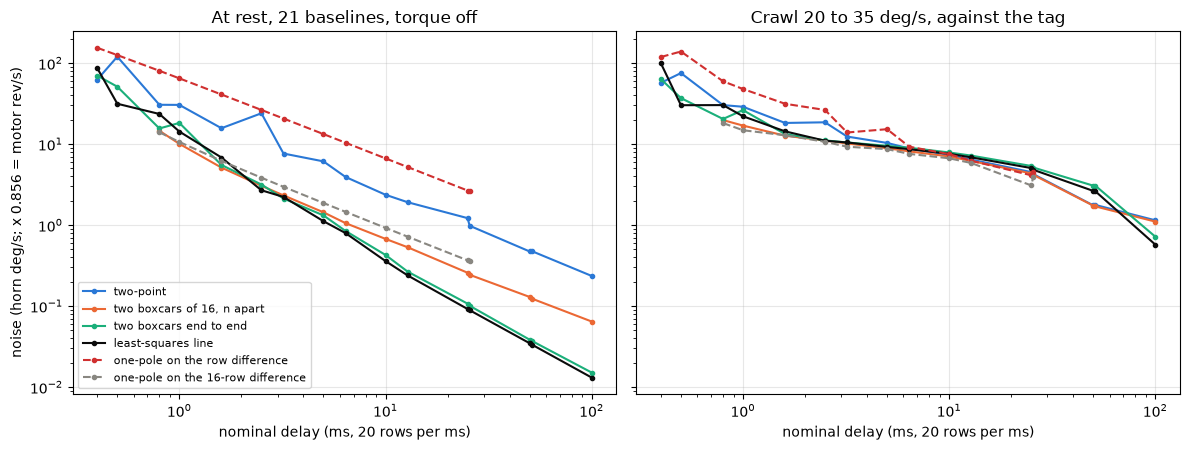

In [22]:
KIND_STYLE = {"two_point": ("two-point", BLUE, "-"),
              "box16": ("two boxcars of 16, n apart", ORANGE, "-"),
              "box_n": ("two boxcars end to end", GREEN, "-"),
              "ls_line": ("least-squares line", INK, "-"),
              "pole1": ("one-pole on the row difference", RED, "--"),
              "pole16": ("one-pole on the 16-row difference", MUTED, "--")}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
rest_b = SLOPE_REST[SLOPE_REST["where"] == "baseline"]
crawl_m = SLOPE_MOTION[SLOPE_MOTION.band == "crawl 20-35"]
for a, (d, col, title) in zip(ax, (
        (rest_b, "rms_deg_s", "At rest, 21 baselines, torque off"),
        (crawl_m, "sd", "Crawl 20 to 35 deg/s, against the tag"))):
    for kind, (name, color, ls) in KIND_STYLE.items():
        g = d[d.kind == kind].sort_values("d")
        a.plot(g.d / FS * 1e3, g[col], ls, color=color, label=name,
               marker="o", ms=3)
    a.set_xscale("log")
    a.set_yscale("log")
    figures.label(a, x="nominal delay (ms, 20 rows per ms)", title=title)
ax[0].set_ylabel("noise (horn deg/s; x 0.856 = motor rev/s)")
ax[0].legend(fontsize=8, loc="lower left")
figures.finish(fig)

### The delay each shape really has

The nominal delay holds on a ramp of speed. On a real transient the measured delay is the shift of the truth that leaves the smallest rms against the candidate. The truth is the tag's speed, the slope of the quadratic through the 7 frames around each frame, centered and so free of delay, a line between frames on the rows' camera time. The rows' camera time already carries the group's stamp lead, which stage 3 read by lining the pot's own centered 10 ms slope up with the tag, so the same centered slope is run on every transient as the zero. The added delay is the candidate's lag less the centered slope's lag on that transient.

The transients, each sitting on a hole of a few ms that is filled with a line:

- a kick from rest, the history before it filled with the rest reading,
- a kick's end, the kick's last rows and the start of the hold after it,
- a step, the steps clip's base hold into its top hold,
- a reversal, the reversal clip's hold into the reversed drive.

In [23]:
N_OF = {"two_point": [32, 64, 128, 256, 512, 1024, 2048],
        "box16": [32, 64, 128, 256, 512, 1024, 2048],
        "box_n": [16, 32, 64, 128, 256, 512, 1024],
        "ls_line": [32, 64, 128, 256, 512, 1024, 2048],
        "pole1": [16, 32, 64, 128, 256, 512],
        "pole16": [16, 32, 64, 128, 256, 512]}    # lengths per candidate
CENTER_HALF = 100       # rows, the centered slope of zero lag (10 ms)
MAX_SHARE = 0.45        # a delay over this share of the rows: not read


def tag_speed(tg):
    """(host s, deg/s) at the frames with both tags: the slope of the
    quadratic through the 7 frames around each frame (centered)."""
    f = tg[tg["both"]]
    t, y = f["host"].to_numpy(), f["image_deg"].to_numpy()
    n = len(t)
    v = np.full(n, np.nan)
    for i in range(n):
        a, b = max(0, i - potframes.HALF_FRAMES), min(
            n, i + potframes.HALF_FRAMES + 1)
        tt = t[a:b] - t[i]
        if (b - a < potframes.MIN_FIT_FRAMES
                or tt.max() - tt.min() > 2 * potframes.MAX_FRAME_GAP_S):
            continue
        v[i] = np.polyfit(tt, y[a:b], 2)[1]
    ok = np.isfinite(v)
    return t[ok], v[ok]


TAG_SPEED = {clip: tag_speed(tg) for clip, tg in PF.tags.items()}

In [24]:
def joined(clip, k, segs):
    """Segments as one series on a uniform row grid, a hole's rows on a
    line: (deg, camera time, each segment's first row)."""
    deg, cam, starts = [], [], []
    for j, s in enumerate(segs):
        c = series(clip, k, s)
        d, t = c["deg"], c["host_cam"]
        if j:
            m = int(round((t[0] - cam[-1][-1]) * FS)) - 1
            if m > 0:
                w = (np.arange(1, m + 1) / (m + 1))
                deg.append(deg[-1][-1] + w * (d[0] - deg[-1][-1]))
                cam.append(cam[-1][-1] + w * (t[0] - cam[-1][-1]))
        starts.append(sum(len(x) for x in deg))
        deg.append(d)
        cam.append(t)
    return np.concatenate(deg), np.concatenate(cam), starts

In [25]:
def best_lag(v, truth_at, cam, rows, lo, hi):
    """The shift (rows) of the truth that leaves the smallest rms against
    v on `rows`, on a grid of 2 rows then a parabola through the minimum;
    (shift, rms) or NaN at the grid's edge."""
    shifts = np.arange(lo, hi + 1, 2)
    cost = np.full(len(shifts), np.nan)
    y = v[rows]
    for i, sft in enumerate(shifts):
        tr = truth_at(cam[rows] - sft / FS)
        ok = np.isfinite(tr) & np.isfinite(y)
        if ok.sum() > 0.8 * len(rows):
            cost[i] = np.mean((y[ok] - tr[ok]) ** 2)
    if not np.isfinite(cost).any():
        return np.nan, np.nan
    i = int(np.nanargmin(cost))
    if (i == 0 or i == len(shifts) - 1
            or not np.isfinite(cost[i - 1:i + 2]).all()):
        return np.nan, np.nan
    a, b, c = cost[i - 1], cost[i], cost[i + 1]
    off = 0.5 * (a - c) / (a - 2 * b + c) if (a - 2 * b + c) > 0 else 0.0
    return float(shifts[i] + 2 * off), float(np.sqrt(b))


def centered_slope(deg):
    """The pot's centered slope over 2 CENTER_HALF rows (zero lag)."""
    vc = np.full(len(deg), np.nan)
    h = CENTER_HALF
    vc[h:-h] = (deg[2 * h:] - deg[:-2 * h]) * FS / (2 * h)
    return vc

In [26]:
todo = []                               # (what, clip, k, segs, anchor, r0, r1)
for s in SEGS.itertuples():
    nxt = SEGS[(SEGS["clip"] == s.clip) & (SEGS.k == s.k)
               & (SEGS.seg == s.seg + 1)]
    lab = nxt.label.iloc[0] if len(nxt) else None
    if s.label == "kick":
        todo.append(("kick", s.clip, s.k, [s.seg], 0, 0, s.rows))
        if lab in ("crawl", "hold", "step-base"):
            todo.append(("kick end", s.clip, s.k, [s.seg, s.seg + 1], 1,
                         -1000, 5000))
    if s.label == "step-base" and len(nxt):
        todo.append(("step", s.clip, s.k, [s.seg, s.seg + 1], 1, -2000,
                     6000))
    if s.label == "hold" and lab == "reversal":
        todo.append(("reversal", s.clip, s.k, [s.seg, s.seg + 1], 1, -1000,
                     8000))
print(pd.Series([t[0] for t in todo]).value_counts().to_dict())

{'kick': 38, 'kick end': 38, 'reversal': 4, 'step': 4}


In [27]:
def delay_runs(what, clip, k, segs, anchor, r0, r1):
    """Every candidate's lag less the centered slope's on one transient."""
    deg, cam, starts = joined(clip, k, segs)
    if not np.isfinite(cam[0]):
        return []
    pad = 4200 if what == "kick" else 0
    if pad:                             # before the kick: the rest reading
        deg = np.r_[np.full(pad, deg[:40].mean()), deg]
        cam = np.r_[cam[0] - np.arange(pad, 0, -1) / FS, cam]
    a0 = starts[anchor] + pad
    rows = np.arange(a0 + r0, min(a0 + r1, len(deg)))
    tf, vf = TAG_SPEED[clip]
    t_rest = cam[pad] if pad else None

    def truth_at(t):
        out = np.interp(t, tf, vf, left=np.nan, right=np.nan)
        return np.where(t < t_rest, 0.0, out) if pad else out

    lag0, rms0 = best_lag(centered_slope(deg), truth_at, cam, rows,
                          -400, 400)
    tr = truth_at(cam[rows])
    swing = float(np.nanmax(tr) - np.nanmin(tr))
    if not np.isfinite(lag0):
        return []
    out = []
    for kind, ns in N_OF.items():
        for n in ns:
            nom = velocity.nominal_delay(kind, n)
            if (nom > MAX_SHARE * len(rows)
                    or velocity.span_rows(kind, n) > a0 + r0 + len(rows)):
                continue
            v = velocity.run(kind, deg, n, FS)
            lag, rms = best_lag(v, truth_at, cam, rows, int(lag0 + nom) - 300,
                                int(lag0 + nom) + 300)
            out.append(dict(what=what, clip=clip, k=k, seg=segs[0], kind=kind,
                            n=n, nominal=nom, lag=lag, lag0=lag0,
                            added=lag - lag0, rms=rms, rms0=rms0, swing=swing))
    return out

In [28]:
DELAY_RUNS = pd.DataFrame([r for t in todo for r in delay_runs(*t)])
DELAY_RUNS["resid"] = DELAY_RUNS.added - DELAY_RUNS.nominal
SLOPE_DELAY = DELAY_RUNS.groupby(["what", "kind", "n", "nominal"]).agg(
    runs=("added", "count"), added=("added", "mean"),
    se=("added", lambda x: x.std(ddof=1) / np.sqrt(x.count())
        if x.count() > 1 else np.nan),
    resid=("resid", "mean"), resid_sd=("resid", "std"),
    rms=("rms", "mean")).reset_index()
Z0 = DELAY_RUNS.drop_duplicates(["what", "clip", "k", "seg"]).groupby(
    "what").agg(n=("lag0", "size"), lag0=("lag0", "mean"),
                lag0_sd=("lag0", "std"), swing=("swing", "median"))
print("the centered slope's own lag against the tag (rows), swing deg/s:")
print(Z0.round(1).to_string())
for what in ("kick", "kick end", "step", "reversal"):
    p = SLOPE_DELAY[SLOPE_DELAY.what == what].pivot_table(
        index="kind", columns="n", values="resid")
    print(f"{what}: added less nominal, rows")
    print(p.round(1).to_string())
for what in ("kick end", "kick"):
    d = SLOPE_DELAY[(SLOPE_DELAY.what == what) & SLOPE_DELAY.kind.isin(
        ["two_point", "box16", "box_n", "ls_line"])]
    for lo, hi in ((0, 128), (129, 256), (257, 512), (513, 1024)):
        x = d[(d.nominal > lo) & (d.nominal <= hi)]
        print(f"{what}, nominal {lo}-{hi} rows: resid {x.resid.min():+.1f} "
              f"to {x.resid.max():+.1f}, se {x.se.min():.1f} to "
              f"{x.se.max():.1f}, |resid| / se max "
              f"{(x.resid.abs() / x.se).max():.1f} ({int(x.runs.max())} runs)")

the centered slope's own lag against the tag (rows), swing deg/s:
           n   lag0  lag0_sd  swing
what                               
kick      38  -35.5     78.6  150.6
kick end  37  101.5     74.2  147.2
reversal   4   29.3     94.3  140.9
step       3  149.6    210.5   15.9
kick: added less nominal, rows
n          16    32    64    128   256   512   1024  2048
kind                                                     
box16       NaN   9.7   9.4   7.0   3.2  -3.2   5.3  22.6
box_n      10.1   9.7   6.9   4.3  -1.9  -1.0   8.1   NaN
ls_line     NaN  10.6  10.1   7.0   4.2  -2.5   0.2  11.9
pole1       9.9  10.0   6.6  -0.7 -24.9 -77.2   NaN   NaN
pole16      9.1   9.6   6.0  -1.3 -25.2 -77.2   NaN   NaN
two_point   NaN  10.2   9.5   7.6   3.4  -3.0   5.3  22.5
kick end: added less nominal, rows
n          16    32    64    128   256   512   1024  2048
kind                                                     
box16       NaN   0.9   1.3   1.7   1.0  -2.2  -5.7 -12.7
box_n       0.

The delay is the nominal delay. On the 37 kick ends the two-point, the boxcars and the line read their nominal delay to within +0.8 to +1.7 rows up to 128 rows of delay, -2.1 to +1.0 from 128 to 256, -5.8 to -2.2 up to 512 and -12.9 to -5.7 up to 1024, with se of 0.7 to 7.2 rows. One cell sits at 2.2 se and every other under 2. The 4 reversals read -5.2 to +2.3 rows for the two-point, the boxcars of 16 and the line. A one-pole is not a shift from 128 rows of time constant on, -4.5 rows at 128, -23.9 at 256 and -92.5 at 512 on the 16-row difference. On a kick from rest every short candidate reads 9.4 to 10.6 rows late against the centered slope. That is the method's own limit there, a rise from rest not being a pure shift of a smoothed truth, and not a property of the candidates. The 3 steps of 16 deg/s do not resolve a delay, the centered slope's own lag spreading over 210 rows.

The centered slope's own lag against the tag is 101.5 rows late on the kick ends and 35.5 early on the kicks, with sd of 74.2 and 78.6 rows. It is a disagreement between the pot and the tag on these transients, and section 9 takes it up. It enters no steady number here, since a candidate and the tag share one segment's rows, and every delay above is a difference against the centered slope on the same transient.

## 3. The carries

The pot's converter has carries, a wide code followed by a run of codes that never appear. Stage 4's position result found them from the code widths. At a carry the reading stands still on the wide code while the horn turns, then jumps the run in one row. At a crawl a dwell lasts tens of ms, which is the length of a useful slope's window, so a carry is a velocity problem before it is a position one.

The grade uses the steady rows that move over 10 deg/s by the tag, the error being the candidate less the plain candidate on the tag, signed along the travel. Each candidate (the two-point, the line and the one-pole on the 16-row difference) is read five ways.

- none, the pot as read, through the lookup.
- center, the wide code read at the middle of its span, which is what a lookup that carries the missing run would read (`velocity.carry_center`).
- hold12, the position notebook's hold, the last reading outside +/-12 counts of the carry, then the slope (`velocity.hold_band`).
- skip2 and skip12, the band's rows left out of the slope (`velocity.two_point_skip`, `ls_line_skip`, `pole_diff_skip`). The band of +/-2 counts is 2 sd of the pot's row noise, the band of +/-12 the longest missing run.

A row is near a carry when the candidate's history holds a row within 2 counts of a wide code or its run, so the dwell or the jump is inside the window, and far when it holds none within 12 counts.

In [29]:
CARRY_NS = {"two_point": [128, 256, 512, 1024, 2000, 4000],
            "ls_line": [128, 256, 512, 1024, 2000, 4000],
            "pole16": [64, 128, 256, 512]}     # rows, lengths graded
SD_ROW = POS4["pot_noise_row_counts"]["value"]  # counts, the pot's row sd
NOISE_HALF = int(round(2 * SD_ROW))     # counts, 2 sd of the row noise
WIDE_HALF = max(CARRY_MISSING)          # counts, the longest missing run
print(f"pot row noise {SD_ROW:.2f} counts (position result); bands "
      f"+/-{NOISE_HALF} and +/-{WIDE_HALF} counts")


def carry_variants(kind, n, pos, deg):
    """{mask: (slope deg/s, held rows or None)} of one candidate."""
    out = {"none": (velocity.run(kind, deg, n, FS), None)}
    mid = velocity.carry_center(pos, CARRY_CODES, CARRY_MISSING)
    out["center"] = (velocity.run(kind, LOOKUP.angle(mid), n, FS), None)
    b12 = velocity.carry_band(pos, CARRY_CODES, CARRY_MISSING, WIDE_HALF)
    held = velocity.hold_band(pos, b12)
    out["hold12"] = (velocity.run(kind, LOOKUP.angle(held), n, FS), None)
    for name, half in (("skip2", NOISE_HALF), ("skip12", WIDE_HALF)):
        ok = ~velocity.carry_band(pos, CARRY_CODES, CARRY_MISSING, half)
        if kind == "two_point":
            out[name] = velocity.two_point_skip(deg, ok, n, FS)
        elif kind == "ls_line":
            out[name] = velocity.ls_line_skip(deg, ok, n, FS)
        else:
            out[name] = velocity.pole_diff_skip(deg, ok, n, FS, 16)
    return out

pot row noise 1.03 counts (position result); bands +/-2 and +/-12 counts


In [30]:
def carry_events(s, pos, moving, vt, b2, b12, cls):
    """Each run of moving rows on a wide code: its dwell and speed."""
    out = []
    for code, miss in zip(CARRY_CODES, CARRY_MISSING):
        on = (pos == code) & moving
        if on.sum() < 5:
            continue
        i = np.flatnonzero(on)
        near = np.abs(pos - code - miss / 2) < 40   # this carry's rows
        out.append(dict(clip=s.clip, k=s.k, seg=s.seg, cls=cls, code=code,
                        missing=miss, dwell_rows=int(i[-1] - i[0] + 1),
                        on_rows=int(on.sum()), v_tag=float(np.nanmean(vt[i])),
                        band2_rows=int((b2 & moving & near).sum()),
                        band12_rows=int((b12 & moving & near).sum())))
    return out


def carry_share(s, moving, b2, b12, cls):
    """How many moving rows a mask touches, by the slope's length."""
    return dict(clip=s.clip, k=s.k, seg=s.seg, cls=cls,
                moving=int(moving.sum()), in_band2=int((b2 & moving).sum()),
                in_band12=int((b12 & moving).sum()),
                **{f"near_{n}": int((touched(b2, n) & moving).sum())
                   for n in (128, 512, 1024, 2000, 4000)})

In [31]:
def carry_tiles(s, pos, deg, tag, bad, w0, w1, moving, b2, b12, trav, vt,
                cls):
    """Every candidate and mask less the plain candidate on the tag, on
    the rows near a carry and far from one, every 50 rows."""
    out = []
    for kind, ns in CARRY_NS.items():
        for n in ns:
            span = velocity.span_rows(kind, n)
            if w0 + span >= w1 - 400:
                continue
            et = velocity.run(kind, tag, n, FS)     # the tag, same kernel
            near, far = touched(b2, span), ~touched(b12, span)
            rows = np.arange(w0 + span, w1, 50)
            rows = rows[moving[rows] & ~touched(bad, span)[rows]
                        & (near[rows] | far[rows])]
            if len(rows) == 0:
                continue
            for name, (v, held) in carry_variants(kind, n, pos, deg).items():
                out.append(pd.DataFrame({
                    "clip": s.clip, "k": s.k, "seg": s.seg, "cls": cls,
                    "kind": kind, "n": n, "variant": name,
                    "near": near[rows], "e": (v[rows] - et[rows]) * trav,
                    "held": held[rows] if held is not None else False,
                    "v_tag": vt[rows]}))
    return out

In [32]:
recs, share, events = [], [], []
for s in SEGS.itertuples():
    if not (s.steady1 > s.steady0 and s.lead_ok):
        continue
    c = series(s.clip, s.k, s.seg)
    pos, deg = c["pos"], c["deg"]
    tag, bad = fill_nan(c["tag"])
    if bad.mean() > 0.5:
        continue
    w0, w1 = s.steady0 - s.a, s.steady1 - s.a
    vt, trav = tag_speed_100(tag, w0, w1)
    cls = "pass 100" if s.duty_ticks == 240 else "slow 10-50"
    b2 = velocity.carry_band(pos, CARRY_CODES, CARRY_MISSING, NOISE_HALF)
    b12 = velocity.carry_band(pos, CARRY_CODES, CARRY_MISSING, WIDE_HALF)
    moving = np.zeros(len(pos), bool)
    moving[w0:w1] = np.isfinite(vt[w0:w1]) & (vt[w0:w1] > MOVING_DEG_S)
    events += carry_events(s, pos, moving, vt, b2, b12, cls)
    share.append(carry_share(s, moving, b2, b12, cls))
    recs += carry_tiles(s, pos, deg, tag, bad, w0, w1, moving, b2, b12,
                        trav, vt, cls)
C_TILES = pd.concat(recs, ignore_index=True)
CARRY_SHARE = pd.DataFrame(share)
CARRY_EVENTS = pd.DataFrame(events)
print(f"{len(C_TILES)} samples, {len(CARRY_EVENTS)} carry crossings, "
      f"{len(CARRY_SHARE)} segments")

831470 samples, 50 carry crossings, 50 segments


In [33]:
def carry_agg(d):
    """Bias, se over segments, sd, rms, p95 and worst of one cell."""
    segm = d.groupby(["clip", "k", "seg"])["e"].mean()
    return pd.Series(dict(
        samples=len(d), segs=len(segm), bias=d.e.mean(),
        bias_se=(segm.std(ddof=1) / np.sqrt(len(segm)) if len(segm) > 1
                 else np.nan),
        sd=d.e.std(), rms=np.sqrt((d.e ** 2).mean()),
        p95=d.e.abs().quantile(0.95), worst=d.e.abs().max(),
        held_share=d.held.mean(), missing=d.e.isna().mean(),
        v_tag=d.v_tag.mean()))


CARRY = C_TILES.groupby(["cls", "kind", "n", "variant", "near"]).apply(
    carry_agg, include_groups=False).reset_index()
for col in ("bias", "sd", "rms", "p95", "worst"):
    CARRY[col + "_rev_s"] = CARRY[col] / K
e = CARRY_EVENTS.groupby(["cls", "code"]).agg(
    crossings=("dwell_rows", "size"),
    dwell_ms=("dwell_rows", lambda x: np.median(x) / FS * 1e3),
    dwell_max_ms=("dwell_rows", lambda x: x.max() / FS * 1e3),
    v=("v_tag", "mean"))
print("carry dwell by code, ms (median, max) and the tag's speed, deg/s:")
print(e.round(1).to_string())

carry dwell by code, ms (median, max) and the tag's speed, deg/s:
                 crossings  dwell_ms  dwell_max_ms      v
cls        code                                          
pass 100   1023          3       6.4           7.4   95.3
           1279          4       2.8           3.1  102.1
           2047          3       8.2           9.8  104.6
           2303          3       1.8           1.8  103.4
           2559          4       4.6           5.0  103.0
slow 10-50 1023          5      30.7          34.3   26.4
           1279          5      10.4          11.5   33.1
           2047          5      21.0          45.5   31.4
           2303         10       5.6          11.4   29.7
           2559          8      15.4          41.8   30.9


A carry is a dwell and a jump. At a crawl of 10 to 50 deg/s the reading stands on 1023 for 30.7 ms (the longest 34.3), on 2047 for 21.0 (45.5), on 2559 for 15.4 (41.8), on 1279 for 10.4 and on 2303 for 5.6, the median over 33 crossings, and then jumps the missing run in one row. At 100 deg/s the dwells are 1.8 to 8.2 ms.

The two-point near a carry at a crawl of 10 to 50 deg/s, by mask and window, rms and worst sample against the tag, beside the same far from any carry, and the share of a crawl's moving rows each window's mask touches.

In [34]:
WIN_N = [128, 256, 512, 1024, 2000]     # rows: 6.4, 12.8, 25.6, 51, 100 ms
print("windows (ms):", {n: round(n / FS * 1e3, 1) for n in WIN_N})
d = CARRY[(CARRY.cls == "slow 10-50") & (CARRY.kind == "two_point")
          & CARRY.n.isin(WIN_N)]
for stat in ("rms", "worst", "bias"):
    p = d.pivot_table(index=["near", "variant"], columns="n", values=stat)
    print(f"two-point, slow 10-50 deg/s, {stat} (deg/s) by window (rows):")
    print(p.round(2).to_string())
print(f"near-carry samples {int(d[d.near].samples.min())} to "
      f"{int(d[d.near].samples.max())}")
g = CARRY_SHARE.groupby("cls").sum(numeric_only=True)
cols = ["in_band2", "in_band12"] + [c for c in g.columns
                                    if c.startswith("near_")]
print("share of steady moving rows a mask touches, %:")
print((g[cols].div(g.moving, axis=0) * 100).round(1).to_string())

windows (ms): {128: 6.4, 256: 12.8, 512: 25.6, 1024: 51.2, 2000: 100.0}
two-point, slow 10-50 deg/s, rms (deg/s) by window (rows):
n               128    256    512    1024  2000
near  variant                                  
False center   11.45   8.18   5.85   3.74  1.72
      hold12   11.45   8.18   5.85   3.74  1.72
      none     11.45   8.18   5.85   3.74  1.72
      skip12   11.45   8.18   5.85   3.74  1.72
      skip2    11.45   8.18   5.85   3.74  1.72
True  center   25.51  14.84   8.97   4.72  2.00
      hold12   30.27  35.51  31.41  17.73  7.64
      none     33.01  19.50  10.78   4.94  2.07
      skip12   10.15   7.50   6.69   5.22  2.15
      skip2    19.39  13.56   9.00   4.76  1.98
two-point, slow 10-50 deg/s, worst (deg/s) by window (rows):
n                128     256    512    1024   2000
near  variant                                     
False center    61.80   40.15  24.74  14.21   7.66
      hold12    61.80   40.15  24.74  14.21   7.66
      none      61.80   40.1

In [35]:
d = CARRY[(CARRY.cls == "pass 100") & (CARRY.kind == "two_point")
          & CARRY.n.isin(WIN_N)]
p = d.pivot_table(index=["near", "variant"], columns="n", values="rms")
print("two-point at 100 deg/s, rms (deg/s) by window (rows):")
print(p.round(2).to_string())
d = CARRY[(CARRY.cls == "slow 10-50") & (CARRY.kind == "ls_line")
          & CARRY.n.isin(WIN_N + [4000])]
print("the line with the band skipped, slow, worst (deg/s) by window:",
      d[d.near & (d.variant == "skip12")].set_index("n").worst.round(1)
      .to_dict())
SLOWEST = POT3["crawl_slowest_sustained_deg_s"]["value"]   # stage 3
e1 = CARRY_EVENTS[(CARRY_EVENTS.cls == "slow 10-50")
                  & (CARRY_EVENTS.code == 1023)]
dwell_ms = np.median(e1.dwell_rows) / FS * 1e3 * e1.v_tag.mean() / SLOWEST
print(f"the dwell on 1023 scaled to stage 3's slowest sustained crawl, "
      f"{SLOWEST:.1f} deg/s: {dwell_ms:.0f} ms")

two-point at 100 deg/s, rms (deg/s) by window (rows):
n                128    256    512    1024  2000
near  variant                                   
False center    19.63  12.29   6.83   3.84  2.06
      hold12    19.63  12.29   6.83   3.84  2.06
      none      19.63  12.29   6.83   3.84  2.06
      skip12    19.63  12.29   6.83   3.84  2.06
      skip2     19.63  12.29   6.83   3.84  2.06
True  center    30.58  16.68   8.82   4.05  2.21
      hold12   113.73  77.99  35.57  13.96  5.48
      none      44.57  21.28   9.03   4.21  2.24
      skip12    21.98  15.81   8.93   4.33  2.36
      skip2     26.53  16.08   8.92   4.08  2.25
the line with the band skipped, slow, worst (deg/s) by window: {128: 37.3, 256: 27.8, 512: 24.0, 1024: 17.8, 2000: 40.6, 4000: 3.7}
the dwell on 1023 scaled to stage 3's slowest sustained crawl, 11.9 deg/s: 68 ms


The cost of a carry is set by the window against the dwell. Near a carry the unmasked two-point reads 33.01 deg/s rms at 6.4 ms of window, 19.50 at 12.8, 10.78 at 25.6, 4.94 at 51 and 2.07 at 100, against 11.45, 8.18, 5.85, 3.74 and 1.72 far from any carry. The worst single samples are 138.31 deg/s at 6.4 ms and 35.55 at 25.6 ms, the crawl's own speed. The near samples are 385 to 1448 per cell from 33 crossings.

- **Holding the pot through the band**, the position notebook's hold, makes the slope worse from 12.8 ms up, 35.51, 31.41, 17.73 and 7.64 deg/s at 12.8 to 100 ms, with a bias of -28.78 to -1.13 deg/s. It turns a jump of the missing run into one of the whole band. At 6.4 ms it reads 30.27 against 33.01 with no mask.
- **Reading the wide code at its middle**, what a lookup that carries the missing run would read, halves the jump. It reads 25.51, 14.84, 8.97, 4.72 and 2.00 deg/s.
- **Skipping the band's rows** in the slope, the two ends stepping out of +/-12 counts, brings near to 10.15, 7.50 and 6.69 deg/s up to 25.6 ms, at or under the far rms but for 25.6 ms. It stops paying at 51 ms, 5.22 against 4.94 with no mask. A band of +/-2 counts removes about half of the excess, 19.39, 13.56 and 9.00 deg/s, since the reading flips between the wide code and its neighbors for several counts of travel, so the band has to cover the run and the flips.
- **The line with the band skipped** holds a stale slope when its window empties. Its worst sample is 40.6 deg/s at 100 ms, and it is not carried further.

The mask touches few rows at a crawl. A window holds a band row on 3.6 % of the moving rows at 6.4 ms, 5.9 % at 25.6, 9.0 % at 51, 14.8 % at 100 and 33.2 % at 200, and 6.9 % of the rows sit in the +/-12 band itself. At 100 deg/s the shares are 5.6 to 68.6 %, and from 25.6 ms up no mask but the hold moves the rms there, 8.82 to 9.03 deg/s near against 6.83 far. Confidence moderate, one sitting, 33 crossings at a crawl.

The rule for a servo this stage never saw. From the identification's code-density histogram a carry is a code at least 3 LSB wide or followed by 2 or more missing codes, the position notebook's rule. For velocity, never hold the pot. Under a window of about twice the longest dwell expected, 50 ms here at a crawl, skip the rows from the longest missing run under the wide code to the same past its run in a two-point or boxcar-difference slope, and above that use no mask. The half-width is the longest missing run, 12 counts here, read from the histogram and not typed. The state is the slope's own delay line and its row marks, and the constants the carries' codes and runs.

The dwell scales as the inverse of the speed, so a slower crawl than this sitting's would see it in longer windows. At stage 3's slowest sustained crawl, 11.9 deg/s, the dwell on 1023 would be about 68 ms. The sitting's slowest holds mostly stall, and that stays a candidate.

What you are looking at: one crossing of the carry at code 1023 at a crawl, the crossing of median dwell. Left, the pot's counts through the wide code and the band of +/-12 counts around it. Middle, the two-point over 512 rows (25.6 ms) through the same rows for each mask, against the tag through the same kernel. Right, the rms near a carry against the tag by window, for each mask, beside the rms far from any carry.

In [36]:
ev = CARRY_EVENTS[(CARRY_EVENTS.cls == "slow 10-50")
                  & (CARRY_EVENTS.code == 1023)].sort_values("dwell_rows")
e = ev.iloc[len(ev) // 2]               # the crossing of median dwell
c = series(e["clip"], int(e["k"]), int(e["seg"]))
pos, deg = c["pos"], c["deg"]
tag, _ = fill_nan(c["tag"])
mid = int(np.median(np.flatnonzero(pos == 1023)))
sl = slice(mid - 2400, mid + 2400)
t = (np.arange(len(pos)) - mid)[sl] / FS * 1e3      # ms from the middle
trav = np.sign(tag[mid + 2000] - tag[mid - 2000])
b12 = velocity.carry_band(pos, CARRY_CODES, CARRY_MISSING, WIDE_HALF)
mid_deg = LOOKUP.angle(velocity.carry_center(pos, CARRY_CODES,
                                             CARRY_MISSING))
FIG_CARRY = {
    "tag, same kernel": (velocity.two_point(tag, 512, FS), MUTED, "-"),
    "no mask": (velocity.two_point(deg, 512, FS), BLUE, "-"),
    "wide code at its middle": (velocity.two_point(mid_deg, 512, FS),
                                GREEN, "-"),
    "pot held through +/-12": (velocity.two_point(LOOKUP.angle(
        velocity.hold_band(pos, b12)), 512, FS), RED, "--"),
    "band's rows skipped": (velocity.two_point_skip(deg, ~b12, 512, FS)[0],
                            ORANGE, "-")}
print(f"{e['clip']} chain {int(e['k'])} segment {int(e['seg'])}: dwell "
      f"{e['dwell_rows'] / FS * 1e3:.1f} ms at {abs(e['v_tag']):.0f} deg/s")

steps chain 1 segment 2: dwell 30.7 ms at 23 deg/s


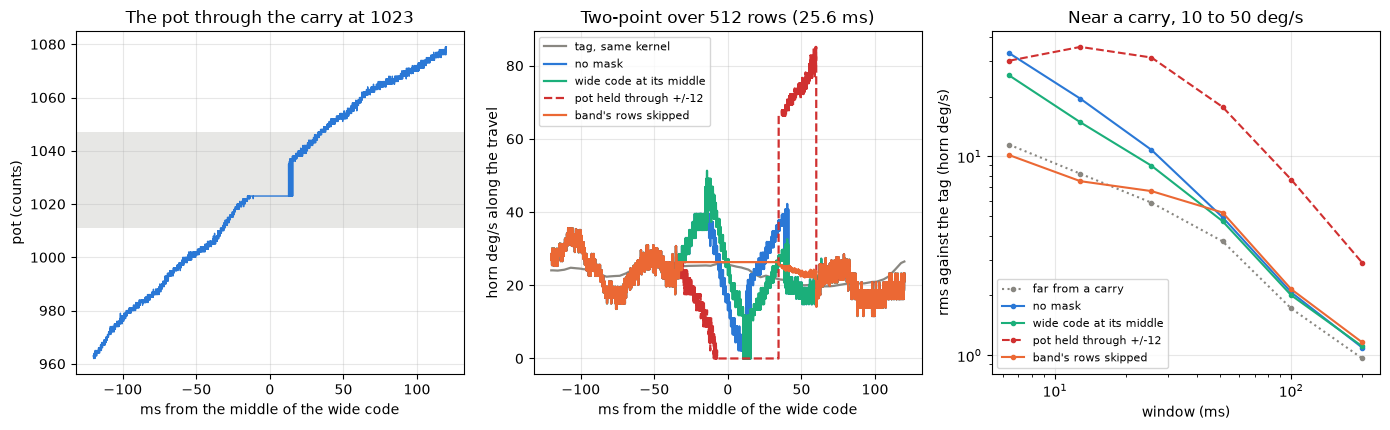

In [37]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
ax[0].plot(t, pos[sl], color=BLUE, lw=1)
ax[0].axhspan(1023 - WIDE_HALF, 1023 + 12 + WIDE_HALF, color=MUTED,
              alpha=0.2, lw=0)
figures.label(ax[0], x="ms from the middle of the wide code",
              y="pot (counts)", title="The pot through the carry at 1023")
for name, (v, color, ls) in FIG_CARRY.items():
    ax[1].plot(t, v[sl] * trav, ls, color=color, label=name, lw=1.6)
figures.label(ax[1], x="ms from the middle of the wide code",
              y="horn deg/s along the travel",
              title="Two-point over 512 rows (25.6 ms)")
ax[1].legend(fontsize=8, loc="upper left")
d = CARRY[(CARRY.cls == "slow 10-50") & (CARRY.kind == "two_point")]
far = d[(~d.near) & (d.variant == "none")].sort_values("n")
ax[2].plot(far.n / FS * 1e3, far.rms, ":", color=MUTED, marker="o", ms=3,
           label="far from a carry")
for var, name, color, ls in (
        ("none", "no mask", BLUE, "-"),
        ("center", "wide code at its middle", GREEN, "-"),
        ("hold12", "pot held through +/-12", RED, "--"),
        ("skip12", "band's rows skipped", ORANGE, "-")):
    g = d[d.near & (d.variant == var)].sort_values("n")
    ax[2].plot(g.n / FS * 1e3, g.rms, ls, color=color, label=name,
               marker="o", ms=3)
ax[2].set_xscale("log")
ax[2].set_yscale("log")
figures.label(ax[2], x="window (ms)", y="rms against the tag (horn deg/s)",
              title="Near a carry, 10 to 50 deg/s")
ax[2].legend(fontsize=8)
figures.finish(fig)

## 4. The back-EMF speed on the same rows

Section 1 ran the back-EMF speed over every driven row of the 21 chains as a controller meets them. This section grades it on the same steady rows as the pot's slope, on tiles of 200 ms that move over 10 deg/s by the tag, with both brush forms side by side.

- The bias of a tile is its mean estimate less the tag's speed over the tile, the angle's change over the tile through the gear ratio, which the stamp lead does not touch. Beside it, the tile's mean less the ripple tach over the same rows, `ripple.count_cycles` seeded by the tag with 4 cycles at least, a motor-side truth.
- The noise per row is the sd about the tile's own line. The noise per window is the same after a boxcar or a one-pole of the per-row estimate. Rows off the drive inside a segment, its first rows before the duty lands, read as the nearest driven row.

In [38]:
TILE = 4000                             # rows, 200 ms
EMF_FILTERS = ([("boxcar", n) for n in (1, 8, 16, 32, 64, 100, 200, 400,
                                        1000, 2000)]
               + [("one_pole", n) for n in (16, 32, 64, 100, 200, 400)])


def filled(w):
    """The per-row estimate with the rows off the drive read as the
    nearest driven row: the last one, or the segment's first one."""
    return pd.Series(w).ffill().bfill().to_numpy()


def detrend(x):
    """x less its least-squares line."""
    j = np.arange(len(x)) - (len(x) - 1) / 2
    return x - np.polyval(np.polyfit(j, x, 1), j)


def tach_of(raw, w_tag):
    """(rev/s, cycles) of the ripple tach over a tile, seeded by the tag;
    NaN under 4 cycles or a seed under 30 Hz."""
    seed = w_tag * N_R
    if seed > 30:
        try:
            f_cnt, ncyc = ripple.count_cycles(raw - raw.mean(), seed)
            if ncyc >= 4:
                return f_cnt / N_R, ncyc
        except Exception:
            pass
    return np.nan, 0

In [39]:
def emf_tile(s, c, E, sl, a, w_tag, trav):
    """One tile's record: the two forms' means and row sd, the current,
    the valid share, the tach."""
    b = a + TILE
    rec = dict(clip=s.clip, k=s.k, seg=s.seg, kind=s.kind, label=s.label,
               duty=s.duty_ticks, drive=s.drive, trav=int(trav), a=a,
               w_tag=w_tag,
               i_ma=float(np.nanmean(E["i_w"][sl][a:b]) * 1e3),
               valid_share=float(E["valid"][sl][a:b].mean()),
               v_on=float(np.nanmean(E["v_on"][sl][a:b])),
               pos=float(c["pos"][a:b].mean()))
    for form in ("w_tab", "w_prod"):
        w = E[form][sl][a:b]
        rec[form] = float(w.mean())
        rec[form + "_row_sd"] = float(detrend(w).std())
    rec["tach"], rec["tach_cycles"] = tach_of(
        c["current_raw"].astype(float)[a:b], w_tag)
    return rec


def emf_noise(s, filt, a, w_tag):
    """Each filter's sd about the tile's line, its history past the
    segment's start-up rows."""
    out = []
    for (form, kind, n), y in filt.items():
        span = n if kind == "boxcar" else 5 * n
        if a - span < 16:
            continue
        out.append(dict(clip=s.clip, k=s.k, seg=s.seg, label=s.label,
                        duty=s.duty_ticks, form=form, filter=kind, n=n,
                        w_tag=w_tag, sd=float(detrend(y[a:a + TILE]).std())))
    return out

In [40]:
tiles, noise = [], []
for s in SEGS.itertuples():
    if not (s.steady1 > s.steady0 and s.lead_ok):
        continue
    c, E = series(s.clip, s.k, s.seg), EMF[(s.clip, s.k)]
    sl, tag = slice(s.a, s.b), c["tag"]
    w0, w1 = s.steady0 - s.a, s.steady1 - s.a
    filt = {}
    for form in ("w_tab", "w_prod"):
        w = filled(E[form][sl])
        for kind, n in EMF_FILTERS:
            filt[(form, kind, n)] = (
                speed.boxcar(w, n) if kind == "boxcar"
                else speed.one_pole(w, 1.0 / (1.0 + n)))
    for a in range(w0, w1 - TILE + 1, TILE):
        if not (np.isfinite(tag[a]) and np.isfinite(tag[a + TILE - 1])):
            continue
        v_tag = (tag[a + TILE - 1] - tag[a]) / ((TILE - 1) / FS)
        if abs(v_tag) < MOVING_DEG_S:
            continue
        w_tag = abs(v_tag) / K          # motor rev/s by the tag
        tiles.append(emf_tile(s, c, E, sl, a, w_tag, np.sign(v_tag)))
        noise += emf_noise(s, filt, a, w_tag)
Q2_TILES = pd.DataFrame(tiles)          # one row per 200 ms tile
Q2_TILES["e_tab"] = Q2_TILES.w_tab - Q2_TILES.w_tag
Q2_TILES["e_prod"] = Q2_TILES.w_prod - Q2_TILES.w_tag
Q2_TILES["e_tach"] = Q2_TILES.tach - Q2_TILES.w_tag
Q2_TILES["e_tab_tach"] = Q2_TILES.w_tab - Q2_TILES.tach
Q2_TILES["e_prod_tach"] = Q2_TILES.w_prod - Q2_TILES.tach
print(f"{len(Q2_TILES)} tiles in {Q2_TILES.groupby(['clip', 'k', 'seg'])
      .ngroups} segments, {int(Q2_TILES.tach.notna().sum())} with a tach")

146 tiles in 46 segments, 146 with a tach


In [41]:
def emf_agg(d, cols=("e_tab", "e_prod", "e_tach", "e_tab_tach")):
    """Each error's mean, se over segments, sd and count, the rows' sd."""
    out = dict(tiles=len(d), segs=d.groupby(["clip", "k", "seg"]).ngroups,
               w_tag=d.w_tag.mean(), i_ma=d.i_ma.mean(),
               valid=d.valid_share.mean())
    for col in cols:
        sm = d.groupby(["clip", "k", "seg"])[col].mean().dropna()
        out[col] = d[col].mean()
        out[col + "_se"] = (sm.std(ddof=1) / np.sqrt(len(sm)) if len(sm) > 1
                            else np.nan)
        out[col + "_sd"] = d[col].std()
        out[col + "_n"] = int(d[col].notna().sum())
    out["row_sd_tab"] = np.sqrt((d.w_tab_row_sd ** 2).mean())
    out["row_sd_prod"] = np.sqrt((d.w_prod_row_sd ** 2).mean())
    return pd.Series(out)


EMF_BIAS = Q2_TILES.groupby(["kind", "duty", "drive"]).apply(
    emf_agg, include_groups=False).reset_index()
EMF_BIAS_DUTY = Q2_TILES.groupby(["kind", "duty"]).apply(
    emf_agg, include_groups=False).reset_index()
N = pd.DataFrame(noise)
N["band"] = np.where(N.duty == 240, "pass 100", np.where(
    N.label == "crawl", "crawl", "steps+reversal slow"))
N["side"] = np.where(N.duty < FLOOR, "under floor", "valid")
EMF_NOISE = N.groupby(["band", "side", "form", "filter", "n"]).agg(
    tiles=("sd", "size"), w_tag=("w_tag", "mean"),
    sd=("sd", lambda x: np.sqrt((x ** 2).mean())), lo=("sd", "min"),
    hi=("sd", "max")).reset_index()
print(EMF_BIAS_DUTY[["kind", "duty", "tiles", "segs", "w_tag", "i_ma",
                     "e_tab", "e_tab_se", "e_prod", "e_prod_se", "e_tach",
                     "e_tach_se", "e_tab_tach", "row_sd_tab"]]
      .round(2).to_string(index=False))

    kind  duty  tiles  segs  w_tag  i_ma  e_tab  e_tab_se  e_prod  e_prod_se  e_tach  e_tach_se  e_tab_tach  row_sd_tab
   crawl    72   11.0   4.0  11.92 31.29  -2.25      0.40   -1.27       0.37   -0.26       0.04       -1.99        2.49
   crawl    84   22.0   5.0  15.45 34.99   0.63      0.28    1.91       0.42    0.00       0.14        0.63        2.83
   crawl    96   19.0   5.0  20.95 37.63   0.38      0.22    1.59       0.50   -0.12       0.19        0.50        3.45
   crawl   108   22.0   6.0  25.46 41.69   0.32      0.21    0.98       0.46   -0.33       0.09        0.65        4.21
   crawl   132   16.0   6.0  37.47 44.33   0.27      0.27    0.77       0.48   -0.20       0.20        0.47        5.05
    pass   240   12.0   4.0  85.72 65.16  -0.55      0.37   -0.39       0.51   -0.43       0.11       -0.11        7.54
reversal   108   22.0   4.0  24.98 41.74   0.76      0.24    1.42       0.53   -0.03       0.08        0.79        3.94
reversal   240    6.0   4.0  87.37 61.29

The per-row estimate holds on rows it was not scored on. Section 1's coverage, 84.28 % of the driven rows valid, and the per-row noise below land on the `speed` notebook's numbers for the same chains. By on-time the crawl reads +0.63 +/- 0.28, +0.38 +/- 0.22, +0.32 +/- 0.21 and +0.27 +/- 0.27 rev/s high in the table form at 84, 96, 108 and 132 ticks (15 to 37 rev/s), and the steps and reversal holds at 96 to 120 ticks +0.57 to +1.10. Under the floor, at 72 ticks and 12 rev/s, the table form reads -2.25 +/- 0.40 rev/s and the product form -1.27 +/- 0.37 against the tag, -1.99 against the tach, on 11 tiles of the holds that turn.

### Coverage and the crawl's rows under the floor

The valid share of the sitting's driven rows was printed in section 1. A crawl hold at the narrowest duty runs its on-time under the taps' floor, so the back-EMF speed is not valid there at all.

In [42]:
crawl = SEGS[SEGS.label == "crawl"]
rows_by = crawl.groupby("duty_ticks").rows.sum()        # rows per on-time
UNDER_FLOOR_SHARE = rows_by[rows_by.index < FLOOR].sum() / rows_by.sum()
print(f"crawl hold rows by on-ticks {rows_by.to_dict()}: under the "
      f"{FLOOR}-tick floor {UNDER_FLOOR_SHARE:.1%} of {rows_by.sum()} rows, "
      f"{rows_by[rows_by.index < 96].sum() / rows_by.sum():.1%} under 96; "
      f"{int(crawl.duty_ticks.lt(FLOOR).sum())} holds under the floor")
mv = Q2_TILES[Q2_TILES.label == "crawl"].groupby("duty").size()
print(f"moving 200 ms tiles of the crawl holds by on-ticks: {mv.to_dict()}")

crawl hold rows by on-ticks {72: 178960, 84: 153400, 96: 134200, 108: 119280, 132: 97560}: under the 84-tick floor 26.2% of 683400 rows, 48.6% under 96; 6 holds under the floor
moving 200 ms tiles of the crawl holds by on-ticks: {72: 11, 84: 22, 96: 19, 108: 22, 132: 16}


A quarter of the crawl's hold rows, 26.2 % of 683400, run at the 72-tick on-time under the floor, and 48.6 % under 96 ticks. Most of those 6 holds do not turn at all (section 6), and the estimate there is not valid.

### The bias at a crawl, by form and by direction

The slow valid tiles are the crawl, steps and reversal holds with an on-time from the floor up to the pass's 240 ticks. The bias is their mean error with its se over segments, against the tag and against the tach. The ripple tach and the back-EMF are both on the motor side, so their difference holds no lash and no tag.

In [43]:
SLOW = Q2_TILES[(Q2_TILES.duty >= FLOOR) & (Q2_TILES.duty < 240)]
PASS = Q2_TILES[Q2_TILES.duty == 240]
KEYS = ["clip", "k", "seg"]


def seg_mean(d, col):
    """(mean over tiles, se over segments' means, tiles, segments)."""
    sm = d.groupby(KEYS)[col].mean().dropna()
    return (float(d[col].mean()), float(sm.std(ddof=1) / np.sqrt(len(sm))),
            int(d[col].notna().sum()), len(sm))


for name, d in (("slow valid", SLOW), ("pass 20 %", PASS)):
    print(f"{name}: {len(d)} tiles, {d.groupby(KEYS).ngroups} segments, "
          f"{d.w_tag.mean():.1f} rev/s, {d.i_ma.min():.0f} to "
          f"{d.i_ma.max():.0f} mA")
    for col in ("e_tab", "e_prod", "e_tach", "e_tab_tach", "e_prod_tach"):
        m, se, n, ns = seg_mean(d, col)
        print(f"  {col}: {m:+.2f} +/- {se:.2f} rev/s (tile sd "
              f"{d[col].std():.2f}, {n} tiles, {ns} segments)")

slow valid: 117 tiles, 34 segments, 24.4 rev/s, 29 to 59 mA
  e_tab: +0.54 +/- 0.10 rev/s (tile sd 1.10, 117 tiles, 34 segments)
  e_prod: +1.38 +/- 0.18 rev/s (tile sd 1.42, 117 tiles, 34 segments)
  e_tach: -0.12 +/- 0.07 rev/s (tile sd 1.10, 117 tiles, 34 segments)
  e_tab_tach: +0.66 +/- 0.09 rev/s (tile sd 0.60, 117 tiles, 34 segments)
  e_prod_tach: +1.50 +/- 0.16 rev/s (tile sd 0.98, 117 tiles, 34 segments)
pass 20 %: 18 tiles, 8 segments, 86.3 rev/s, 57 to 83 mA
  e_tab: -0.32 +/- 0.37 rev/s (tile sd 1.08, 18 tiles, 8 segments)
  e_prod: -0.13 +/- 0.48 rev/s (tile sd 1.33, 18 tiles, 8 segments)
  e_tach: -0.40 +/- 0.26 rev/s (tile sd 0.77, 18 tiles, 8 segments)
  e_tab_tach: +0.08 +/- 0.19 rev/s (tile sd 0.54, 18 tiles, 8 segments)
  e_prod_tach: +0.27 +/- 0.41 rev/s (tile sd 1.09, 18 tiles, 8 segments)


At the crawl's currents, 29 to 59 mA, the table form reads +0.54 +/- 0.10 rev/s high against the tag over 117 slow valid tiles in 34 segments, and the product form +1.38 +/- 0.18. Against the tach, on the motor side, the table form reads +0.66 +/- 0.09 and the product form +1.50 +/- 0.16, and the tach itself reads -0.12 +/- 0.07 against the tag. The `speed` notebook's larger bias at low speed was read on the lifts and the load holds, at several times this current, and section 8 puts the two on one axis. At the pass, 86.3 rev/s, nothing is resolved, -0.32 +/- 0.37 for the table form and -0.13 +/- 0.48 for the product. Confidence high for the sign at a crawl, moderate for the size.

In [44]:
EMF_DIR = {}                    # error -> {drive: (mean, se, segments)}
for col in ("e_tab", "e_prod", "e_tab_tach", "e_prod_tach"):
    by = {}
    for dr in (1, -1):
        sm = SLOW[SLOW.drive == dr].groupby(KEYS)[col].mean().dropna()
        by[dr] = (float(sm.mean()), float(sm.std(ddof=1) / np.sqrt(len(sm))),
                  len(sm))              # the mean of the segments' means
    EMF_DIR[col] = by
    split = by[1][0] - by[-1][0]
    se = np.hypot(by[1][1], by[-1][1])
    print(f"{col}: drive + {by[1][0]:+.2f} +/- {by[1][1]:.2f} "
          f"({by[1][2]} segments), drive - {by[-1][0]:+.2f} +/- "
          f"{by[-1][1]:.2f} ({by[-1][2]}); split {split:+.2f} +/- {se:.2f}")
print(f"the product form's direction constant c_dir "
      f"{PROD.c_dir_v * 1e3:.2f} mV = {PROD.c_dir_v / KE:.2f} rev/s")

e_tab: drive + +0.89 +/- 0.12 (16 segments), drive - +0.11 +/- 0.11 (18); split +0.78 +/- 0.16
e_prod: drive + +0.22 +/- 0.13 (16 segments), drive - +2.10 +/- 0.11 (18); split -1.88 +/- 0.17
e_tab_tach: drive + +1.19 +/- 0.08 (16 segments), drive - +0.26 +/- 0.04 (18); split +0.93 +/- 0.09
e_prod_tach: drive + +0.52 +/- 0.09 (16 segments), drive - +2.25 +/- 0.05 (18); split -1.73 +/- 0.11
the product form's direction constant c_dir 14.37 mV = 1.97 rev/s


The bias has a direction term the forms do not carry. By the mean of each direction's segments, driving + the table form reads +0.89 +/- 0.12 rev/s high against the tag and +1.19 +/- 0.08 against the tach, and driving - +0.11 +/- 0.11 and +0.26 +/- 0.04. The product form has it the other way, +0.22 +/- 0.13 and +2.10 +/- 0.11. The split is +0.78 +/- 0.16 rev/s for the table against the tag and +0.93 +/- 0.09 against the tach, -1.88 +/- 0.17 for the product, at every on-time from 84 to 132 ticks and in the steps and reversal clips. The two forms carry different direction constants, the table one curve per direction and the product one c_dir of 14.37 mV, 1.97 rev/s, so what is left is a direction offset at a crawl that neither form fits. Confidence moderate to high that it is there. Its cause is open, and section 8 reads it on the free shaft.

Two readings are weaker. A tracked-zero error would move both directions the same way, and the zero does not know the direction. The tach, on the motor side, shows the split larger than the tag, so it is not the lash or the tag.

### The noise per row and through a window

The per-row sd about each tile's line, and the same through a boxcar or a one-pole of n rows, by band, table form. Against a tile's line the numbers hold real changes of speed as well as the estimate's own noise. Section 5 splits the two.

In [45]:
nz = EMF_NOISE[(EMF_NOISE.form == "w_tab")]
p = nz[nz["filter"] == "boxcar"].pivot_table(index=["band", "side"],
                                             columns="n", values="sd")
print("noise about the tile's line, table form, boxcar of n rows (rev/s):")
print(p.round(2).to_string())
p = nz[nz["filter"] == "one_pole"].pivot_table(index=["band", "side"],
                                               columns="n", values="sd")
print("the same through a one-pole of time constant n rows:")
print(p.round(2).to_string())
r1 = EMF_NOISE[(EMF_NOISE["filter"] == "boxcar") & (EMF_NOISE.n == 1)]
pr = r1.pivot_table(index=["band", "side"], columns="form", values="sd")
print("per row, product / table:",
      (pr.w_prod / pr.w_tab).round(3).to_dict())

noise about the tile's line, table form, boxcar of n rows (rev/s):
n                                1     8     16    32    64    100   200   400   1000  2000
band                side                                                                   
crawl               under floor  2.49  2.38  2.34  2.29  2.15  1.94  1.25  0.91  0.60  0.42
                    valid        3.90  3.78  3.69  3.43  2.72  2.22  1.91  1.80  1.54  1.06
pass 100            valid        7.53  6.89  5.55  2.19  1.93  1.68  1.46  1.29  0.82  0.57
steps+reversal slow valid        4.02  3.91  3.83  3.58  2.85  2.15  1.92  1.78  1.49  1.06
the same through a one-pole of time constant n rows:
n                                 16    32    64    100   200   400
band                side                                           
crawl               under floor  2.21  1.96  1.54  1.25  0.90  0.66
                    valid        3.12  2.56  2.12  1.94  1.74  1.50
pass 100            valid        2.96  2.02  1.59  1.42 

Per row the table form reads 3.90 rev/s at a crawl over the floor, 4.02 on the steps and reversal holds, 7.53 at the pass and 2.49 under the floor, the product form within 4 %. Through a boxcar the crawl's noise does not fall as the root of the window, 3.69 rev/s at 16 rows, 3.43 at 32, 2.22 at 100, 1.80 at 400 and 1.06 at 2000. The commutation ripple and the crawl's own speed ripple sit in it, and section 8 splits them. At the pass the same boxcars read 5.55, 2.19, 1.68, 1.29 and 0.57, and a one-pole at a crawl 2.56, 1.94 and 1.50 at 32, 100 and 400 rows. Against a tile's line these numbers hold real changes of speed, and section 5's split gives the estimate's own noise lower.

### The current-zero notebook's design rule

The grades above read stage 1's tracker. The current-zero notebook's design rule is built from that notebook's result file as the `speed` notebook builds it. It feeds the coast from the crest column, takes the drive feed's offset off, and seeds the awake zero from the asleep zero plus the awake step line at boot and when the rail has moved past a threshold. This cell states once what it moves in the crawl's back-EMF bias, the slow valid tiles' mean table estimate with each zero. The grades are not re-run on it.

In [46]:
def cz(key):
    """A value of the current-zero notebook's result."""
    return CZ4[key]["value"]


DESIGN_RULE = zero.Rule(                        # current-zero's design
    coast_raw=True, drive_off=cz("drive_feed_offset_counts"),
    seed_boot=True, seed_thr_v=cz("seed_rail_threshold_v"),
    step_a=cz("awake_step_intercept_counts"),
    step_b=cz("awake_step_slope_counts_per_v"),
    debounce=int(cz("seed_debounce_ticks")), gate_pct=cz("feed_gate_pct"))
Z_DESIGN = zero.zero_rows(DESIGN_RULE, STORE)
moved = []
for r in CHAINS.itertuples():
    E2 = speed.emf_run(ARR, r.i0, r.i1, Z_DESIGN, ARR["duty_sign"],
                       r.ntc_c, CH, MO, TAB, PROD, RULE)
    mine = SLOW[(SLOW["clip"] == r.clip) & (SLOW["k"] == r.k)]
    for t in mine.itertuples():
        a = int(SEGS[(SEGS["clip"] == r.clip) & (SEGS["k"] == r.k)
                     & (SEGS.seg == t.seg)].a.iloc[0]) + t.a
        for form in ("w_tab", "w_prod"):
            moved.append(dict(form=form, seg=(t.clip, t.k, t.seg),
                              dw=float(E2[form][a:a + TILE].mean())
                              - getattr(t, form),
                              dz=float((Z_DESIGN - Z)[r.i0 + a:r.i0 + a
                                                       + TILE].mean())))
DZ = pd.DataFrame(moved)
for form, d in DZ.groupby("form"):
    print(f"{form}: the design zero moves the crawl's bias by "
          f"{d.dw.mean():+.2f} rev/s (tiles {d.dw.min():+.2f} to "
          f"{d.dw.max():+.2f}); the zero itself {d.dz.mean():+.2f} counts; "
          f"the crawl's bias would read "
          f"{SLOW['e_' + form[2:]].mean() + d.dw.mean():+.2f}")

w_prod: the design zero moves the crawl's bias by -0.34 rev/s (tiles -0.36 to -0.25); the zero itself -0.64 counts; the crawl's bias would read +1.04
w_tab: the design zero moves the crawl's bias by -0.34 rev/s (tiles -0.36 to -0.25); the zero itself -0.64 counts; the crawl's bias would read +0.20


The design rule moves the crawl's back-EMF bias by -0.34 rev/s in both forms, -0.36 to -0.25 over the tiles, its zero sitting 0.64 counts under stage 1's tracker on those rows. It would bring the table form's +0.54 rev/s at a crawl to +0.20 and the product form's +1.38 to +1.04. Every grade of this notebook stays on stage 1's tracker.

## 5. The crossover, causal

Both sources at one window of N rows, causal, against the tag, by speed band. The pot is the two-point over N rows (and the same with the carry band of +/-12 counts skipped), the line over N, and two boxcars of N / 2 end to end, all on the lookup's angle and in motor rev/s through the gear ratio. The back-EMF is a boxcar of N rows of the per-row estimate, table and product forms, and a one-pole of N / 2 rows. The delay is N / 2 rows for every candidate here. The tag goes through the same kernel as the candidate it grades, the two-point for the two-point and the boxcars, the line for the line, so no delay enters and a constant offset cancels. The ripple tach over the window is a motor-side check from 2000 rows up.

The error is the source less the tag, along the travel, on tiles every N / 2 rows of the steady rows that move over 10 deg/s. The bias is its mean with an se over segments, the noise its sd about each segment's own mean (pooled, tiles less segments degrees of freedom), and the rms holds both.

The tag has an error of its own. With three sources whose errors are independent, the variance of the difference of any two is the sum of their own variances, so the three pairs (pot, back-EMF, tag) give each source's own variance. This is the three-cornered hat. The tag's share is the floor under any grade against it.

Two alignments of the tag's clock to the rows are run. The group alignment is the sitting's, one stamp lead per chain and direction. The segment alignment shifts each steady segment by the lag that best lines the pot's 20 ms slope up with the tag's, on the truth's side only, so the back-EMF takes no part in it and its error against the re-aligned tag is a check.

In [47]:
N_GRID = [32, 64, 128, 200, 256, 400, 512, 800, 1024, 1600, 2000, 2048, 3000,
          4000, 6000, 8000]             # rows, the windows
ALIGN_N = 400           # rows, the slope the segment alignment lines up
ALIGN_MAX = 600         # rows, its search, +/-30 ms
XO_COLS = ["pot_two", "pot_skip", "pot_ls", "pot_bn", "emf_tab", "emf_prod",
           "emf_pole", "tach"]
XO_BANDS = ["crawl 15-35", "steps", "pass 100"]
LEAD_ROWS = int(round(POT3["stamp_lead_rms_ms"]["value"] * 1e-3 * FS))


def xo_band(s, v):
    """The speed band of a steady row of the crossover's grade."""
    if s.duty_ticks == 240:
        return "pass 100"
    if s.label == "crawl":
        if s.duty_ticks < FLOOR:
            return "crawl under the floor"
        return ("crawl 15-35" if 15 <= v < 35
                else ("crawl 35-50" if v >= 35 else "crawl 10-15"))
    if s.kind == "steps":
        return "steps"
    return "reversal clip slow"


def shifted(x, rows):
    """x read `rows` rows later (a line between rows), NaN past the ends."""
    i = np.arange(len(x)) + rows
    return np.interp(i, np.arange(len(x)), x, left=np.nan, right=np.nan)

In [48]:
def segment_shift(deg, tag, sel):
    """The rows the tag must be read later by for its 20 ms slope to line
    up with the pot's on the rows `sel`."""
    p = velocity.two_point(deg, ALIGN_N, FS)
    shifts = np.arange(-ALIGN_MAX, ALIGN_MAX + 1, 10)
    cost = np.full(len(shifts), np.nan)
    for i, sft in enumerate(shifts):
        d = p[sel] - velocity.two_point(shifted(tag, sft), ALIGN_N, FS)[sel]
        if np.isfinite(d).mean() > 0.9:
            cost[i] = np.nanvar(d)
    if not np.isfinite(cost).any():
        return 0.0
    i = int(np.nanargmin(cost))
    if (i == 0 or i == len(shifts) - 1
            or not np.isfinite(cost[i - 1:i + 2]).all()):
        return float(shifts[i])
    a, b, c = cost[i - 1], cost[i], cost[i + 1]
    if (a - 2 * b + c) > 0:
        return float(shifts[i] + 10 * 0.5 * (a - c) / (a - 2 * b + c))
    return float(shifts[i])

In [49]:
def xo_frame(s, n, rows, vt, trav, deg, tag, ok12, w_tab, w_prod, align):
    """One window's errors on its tile rows, rev/s along the travel."""
    t_two = velocity.two_point(tag, n, FS) * trav / K    # the tag's kernels
    t_ls = velocity.ls_line(tag, n, FS) * trav / K
    t_bn = velocity.two_box(tag, n // 2, n // 2, FS) * trav / K
    t_pole = velocity.pole_diff(tag, n // 2, FS, 1) * trav / K
    p_two = velocity.two_point(deg, n, FS) * trav / K    # the pot
    p_skip = velocity.two_point_skip(deg, ok12, n, FS)[0] * trav / K
    p_ls = velocity.ls_line(deg, n, FS) * trav / K
    p_bn = velocity.two_box(deg, n // 2, n // 2, FS) * trav / K
    e_tab = speed.boxcar(w_tab, n)                       # the back-EMF
    e_prod = speed.boxcar(w_prod, n)
    e_pole = speed.one_pole(w_tab, 1.0 / (1.0 + n // 2))
    r = rows
    return pd.DataFrame({
        "align": align, "clip": s.clip, "k": s.k, "seg": s.seg,
        "duty": s.duty_ticks, "drive": s.drive, "n": n,
        "band": [xo_band(s, x) for x in vt[r]], "row": r, "w_tag": t_two[r],
        "pot_two": p_two[r] - t_two[r], "pot_skip": p_skip[r] - t_two[r],
        "pot_ls": p_ls[r] - t_ls[r], "pot_bn": p_bn[r] - t_bn[r],
        "emf_tab": e_tab[r] - t_two[r], "emf_prod": e_prod[r] - t_two[r],
        "emf_pole": np.where(r >= 5 * (n // 2) + 16,
                             e_pole[r] - t_pole[r], np.nan),
        "pot_emf": p_two[r] - e_tab[r],
        "lead": t_two[r] - t_two[np.maximum(r - LEAD_ROWS, 0)]}), t_two

In [50]:
def xo_tach(d, rows, raw, t_two, n):
    """The ripple tach over each window of 2000 rows and more, less the
    tag's two-point."""
    d["tach"] = np.nan
    if n < 2000:
        return d
    for i, r in enumerate(rows):
        seed = abs(t_two[r]) * N_R
        if seed > 30:
            try:
                x = raw[r - n + 1:r + 1]
                f_cnt, ncyc = ripple.count_cycles(x - x.mean(), seed)
                if ncyc >= 4:
                    d.loc[d.index[i], "tach"] = f_cnt / N_R - t_two[r]
            except Exception:
                pass
    return d


def xo_score(s, deg, tag, bad, ok12, w_tab, w_prod, raw, w0, w1, align):
    """Every window's tiles of one segment under one alignment."""
    out = []
    vt, trav = tag_speed_100(tag, w0, w1)
    for n in N_GRID:
        if w0 + n >= w1 - 400:
            continue
        rows = np.arange(w0 + n, w1, max(n // 2, 100))
        rows = rows[(~touched(bad, n + 1)[rows]) & np.isfinite(vt[rows])
                    & (vt[rows] > MOVING_DEG_S)]
        if len(rows) == 0:
            continue
        d, t_two = xo_frame(s, n, rows, vt, trav, deg, tag, ok12, w_tab,
                            w_prod, align)
        out.append(xo_tach(d, rows, raw, t_two, n))
    return out

In [51]:
out, shifts = [], []
for s in SEGS.itertuples():
    if not (s.steady1 > s.steady0 and s.lead_ok):
        continue
    c, E = series(s.clip, s.k, s.seg), EMF[(s.clip, s.k)]
    pos, deg = c["pos"], c["deg"]
    tag, bad = fill_nan(c["tag"])
    if bad.mean() > 0.5:
        continue
    raw = c["current_raw"].astype(float)
    w_tab, w_prod = filled(E["w_tab"][s.a:s.b]), filled(E["w_prod"][s.a:s.b])
    ok12 = ~velocity.carry_band(pos, CARRY_CODES, CARRY_MISSING, WIDE_HALF)
    w0, w1 = s.steady0 - s.a, s.steady1 - s.a
    args = (ok12, w_tab, w_prod, raw, w0, w1)
    out += xo_score(s, deg, tag, bad, *args, "group")
    vt = np.full(len(tag), np.nan)
    vt[2000:-2000] = np.abs(tag[4000:] - tag[:-4000]) / (4000 / FS)
    sel = np.zeros(len(tag), bool)
    sel[w0 + ALIGN_N + ALIGN_MAX:w1 - ALIGN_MAX] = True
    sel &= np.isfinite(vt) & (vt > MOVING_DEG_S) & ~touched(bad, ALIGN_N + 1)
    if sel.sum() < 2000:
        continue
    sft = segment_shift(deg, tag, sel)
    shifts.append(dict(clip=s.clip, k=s.k, seg=s.seg, label=s.label,
                       duty=s.duty_ticks, shift_rows=sft))
    tag2 = shifted(tag, sft)            # the tag re-aligned to the pot
    bad2 = bad | ~np.isfinite(tag2)
    tag2, _ = fill_nan(tag2)
    out += xo_score(s, deg, tag2, bad2, *args, "segment")
XO_TILES = pd.concat(out, ignore_index=True)
XO_SHIFT = pd.DataFrame(shifts)
print(f"lead wander {LEAD_ROWS} rows; {len(XO_TILES)} tiles; per-segment "
      f"shift median {XO_SHIFT.shift_rows.median():.0f} rows, sd "
      f"{XO_SHIFT.shift_rows.std():.0f}, n {len(XO_SHIFT)}")

lead wander 68 rows; 77687 tiles; per-segment shift median -26 rows, sd 337, n 44


In [52]:
def xo_agg(d):
    """Bias, se, pooled sd and rms of every column, then the hat."""
    r = dict(tiles=len(d), segs=d.groupby(KEYS).ngroups, w_tag=d.w_tag.mean())
    for col in XO_COLS + ["pot_emf", "lead"]:
        x = d[col]
        if x.notna().sum() < 3:
            r.update({col + s: np.nan for s in ("_bias", "_se", "_sd", "_rms")})
            continue
        sm = d.groupby(KEYS)[col].mean().dropna()
        dm = x - d.groupby(KEYS)[col].transform("mean")
        df = dm.notna().sum() - len(sm)         # within-segment dof
        r[col + "_bias"] = x.mean()
        r[col + "_se"] = (sm.std(ddof=1) / np.sqrt(len(sm)) if len(sm) > 1
                          else np.nan)
        r[col + "_sd"] = np.sqrt((dm ** 2).sum() / df) if df > 0 else np.nan
        r[col + "_rms"] = np.sqrt((x ** 2).mean())
    vp, ve = r["pot_two_sd"] ** 2, r["emf_tab_sd"] ** 2
    vpe = r["pot_emf_sd"] ** 2          # the three pairs' variances
    fin = np.isfinite(vp + ve + vpe)
    r["hat_pot"] = np.sqrt(max((vp + vpe - ve) / 2, 0)) if fin else np.nan
    r["hat_emf"] = np.sqrt(max((ve + vpe - vp) / 2, 0)) if fin else np.nan
    r["hat_tag"] = np.sqrt(max((vp + ve - vpe) / 2, 0)) if fin else np.nan
    r["hat_emf_rms"] = np.sqrt(r["hat_emf"] ** 2 + r["emf_tab_bias"] ** 2)
    r["hat_pot_rms"] = np.sqrt(r["hat_pot"] ** 2 + r["pot_two_bias"] ** 2)
    return pd.Series(r)


XO = XO_TILES.groupby(["align", "band", "n"]).apply(
    xo_agg, include_groups=False).reset_index()
XO["delay_rows"] = XO.n / 2
XO["delay_ms"] = XO.n / 2 / FS * 1e3
show = ["align", "band", "n", "tiles", "pot_two_rms", "pot_ls_rms",
        "emf_tab_rms", "emf_tab_bias", "emf_prod_rms", "hat_pot", "hat_emf",
        "hat_tag", "tach_sd", "lead_sd"]
sel = XO[XO.band.isin(XO_BANDS) & XO.n.isin([128, 512, 1024, 2000, 4000])]
print(sel[show].round(2).to_string(index=False))

  align        band    n  tiles  pot_two_rms  pot_ls_rms  emf_tab_rms  emf_tab_bias  emf_prod_rms  hat_pot  hat_emf  hat_tag  tach_sd  lead_sd
  group crawl 15-35  128 2322.0        10.11        8.66         4.74          0.46          4.97     9.09     2.00     4.23      NaN     1.46
  group crawl 15-35  512  889.0         5.43        5.71         4.06          0.49          4.34     4.00     1.52     3.73      NaN     0.85
  group crawl 15-35 1024  433.0         3.50        4.02         3.13          0.56          3.51     2.15     1.23     2.84      NaN     0.59
  group crawl 15-35 2000  210.0         1.48        2.27         1.55          0.54          2.24     0.97     0.77     1.19     1.48     0.26
  group crawl 15-35 4000   91.0         0.88        0.53         1.25          0.58          2.02     0.44     0.66     0.84     1.13     0.15
  group    pass 100  128  736.0        18.46       20.50         5.79         -0.59          5.82    17.73     2.27     5.25      NaN     2.88

### Where the pot's slope becomes the better source

The crossing is the window from which the pot's error stays under the back-EMF's, read log-log between the grid's windows. It is read for the rms of each pair against the tag, for the noise alone, and for each source's own noise from the hat, with and without its bias. The bracket is the 5 to 95 % range over 200 resamplings of the segments with replacement, the tiles of a segment kept together.

In [53]:
def crossing(n, a, b):
    """The window (rows) from which a stays under b, log-log between grid
    points; NaN when a is still over b at the longest, 0 when under at
    every window."""
    ok = np.isfinite(a) & np.isfinite(b) & (a > 0) & (b > 0)
    n, a, b = np.asarray(n, float)[ok], a[ok], b[ok]
    if len(n) < 2:
        return np.nan
    r = np.log(a / b)
    above = np.flatnonzero(r > 0)
    if len(above) == 0:
        return 0.0
    i = above[-1]
    if i == len(n) - 1:
        return np.nan
    x = np.log(n)
    return float(np.exp(x[i] + (x[i + 1] - x[i]) * r[i] / (r[i] - r[i + 1])))


XO_PAIRS = [("pot_two", "emf_tab", "rms"), ("pot_two", "emf_tab", "sd"),
            ("pot_ls", "emf_tab", "rms"), ("pot_ls", "emf_tab", "sd"),
            ("pot_bn", "emf_tab", "rms"), ("pot_skip", "emf_tab", "rms"),
            ("pot_two", "emf_prod", "rms"), ("hat_pot", "hat_emf", ""),
            ("hat_pot_rms", "hat_emf_rms", "")]


def crossings(Qb):
    """Every pair's crossing on one band's table."""
    Qb = Qb.sort_values("n")
    out = {}
    for p, e, stat in XO_PAIRS:
        a = Qb[f"{p}_{stat}" if stat else p].to_numpy(float)
        b = Qb[f"{e}_{stat}" if stat else e].to_numpy(float)
        out[(p, e, stat)] = crossing(Qb.n.to_numpy(), a, b)
    return out

In [54]:
rng = np.random.default_rng(1)          # the resamplings' seed
cross = []
for (align, band), Tb in XO_TILES[XO_TILES.band.isin(XO_BANDS)].groupby(
        ["align", "band"]):
    base = crossings(XO[(XO["align"] == align) & (XO.band == band)])
    segs = Tb[KEYS].drop_duplicates().to_numpy()
    parts = {tuple(k): g for k, g in Tb.groupby(KEYS)}
    boot = {key: [] for key in base}
    for _ in range(200):                # resample the segments
        pick = segs[rng.integers(0, len(segs), len(segs))]
        Tr = pd.concat([parts[tuple(p)].assign(seg=f"{p[2]}_{j}")
                        for j, p in enumerate(pick)])
        Qr = Tr.groupby("n").apply(xo_agg, include_groups=False).reset_index()
        for key, v in crossings(Qr).items():
            boot[key].append(v)
    for (p, e, stat), v in base.items():
        b = np.array(boot[(p, e, stat)], float)
        fin = b[np.isfinite(b)]
        cross.append(dict(
            align=align, band=band, pot=p, emf=e, stat=stat, window_rows=v,
            window_ms=v / FS * 1e3, delay_rows=v / 2,
            lo_ms=np.percentile(fin, 5) / FS * 1e3 if len(fin) else np.nan,
            hi_ms=np.percentile(fin, 95) / FS * 1e3 if len(fin) else np.nan,
            never_share=float(np.isnan(b).mean()), segs=len(segs)))
XOVER = pd.DataFrame(cross)
print(XOVER[XOVER["align"] == "group"][
    ["band", "pot", "emf", "stat", "window_ms", "lo_ms", "hi_ms",
     "never_share", "segs"]].round(1).to_string(index=False))

       band         pot         emf stat  window_ms  lo_ms  hi_ms  never_share  segs
crawl 15-35     pot_two     emf_tab  rms      103.0   66.1  115.2          0.0    17
crawl 15-35     pot_two     emf_tab   sd      140.2  113.6  221.2          0.1    17
crawl 15-35      pot_ls     emf_tab  rms      127.4  120.0  137.0          0.0    17
crawl 15-35      pot_ls     emf_tab   sd      150.5  136.7  159.2          0.0    17
crawl 15-35      pot_bn     emf_tab  rms      151.8  136.9  159.9          0.0    17
crawl 15-35    pot_skip     emf_tab  rms      100.2   68.1  114.3          0.0    17
crawl 15-35     pot_two    emf_prod  rms       50.8   39.0   64.8          0.0    17
crawl 15-35     hat_pot     hat_emf           141.8  115.0  221.8          0.1    17
crawl 15-35 hat_pot_rms hat_emf_rms           115.2   83.2  133.4          0.0    17
   pass 100     pot_two     emf_tab  rms      200.4  114.7  224.8          0.2     8
   pass 100     pot_two     emf_tab   sd      236.0  117.1  357.1

At a crawl of 15 to 35 deg/s the two sources cross at 103.0 ms of window in rms, the two-point against the table form, bracket 66.1 to 115.2 ms. In noise alone they cross at 140.2 ms (113.6 to 221.2, and in 10 % of the resamplings the pot never wins inside 400 ms). The line crosses at 127.4 ms and the boxcars end to end at 151.8. Skipping the carry band moves nothing, 100.2 ms. Against the product form, with its larger bias at a crawl, the crossing comes at 50.8 ms (39.0 to 64.8). With the tag's share taken out by the hat, the two sources' own noise crosses at 141.8 ms (115.0 to 221.8), and their own noise with each source's bias at 115.2 ms (83.2 to 133.4). The steps clip crosses at 120.2 ms in rms (85.8 to 202.0), and the pass at 100 deg/s at 200.4 ms (114.7 to 224.8, 20 % of resamplings never), the line there at 108.1. Confidence moderate at a crawl, low at the pass, 8 segments.

In [55]:
X3 = COMP3["crossover_ms"]              # stage 3's, by band and pair
print("stage 3's crossover, signed table form, ms:",
      {b: {p: X3[b][f"w_signed / {p}"] for p in ("pot_two", "pot_line")}
       for b in ("0-30", "30-100")})

stage 3's crossover, signed table form, ms: {'0-30': {'pot_two': '134', 'pot_line': '146'}, '30-100': {'pot_two': '119', 'pot_line': '92'}}


Stage 3's crossover for the same table form was 134 ms against the two-point and 146 against the line at 0 to 30 rev/s, and 119 and 92 at 30 to 100 rev/s. Here the crawl crosses a little earlier in rms (103.0 against 134 for the two-point, 127.4 against 146 for the line) and the pass later (200.4 against 119). The changes are not separated one by one. Each could move it. The truth here is the same kernel on a tag smoothed over 7 frames, where stage 3 set a line through the frames against the pot's two ends. The valid flag leaves the 72-tick holds out of the crawl band here. The tracked zero and the per-row table carry +0.5 rev/s at a crawl. The carry mask moves nothing at these windows, and a causal window and a centered one hold the same rows. What would separate them is a re-score of these rows with stage 3's truth, then with its zero and then with its band, three offline runs not done here.

The errors behind the crossing, group alignment, at the windows 6.4, 25.6, 51, 100, 150, 200 and 400 ms, in motor rev/s. The hat's columns are each source's own noise.

In [56]:
XO_SHOW = [128, 512, 1024, 2000, 3000, 4000, 8000]    # rows of window
print("windows (ms):", {n: round(n / FS * 1e3, 1) for n in XO_SHOW})
cols = ["n", "tiles", "pot_two_rms", "pot_ls_rms", "emf_tab_rms",
        "emf_tab_bias", "emf_prod_rms", "hat_pot", "hat_emf", "hat_tag",
        "tach_sd"]
g = XO[XO["align"] == "group"]
for band in XO_BANDS + ["crawl under the floor"]:
    d = g[(g.band == band) & g.n.isin(XO_SHOW)]
    print(f"{band}: {d.w_tag.mean():.1f} rev/s, {int(d.segs.max())} segments")
    print(d[cols].round(2).to_string(index=False))
cr = g[g.band == "crawl 15-35"].set_index("n")
print("crawl, pot two-point rms over the table form's:",
      (cr.pot_two_rms / cr.emf_tab_rms).loc[[512, 1024, 2000, 4000]]
      .round(2).to_dict())
print("crawl, own noise at 64 / 200 rows of window: pot",
      cr.hat_pot.loc[[64, 200]].round(1).to_dict(), "back-EMF",
      cr.hat_emf.loc[[64, 200]].round(1).to_dict())

windows (ms): {128: 6.4, 512: 25.6, 1024: 51.2, 2000: 100.0, 3000: 150.0, 4000: 200.0, 8000: 400.0}
crawl 15-35: 20.9 rev/s, 17 segments
   n  tiles  pot_two_rms  pot_ls_rms  emf_tab_rms  emf_tab_bias  emf_prod_rms  hat_pot  hat_emf  hat_tag  tach_sd
 128 2322.0        10.11        8.66         4.74          0.46          4.97     9.09     2.00     4.23      NaN
 512  889.0         5.43        5.71         4.06          0.49          4.34     4.00     1.52     3.73      NaN
1024  433.0         3.50        4.02         3.13          0.56          3.51     2.15     1.23     2.84      NaN
2000  210.0         1.48        2.27         1.55          0.54          2.24     0.97     0.77     1.19     1.48
3000  132.0         0.85        0.87         1.19          0.60          2.01     0.59     0.63     0.65     1.00
4000   91.0         0.88        0.53         1.25          0.58          2.02     0.44     0.66     0.84     1.13
8000   34.0         0.39        0.19         0.91          0.58  

The curves run close to parallel from 50 to 200 ms of window, so the crossing is shallow and its bracket wide. The pot's rms over the table form's is 1.34 at 25.6 ms, 1.12 at 51, 0.96 at 100 and 0.71 at 200. With the tag's share taken out, the back-EMF's own noise at a crawl is 2.00 rev/s at 6.4 ms, 1.52 at 25.6, 1.23 at 51, 0.77 at 100 and 0.66 at 200, plus its +0.5 bias, and the pot's 9.09, 4.00, 2.15, 0.97 and 0.44. At 1.6 and 5 ms of delay (64 and 200 rows of window) the pot's own noise is 15.2 and 7.4 rev/s against the back-EMF's 3.0 and 1.7. Under the floor at 100 ms the pot reads 1.47 rev/s rms and the back-EMF 2.37, most of it its -2.15 rev/s bias.

In [57]:
cr = g[g.band == "crawl 15-35"].set_index("n")
ang = lambda v, n: v * K * n / FS       # rev/s over n rows -> horn deg
print("crawl, the pot's own error as an angle per window (deg):",
      {n: round(ang(cr.hat_pot.loc[n], n), 3) for n in (128, 512, 1024,
                                                        2000, 4000, 8000)})
for band in XO_BANDS:
    b = g[g.band == band].set_index("n")
    print(f"{band}, the tag's own error as an angle (deg):",
          {n: round(ang(b.hat_tag.loc[n], n), 3) for n in (512, 1024, 2000,
                                                           4000)
           if n in b.index and np.isfinite(b.hat_tag.loc[n])})
pa = g[g.band == "pass 100"].set_index("n")
print("pass, the pot's own error as an angle per window (deg):",
      {n: round(ang(pa.hat_pot.loc[n], n), 3) for n in (512, 1024, 2000,
                                                        4000, 8000)})
print("crawl, the tag's own noise (rev/s) at 32 to 256 rows:",
      cr.hat_tag.loc[[32, 64, 128, 256]].round(1).to_dict())
print("crawl, the stamp lead's wander (rev/s) at 512 / 2000 rows:",
      cr.lead_sd.loc[[512, 2000]].round(2).to_dict())
sg = XO[(XO["align"] == "segment") & (XO.band == "crawl 15-35")].set_index(
    "n")
st = XO[XO.band == "steps"].pivot_table(index="n", columns="align",
                                        values="emf_tab_sd")
print(f"segment alignment: the tag's own at 512 rows "
      f"{cr.hat_tag.loc[512]:.2f} -> {sg.hat_tag.loc[512]:.2f} rev/s; the "
      f"shift sd {XO_SHIFT.shift_rows.std():.0f} rows, "
      f"{int((XO_SHIFT.shift_rows.abs() >= ALIGN_MAX).sum())} of "
      f"{len(XO_SHIFT)} at the search's edge; steps clip back-EMF sd at "
      "512 rows by alignment", st.loc[512].round(2).to_dict())

crawl, the pot's own error as an angle per window (deg): {128: np.float64(0.068), 512: np.float64(0.12), 1024: np.float64(0.129), 2000: np.float64(0.114), 4000: np.float64(0.103), 8000: np.float64(0.127)}
crawl 15-35, the tag's own error as an angle (deg): {512: np.float64(0.112), 1024: np.float64(0.17), 2000: np.float64(0.139), 4000: np.float64(0.196)}
steps, the tag's own error as an angle (deg): {512: np.float64(0.04), 1024: np.float64(0.054), 2000: np.float64(0.068), 4000: np.float64(0.074)}
pass 100, the tag's own error as an angle (deg): {512: np.float64(0.113), 1024: np.float64(0.127), 2000: np.float64(0.101), 4000: np.float64(0.088)}
pass, the pot's own error as an angle per window (deg): {512: np.float64(0.143), 1024: np.float64(0.16), 2000: np.float64(0.173), 4000: np.float64(0.229), 8000: np.float64(0.284)}
crawl, the tag's own noise (rev/s) at 32 to 256 rows: {32: 4.2, 64: 4.2, 128: 4.2, 256: 4.1}
crawl, the stamp lead's wander (rev/s) at 512 / 2000 rows: {512: 0.85, 2000: 

The pot's error is an angle. Its own error is 0.10 to 0.13 deg per window from 25.6 to 400 ms, so its rev/s falls as the inverse of the window where the back-EMF's falls slowly. Under 6.4 ms it is 0.068 deg. At the pass it is 0.143 to 0.284 deg per window, the texture crossed faster, which is one reading of the pass's later crossing (moderate, 8 segments). The tag is the floor of the grade from 256 to 4000 rows of window. The hat gives it 0.11 to 0.20 deg per two-point in the crawl clips and at the pass and 0.04 to 0.07 in the steps clip. Stage 0 graded the tag at 0.16 deg for 90 % of frames. Under 13 ms the tag's own noise is flat at 4.2 rev/s, the 7-frame smoothing. That is more than the back-EMF's own noise at every window under 200 ms, so a back-EMF rms against the tag under 100 ms is mostly the tag. The stamp lead's wander is worth 0.85 rev/s at 25.6 ms and 0.26 at 100 ms, under a quarter of the tag's own. Re-aligning each segment to the pot lowers the tag's own noise at 25.6 ms only from 3.73 to 3.59 rev/s, its shift having an sd of 337 rows with 6 of 44 segments at the search's edge, and it raises the back-EMF's error in the steps clip from 1.28 to 1.71. The lead is not the floor.

Whatever error the tag and the lookup share cancels in the pot less the tag and lands on the back-EMF, since the lookup was fitted on the tag. So the back-EMF's own noise here is an upper bound and the pot's a lower bound against the true angle. In the steps clip the back-EMF's share comes out at zero twice, the hat at its limit. The direction of every finding holds, and the own-noise crossing could sit earlier than 141.8 ms. A lookup fitted on other chains than it is scored on would separate it.

What you are looking at: each source's error against its delay, half the window, in three speed bands, group alignment. Solid lines are the rms against the tag, dashed lines each source's own noise from the three-cornered hat, and the dotted line the tag's own noise, the floor of any grade against the tag. The vertical line is the window from which the pot's two-point stays under the back-EMF's table form in rms.

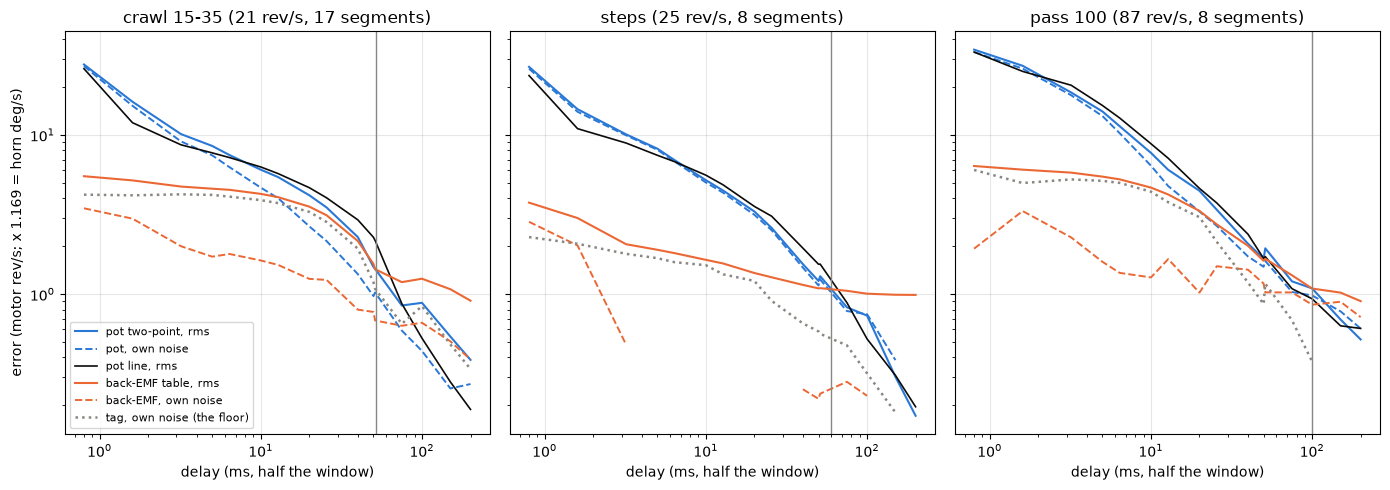

In [58]:
fig, ax = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
for a, band in zip(ax, XO_BANDS):
    d = g[g.band == band].sort_values("n")
    x = d.delay_ms
    a.plot(x, d.pot_two_rms, color=BLUE, label="pot two-point, rms")
    a.plot(x, d.hat_pot, "--", color=BLUE, lw=1.4, label="pot, own noise")
    a.plot(x, d.pot_ls_rms, color=INK, lw=1.2, label="pot line, rms")
    a.plot(x, d.emf_tab_rms, color=ORANGE, label="back-EMF table, rms")
    a.plot(x, d.hat_emf.where(d.hat_emf > 0), "--", color=ORANGE, lw=1.4,
           label="back-EMF, own noise")
    a.plot(x, d.hat_tag.where(d.hat_tag > 0), ":", color=MUTED, lw=1.8,
           label="tag, own noise (the floor)")
    xr = XOVER[(XOVER["align"] == "group") & (XOVER.band == band)
               & (XOVER.pot == "pot_two") & (XOVER.emf == "emf_tab")
               & (XOVER.stat == "rms")].iloc[0]
    if np.isfinite(xr.window_ms):
        a.axvline(xr.window_ms / 2, color=MUTED, lw=1)
    a.set_xscale("log")
    a.set_yscale("log")
    figures.label(a, x="delay (ms, half the window)",
                  title=f"{band} ({d.w_tag.mean():.0f} rev/s, "
                        f"{int(d.segs.max())} segments)")
ax[0].set_ylabel("error (motor rev/s; x 1.169 = horn deg/s)")
ax[0].legend(fontsize=8, loc="lower left")
figures.finish(fig)

For a loop the numbers that matter sit far left of the crossing. At 5 ms of delay the pot's slope has 7.4 rev/s of its own error at a crawl and the back-EMF 1.7. The pot's slope wins only where the back-EMF is not valid, under the floor, or where 50 ms and more of delay is acceptable. Against the tag a blend by window length has little to gain between 50 and 200 ms, where the two curves run parallel. Section 7 builds one velocity of the two.

## 6. The rest verdict

A loop needs to know when the horn is not turning, so that it can report a velocity of zero there instead of a slope's noise or a back-EMF reading under current. The rest verdict is a causal flag, "the horn is not turning", set from the pot and optionally vetoed by the back-EMF. While it is set the velocity to report is zero.

Two forms are carried as equal alternatives, each with its thresholds in the servo's own rest noise.

- The band. The pot through a boxcar of 16 rows has stayed within +/- b counts of an anchor for a total time T. The anchor is the reading on the row the count last restarted. A carry-aware variant asks for a longer T on rows whose reading sits on a carry's wide code.
- The slope. The two-boxcar slope of 16 rows, n rows apart, has stayed under 5 times its own rest sd for a total time T, its own window included.

The veto clears either one where the back-EMF says the rotor turns. Its reference is the stopped rotor, which the back-EMF reads as a speed that grows with the current, so the stopped rotor's line comes first.

### The veto's reference, the stopped rotor's line

Stage 3's load ladders held the arm still against gravity at a ladder of duties. The back-EMF speed of record runs over every stage 3 window from the drive's first row, so the newton seed, the start-up and the dropout reference are what a controller would hold at the window. A window's estimate is the mean of its valid rows, and a window with valid rows on under half of them has none. On a load hold at rest the truth is zero and the estimate is its error. The same estimates serve section 8.

In [59]:
H_KEEP = ("set", "k", "dir", "duty_pct", "truth", "rail_v", "ntc_c", "sweep",
          "still", "t_ms", "volts_set", "repeat", "tach_cycles",
          "kept_turning", "window_valid_share", "angle_deg", "pot_rev_s")


def estimate_windows(T, name):
    """Each window's mean back-EMF over its valid rows (both forms), the
    estimate run from the window's run0."""
    recs = []
    for run0, grp in T.groupby("run0"):
        g_end = int(grp.g1.max())
        E = speed.emf_run(ARR, int(run0), g_end, Z, ARR["duty_sign"],
                          float(grp.ntc_c.iloc[0]), CH, MO, TAB, PROD, RULE)
        pos = ARR["pos"][int(run0):g_end]
        duty = ARR["duty"][int(run0):g_end]
        for r in grp.itertuples():
            a, b = int(r.g0 - run0), int(r.g1 - run0)
            v = E["valid"][a:b]
            rec = dict(idx=r.Index, valid_share=float(v.mean()),
                       duty_ticks=float(np.median(duty[a:b])))
            if v.sum() >= 0.5 * (b - a):        # else: no estimate
                rec.update(
                    w_tab=float(E["w_tab"][a:b][v].mean()),
                    w_prod=float(E["w_prod"][a:b][v].mean()),
                    i_ma=float(E["i_w"][a:b][v].mean() * 1e3),
                    v_on=float(E["v_on"][a:b][v].mean()),
                    pos_rng=float(np.ptp(pos[a:b])),
                    pos_mean=float(pos[a:b].mean()),
                    row_sd=float(E["w_tab"][a:b][v].std()), rows=int(b - a))
            recs.append(rec)
    R = pd.DataFrame(recs).set_index("idx")
    out = T[[c for c in H_KEEP if c in T.columns]].join(R)
    out.insert(0, "table", name)
    return out

In [60]:
H_WIN = pd.concat([estimate_windows(WIN[n], n) for n in WIN],
                  ignore_index=True)
H_WIN["e_tab"] = H_WIN.w_tab - H_WIN.truth        # rev/s, error
H_WIN["e_prod"] = H_WIN.w_prod - H_WIN.truth
print("windows estimated:", H_WIN.groupby("table").size().to_dict(),
      "; with an estimate:",
      H_WIN[H_WIN.w_tab.notna()].groupby("table").size().to_dict())

windows estimated: {'holds': 154, 'ladder': 144, 'lift': 312, 'load': 122} ; with an estimate: {'holds': 104, 'ladder': 144, 'lift': 312, 'load': 116}


In [61]:
def wls_line(x, y, groups=None):
    """y = a + b x by least squares: (a, b), their se (by resampling the
    groups, the sweeps, 400 times where given) and the residual sd."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    X = np.c_[np.ones(len(x)), x]
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    res = y - X @ beta
    if groups is None:
        se = np.sqrt(np.diag(np.linalg.inv(X.T @ X) * res.var(ddof=2)))
    else:
        gid = pd.factorize(groups)[0]
        rng = np.random.default_rng(1)      # seeded: the se repeats
        idx_by = [np.flatnonzero(gid == g) for g in range(gid.max() + 1)]
        bs = []
        for _ in range(400):
            pick = np.concatenate([idx_by[g] for g in rng.integers(
                0, len(idx_by), len(idx_by))])
            bs.append(np.linalg.lstsq(X[pick], y[pick], rcond=None)[0])
        se = np.std(bs, axis=0)
    return beta, se, float(res.std(ddof=2))


def mean_se(d, col, by="sweep"):
    """(mean over windows, se over the groups' means, windows, groups)."""
    m = d.groupby(by)[col].mean()
    return (float(d[col].mean()),
            float(m.std(ddof=1) / np.sqrt(len(m))) if len(m) > 1 else np.nan,
            len(d), len(m))

In [62]:
H_LOAD = H_WIN[(H_WIN.table == "load") & (H_WIN.still == True)  # noqa: E712
               & H_WIN.w_tab.notna()].copy()
H_LOAD["e_tab"], H_LOAD["e_prod"] = H_LOAD.w_tab, H_LOAD.w_prod  # truth 0
STALL_LINES = {}
for form in ("tab", "prod"):
    beta, bse, rs = wls_line(H_LOAD.i_ma / 1e3, H_LOAD[f"e_{form}"],
                             H_LOAD["sweep"])
    STALL_LINES[form] = dict(a=beta[0], a_se=bse[0], b=beta[1], b_se=bse[1],
                             resid_sd=rs)
    print(f"{form}: stopped rotor reads {beta[0]:+.2f} +/- {bse[0]:.2f} + "
          f"({beta[1]:.1f} +/- {bse[1]:.1f}) x i rev/s (i in A), resid sd "
          f"{rs:.2f} rev/s")
st = STALL_LINES["tab"]                 # the veto reads the table form
STALL = dict(a_rev_s=float(st["a"]), b_rev_s_per_a=float(st["b"]),
             resid_sd_rev_s=float(st["resid_sd"]), n=len(H_LOAD),
             i_lo_ma=float(H_LOAD.i_ma.min()),
             i_hi_ma=float(H_LOAD.i_ma.max()))
print(f"{STALL['n']} holds at rest in {H_LOAD.sweep.nunique()} sweeps, "
      f"{STALL['i_lo_ma']:.0f} to {STALL['i_hi_ma']:.0f} mA")

tab: stopped rotor reads -4.54 +/- 1.18 + (42.7 +/- 5.3) x i rev/s (i in A), resid sd 3.63 rev/s
prod: stopped rotor reads -2.48 +/- 1.16 + (38.7 +/- 5.0) x i rev/s (i in A), resid sd 3.52 rev/s
67 holds at rest in 63 sweeps, 70 to 484 mA


The table form's line, $-4.54 + 42.7\,i$ rev/s with the current in A, is the veto's reference. Its residual sd, 3.63 rev/s, is the back-EMF's own scatter about it on a stopped rotor. The product form's line sits beside it. Section 8 shows that the stopped rotor's reading is convex in the current, so the line is a chord over 70 to 484 mA. The veto uses it as a reference with a margin, not as a correction.

### The servo's own rest noise

The thresholds come from the 21 torque-off baselines past their first 200 ms. The band is set in units of sigma16, the rest sd of the pot through the boxcar of 16, and the slope's threshold in units of its own rest sd at its length.

In [63]:
REST_K_S = 5.0          # the slope's threshold, x its own rest sd
REST_K_V = 3.0          # the veto's margin, x the stopped rotor's scatter
REST_N_VETO = 100       # rows, the back-EMF's boxcar the veto reads
REST_PAD = 4200         # rows of the rest reading before a series' start
MS = FS / 1e3           # rows per ms
REST_STOP_DEG = 0.10    # deg, a stop or start is told at this angle
REST_BINS = [(0.5, 2), (2, 5), (5, 10), (10, 15), (15, 25), (25, 35),
             (35, 60), (60, 150)]       # deg/s, the tag's speed bins
print(f"slope {REST_K_S:g} x its rest sd, veto {REST_K_V:g} sd over "
      f"{REST_N_VETO} rows, a series' start padded with {REST_PAD} rows, "
      f"stop and start at {REST_STOP_DEG:.2f} deg, stall rows from "
      f"{250} ms after the stop; baselines past their "
      f"first 4000 rows ({4000 / MS:.0f} ms); slopes over 192 and 992 rows,"
      f" {velocity.nominal_delay('box16', 192) / MS:.1f} and "
      f"{velocity.nominal_delay('box16', 992) / MS:.1f} ms of delay")

slope 5 x its rest sd, veto 3 sd over 100 rows, a series' start padded with 4200 rows, stop and start at 0.10 deg, stall rows from 250 ms after the stop; baselines past their first 4000 rows (200 ms); slopes over 192 and 992 rows, 5.2 and 25.2 ms of delay


In [64]:
y16, per_row, slopes = [], [], {192: [], 992: []}
for clip, k, segs in GROUPS:
    if segs != [0]:
        continue                        # the torque-off baselines only
    x = group_of(clip, k, segs)["pos"][4000:]     # past the first 200 ms
    per_row.append(x.std())
    y16.append(velocity.boxcar(x, 16)[16:].std())
    for n in slopes:
        slopes[n].append(np.nanstd(velocity.two_box(x, 16, n, FS)))
REST_NOISE = dict(
    sigma_row=float(np.median(per_row)), sigma16=float(np.median(y16)),
    sigma16_lo=float(np.min(y16)), sigma16_hi=float(np.max(y16)),
    windows=len(y16),
    slope_sd_counts_s={n: float(np.median(v)) for n, v in slopes.items()})
REST_NOISE["slope_thr_deg_s"] = {
    n: REST_K_S * v * LSB_DEG
    for n, v in REST_NOISE["slope_sd_counts_s"].items()}

In [65]:
nz = REST_NOISE
print(f"rest noise ({nz['windows']} baselines): per row "
      f"{nz['sigma_row']:.3f} counts, boxcar 16 {nz['sigma16']:.3f} "
      f"[{nz['sigma16_lo']:.3f}, {nz['sigma16_hi']:.3f}]")
print(f"slope sd 192 / 992 rows {nz['slope_sd_counts_s'][192]:.1f} / "
      f"{nz['slope_sd_counts_s'][992]:.2f} counts/s; thresholds "
      f"{nz['slope_thr_deg_s'][192]:.2f} / {nz['slope_thr_deg_s'][992]:.2f}"
      f" deg/s; bands of 1 / 2 / 4 counts = "
      + " / ".join(f"{b / nz['sigma16']:.1f}" for b in (1, 2, 4))
      + " sigma16")
print(f"veto margin {REST_K_V * STALL['resid_sd_rev_s']:.1f} rev/s over "
      f"max({STALL['a_rev_s']:.2f} + {STALL['b_rev_s_per_a']:.1f} i, 0)")

rest noise (21 baselines): per row 0.962 counts, boxcar 16 0.137 [0.000, 0.165]
slope sd 192 / 992 rows 20.2 / 3.73 counts/s; thresholds 5.09 / 0.94 deg/s; bands of 1 / 2 / 4 counts = 7.3 / 14.6 / 29.3 sigma16
veto margin 10.9 rev/s over max(-4.54 + 42.7 i, 0)


### The candidates

Each candidate has a total decision time T, its own window included. The bands are 1, 2 and 4 counts, the carry-aware bands take a longer T on a carry's wide code (+/- b counts) than elsewhere, and the slopes run over 192 rows (a delay of 5.2 ms) and 992 rows (25.2 ms). Nine of them run again with the veto. A series that starts under torque starts from the seek's rest, so its first 4200 rows are the rest reading and the verdict starts set. The cell below lists the hold times.

In [66]:
def rest_candidates():
    """The candidates: family, band b (counts), T and Tc (ms), the veto."""
    out = []
    for b in (1.0, 2.0, 4.0):
        for T in (10, 25, 50, 75, 100, 150):
            out.append(dict(name=f"band {b:g} T{T}", fam="band", b=b, T=T,
                            Tc=T, veto=False))
    for b in (1.0, 2.0):
        for Tf in (10, 25):
            for Tc in (75, 150):
                out.append(dict(name=f"bandc {b:g} T{Tf}/{Tc}", fam="bandc",
                                b=b, T=Tf, Tc=Tc, veto=False))
    for n, Ts in ((192, (25, 50, 75, 100, 150)), (992, (75, 100, 150))):
        for T in Ts:
            out.append(dict(name=f"slope {n} T{T}", fam="slope", n=n, T=T,
                            veto=False))
    for base in ("band 1 T25", "band 1 T50", "band 2 T25", "band 2 T50",
                 "band 2 T75", "bandc 2 T25/75", "bandc 1 T10/75",
                 "slope 192 T50", "slope 192 T75"):
        c = dict(next(x for x in out if x["name"] == base))
        c["name"] += " + emf"
        c["veto"] = True
        out.append(c)
    return out

In [67]:
def rest_flag(c, P, rest0):
    """One candidate's verdict over the prepared series P."""
    veto = P["veto"] if c["veto"] else None
    if c["fam"] in ("band", "bandc"):
        t, tc = int(c["T"] * MS) - 16, int(c["Tc"] * MS) - 16
        ic = P["in_carry"][c["b"]] if c["fam"] == "bandc" else None
        return velocity.rest_band(P["y16"], c["b"], t, ic, tc, veto, rest0)
    thr = REST_K_S * REST_NOISE["slope_sd_counts_s"][c["n"]]
    t = max(int(c["T"] * MS) - (c["n"] + 16), 1)
    return velocity.rest_slope(P["s"][c["n"]], thr, t, veto, rest0)


REST_CANDS = rest_candidates()
print(len(REST_CANDS), "candidates; hold times T",
      sorted({c["T"] for c in REST_CANDS}), "ms; on a carry",
      sorted({c["Tc"] for c in REST_CANDS if c["fam"] == "bandc"}), "ms")

43 candidates; hold times T [10, 25, 50, 75, 100, 150] ms; on a carry [75, 150] ms


In [68]:
def rest_veto(w_tab, drive, i_w, tap_ok, started, drop, k=REST_K_V):
    """(veto, boxcar of the back-EMF, it carries): the back-EMF in the pot's
    sign, through a boxcar of REST_N_VETO usable rows, further than k sd
    from the stopped rotor's line at the row's current."""
    w, usable = velocity.emf_signed(w_tab, drive, tap_ok, started, drop)
    wf, carry = velocity.emf_boxcar(w, usable, REST_N_VETO)
    veto = velocity.emf_turning(
        wf * drive, carry, i_w, STALL["a_rev_s"], STALL["b_rev_s_per_a"],
        k * STALL["resid_sd_rev_s"])
    return veto, wf, carry


def rest_flags_of(g):
    """The back-EMF's flags of a series' rows (False on a filled row)."""
    E = EMF[(g["clip"], g["k"])]
    src = g["src"]
    ok = src >= 0
    out = []
    for name in ("tap_ok", "started", "drop"):
        f = np.zeros(len(src), bool)
        f[ok] = E[name][src[ok]]
        out.append(f)
    return out

In [69]:
def rest_prepare(g, pad):
    """The padded series and what every candidate reads; the truth."""
    rest_read = g["pos"][:16].mean()
    pos = np.r_[np.full(pad, rest_read), g["pos"]]
    zpad = np.zeros(pad, bool)
    P = dict(pad=pad, n=len(pos), pos=pos, clip=g["clip"], k=g["k"])
    P["y16"] = velocity.boxcar(pos, 16)
    P["s"] = {n: velocity.two_box(pos, 16, n, FS) for n in (192, 992)}
    P["in_carry"] = {b: np.r_[zpad, velocity.carry_band(
        g["pos"], CARRY_CODES, CARRY_MISSING, b)] for b in (1.0, 2.0)}
    P["near"] = np.r_[zpad, velocity.carry_band(
        g["pos"], CARRY_CODES, CARRY_MISSING, 12)]
    tap_ok, started, drop = rest_flags_of(g)
    veto, wf, carry = rest_veto(g["w_tab"], g["drive"], g["i_w"], tap_ok,
                                started, drop)
    veto2, _, _ = rest_veto(g["w_tab"], g["drive"], g["i_w"], tap_ok,
                            started, drop, 2.0)
    P["veto"], P["veto2"] = np.r_[zpad, veto], np.r_[zpad, veto2]
    P["usable"] = np.r_[zpad, carry]
    P["wf"] = np.r_[np.full(pad, np.nan), wf]
    for name in ("tag", "duty", "seg", "i_w", "w_tab"):
        P[name] = np.r_[np.full(pad, np.nan), g[name].astype(float)]
    h = int(50 * MS)                    # the tag's speed over +/- 50 ms
    v = np.full(P["n"], np.nan)
    v[h:-h] = (P["tag"][2 * h:] - P["tag"][:-2 * h]) / (2 * h / FS)
    P["v_tag"] = v
    P["yc"] = centered(pos, 8)          # the pot's centered mean, truth
    return P

### The truth for a verdict

The tag, smoothed over 7 frames, is the truth. A stop is the row the angle enters the last +/- 0.10 deg of a still stretch (stage 3's tag grade is 0.160 deg), by the tag and by the pot's own centered mean on the same band in counts. A start is the row it leaves the first +/- 0.10 deg. The rows fall in classes. Moving rows are a driven hold from 150 ms in, binned by the tag's speed over +/- 50 ms. Stall rows are a driven hold from 250 ms after its stop, by its on-time. Rest rows are the baselines past their head and the coasts from 150 ms in and 100 ms past their stop. False motion counts from the verdict's first declaration inside those rows.

In [70]:
def last_out(x, ref, tol, lo, hi):
    """The row after the last row in lo..hi with |x - ref| > tol."""
    bad = np.flatnonzero(np.abs(x[lo:hi] - ref) > tol)
    return lo + (bad[-1] + 1 if len(bad) else 0)


def first_out(x, ref, tol, lo, hi):
    """The first row in lo..hi with |x - ref| > tol, or -1."""
    bad = np.flatnonzero(np.abs(x[lo:hi] - ref) > tol)
    return lo + bad[0] if len(bad) else -1


REST_CLASSES = ("rest_base", "rest_coast", "stall72", "stall84", "stall_hi",
                "moving")


def rest_start_event(g, P, info):
    """The series' start: the rows the duty lands, the pot and the tag go."""
    pad, n, segs = P["pad"], P["n"], g["segs"]
    tol_c = REST_STOP_DEG / LSB_DEG
    drv = np.flatnonzero(np.nan_to_num(P["duty"][pad:]) != 0)
    hi = min(pad + 3000, n)
    return dict(what="start", label=info[segs[0]].label, seg=segs[0],
                duty=info[segs[0]].duty_ticks,
                r_duty=pad + (drv[0] if len(drv) else 0),
                r_pot=first_out(P["yc"], P["yc"][pad - 100:pad].mean(),
                                tol_c, pad, hi),
                r_tag=first_out(P["tag"], np.nanmean(P["tag"][pad:pad + 40]),
                                REST_STOP_DEG, pad, hi), lo=pad, hi=hi)

In [71]:
def rest_stops(g, P, info, bounds, cls):
    """The stops of a series' still segments, marking the rest and stall
    rows in cls."""
    tag, yc, segs, ev, still_end = P["tag"], P["yc"], g["segs"], [], {}
    tol_c = REST_STOP_DEG / LSB_DEG
    for j, s in enumerate(segs):
        a, b = bounds[j], bounds[j + 1]
        lab = info[s].label
        if lab == "kick":
            continue
        tail = slice(b - 4000, b)       # the segment's last 200 ms
        d_tag = (np.nanmax(tag[tail]) - np.nanmin(tag[tail])
                 if np.isfinite(tag[tail]).sum() > 100 else np.nan)
        d_pot = yc[tail].max() - yc[tail].min()
        still = (d_pot <= 2 * tol_c) and (not np.isfinite(d_tag)
                                          or d_tag <= 2 * REST_STOP_DEG)
        still_end[s] = still
        if not still:
            continue
        lo = bounds[j - 1] if j else a
        if lab == "coast" and still_end.get(segs[j - 1], False):
            cls["rest_coast"][a + 3000:b] = True
            continue                    # stopped in the hold before
        r_pot = last_out(yc, yc[tail].mean(), tol_c, lo, b)
        r_tag = (last_out(tag, np.nanmean(tag[tail]), REST_STOP_DEG, lo, b)
                 if np.isfinite(d_tag) else -1)
        ev.append(dict(what="stop", label=lab, seg=s,
                       duty=info[s].duty_ticks, r_pot=r_pot, r_tag=r_tag,
                       lo=lo, hi=b, r_duty=a))
        if lab == "coast":
            cls["rest_coast"][max(a + 3000, r_pot + 2000):b] = True
        else:
            r0 = max(r_pot, r_tag) + int(250 * MS)
            key = {72: "stall72", 84: "stall84"}.get(
                int(info[s].duty_ticks), "stall_hi")
            cls[key][r0:b - 400] = True
    return ev

In [72]:
def rest_events(g, P):
    """(events, row classes) of one series, masks over the padded rows."""
    pad, n = P["pad"], P["n"]
    cls = {name: np.zeros(n, bool) for name in REST_CLASSES}
    segs = g["segs"]
    if segs == [0]:
        cls["rest_base"][4000:] = True
        return [], cls
    bounds = [s + pad for s in g["starts"]] + [n]
    info = {r.seg: r for r in SEGS[(SEGS["clip"] == g["clip"])
                                   & (SEGS.k == g["k"])].itertuples()}
    ev = [rest_start_event(g, P, info)] + rest_stops(g, P, info, bounds,
                                                      cls)
    for j, s in enumerate(segs):        # moving: a driven hold, 150 ms in
        if info[s].label in ("crawl", "hold", "pass", "reversal",
                             "step-base", "step-top"):
            a, b = bounds[j], bounds[j + 1]
            cls["moving"][a + int(150 * MS):b - 400] = True
    return ev, cls

In [73]:
def rest_score_rows(flag, P, cls, acc):
    """Add a series' false rest by speed and false motion by class."""
    v = np.abs(P["v_tag"])
    mv = cls["moving"] & np.isfinite(v)
    for lo, hi in REST_BINS:
        m = mv & (v >= lo) & (v < hi)
        for side, mm in (("all", m), ("near", m & P["near"]),
                         ("far", m & ~P["near"])):
            a = acc["bins"].setdefault((lo, hi, side), [0, 0])
            a[0] += int(mm.sum())
            a[1] += int((mm & flag).sum())
    drops = np.flatnonzero(flag[:-1] & ~flag[1:]) + 1
    for name in REST_CLASSES[:-1]:
        m = cls[name]
        a = acc["rest"].setdefault(name, [0, 0, 0, 0, 0])
        if not m.any():
            continue
        fl = np.flatnonzero(m & flag)
        a[3] += 1
        if len(fl) == 0:
            a[4] += 1                   # never declared in the class's rows
            continue
        m = m.copy()
        m[:fl[0]] = False               # from the first declaration on
        a[0] += int(m.sum())
        a[1] += int((m & ~flag).sum())
        a[2] += int(m[drops].sum())
    return drops

In [74]:
def rest_score_events(c, flag, P, ev, drops, acc):
    """Add a series' declare and drop times (ms) per event."""
    for e in ev:
        rec = dict(cand=c["name"], clip=P["clip"], k=P["k"], what=e["what"],
                   label=e["label"], seg=e["seg"], duty=e["duty"])
        if e["what"] == "start":
            un = np.flatnonzero(~flag[e["lo"]:])
            r = e["lo"] + un[0] if len(un) else -1
            for ref in ("r_duty", "r_pot", "r_tag"):
                rec["d_" + ref[2:]] = ((r - e[ref]) / MS
                                       if (r >= 0 and e[ref] >= 0) else np.nan)
        else:
            for ref in ("r_pot", "r_tag"):
                t0 = e[ref]
                if t0 < 0 or t0 >= e["hi"]:
                    rec["d_" + ref[2:]] = np.nan
                    continue
                if flag[t0]:            # declared before the truth's stop
                    un = np.flatnonzero(~flag[e["lo"]:t0])
                    r = e["lo"] + (un[-1] + 1 if len(un) else 0)
                else:
                    st = np.flatnonzero(flag[t0:e["hi"]])
                    r = t0 + st[0] if len(st) else -1
                rec["d_" + ref[2:]] = (r - t0) / MS if r >= 0 else np.nan
                if ref == "r_pot":
                    rec["drops_after"] = (int(((drops > max(r, t0))
                                               & (drops < e["hi"])).sum())
                                          if r >= 0 else -1)
        acc["events"].append(rec)

In [75]:
def rest_blip(g, P, cls):
    """The pot around the row the drive goes off into a coast, counts
    against the coast's tail."""
    recs, pad = [], P["pad"]
    info = {r.seg: r for r in SEGS[(SEGS["clip"] == g["clip"])
                                   & (SEGS.k == g["k"])].itertuples()}
    for j, s in enumerate(g["segs"]):
        if info[s].label != "coast" or j == 0:
            continue
        a = g["starts"][j] + pad
        b = ((g["starts"][j + 1] + pad) if j + 1 < len(g["segs"])
             else P["n"])
        ref = P["pos"][b - 2000:b].mean()
        prev_still = bool(cls["rest_coast"][a + 3000]) and not bool(
            cls["moving"][a - 500] and abs(P["v_tag"][a - 1200]) > 2)
        rec = dict(clip=g["clip"], k=g["k"], seg=s,
                   duty=info[g["segs"][j - 1]].duty_ticks, stalled=prev_still,
                   i_ma=float(np.nanmean(P["i_w"][a - 2400:a - 400]) * 1e3),
                   hold_last20=float(P["pos"][a - 600:a - 200].mean() - ref))
        for name, (lo, hi) in (("0-1ms", (0, 20)), ("1-2ms", (20, 40)),
                               ("2-5ms", (40, 100)), ("5-10ms", (100, 200)),
                               ("10-20ms", (200, 400)),
                               ("20-50ms", (400, 1000))):
            rec[name] = float(P["pos"][a + lo:a + hi].mean() - ref)
        recs.append(rec)
    return recs

In [76]:
def rest_stall_row(clip, k, segs, P, cls):
    """The stopped rotor on the camera sitting, one stall class's rows."""
    out = []
    for name in ("stall72", "stall84", "stall_hi"):
        m = cls[name]
        if m.sum() <= 2000:
            continue
        us = P["usable"][m]
        out.append(dict(
            clip=clip, k=k, seg=segs[1], cls=name, rows=int(m.sum()),
            i_ma=float(np.nanmean(P["i_w"][m]) * 1e3),
            w_tab=float(np.nanmean(P["w_tab"][m])), usable=float(us.mean()),
            veto=float(P["veto"][m].mean()),
            veto2=float(P["veto2"][m].mean()),
            wf_max=float(np.nanmax(np.abs(P["wf"][m]))) if us.any()
            else np.nan,
            tag_move=float(np.nanmax(P["tag"][m]) - np.nanmin(P["tag"][m])),
            pot_sd16=float(P["y16"][m].std()), near=float(P["near"][m].mean())))
    return out

In [77]:
acc = {c["name"]: dict(bins={}, rest={}, events=[]) for c in REST_CANDS}
blips, pre, st84, veto_rows = [], [], [], {}
for clip, k, segs in GROUPS:
    g = group_of(clip, k, segs)
    P = rest_prepare(g, REST_PAD if segs != [0] else 0)
    ev, cls = rest_events(g, P)
    if segs != [0]:                     # the horn before the series' start
        tg = PF.tags[clip]
        tg = tg[tg["both"]]
        c0 = g["cam"][0]
        w = tg[(tg["host"] > c0 - 0.15) & (tg["host"] < c0)]
        if len(w) > 5:
            pre.append(float(np.ptp(w["image_deg"])))
        blips += rest_blip(g, P, cls)
    st84 += rest_stall_row(clip, k, segs, P, cls)
    v = np.abs(P["v_tag"])
    for lo, hi in REST_BINS:            # the veto alone, by speed
        m = cls["moving"] & np.isfinite(v) & (v >= lo) & (v < hi)
        vr = veto_rows.setdefault((lo, hi), [0, 0, 0, 0])
        vr[0] += int(m.sum())
        vr[1] += int((m & P["usable"]).sum())
        vr[2] += int((m & P["veto"]).sum())
        vr[3] += int((m & P["veto2"]).sum())
    for c in REST_CANDS:
        flag = rest_flag(c, P, segs != [0])
        drops = rest_score_rows(flag, P, cls, acc[c["name"]])
        rest_score_events(c, flag, P, ev, drops, acc[c["name"]])
print(f"the horn before a series' first row: tag range over the 150 ms "
      f"before, median {np.median(pre):.3f} deg, max {np.max(pre):.3f} "
      f"({len(pre)} series)")

the horn before a series' first row: tag range over the 150 ms before, median 0.053 deg, max 0.153 (42 series)


In [78]:
def rest_table_row(c, a, sp):
    """One candidate's row: false rest by speed band and side, false
    motion and drops per class, declare and drop times."""
    rec = dict(cand=c["name"], fam=c["fam"], veto=c["veto"], T_ms=c["T"],
               Tc_ms=c.get("Tc", c["T"]))
    for lo, hi in REST_BINS:
        for side in ("all", "near", "far"):
            nrow, nflag = a["bins"][(lo, hi, side)]
            sp.append(dict(cand=c["name"], lo=lo, hi=hi, side=side,
                           rows=nrow, false_rest=nflag / max(nrow, 1)))
    for lo, hi, tagn in ((10, 35, "crawl10_35"), (2, 10, "slow2_10"),
                         (60, 150, "pass")):
        for side in ("all", "near", "far"):
            tot = [a["bins"][(x, y, side)] for x, y in REST_BINS
                   if x >= lo and y <= hi]
            nrow, nflag = sum(t[0] for t in tot), sum(t[1] for t in tot)
            rec[f"fr_{tagn}_{side}"] = nflag / max(nrow, 1)
            rec[f"n_{tagn}_{side}"] = nrow
    for name, (nrow, unset, drops, nseg, never) in a["rest"].items():
        rec[f"never_{name}"] = never
        rec[f"segs_{name}"] = nseg
        rec[f"fm_{name}"] = unset / max(nrow, 1)
        rec[f"drops_s_{name}"] = drops / max(nrow / FS, 1e-9)
        rec[f"n_{name}"] = nrow
    return rec

In [79]:
def rest_times(rec, E):
    """Add the declare and drop times (median, p90, min, n) to a row."""
    for what, sel, cols in (
            ("stop_hold", (E.what == "stop") & (E.label != "coast"),
             ("d_pot", "d_tag")),
            ("stop_coast", (E.what == "stop") & (E.label == "coast"),
             ("d_pot", "d_tag")),
            ("start", E.what == "start", ("d_duty", "d_pot", "d_tag"))):
        d = E[sel]
        for col in cols:
            x = d[col].dropna()
            rec[f"{what}_{col}_med"] = x.median() if len(x) else np.nan
            rec[f"{what}_{col}_p90"] = x.quantile(0.9) if len(x) else np.nan
            rec[f"{what}_{col}_min"] = x.min() if len(x) else np.nan
            rec[f"{what}_{col}_n"] = len(x)
        if what != "start":
            rec[f"{what}_never"] = int(d.d_pot.isna().sum())
            rec[f"{what}_drops_after"] = (
                float(d.drops_after.clip(lower=0).mean()) if len(d)
                else np.nan)
    return rec


rows, sp, evs = [], [], []
for c in REST_CANDS:
    E = pd.DataFrame(acc[c["name"]]["events"])
    evs.append(E)
    rows.append(rest_times(rest_table_row(c, acc[c["name"]], sp), E))
REST_CANDS_T = pd.DataFrame(rows)       # one row per candidate
REST_EVENTS = pd.concat(evs)            # one row per candidate and event
REST_SPEED = pd.DataFrame(sp)           # false rest by speed bin
REST_BLIP = pd.DataFrame(blips)
REST_STALL84 = pd.DataFrame(st84)

In [80]:
def rest_stage3_items():
    """Stage 3's stopped rotors under current: the load holds at rest and
    the end-stop stalls of the stall sweeps (the pot still over its last
    2000 rows), each with its drive's first row and its NTC."""
    W = WIN["load"]
    items = [dict(set="load holds", run0=int(r.run0), g0=int(r.g0),
                  g1=int(r.g1), ntc=float(r.ntc_c))
             for r in W[W.still].itertuples()]
    runs = STORE.runs
    stall_sw = set(SW.index[SW.stall.astype(bool)])
    R = runs[runs.sweep.isin(stall_sw) & (runs.duty > 0) & (runs.n >= 4000)]
    for r in R.itertuples():
        pos = ARR["pos"][int(r.i1) - 2000:int(r.i1)]
        if np.ptp(pos) > 8 or pos.min() < 8 or pos.max() > 4087:
            continue                    # moving, or on the converter's rail
        items.append(dict(set="stalls " + SW.loc[r.sweep, "experiment"],
                          run0=int(r.i0), g0=int(r.i1) - 2000, g1=int(r.i1),
                          ntc=float(NTC_SWEEP[r.sweep])))
    return items

In [81]:
def rest_stage3(items):
    """Each candidate over a stopped rotor's own rows from a cold start, and
    the veto on them."""
    recs = []
    for it in items:
        E = speed.emf_run(ARR, it["run0"], it["g1"], Z, ARR["duty_sign"],
                          it["ntc"], CH, MO, TAB, PROD, RULE)
        a = it["g0"] - it["run0"]
        pos = ARR["pos"][it["g0"]:it["g1"]].astype(float)
        sgn = np.asarray(ARR["duty_sign"][it["run0"]:it["g1"]]).astype(float)
        veto, wf, carry = rest_veto(E["w_tab"], sgn, E["i_w"], E["tap_ok"],
                                    E["started"], E["drop"])
        P = dict(y16=velocity.boxcar(pos, 16), veto=veto[a:],
                 s={m: velocity.two_box(pos, 16, m, FS) for m in (192, 992)},
                 in_carry={b: velocity.carry_band(pos, CARRY_CODES,
                                                  CARRY_MISSING, b)
                           for b in (1.0, 2.0)})
        base = dict(set=it["set"], rows=len(pos),
                    i_ma=float(np.nanmean(E["i_w"][a:]) * 1e3),
                    w_f=float(np.nanmean(wf[a:] * sgn[a:])),
                    usable=float(carry[a:].mean()),
                    veto_share=float(veto[a:].mean()),
                    pos_sd16=float(P["y16"][16:].std()))
        for c in REST_CANDS:
            T = int(c.get("Tc", c["T"]) * MS)
            if T + 300 >= len(pos):
                continue
            f = rest_flag(c, P, False)
            tail = f[T + 200:]
            recs.append(dict(base, cand=c["name"], scored=len(tail),
                             unset=int((~tail).sum()), declared=bool(f.any()),
                             drops=int((f[:-1] & ~f[1:]).sum())))
    return pd.DataFrame(recs)


REST_STAGE3 = rest_stage3(rest_stage3_items())

### False rest and false motion

The table below gives, per candidate, the share of moving rows at 10 to 35 deg/s it calls rest (all of them, those within 12 counts of a carry and those far from one) and at 2 to 10 deg/s, the share of rest and stall rows it calls motion after its first declaration, and the drops per second on the coast tails.

In [82]:
C = REST_CANDS_T
pct = lambda x: (100 * x).round(2)                          # noqa: E731
show = pd.DataFrame({
    "cand": C.cand, "fr_10_35": pct(C.fr_crawl10_35_all),
    "near": pct(C.fr_crawl10_35_near), "far": pct(C.fr_crawl10_35_far),
    "fr_2_10": pct(C.fr_slow2_10_all), "fm_base": pct(C.fm_rest_base),
    "fm_coast": pct(C.fm_rest_coast), "fm_st72": pct(C.fm_stall72),
    "fm_st84": pct(C.fm_stall84), "fm_sthi": pct(C.fm_stall_hi),
    "drops_s_coast": C.drops_s_rest_coast.round(2)})
c0 = C.iloc[0]
print(f"rows: 10-35 deg/s {int(c0.n_crawl10_35_all)} (near a carry "
      f"{int(c0.n_crawl10_35_near)}), 2-10 deg/s {int(c0.n_slow2_10_all)}, "
      f"baseline {int(c0.n_rest_base)}, coast {int(c0.n_rest_coast)}, "
      f"stall 72 / 84 / 96 ticks {int(c0.n_stall72)} / {int(c0.n_stall84)}"
      f" / {int(c0.n_stall_hi)}")
print("false rest (fr) and false motion (fm), % of rows:")
print(show.to_string(index=False))

rows: 10-35 deg/s 480310 (near a carry 35414), 2-10 deg/s 20612, baseline 126000, coast 101879, stall 72 / 84 / 96 ticks 79870 / 25683 / 17961
false rest (fr) and false motion (fm), % of rows:
                cand  fr_10_35  near   far  fr_2_10  fm_base  fm_coast  fm_st72  fm_st84  fm_sthi  drops_s_coast
          band 1 T10      0.62  6.17  0.18    27.19     0.04      0.54     0.00      0.0      0.0           0.59
          band 1 T25      0.04  0.51  0.00    11.43     0.04      1.38     0.00      0.0      0.0           0.59
          band 1 T50      0.00  0.00  0.00     0.55     0.04      2.06     0.00      0.0      0.0           0.59
          band 1 T75      0.00  0.00  0.00     0.00     0.04      2.10     0.00      0.0      0.0           0.60
         band 1 T100      0.00  0.00  0.00     0.00     0.04      2.15     0.00      0.0      0.0           0.62
         band 1 T150      0.00  0.00  0.00     0.00     0.04      2.59     0.00      0.0      0.0           0.74
          band 2

In [83]:
print("false rest by the tag's speed, % of rows (all; near a carry):")
fr = REST_SPEED.pivot_table(index="cand", columns=["side", "lo"],
                            values="false_rest")
pick = ["band 2 T25", "band 2 T50", "band 2 T75", "band 2 T100",
        "slope 192 T25", "slope 192 T50", "slope 192 T75", "band 1 T10"]
print((100 * fr.loc[pick, ["all", "near"]]).round(2).to_string())
rows_by = REST_SPEED[(REST_SPEED.cand == pick[0])
                     & (REST_SPEED.side == "all")]
print("rows per bin:", dict(zip(rows_by.lo, rows_by.rows)))
n_cr = int(C.n_crawl10_35_all.iloc[0])
print(f"3 / n on the {n_cr} rows at 10-35 deg/s: {300 / n_cr:.4f} %; "
      f"near a carry 3 / {int(C.n_crawl10_35_near.iloc[0])}: "
      f"{300 / C.n_crawl10_35_near.iloc[0]:.3f} %")

false rest by the tag's speed, % of rows (all; near a carry):
side              all                                           near                                        
lo               0.5    2.0    5.0   10.0  15.0 25.0  35.0 60.0 0.5  2.0  5.0   10.0   15.0  25.0  35.0 60.0
cand                                                                                                        
band 2 T25     100.00  66.06   3.44  0.00  0.17  0.0  0.00  0.0  0.0  0.0  0.0  0.00   2.22  0.00  0.00  0.0
band 2 T50      99.07  11.95   0.00  0.00  0.00  0.0  0.00  0.0  0.0  0.0  0.0  0.00   0.00  0.00  0.00  0.0
band 2 T75      80.96   0.00   0.00  0.00  0.00  0.0  0.00  0.0  0.0  0.0  0.0  0.00   0.00  0.00  0.00  0.0
band 2 T100     59.91   0.00   0.00  0.00  0.00  0.0  0.00  0.0  0.0  0.0  0.0  0.00   0.00  0.00  0.00  0.0
slope 192 T25  100.00  67.18   0.99  0.00  0.17  0.0  0.00  0.0  0.0  0.0  0.0  0.00   2.22  0.00  0.00  0.0
slope 192 T50   97.99  12.69   0.00  0.00  0.00  0.0  0.00  0.0  0

### Time to declare and to drop

A verdict is declared after a stop and dropped after a start. The declare time is read from the pot's own stop (its last 2 counts) and from the tag's, on the coast-downs and on the holds that stall. The drop time is read from the row the duty lands, from the pot's first 2 counts and from the tag's first 0.1 deg.

In [84]:
cols = {"stop_coast_d_pot": "coast-down from the pot's stop",
        "stop_coast_d_tag": "coast-down from the tag's stop",
        "stop_hold_d_pot": "stalled hold from the pot's stop",
        "start_d_duty": "start from the duty",
        "start_d_pot": "start from the pot",
        "start_d_tag": "start from the tag"}
pick = ["band 1 T50", "band 2 T25", "band 2 T50", "band 2 T75",
        "band 4 T50", "slope 192 T25", "slope 192 T50", "slope 192 T75",
        "band 2 T50 + emf", "slope 192 T50 + emf"]
T6 = C.set_index("cand").loc[pick]
for col, name in cols.items():
    print(f"{name} (n {int(T6[col + '_n'].max())}), ms median [p90]: "
          + ", ".join(f"{c} {T6.loc[c, col + '_med']:.1f} "
                      f"[{T6.loc[c, col + '_p90']:.1f}]" for c in pick))
print(f"the slope's window {192 + 16} rows, the veto's {N_START} start-up"
      f" rows and {REST_N_VETO}-row boxcar")
print(f"min after a coast-down's stop, band 2 T50 "
      f"{T6.loc['band 2 T50', 'stop_coast_d_pot_min']:.1f} ms")

coast-down from the pot's stop (n 28), ms median [p90]: band 1 T50 58.5 [82.2], band 2 T25 31.4 [39.5], band 2 T50 56.4 [64.5], band 2 T75 81.3 [89.5], band 4 T50 50.2 [59.5], slope 192 T25 31.1 [32.8], slope 192 T50 56.1 [57.8], slope 192 T75 81.1 [82.8], band 2 T50 + emf 56.4 [65.9], slope 192 T50 + emf 56.1 [57.8]
coast-down from the tag's stop (n 28), ms median [p90]: band 1 T50 21.5 [57.0], band 2 T25 -22.0 [31.9], band 2 T50 3.0 [56.9], band 2 T75 28.0 [81.9], band 4 T50 -1.9 [51.2], slope 192 T25 -20.7 [27.9], slope 192 T50 4.3 [52.9], slope 192 T75 29.3 [77.9], band 2 T50 + emf 11.4 [55.0], slope 192 T50 + emf 4.3 [52.9]
stalled hold from the pot's stop (n 6), ms median [p90]: band 1 T50 64.5 [70.7], band 2 T25 30.3 [38.7], band 2 T50 55.3 [63.7], band 2 T75 80.3 [88.7], band 4 T50 55.5 [62.9], slope 192 T25 33.7 [36.6], slope 192 T50 58.7 [61.6], slope 192 T75 83.7 [86.6], band 2 T50 + emf 58.1 [78.5], slope 192 T50 + emf 58.7 [61.6]
start from the duty (n 42), ms median [p90]

### The veto

The veto clears the verdict where the back-EMF through a boxcar of 100 usable rows reads more than 3 sd, 10.9 rev/s, off the stopped rotor's line at the row's current. Below are the share of moving rows on which the back-EMF is usable at all and the share on which the veto fires, by the tag's speed, then what it does on stopped rotors.

In [85]:
REST_VETO = pd.DataFrame([dict(lo=lo, hi=hi, rows=n, usable=u, veto_3sd=v,
                               veto_2sd=v2)
                          for (lo, hi), (n, u, v, v2) in veto_rows.items()])
for r in REST_VETO.itertuples():
    n, u = max(r.rows, 1), max(r.usable, 1)
    print(f"{r.lo:>5}-{r.hi:<4} deg/s: {r.rows:>7} rows, usable "
          f"{r.usable / n:.1%}, veto {r.veto_3sd / n:.1%} "
          f"({r.veto_3sd / u:.1%} of usable; at 2 sd {r.veto_2sd / u:.1%})")
one = REST_STAGE3[REST_STAGE3.cand == REST_CANDS[0]["name"]]
print(one.groupby("set").agg(
    n=("rows", "size"), i_lo=("i_ma", "min"), i_hi=("i_ma", "max"),
    w_f=("w_f", "mean"), w_max=("w_f", "max"), usable=("usable", "mean"),
    veto_any=("veto_share", lambda x: int((x > 0).sum())))
    .round(2).to_string())
lo_w = one.loc[one.veto_share > 0]
print(f"stopped rotors with usable back-EMF rows {int((one.usable > 0).sum())}"
      f" of {len(one)}; the veto fires on", lo_w[["set", "i_ma", "w_f"]]
      .round(1).to_dict("records"))

  0.5-2    deg/s:   13453 rows, usable 26.5%, veto 0.0% (0.0% of usable; at 2 sd 0.0%)
  2.0-5    deg/s:    4720 rows, usable 30.3%, veto 0.0% (0.0% of usable; at 2 sd 0.0%)
  5.0-10   deg/s:   15892 rows, usable 40.4%, veto 7.3% (18.1% of usable; at 2 sd 63.4%)
 10.0-15   deg/s:   61501 rows, usable 43.8%, veto 23.2% (53.1% of usable; at 2 sd 94.2%)
 15.0-25   deg/s:  183418 rows, usable 93.1%, veto 91.4% (98.2% of usable; at 2 sd 99.9%)
 25.0-35   deg/s:  235391 rows, usable 100.0%, veto 100.0% (100.0% of usable; at 2 sd 100.0%)
 35.0-60   deg/s:  114851 rows, usable 100.0%, veto 100.0% (100.0% of usable; at 2 sd 100.0%)
 60.0-150  deg/s:   96518 rows, usable 100.0%, veto 100.0% (100.0% of usable; at 2 sd 100.0%)
                    n    i_lo    i_hi   w_f  w_max  usable  veto_any
set                                                                 
load holds         70   49.49  483.72  4.78  24.52     0.9         1
stalls resistance  39  222.84  371.28  7.22  15.87     1.0         0

In [86]:
print("the camera sitting's stalls by on-time:")
print(REST_STALL84.groupby("cls").agg(
    holds=("rows", "size"), rows=("rows", "sum"), i_ma=("i_ma", "mean"),
    w_tab=("w_tab", "mean"), w_sd=("w_tab", "std"),
    usable=("usable", "mean"), veto=("veto", "mean"),
    tag_move=("tag_move", "max"))
    .round(3).to_string())
g3 = REST_STAGE3.groupby(["cand", "set"]).agg(
    fm=("unset", "sum"), rows=("scored", "sum"),
    declared=("declared", "mean")).reset_index()
g3["fm"] = (100 * g3.fm / g3.rows).round(2)
pick = ["band 1 T50", "band 2 T50", "band 4 T50", "slope 192 T50",
        "slope 192 T75", "band 2 T50 + emf", "slope 192 T50 + emf"]
print("false motion on stage 3's stopped rotors, % of rows after T:")
print(g3.pivot(index="cand", columns="set", values="fm").loc[pick]
      .to_string())
cols = ["hold_last20", "0-1ms", "1-2ms", "2-5ms", "5-10ms", "10-20ms"]
for stalled, d in REST_BLIP.groupby("stalled"):
    print(f"the pot when the drive goes off, hold stalled {stalled}, n "
          f"{len(d)}: " + ", ".join(
              f"{cn} {d[cn].median():+.2f} [{d[cn].min():+.1f}, "
              f"{d[cn].max():+.1f}]" for cn in cols) + " counts")

the camera sitting's stalls by on-time:
          holds   rows    i_ma  w_tab   w_sd  usable  veto  tag_move
cls                                                                 
stall72       4  79870  50.457 -2.532  0.563     0.0   0.0     0.090
stall84       1  25683  59.628  1.423    NaN     1.0   0.0     0.078
stall_hi      1  17961  71.478  0.987    NaN     1.0   0.0     0.065
false motion on stage 3's stopped rotors, % of rows after T:
set                  load holds  stalls resistance
cand                                              
band 1 T50                 0.56               8.92
band 2 T50                 0.58               0.00
band 4 T50                 0.55               0.00
slope 192 T50              0.11               0.00
slope 192 T75              0.24               0.00
band 2 T50 + emf           1.76               0.00
slope 192 T50 + emf        1.29               0.00
the pot when the drive goes off, hold stalled False, n 28: hold_last20 +7.11 [-82.6, +127.6], 0

What the grades say.

- **Zero false rest from 10 deg/s at T = 50 ms, for both forms.** The band of +/- 2 counts (14.6 sigma16) and the 192-row slope under 5 x its own rest sd (5.09 deg/s) call none of the 480310 moving rows at 10 to 35 deg/s rest at T = 50 ms, none of the 35414 of them near a carry either. Rows are not independent, so 3 / n = 0.0006 % is an optimistic bound. At T = 25 ms both call 0.06 % of the rows rest, all of them near a carry (0.87 % there, 0.00 far). At T = 10 ms the band of 1 count calls 0.62 % rest, 6.17 % near a carry. Confidence moderate, one sitting.
- **The hold time is set by the carries' dwell, not by the noise.** At T = 25 ms the false rest is all near a carry, where the reading stands on a wide code while the horn turns. The longest dwell on a carry at the sitting's crawl is the hold time's floor, and 50 ms is the first T tried above it. In the servo's own terms, T is at least the longest missing run over the scale and the slowest speed to be told from rest.
- **Slow motion.** At 5 to 10 deg/s neither form calls a row rest at T = 50 ms, and from 2 to 5 deg/s none at 75 ms. At 2 to 5 deg/s at T = 50 ms the band calls 11.95 % rest and the slope 12.69 %, and under 2 deg/s 99.07 % and 97.99 % (80.96 % and 80.14 % at 75 ms). These bins are thin, 4720 and 13453 rows, mostly coast-down tails, so the speeds there are candidates.
- **False motion at rest and at a stall is zero for the two forms.** On the baselines and the camera's three stall classes (72, 84 and 96 ticks) the band of 2 and the 192-row slope hold the verdict on every row after the first declaration. On the coast tails they drop it on 1.93 % and 0.78 % of the rows at T = 50 ms, 0.39 and 0.20 drops per s. The band of 1 count holds 0.04 % of the baselines as motion, and the 992-row slope 0.39 % at T = 75 ms, since its threshold of 0.94 deg/s sits inside the pot's slow wander.
- **Stage 3's stopped rotors.** On the 70 load holds at rest (49 to 484 mA) the band of 2 holds 0.58 % of the rows after T as motion and the slope 0.11 %, and on the 39 end-stop stalls none. The band of 1 count holds 8.92 % of the stalls' rows as motion, so it is too tight under current.

- **Declare and drop.** After a coast-down's stop, by the pot's own last 2 counts, the band of 2 declares rest in 56.4 ms (p90 64.5, at least 50.5) and the slope in 56.1 ms (p90 57.8) at T = 50 ms, 31 and 81 ms at T = 25 and 75 ms. Against the tag's stop the same reads 3.0 and 4.3 ms, with a wide spread, since the tag's stop on a slow coast-down is soft. In a hold that stalls the two declare in 55.3 and 58.7 ms. After a start the slope drops the verdict 6.5 ms after the duty lands (p90 9.6) and the band of 2 7.7 ms (p90 10.1), 0.4 ms after the pot's own first 2 counts and 1.2 ms after the tag's first 0.1 deg for the band.
- **The veto buys about 1 to 2 ms at a start and nothing else.** With the veto both forms drop 5.8 ms after the duty lands, which is the veto's own 16 start-up rows and 100-row boxcar. It never fires under 5 deg/s, where the back-EMF is usable on 26.5 % and 30.3 % of the moving rows, and on 18.1 % of the usable rows at 5 to 10 deg/s. On stopped rotors it fires on 1 of the 106 with usable back-EMF rows, a load hold that reads -19.6 rev/s at 191 mA, and on none of the camera's stalls. Its cost is the stopped rotor's two constants and a 100-row filter. With the veto the coast tails hold fewer rows as motion (0.91 % against 1.93 % for the band of 2) and stage 3's load holds more (1.76 % against 0.58 %).
- **The pot when the drive goes off after a stalled hold** moves +0.23 counts in its first ms and stays within 0.1 counts after, so a stall's release does not fake a start.

The two forms, side by side, as equal alternatives.

| form | threshold in the servo's own noise | hold | state | constants |
|---|---|---|---|---|
| band | +/- 2 counts of an anchor = 14.6 sigma16 (sigma16 0.137 counts) | T = 50 ms, the boxcar's 16 rows included | the boxcar of 16, the anchor and a row count | sigma16 from a rest at identification, the longest missing run |
| slope | the 192-row two-boxcar slope under 5 x its rest sd = 5.09 deg/s | T = 50 ms, its 208 rows included | the slope's rows and a row count | the slope's rest sd, the longest missing run |

They are not separated on any score over 2 sigma. The slope drops 1.2 ms sooner and holds fewer coast-tail rows as motion, the band reads in counts with no slope at all. Both run at the control tick, in float.

The figure shows the share of moving rows each verdict calls rest by the horn's speed (left), how long after a coast-down's stop rest is declared (middle) and how long after a start's duty lands it is dropped (right), for the band of 2 counts at three hold times and the 192-row slope at 50 ms.

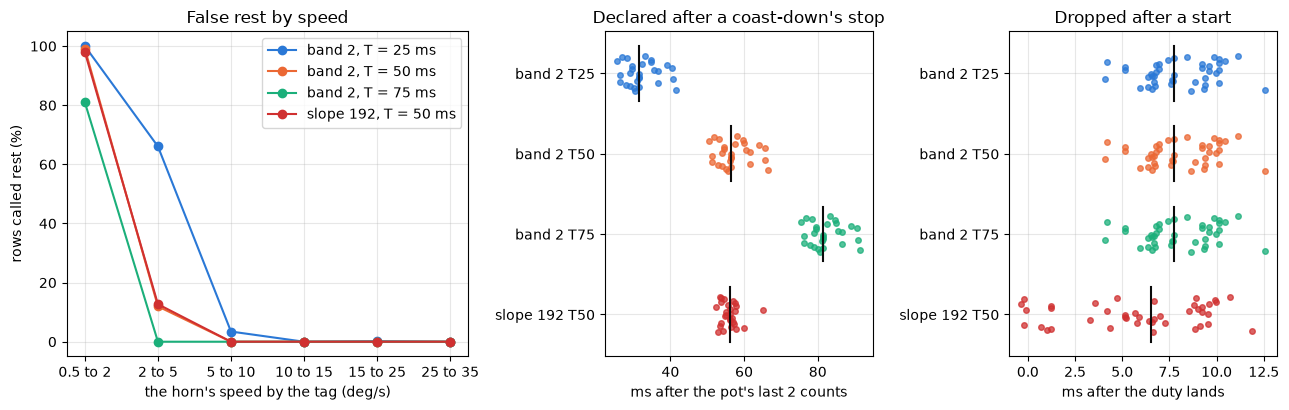

In [87]:
cands = (("band 2 T25", BLUE), ("band 2 T50", ORANGE), ("band 2 T75", GREEN),
         ("slope 192 T50", RED))
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2),
                       gridspec_kw=dict(width_ratios=[1.5, 1, 1]))
bins = REST_SPEED[["lo", "hi"]].drop_duplicates().sort_values("lo").head(6)
x = np.arange(len(bins))
for name, col in cands:
    d = REST_SPEED[(REST_SPEED.cand == name) & (REST_SPEED.side == "all")]
    d = d.set_index("lo").reindex(bins.lo)
    ax[0].plot(x, 100 * d.false_rest.to_numpy(), "-o", color=col, ms=6,
               label=name.replace(" T", ", T = ") + " ms")
ax[0].set_xticks(x, [f"{a:g} to {b:g}" for a, b in bins.to_numpy()])
figures.label(ax[0], "the horn's speed by the tag (deg/s)",
              "rows called rest (%)", "False rest by speed")
ax[0].legend(loc="upper right")
for a, (what, lab, col_, title, xl) in zip(ax[1:], (
        ("stop", "coast", "d_pot", "Declared after a coast-down's stop",
         "ms after the pot's last 2 counts"),
        ("start", None, "d_duty", "Dropped after a start",
         "ms after the duty lands"))):
    d = REST_EVENTS[REST_EVENTS.what == what]
    d = d[d.label == lab] if lab else d
    for i, (name, col) in enumerate(cands):
        v = d[d.cand == name][col_].dropna().to_numpy()
        a.plot(v, i + np.linspace(-0.22, 0.22, len(v)), "o", color=col,
               ms=4, alpha=0.75)
        a.plot([np.median(v)] * 2, [i - 0.34, i + 0.34], color=INK, lw=1.5)
    a.set_yticks(range(len(cands)), [c for c, _ in cands])
    a.invert_yaxis()
    figures.label(a, xl, None, title)
figures.finish(fig)

The slowest motion either form tells from rest is the band (or the slope's threshold times the window, about the same) over the scale and the hold time, b / (scale x T), far from a carry, and (b + run) / (scale x T) on a carry, where the run is the longest missing run, 12 counts here. The pot gives one count per 0.05 deg and the carries hide up to 0.6 deg. The back-EMF does not help there, since under 15 deg/s it is usable on under half of the rows and its stopped-rotor scatter is as large as the speed in question.

In [88]:
RUN_MAX = max(CARRY_MISSING)            # counts, the longest missing run
SCALE = LOOKUP.scale()                  # counts/deg
REST_MIN_SPEED = {T: {"far_from_carry": 2 / (SCALE * T / 1e3),
                      "on_widest_carry": (2 + RUN_MAX) / (SCALE * T / 1e3)}
                  for T in (50, 75, 150)}
for T, v in REST_MIN_SPEED.items():
    print(f"band 2, T = {T} ms: told from rest from "
          f"{v['far_from_carry']:.1f} deg/s far from a carry, "
          f"{v['on_widest_carry']:.1f} on the widest one ({RUN_MAX} counts)")
print(f"one count = {LSB_DEG:.4f} deg; the widest run "
      f"{RUN_MAX * LSB_DEG:.2f} deg")

band 2, T = 50 ms: told from rest from 2.0 deg/s far from a carry, 14.1 on the widest one (12 counts)
band 2, T = 75 ms: told from rest from 1.3 deg/s far from a carry, 9.4 on the widest one (12 counts)
band 2, T = 150 ms: told from rest from 0.7 deg/s far from a carry, 4.7 on the widest one (12 counts)
one count = 0.0504 deg; the widest run 0.61 deg


For the band of 2 counts at T = 50 ms the slowest motion told from rest is 2.0 deg/s far from a carry and 14.1 deg/s on the widest carry, 9.4 at 75 ms and 4.7 at 150 ms. The measured zero false rest from 10 deg/s at 50 ms and from 5 deg/s at 75 ms sits between the two bounds, since a crawl spends most of its rows far from a carry. A horn under 2 deg/s is rest to the verdict at any T tried. A driven sweep at 2 to 10 deg/s would settle the slow bins, which this sitting holds only as coast-down tails.

### What section 6 hands on

The rest verdict's keys of the result file. The table of every candidate goes to the `.rest.csv` file beside it.

In [89]:
q, pm = results.quantity, results.pm
T6 = REST_CANDS_T.set_index("cand")
tm = lambda c, col: float(T6.loc[c, col])                   # noqa: E731
R_S6 = {
    "rest_sigma16_counts": q(nz["sigma16"], nz["sigma16_lo"],
                             nz["sigma16_hi"], "counts, median [range] "
                             "over the baselines"),
    "rest_sigma_row_counts": q(nz["sigma_row"], unit="counts"),
    "rest_slope_sd_counts_s": {str(n): q(v, unit="counts/s")
                               for n, v in nz["slope_sd_counts_s"].items()},
    "rest_verdict": {
        "slope": {"rows": 192, "box_rows": 16, "threshold_x_own_sd": REST_K_S,
                  "threshold_deg_s": q(nz["slope_thr_deg_s"][192],
                                       unit="deg/s"), "hold_ms": 50},
        "band": {"counts": 2, "box_rows": 16,
                 "sigma16": q(2 / nz["sigma16"], unit="sigma16"),
                 "hold_ms": 50},
        "note": "equal alternatives"},
    "rest_hold_rule": "T at least the longest carry dwell at the slowest "
                      "speed to tell from rest: the longest missing run "
                      "over the scale and that speed",
    "rest_longest_missing_run_counts": q(RUN_MAX, unit="counts"),
    "rest_false_rest_10_35_deg_s": {
        f"{c} {t}": q(tm(f"{c} T{t}", "fr_crawl10_35_all"),
                      unit="share of rows")
        for c in ("band 2", "slope 192") for t in (25, 50)},
    "rest_false_rest_10_35_near_carry": {
        f"{c} {t}": q(tm(f"{c} T{t}", "fr_crawl10_35_near"),
                      unit="share of rows")
        for c in ("band 2", "slope 192") for t in (25, 50)},
    "rest_false_rest_rows_10_35": q(n_cr, unit="rows"),
}
print(len(R_S6), "keys so far")

9 keys so far


In [90]:
def times(c, col):
    return q(tm(c, col + "_med"), unit="ms, median"), q(
        tm(c, col + "_p90"), unit="ms, p90")


R_S6["rest_min_speed_deg_s"] = {
    f"{T} ms": {**{k: q(v, unit="deg/s") for k, v in d.items()},
                "measured_zero_false_rest_from": q(
                    {50: 10, 75: 5, 150: np.nan}[T], unit="deg/s")}
    for T, d in REST_MIN_SPEED.items()}
R_S6["rest_declare_ms"] = {
    c: {"coast_down": dict(zip(("median", "p90"),
                               times(c, "stop_coast_d_pot"))),
        "stall_in_hold": dict(zip(("median", "p90"),
                                  times(c, "stop_hold_d_pot")))}
    for c in ("band 2 T50", "slope 192 T50")}
R_S6["rest_drop_ms"] = {
    c: dict(zip(("median", "p90"), times(c, "start_d_duty")))
    for c in ("band 2 T50", "slope 192 T50", "band 2 T50 + emf",
              "slope 192 T50 + emf")}
R_S6["rest_false_motion_share"] = {
    c: {k: q(tm(c, f"fm_{k}"), unit="share of rows")
        for k in ("rest_base", "rest_coast", "stall72", "stall84",
                  "stall_hi")}
    for c in ("band 2 T50", "slope 192 T50", "band 1 T50", "slope 992 T75")}
print(len(R_S6), "keys so far")

13 keys so far


In [91]:
st3 = g3.pivot(index="cand", columns="set", values="fm") / 100
R_S6["rest_false_motion_stage3_share"] = {
    c: {s: q(st3.loc[c, s], unit="share of rows") for s in st3.columns}
    for c in ("band 2 T50", "slope 192 T50", "band 1 T50")}
R_S6["rest_veto"] = {
    "boxcar_rows": REST_N_VETO, "margin_x_sd": REST_K_V,
    "line_a_rev_s": pm(STALL_LINES["tab"]["a"], STALL_LINES["tab"]["a_se"],
                       "rev/s, +/- se"),
    "line_b_rev_s_per_a": pm(STALL_LINES["tab"]["b"],
                             STALL_LINES["tab"]["b_se"], "rev/s per A"),
    "margin_rev_s": q(REST_K_V * STALL["resid_sd_rev_s"], unit="rev/s"),
    "fires_on_stopped": f"{len(lo_w)} of {int((one.usable > 0).sum())}",
    "fires_share_by_speed": {
        f"{r.lo:g}-{r.hi:g}": q(r.veto_3sd / max(r.rows, 1),
                                unit="share of moving rows")
        for r in REST_VETO.itertuples()}}
print(len(R_S6), "keys")

15 keys


In [92]:
REST_CSV = REST_CANDS_T.merge(
    REST_SPEED.pivot_table(index="cand", columns=["side", "lo"],
                           values="false_rest")
    .set_axis([f"fr_{s}_{lo:g}" for s, lo in REST_SPEED.pivot_table(
        index="cand", columns=["side", "lo"], values="false_rest").columns],
        axis=1).reset_index(), on="cand")
print(f"rest candidates table: {len(REST_CSV)} rows, "
      f"{REST_CSV.shape[1]} columns")

rest candidates table: 43 rows, 104 columns


## 7. One velocity from two sources

A loop reads one velocity per row. Sections 4 and 5 say the back-EMF is the better source wherever it is valid at the delays a loop can afford, and the pot's slope is the only source under the taps' floor and with the drive off. Four ways of making one velocity of the two are graded here side by side, each at two pot delays. None is chosen.

| candidate | the rows it reads | the state it keeps |
|---|---|---|
| pot5, pot25: the pot's slope alone | two boxcars of 16 rows, 192 rows apart (5.2 ms of delay) or 992 apart (25.2 ms) | the slope's rows |
| sw: the switch | the back-EMF through a boxcar of 32 rows where 32 usable rows stand, the pot's slope elsewhere | both sources' rows |
| swr: the switch with the rest verdict | sw, zero while section 6's slope verdict (192 rows, 50 ms) is set | sw's and the verdict's count |
| swv: the same with the vetoed verdict | sw, zero while the verdict with the back-EMF's veto is set | swr's and the veto's boxcar |
| cp: the complementary pair | the back-EMF plus a one-pole of the pot's slope less the back-EMF through the pot's own kernel, cleared whenever the back-EMF stops carrying | both sources' rows, the one-pole and a running sum of the back-EMF |
| cpr: the pair with the rest verdict on pot rows | cp where the back-EMF carries, the pot's slope elsewhere, zero on pot rows while the verdict is set | cp's and the verdict's count |

The pair's corner is section 5's crossover at a crawl, the window from which the pot's two-point slope reads a lower rms than the table form's boxcar, taken as the one-pole's time constant in rows. Below the corner the pair reads the pot's slope, above it the back-EMF. Its weights are fixed, nothing is learned, and no constant of the back-EMF path moves. The back-EMF here is the table form, signed by the duty, its dropout rows holding the last usable value.

The rows a hole lost carry the pot on a line. The back-EMF runs on a line across a hole where it is usable on both sides, and a hole is not a start. The start-up counts from the series' first driven row and from a flip of the duty's sign only. So a kick's end or a step over the taps' floor is one back-EMF run, as a servo with no holes in its stream would have it.

In [93]:
BL_N_EMF = 32           # rows, the back-EMF's boxcar in the blends
BL_POT_N = {"5": 192, "25": 992}        # rows apart, the pot's two boxcars
BL_REST_MS, BL_REST_N = 50, 192         # the slope verdict of section 6
BL_TILE = 4000          # rows, a steady tile (200 ms)
BL_MOVING = 10.0        # deg/s by the tag, a moving tile
BL_TAU = float(XOVER[(XOVER.band == "crawl 15-35")
                     & (XOVER.pot == "pot_two") & (XOVER.emf == "emf_tab")
                     & (XOVER.stat == "rms")
                     & (XOVER["align"] == "group")].delay_rows.iloc[0])
BL_CANDS = [f"{c}{d}" for d in BL_POT_N
            for c in ("pot", "sw", "swr", "swv", "cp", "cpr")] + ["emf"]
BL_THR = REST_K_S * REST_NOISE["slope_sd_counts_s"][BL_REST_N]
BL_T_REST = max(int(BL_REST_MS * FS / 1e3) - (BL_REST_N + 16), 1)
print(f"corner tau {BL_TAU:.0f} rows ({BL_TAU / FS * 1e3:.1f} ms), back-EMF "
      f"boxcar {BL_N_EMF} rows, pot slope n {BL_POT_N}, rest verdict slope "
      f"{BL_REST_N} rows held to {BL_REST_MS} ms")


@njit(cache=False)
def started_rows(drive, fill, n_hold):
    """Past the start-up: n_hold rows after a first driven row and after a
    flip of the duty's sign; a filled row is not a start."""
    n = len(drive)
    out = np.zeros(n, np.bool_)
    cnt, last = -1, 0.0
    for t in range(n):
        if fill[t]:
            continue
        d = drive[t]
        if d == 0:
            cnt, last = -1, 0.0
            continue
        cnt = 0 if (cnt < 0 or d != last) else cnt + 1
        last = d
        out[t] = cnt >= n_hold
    return out

corner tau 1030 rows (51.5 ms), back-EMF boxcar 32 rows, pot slope n {'5': 192, '25': 992}, rest verdict slope 192 rows held to 50 ms


In [94]:
def bridge(w, usable, fill):
    """The back-EMF on a line across each hole usable on both sides."""
    w, usable = w.copy(), usable.copy()
    edges = np.flatnonzero(np.diff(fill.astype(int)) == 1) + 1
    for f0 in edges:
        f1 = (f0 + int(np.argmax(~fill[f0:])) if (~fill[f0:]).any()
              else len(fill))
        if f1 >= len(fill) or not (usable[f0 - 1] and usable[f1]):
            continue
        a = max(f0 - 16, 0)
        w0 = np.nanmean(w[a:f0][usable[a:f0]])
        w1 = np.nanmean(w[f1:f1 + 4][usable[f1:f1 + 4]])
        m = f1 - f0
        w[f0:f1] = w0 + (np.arange(1, m + 1) / (m + 1)) * (w1 - w0)
        usable[f0:f1] = True
    return w, usable


def tag_kernel(tag, n):
    """The pot's kernel on the tag (deg/s); NaN where a row of its n + 16
    has no tag."""
    bad = ~np.isfinite(tag)
    v = velocity.two_box(np.where(bad, 0.0, tag), 16, n, FS)
    c = np.cumsum(np.r_[0, bad.astype(int)])
    i = np.arange(1, len(tag) + 1)
    v[(c[i] - c[np.maximum(i - (n + 16), 0)]) > 0] = np.nan
    return v

In [95]:
def bl_emf(g, pad):
    """(the back-EMF in the pot's sign and usable, padded; v_on): the
    flags of the chain's run, the start-up through the holes."""
    E = EMF[(g["clip"], g["k"])]
    src = g["src"]
    ok = src >= 0
    n0 = len(src)
    tap_ok, drop, v_on = np.zeros(n0, bool), np.zeros(n0, bool), np.full(
        n0, np.nan)
    tap_ok[ok], drop[ok], v_on[ok] = (E["tap_ok"][src[ok]],
                                      E["drop"][src[ok]], E["v_on"][src[ok]])
    started = started_rows(np.ascontiguousarray(g["drive"], np.float64),
                           np.ascontiguousarray(g["fill"], np.bool_),
                           N_START)
    w, usable = velocity.emf_signed(g["w_tab"], g["drive"], tap_ok, started,
                                    drop)
    w, usable = bridge(w, usable, g["fill"])
    return (np.r_[np.full(pad, np.nan), w], np.r_[np.zeros(pad, bool), usable],
            v_on)

In [96]:
def bl_series(clip, k, segs):
    """One series with every candidate's output (rev/s) and source code
    (0 pot, 1 back-EMF, 2 pair, 3 rest) per row."""
    g = group_of(clip, k, segs)
    pad = REST_PAD if segs != [0] else 0
    degp = np.r_[np.full(pad, deg_of(g["pos"])[:16].mean()), deg_of(g["pos"])]
    posp = np.r_[np.full(pad, g["pos"][:16].mean()), g["pos"]]
    w, usable, v_on = bl_emf(g, pad)
    v_e, carry = velocity.emf_boxcar(w, usable, BL_N_EMF)
    slope_c = velocity.two_box(posp, 16, BL_REST_N, FS)
    rest = velocity.rest_slope(slope_c, BL_THR, BL_T_REST, None, segs != [0])
    zp = np.zeros(pad)
    veto = velocity.emf_turning(
        v_e * np.r_[zp, g["drive"]], carry, np.r_[zp, g["i_w"]],
        STALL["a_rev_s"], STALL["b_rev_s_per_a"],
        REST_K_V * STALL["resid_sd_rev_s"])
    rest_v = velocity.rest_slope(slope_c, BL_THR, BL_T_REST, veto,
                                 segs != [0])
    R = dict(pad=pad, n=len(degp), g=g, rest=rest, carry=carry,
             usable=usable, y={}, src={}, ktag={}, deg=degp,
             tag=np.r_[np.full(pad, np.nan), g["tag"]],
             fill=np.r_[np.zeros(pad, bool), g["fill"]],
             duty=np.r_[zp, g["duty"]], seg=np.r_[np.full(pad, -1), g["seg"]],
             v_on=np.r_[np.full(pad, np.nan), v_on])
    R["y"]["emf"] = np.where(carry, v_e, np.nan)
    R["src"]["emf"] = carry.astype(np.int8)
    for d, n in BL_POT_N.items():
        bl_candidates(R, d, n, v_e, w, rest, rest_v)
    return R

In [97]:
def bl_candidates(R, d, n, v_e, w, rest, rest_v):
    """The candidates at one pot delay, into R's outputs and sources."""
    y, src, carry = R["y"], R["src"], R["carry"]
    v_p = velocity.two_box(R["deg"], 16, n, FS) / K      # rev/s
    R["ktag"][d] = tag_kernel(R["tag"], n) / K
    y["pot" + d], src["pot" + d] = v_p, np.zeros(len(v_p), np.int8)
    ys, ss = velocity.switch(v_p, v_e, carry)
    y["sw" + d], src["sw" + d] = ys, ss
    y["swr" + d] = velocity.with_rest(ys, rest)
    src["swr" + d] = np.where(rest, 3, ss).astype(np.int8)
    y["swv" + d] = velocity.with_rest(ys, rest_v)
    src["swv" + d] = np.where(rest_v, 3, ss).astype(np.int8)
    s_e, good = velocity.emf_through_slope(w, R["usable"], 16, n, FS)
    yc, sc = velocity.complementary(v_p, v_e, s_e, carry, good, BL_TAU)
    y["cp" + d], src["cp" + d] = yc, sc
    pr = rest & (sc == 0)               # the verdict on pot rows only
    y["cpr" + d] = velocity.with_rest(yc, pr)
    src["cpr" + d] = np.where(pr, 3, sc).astype(np.int8)

### Grading

On steady rows each candidate's error is its output less the pot's kernel on the tag at the same n, per 200 ms tile. The grades are the bias (se over segments), the sd about the tile's mean, which holds the tag's own noise, the candidate's own sd about the tile's line, which is free of the tag, and the tile's mean less the ripple tach of section 4's tile. On rest and stall rows the truth is zero and the output itself is the error. On a transient the delay is the shift of the tag's centered speed that fits best, less the pot's centered slope's best shift on the same transient (section 2's method), and a seam is the output's jump on a row where the carrying source changes.

In [98]:
def bl_band(kind, duty):
    """The steady band of a segment of a clip `kind`."""
    if duty == 240:
        return "pass 100 deg/s"
    if kind == "steps":
        return "steps clip"
    if kind == "reversal":
        return "reversal clip slow"
    return "crawl under the floor" if duty < FLOOR else "crawl"


def detrend_sd(x):
    """The sd of x about its own line."""
    j = np.arange(len(x)) - (len(x) - 1) / 2
    return float((x - np.polyval(np.polyfit(j, x, 1), j)).std())


def bl_rest_rec(cls, cnd, g, s, y, rows=None, mean=None):
    """One rest or stall record of a candidate: rows, mean, sd, worst."""
    fin = np.isfinite(y).any()
    return dict(cls=cls, cand=cnd, clip=g["clip"], k=g["k"], seg=s,
                rows=int(np.isfinite(y).sum()) if rows is None else rows,
                mean=(float(np.nanmean(y)) if fin else np.nan)
                if mean is None else mean,
                sd=float(np.nanstd(y)) if fin else np.nan,
                absmax=float(np.nanmax(np.abs(y))) if fin else np.nan)

In [99]:
def bl_rest_segment(R, r, st, en, rest_recs):
    """A baseline (past its first 200 ms) or a still coast tail (from
    150 ms in): every candidate's output on rows whose truth is zero."""
    g = R["g"]
    if r.label == "baseline":
        sl = slice(st + 4000, en)
        for cnd in BL_CANDS:
            rest_recs.append(bl_rest_rec("torque off", cnd, g, r.seg,
                                         R["y"][cnd][sl]))
        return
    sl = slice(st + 3000, en)
    if not (np.nanmax(R["tag"][sl]) - np.nanmin(R["tag"][sl]) < 0.2):
        return                          # the coast had not stopped
    for cnd in BL_CANDS:
        y = R["y"][cnd][sl]
        if np.isfinite(y).sum() >= 100:
            rest_recs.append(bl_rest_rec("coast tail", cnd, g, r.seg, y))


def bl_stall_tile(R, r, a, b, st, rest_recs):
    """A tile of a stalled hold (the tag still over it, 1 s in)."""
    tag = R["tag"]
    if not (np.nanmax(tag[a:b]) - np.nanmin(tag[a:b]) < 0.06
            and a - st > 20000):
        return
    side = "under" if r.duty_ticks < FLOOR else "over"
    for cnd in BL_CANDS:
        y = R["y"][cnd][a:b]
        if np.isfinite(y).sum() >= BL_TILE // 2:
            rest_recs.append(bl_rest_rec(
                f"stall {side} the floor", cnd, R["g"], r.seg, y,
                rows=BL_TILE, mean=float(np.nanmean(y)) * r.drive))

In [100]:
def bl_steady(R, tach, recs, rest_recs):
    """Every candidate's steady tiles, rest rows and stall tiles."""
    g, pad, tag = R["g"], R["pad"], R["tag"]
    info = {r.seg: r for r in SEGS[(SEGS["clip"] == g["clip"])
                                   & (SEGS.k == g["k"])].itertuples()}
    kind = potframes.kind_of(g["clip"])
    for j, s in enumerate(g["segs"]):
        r = info[s]
        st = g["starts"][j] + pad
        en = (g["starts"][j + 1] + pad) if j + 1 < len(g["segs"]) else R["n"]
        if r.label in ("baseline", "coast"):
            bl_rest_segment(R, r, st, en, rest_recs)
            continue
        if not (r.steady1 > r.steady0):
            continue
        w0, w1 = st + (r.steady0 - r.a), st + (r.steady1 - r.a)
        for a in range(w0, w1 - BL_TILE + 1, BL_TILE):
            b = a + BL_TILE
            if not (np.isfinite(tag[a]) and np.isfinite(tag[b - 1])):
                continue
            v_tag = (tag[b - 1] - tag[a]) / ((BL_TILE - 1) / FS)
            if abs(v_tag) < BL_MOVING:
                bl_stall_tile(R, r, a, b, st, rest_recs)
                continue
            t = tach.get((g["clip"], g["k"], s, a - st), np.nan)
            base = dict(clip=g["clip"], k=g["k"], seg=s, a=a - st,
                        drive=r.drive, duty=r.duty_ticks, w_tag=v_tag / K)
            recs += bl_tile(R, a, b, base, bl_band(kind, r.duty_ticks),
                            v_tag, t)

In [101]:
def bl_tile(R, a, b, base, band, v_tag, t):
    """One steady tile: each candidate's bias, sd, own sd and tach error."""
    out = []
    for cnd in BL_CANDS:
        y = R["y"][cnd][a:b]
        d = cnd[-2:].lstrip("wrptv") if cnd != "emf" else "5"
        e = y - R["ktag"][d][a:b]       # less the pot's kernel on the tag
        if np.isfinite(e).sum() < BL_TILE * 0.9:
            continue
        ssrc = R["src"][cnd][a:b]
        out.append(dict(
            base, cand=cnd, band=band,
            bias=float(np.nanmean(e)) * np.sign(v_tag),
            sd=float(np.nanstd(e)), own_sd=detrend_sd(y[np.isfinite(y)]),
            e_tach=((float(np.nanmean(y)) * np.sign(v_tag) - t)
                    if np.isfinite(t) else np.nan),
            emf_share=float((ssrc >= 1).mean()), mean=float(np.nanmean(y))))
    return out

In [102]:
BL_DIRECT = []                          # the camera's own duty steps


def bl_todo(R, info, kind):
    """The transients of a series: (what, first row, r0, r1, segment)."""
    g, starts = R["g"], [s + R["pad"] for s in R["g"]["starts"]]
    segs = g["segs"]
    lab0 = info[segs[0]].label
    todo = [("kick" if lab0 == "kick" else "pass start", starts[0], 0, 3000,
             segs[0])]
    if len(starts) > 1 and lab0 == "kick":
        nxt = info[segs[1]]
        todo.append(("kick end, hold over the floor"
                     if nxt.duty_ticks >= FLOOR else
                     "kick end, hold under the floor", starts[1], -1000,
                     5000, segs[1]))
    if len(starts) > 2:
        lab = info[segs[2]].label
        if kind == "steps":
            todo.append(("step", starts[2], -2000, 6000, segs[2]))
        elif lab == "reversal":
            todo.append(("reversal", starts[2], -1000, 8000, segs[2]))
        elif lab == "coast":
            todo.append(("coast", starts[2], -1000, 3000, segs[2]))
    if kind == "pass" and len(starts) > 1:
        todo.append(("coast", starts[1], -1000, 3000, segs[1]))
    return todo

In [103]:
def bl_direct(R, what, a0, seg):
    """At a duty change after a hole: each candidate less its level before
    the hole, in the speed's sign, over rows 0-3, 4-9, 10-39, 40-99 after
    the duty lands; the volts' step / Ke beside it."""
    duty, g = R["duty"], R["g"]
    ch = np.flatnonzero(duty[a0:a0 + 40] != duty[a0])
    fills = np.flatnonzero(R["fill"][a0 - 400:a0])
    if not (len(ch) and len(fills)):
        return
    k0, f0 = a0 + ch[0], a0 - 400 + fills[0]
    v_on = np.nanmean(R["v_on"][f0 - 200:f0])
    dv = (abs(duty[k0]) - abs(duty[a0])) / CH.half_period_ticks * v_on
    if np.sign(duty[k0]) * np.sign(duty[a0]) < 0:
        dv = -(abs(duty[k0]) + abs(duty[a0])) / CH.half_period_ticks * v_on
    for cnd in BL_CANDS:
        y = R["y"][cnd]
        pre = np.nanmean(y[f0 - 200:f0])
        sg = np.sign(pre) if np.isfinite(pre) and pre != 0 else 1.0
        BL_DIRECT.append(dict(
            what=what, clip=g["clip"], k=g["k"], seg=seg, cand=cnd,
            dv_over_ke=dv / KE, pre=pre * sg, rows_after_hole=int(ch[0]),
            **{lab: float(np.nanmean(y[k0 + a:k0 + b]) - pre) * sg
               for lab, (a, b) in (("r0_3", (0, 4)), ("r4_9", (4, 10)),
                                   ("r10_39", (10, 40)),
                                   ("r40_99", (40, 100)))}))

In [104]:
def bl_transients(R, recs, seam_recs):
    """Every candidate's delay, rms and seams on each transient."""
    g, pad = R["g"], R["pad"]
    if g["segs"] == [0]:
        return
    info = {r.seg: r for r in SEGS[(SEGS["clip"] == g["clip"])
                                   & (SEGS.k == g["k"])].itertuples()}
    cam = np.r_[g["cam"][0] - np.arange(pad, 0, -1) / FS, g["cam"]]
    tf, vf = TAG_SPEED[g["clip"]]
    t_rest = cam[pad]

    def truth_at(t):
        out = np.interp(t, tf, vf, left=np.nan, right=np.nan)
        return np.where(t < t_rest, 0.0, out)

    vc = centered_slope(R["deg"])
    todo = bl_todo(R, info, potframes.kind_of(g["clip"]))
    if not np.isfinite(cam[pad]):
        return
    for what, a0, r0, r1, seg in todo:
        rows = np.arange(a0 + r0, min(a0 + r1, R["n"]))
        if what not in ("kick", "pass start"):
            bl_direct(R, what, a0, seg)
        lag0, _ = best_lag(vc, truth_at, cam, rows, -400, 400)
        tr = truth_at(cam[rows])
        swing = float(np.nanmax(tr) - np.nanmin(tr))
        for cnd in BL_CANDS:
            rec = bl_lag(R, cnd, (what, seg), rows, a0, lag0, truth_at,
                         cam, seam_recs)
            recs.append(dict(rec, what=what, clip=g["clip"], k=g["k"],
                             seg=seg, cand=cnd, lag0=lag0, swing=swing))

In [105]:
def bl_lag(R, cnd, ev, rows, a0, lag0, truth_at, cam, seam_recs):
    """One candidate on one transient: its added delay and fit rms, its
    rms and worst row at the pot's own shift; its seams into seam_recs."""
    what, seg = ev
    y = R["y"][cnd] * K                 # deg/s
    srcs = R["src"][cnd]
    lag, rms = (np.nan, np.nan)
    if (np.isfinite(lag0) and what != "coast"
            and np.isfinite(y[rows]).mean() > 0.9):
        lag, rms = best_lag(y, truth_at, cam, rows, int(lag0) - 300,
                            int(lag0) + 900)
    tr0 = truth_at(cam[rows] - (lag0 if np.isfinite(lag0) else 0.0) / FS)
    e = y[rows] - tr0
    g = R["g"]
    r, jump, s_from, s_to = velocity.seams(R["y"][cnd], srcs)
    for rr, jj, sf_, st_ in zip(r, jump, s_from, s_to):
        if rows[0] <= rr <= rows[-1] and np.isfinite(jj):
            seam_recs.append(dict(
                what=what, clip=g["clip"], k=g["k"], seg=seg,
                cand=cnd, row=int(rr - a0), jump=float(jj),
                src_from=int(sf_), src_to=int(st_),
                truth=float(truth_at(cam[rr]) / K) if np.isfinite(cam[rr])
                else np.nan))
    return dict(added=lag - lag0 if np.isfinite(lag) else np.nan,
                rms_fit=rms, rms_now=float(np.sqrt(np.nanmean(e ** 2))),
                worst=float(np.nanmax(np.abs(e))),
                emf_share=float((srcs[rows] == 1).mean()
                                + (srcs[rows] == 2).mean()))

In [106]:
def bl_shares(R, acc):
    """Rows by source and condition (torque off, coast, driven under and
    over the floor), the stream's own rows only."""
    g, pad = R["g"], R["pad"]
    real = ~R["fill"]
    real[:pad] = False
    duty = np.abs(R["duty"])
    cond = np.where(
        ~np.r_[np.zeros(pad, bool), g["torque_on"]], "torque off",
        np.where(duty == 0, "coast",
                 np.where(duty < FLOOR, "driven under the floor",
                          "driven over the floor")))
    for cnd in BL_CANDS:
        s = R["src"][cnd]
        for cn in np.unique(cond[real]):
            m = real & (cond == cn)
            for code in (0, 1, 2, 3):
                key = (cnd, cn, code)
                acc[key] = acc.get(key, 0) + int((m & (s == code)).sum())


tach = {(r.clip, r.k, r.seg, r.a): r.tach for r in Q2_TILES.itertuples()}
recs, rest_recs, tr_recs, seam_recs, acc = [], [], [], [], {}
for clip, k, segs in GROUPS:
    R = bl_series(clip, k, segs)
    bl_steady(R, tach, recs, rest_recs)
    bl_transients(R, tr_recs, seam_recs)
    bl_shares(R, acc)
BL_TILES = pd.DataFrame(recs)
BL_TILES["segid"] = (BL_TILES["clip"] + "/" + BL_TILES.k.astype(str) + "/"
                     + BL_TILES.seg.astype(str))
print(f"{len(BL_TILES)} steady tile records, {len(rest_recs)} rest records, "
      f"{len(tr_recs)} transient records, {len(seam_recs)} seams")

1887 steady tile records, 780 rest records, 1586 transient records, 1256 seams


In [107]:
def bl_steady_agg(d):
    """Bias (se over segments), sd, own sd and tach error of a band."""
    sm = d.groupby("segid").bias.mean()
    tm = d.groupby("segid").e_tach.mean().dropna()
    return pd.Series(dict(
        tiles=len(d), segs=len(sm), w_tag=d.w_tag.abs().mean(),
        bias=d.bias.mean(),
        bias_se=sm.std(ddof=1) / np.sqrt(len(sm)) if len(sm) > 1 else np.nan,
        sd=np.sqrt((d.sd ** 2).mean()), own_sd=np.sqrt((d.own_sd ** 2).mean()),
        e_tach=d.e_tach.mean(),
        e_tach_se=tm.std(ddof=1) / np.sqrt(len(tm)) if len(tm) > 1
        else np.nan, emf_share=d.emf_share.mean()))


BL_STEADY = BL_TILES.groupby(["band", "cand"]).apply(
    bl_steady_agg, include_groups=False).reset_index()
print("steady rows, rev/s (bias and sd against the pot's kernel on the tag;"
      " own_sd about the tile's line; e_tach against the ripple tach):")
for band, d in BL_STEADY.groupby("band"):
    print(f"  {band}: {int(d.tiles.max())} tiles, {int(d.segs.max())} "
          f"segments, {d.w_tag.mean():.1f} rev/s")
    print(d.set_index("cand").loc[[c for c in BL_CANDS if c in set(d.cand)],
                                  ["bias", "bias_se", "sd", "own_sd",
                                   "e_tach", "e_tach_se"]]
          .round(2).T.to_string())

steady rows, rev/s (bias and sd against the pot's kernel on the tag; own_sd about the tile's line; e_tach against the ripple tach):
  crawl: 79 tiles, 22 segments, 24.0 rev/s
cand       pot5   sw5  swr5  swv5   cp5  cpr5  pot25  sw25  swr25  swv25  cp25  cpr25   emf
bias       0.00  0.40  0.40  0.40  0.04  0.04  -0.03  0.39   0.39   0.39  0.06   0.06  0.40
bias_se    0.04  0.13  0.13  0.13  0.04  0.04   0.04  0.15   0.15   0.15  0.06   0.06  0.13
sd         8.18  5.62  5.62  5.62  5.65  5.65   3.59  4.73   4.73   4.73  4.69   4.69  5.62
own_sd     6.99  3.43  3.43  3.43  3.52  3.52   2.59  3.43   3.43   3.43  3.42   3.42  3.43
e_tach     0.17  0.57  0.57  0.57  0.21  0.21   0.16  0.57   0.57   0.57  0.24   0.24  0.57
e_tach_se  0.09  0.11  0.11  0.11  0.10  0.10   0.11  0.11   0.11   0.11  0.11   0.11  0.11
  crawl under the floor: 11 tiles, 4 segments, 11.9 rev/s
cand       pot5   sw5  swr5  swv5   cp5  cpr5  pot25  sw25  swr25  swv25  cp25  cpr25
bias      -0.19 -0.19 -0.19 -0.19 -0.

In [108]:
BL_REST = pd.DataFrame(rest_recs).groupby(["cls", "cand"]).agg(
    n=("rows", "size"), mean=("mean", "mean"), mean_sd=("mean", "std"),
    sd=("sd", lambda x: np.sqrt((x ** 2).mean())),
    absmax=("absmax", "max")).reset_index()
print("rest and stall rows (truth zero), rev/s: mean / sd / worst row")
for cls, d in BL_REST.groupby("cls"):
    d = d.set_index("cand")
    print(f"  {cls} (n {int(d.n.max())}): " + ", ".join(
        f"{c} {d.loc[c, 'mean']:+.2f} / {d.loc[c, 'sd']:.2f} / "
        f"{d.loc[c, 'absmax']:.1f}" for c in BL_CANDS
        if c in d.index and c[-2:] != "25"))
BL_SHARE = pd.DataFrame([dict(cand=c, cond=cn, src=code, rows=n)
                         for (c, cn, code), n in acc.items()])
tot = BL_SHARE[BL_SHARE.cand == "sw5"].rows.sum()
for cnd in ("sw5", "swr5", "swv5", "cp5", "cp25", "cpr5"):
    by = BL_SHARE[BL_SHARE.cand == cnd].groupby("src").rows.sum() / tot
    print(f"rows by source, {cnd} (pot / back-EMF / pair / rest): "
          + " / ".join(f"{by.get(i, 0):.1%}" for i in range(4))
          + f" of {tot} rows")
d = BL_SHARE[BL_SHARE.cand == "sw5"]
print("  sw5 by condition: " + "; ".join(
    f"{cn} {int(x.rows.sum())} rows, back-EMF "
    f"{x[x.src == 1].rows.sum() / x.rows.sum():.1%}"
    for cn, x in d.groupby("cond")))

rest and stall rows (truth zero), rev/s: mean / sd / worst row
  coast tail (n 34): pot5 +0.01 / 1.13 / 5.3, sw5 +0.01 / 1.13 / 5.3, swr5 +0.00 / 0.10 / 3.9, swv5 +0.00 / 0.10 / 3.9, cp5 +0.01 / 1.13 / 5.3, cpr5 +0.00 / 0.10 / 3.9
  stall over the floor (n 3): pot5 -0.00 / 0.89 / 3.5, sw5 +1.23 / 0.19 / 2.1, swr5 +0.00 / 0.00 / 0.0, swv5 +0.00 / 0.00 / 0.0, cp5 +0.02 / 0.20 / 0.6, cpr5 +0.02 / 0.20 / 0.6, emf +1.23 / 0.19 / 2.1
  stall under the floor (n 5): pot5 -0.00 / 1.16 / 5.2, sw5 -0.00 / 1.16 / 5.2, swr5 +0.00 / 0.00 / 0.0, swv5 +0.00 / 0.00 / 0.0, cp5 -0.00 / 1.16 / 5.2, cpr5 +0.00 / 0.00 / 0.0
  torque off (n 21): pot5 +0.00 / 1.17 / 7.2, sw5 +0.00 / 1.17 / 7.2, swr5 +0.00 / 0.00 / 0.0, swv5 +0.00 / 0.00 / 0.0, cp5 +0.00 / 1.17 / 7.2, cpr5 +0.00 / 0.00 / 0.0, emf +nan / nan / nan
rows by source, sw5 (pot / back-EMF / pair / rest): 38.1% / 61.9% / 0.0% / 0.0% of 1563800 rows
rows by source, swr5 (pot / back-EMF / pair / rest): 9.1% / 58.3% / 0.0% / 32.7% of 1563800 rows
rows by

In [109]:
D = pd.DataFrame(tr_recs)
BL_DELAY = D.groupby(["what", "cand"]).agg(
    n=("added", "count"), added=("added", "mean"),
    se=("added", lambda x: x.std(ddof=1) / np.sqrt(x.count())
        if x.count() > 1 else np.nan),
    rms_now=("rms_now", "mean"), worst=("worst", "median"),
    worst_max=("worst", "max"), swing=("swing", "median"),
    emf_share=("emf_share", "mean"), runs=("rms_now", "size")).reset_index()
show = ["pot5", "sw5", "swr5", "swv5", "cp5", "cpr5", "pot25", "sw25",
        "cp25", "emf"]
print("transients: added delay in rows (se), rms and worst row against the "
      "tag's speed (deg/s):")
for what, d in BL_DELAY.groupby("what"):
    d = d.set_index("cand")
    print(f"  {what} (n {int(d.runs.max())}, swing {d.swing.mean():.0f} "
          "deg/s)")
    print(d.loc[[c for c in show if c in d.index],
                ["n", "added", "se", "rms_now", "worst"]].round(1).T
          .to_string())

transients: added delay in rows (se), rms and worst row against the tag's speed (deg/s):
  coast (n 34, swing 32 deg/s)
cand     pot5   sw5  swr5  swv5   cp5  cpr5  pot25  sw25  cp25   emf
n         0.0   0.0   0.0   0.0   0.0   0.0    0.0   0.0   0.0   0.0
added     NaN   NaN   NaN   NaN   NaN   NaN    NaN   NaN   NaN   NaN
se        NaN   NaN   NaN   NaN   NaN   NaN    NaN   NaN   NaN   NaN
rms_now   5.8   4.9   4.7   4.7   4.9   4.7    7.1   7.3   7.3   5.6
worst    17.9  15.7  15.7  15.7  15.6  15.6   15.2  15.8  15.9  11.2
  kick (n 38, swing 151 deg/s)
cand     pot5   sw5  swr5  swv5   cp5  cpr5  pot25  sw25  cp25   emf
n        38.0  38.0  38.0  38.0  38.0  38.0   38.0  38.0  38.0  38.0
added    99.1 -16.6   3.4 -15.3 -14.9 -14.8  498.6 -16.6 -18.8 -26.4
se        1.7  10.7  10.1  10.9   9.3   9.3    5.0  10.7  10.7  10.7
rms_now  22.5  12.0  13.1  12.1  12.1  12.1   41.4  12.0  11.9  11.6
worst    52.3  39.8  45.3  40.4  38.9  38.8   88.9  39.8  39.1  37.6
  kick end, hold over

In [110]:
SM = pd.DataFrame(seam_recs)
SM["abs"] = SM.jump.abs()
names = {0: "pot", 1: "back-EMF", 2: "pair", 3: "rest"}
SM["kind"] = SM.src_from.map(names) + " > " + SM.src_to.map(names)
BL_SEAMS = SM.groupby(["cand", "what", "kind"]).agg(
    n=("abs", "size"), med=("abs", "median"),
    p90=("abs", lambda x: x.quantile(0.9)), mx=("abs", "max"),
    row=("row", "median"),
    truth=("truth", lambda x: x.abs().median())).reset_index()
print("seams: |jump| rev/s on the row the source changes (n, median, p90, "
      "max; median row after the transition; the tag's speed there):")
for cnd in ("sw5", "sw25", "swr5", "swv5", "cp5", "cp25", "cpr5"):
    d = BL_SEAMS[(BL_SEAMS.cand == cnd) & (BL_SEAMS.n >= 3)]
    print(f"  {cnd}")
    d = d.assign(ms=d.row / MS)
    print(d[["what", "kind", "n", "med", "p90", "mx", "row", "ms", "truth"]]
          .round(1).to_string(index=False))

seams: |jump| rev/s on the row the source changes (n, median, p90, max; median row after the transition; the tag's speed there):
  sw5
                          what           kind  n  med  p90   mx  row  ms  truth
                         coast back-EMF > pot 28  6.8 10.1 11.0  3.0 0.2   20.8
                          kick pot > back-EMF 38 13.5 18.0 21.2 52.0 2.6   18.4
kick end, hold under the floor back-EMF > pot  6 12.7 24.8 25.1  3.0 0.2  121.5
                    pass start pot > back-EMF  4  5.9 11.7 12.7 50.5 2.5   15.8
                      reversal back-EMF > pot  4  6.2 12.4 14.3  3.0 0.2   20.3
                      reversal pot > back-EMF  4 14.7 35.5 43.9 50.0 2.5   14.0
  sw25
                          what           kind  n  med  p90   mx  row  ms  truth
                         coast back-EMF > pot 28  2.7  6.8 11.4  3.0 0.2   20.8
                          kick pot > back-EMF 38 14.5 16.9 19.0 52.0 2.6   18.4
kick end, hold under the floor back-EMF > pot  6  3.2 11.2

### The duty step's direct path

A change of duty changes the terminal volts at once and the speed only through the rotor's inertia. The back-EMF estimate reads the volts' step minus the R i term, so for a few rows after a duty change it carries part of the volts' step over Ke that is not motion. The camera sitting's own steps sit on its holes, so the path is read on stage 3's duty steps of `steps/capture-1`, where the stream runs through the step and the ripple tach's fitted first-order response is the truth. Each candidate's error after the duty changes is read in the step's own sign, as a share of the volts' step over Ke, over rows 0-3, 4-9, 10-39, 40-199 and 200-999.

In [111]:
def bl_step_outputs(E, w, usable, deg):
    """The back-EMF per row, its boxcar of 32 and each pair and pot slope
    on one duty step's rows."""
    v_e, carry = velocity.emf_boxcar(w, usable, BL_N_EMF)
    ys = {"emf row": w, "emf boxcar 32": v_e}
    for d, n in BL_POT_N.items():
        v_p = velocity.two_box(deg, 16, n, FS) / K
        s_e, good = velocity.emf_through_slope(w, usable, 16, n, FS)
        ys["cp" + d], _ = velocity.complementary(v_p, v_e, s_e, carry, good,
                                                 BL_TAU)
        ys["pot" + d] = v_p
    return ys


BL_WINS = (("r0_3", (0, 4)), ("r4_9", (4, 10)), ("r10_39", (10, 40)),
           ("r40_199", (40, 200)), ("r200_999", (200, 1000)))
T = windows.steps_truth(STORE, np.asarray(Z).astype(np.float32),
                        PAIR_W.folder, STEPS_DATASET, PAIR_W.per_rev)
BL_STEPS_T = T[windows.steps_kept(T)]
print(f"{len(T)} duty steps, {len(BL_STEPS_T)} kept")

85 duty steps, 60 kept


In [112]:
recs = []
for r in BL_STEPS_T.itertuples():
    g0, gs, g1 = int(r.run0), int(r.g_step), int(r.g1)
    lo = max(g0, gs - 6000)             # 300 ms before the step at most
    E = speed.emf_run(ARR, lo, g1, Z, ARR["duty_sign"],
                      float(NTC_SWEEP[r.sweep]), CH, MO, TAB, PROD, RULE)
    sgn = np.asarray(ARR["duty_sign"][lo:g1]).astype(float)
    started = E["started"] | (np.arange(len(sgn)) > 200)   # runs on
    w, usable = velocity.emf_signed(E["w_tab"], sgn, E["tap_ok"], started,
                                    E["drop"])
    ys = bl_step_outputs(E, w, usable, deg_of(ARR["pos"][lo:g1]))
    k0 = gs - lo                        # the row the duty changes
    tp = np.maximum((np.arange(len(w)) - k0) / FS, 0)
    truth = (r.w0 + r.dw * (1 - np.exp(-tp / (r.tau_ms / 1e3)))) * r.dir
    duty = ARR["duty"][lo:g1].astype(float)
    dv = ((np.median(duty[k0 + 5:k0 + 50]) - np.median(duty[k0 - 50:k0 - 5]))
          / CH.half_period_ticks * float(np.nanmean(E["v_on"][k0 - 200:k0])))
    for name, y in ys.items():
        e = (y - truth) * r.dir
        rec = dict(sweep=r.sweep, base_pct=r.base_pct, step_pct=r.step_pct,
                   sign=r.sign, dir=r.dir, cand=name, dv_over_ke=dv / KE,
                   dw=r.dw, tau_ms=r.tau_ms, hole=r.hole,
                   before=float(np.nanmean(e[k0 - 400:k0])))
        for lab, (a, b) in BL_WINS:
            rec[lab] = float(np.nanmean(e[k0 + a:k0 + b])) - rec["before"]
        recs.append(rec)
BL_STEPS = pd.DataFrame(recs)
n_steps = BL_STEPS.groupby(["sweep", "base_pct", "step_pct", "sign",
                            "dir"]).ngroups
print(f"{n_steps} kept steps, {len(BL_STEPS)} records")

60 kept steps, 360 records


In [113]:
cols = [lab for lab, _ in BL_WINS]
up = BL_STEPS.copy()
up[cols] = up[cols].mul(np.sign(up.dv_over_ke), axis=0)   # the step's sign
sh = up[cols].div(up.dv_over_ke.abs(), axis=0)            # share of dV / Ke
sh["cand"] = up.cand
BL_DIRECT_SHARE = sh.groupby("cand")[cols].agg(["mean", "sem"])
print("share of the volts' step / Ke after the duty changes, mean +/- se:")
for name in ("emf row", "emf boxcar 32", "cp5", "cp25", "pot5", "pot25"):
    m = BL_DIRECT_SHARE.loc[name]
    print(f"  {name:14s} " + ", ".join(
        f"{c} {m[(c, 'mean')]:+.3f} +/- {m[(c, 'sem')]:.3f}" for c in cols))
print(f"the volts' step / Ke {BL_STEPS.dv_over_ke.abs().min():.1f} to "
      f"{BL_STEPS.dv_over_ke.abs().max():.1f} rev/s; the speed's own step "
      f"{BL_STEPS.dw.abs().min():.1f} to {BL_STEPS.dw.abs().max():.1f} rev/s"
      f", tau {BL_STEPS.tau_ms.median():.0f} ms; holes "
      f"{BL_STEPS.hole.min():.0f} to {BL_STEPS.hole.max():.0f} ticks")
dsr = SPEED4["duty_step_response"]
print(f"the speed notebook's per-row shares over its own {dsr['n']} steps: "
      + ", ".join(f"{dsr[k]['value']:+.3f}" for k in (
          "share_rows_0_3", "share_rows_4_9", "share_rows_10_39")))

share of the volts' step / Ke after the duty changes, mean +/- se:
  emf row        r0_3 +0.788 +/- 0.047, r4_9 +0.265 +/- 0.049, r10_39 +0.071 +/- 0.014, r40_199 +0.019 +/- 0.023, r200_999 -0.063 +/- 0.036
  emf boxcar 32  r0_3 +0.059 +/- 0.015, r4_9 +0.108 +/- 0.020, r10_39 +0.117 +/- 0.014, r40_199 -0.004 +/- 0.022, r200_999 -0.071 +/- 0.036
  cp5            r0_3 +0.088 +/- 0.025, r4_9 +0.138 +/- 0.028, r10_39 +0.153 +/- 0.027, r40_199 +0.050 +/- 0.043, r200_999 +0.003 +/- 0.064
  cp25           r0_3 +0.092 +/- 0.030, r4_9 +0.141 +/- 0.033, r10_39 +0.154 +/- 0.032, r40_199 +0.046 +/- 0.043, r200_999 +0.025 +/- 0.083
  pot5           r0_3 +0.189 +/- 0.217, r4_9 +0.234 +/- 0.289, r10_39 +0.169 +/- 0.354, r40_199 -0.062 +/- 0.341, r200_999 -0.125 +/- 0.047
  pot25          r0_3 +0.065 +/- 0.043, r4_9 +0.064 +/- 0.059, r10_39 +0.009 +/- 0.071, r40_199 -0.222 +/- 0.064, r200_999 -0.389 +/- 0.062
the volts' step / Ke 13.4 to 67.3 rev/s; the speed's own step 8.8 to 78.6 rev/s, tau 18 ms; h

In [114]:
DR = pd.DataFrame(BL_DIRECT)
st = DR[(DR.what == "step") & (DR.cand == "emf")]
print("the camera's own duty steps (after a hole): the back-EMF's boxcar "
      "less its level before, rows 0-3, rev/s, by step:")
for r in st.itertuples():
    print(f"  {r.clip}/{r.k}/{r.seg}: volts' step / Ke {r.dv_over_ke:+.1f} "
          f"rev/s, rows 0-3 {r.r0_3:+.1f}, rows 4-9 {r.r4_9:+.1f}")
ke_end = DR[(DR.what == "kick end, hold over the floor")
            & (DR.cand == "emf")].dv_over_ke.median()
b32 = BL_DIRECT_SHARE.loc["emf boxcar 32", ("r10_39", "mean")]
print(f"kick ends: the volts' step / Ke {ke_end:+.1f} rev/s (median), so "
      f"{b32:.3f} of it through the boxcar is {abs(b32 * ke_end):.1f} rev/s;"
      f" the pair's back-EMF through the pot's kernel spans "
      f"{BL_POT_N['5'] + 16} rows")

the camera's own duty steps (after a hole): the back-EMF's boxcar less its level before, rows 0-3, rev/s, by step:
  steps/0/6: volts' step / Ke +6.8 rev/s, rows 0-3 +0.5, rows 4-9 +0.7
  steps/1/3: volts' step / Ke -6.8 rev/s, rows 0-3 +4.3, rows 4-9 +4.0
  steps/1/6: volts' step / Ke -6.8 rev/s, rows 0-3 +4.7, rows 4-9 +4.3
kick ends: the volts' step / Ke -141.3 rev/s (median), so 0.117 of it through the boxcar is 16.5 rev/s; the pair's back-EMF through the pot's kernel spans 208 rows


What the grades say. The numbers are motor rev/s against the tag through the pot's kernel, at a crawl of 24.0 rev/s over 79 tiles in 22 segments unless named.

- **The switch carries the back-EMF's bias into its output.** sw5 reads +0.40 +/- 0.13 rev/s at a crawl, +0.75 and +0.88 on the reversal and steps clips, and +1.23 on the camera's stall over the floor (3 tiles), where the truth is zero. Against the ripple tach the split is the same, sw5 +0.57 against pot5 +0.17. Moderate.
- **The pair reads the pot at DC.** cp5 reads +0.04 +/- 0.04 at a crawl, +0.03 and +0.04 on the reversal and steps clips and +0.02 at the stall over the floor. Below its 51.5 ms corner it is the pot's slope, so it carries the pot's own bias and wander there, and its delay below the corner is the pot slope's. Moderate.
- **Both keep the back-EMF's noise.** The own sd about the tile's line is 3.43 for sw5 and 3.52 for cp5 at a crawl against 6.99 for pot5 and 2.59 for pot25, and 2.19 and 2.47 on the pass (86.3 rev/s) against 12.50 and 3.01. cp5 and cp25 are not separated on steady bias, own sd or delay (every difference under 2 sigma). They differ only where the pot carries, under the floor (own sd 4.13 against 1.85 rev/s at 11.9 rev/s).
- **At rest every rest variant reads zero,** where pot5 has 1.17 rev/s of sd on the torque-off baselines (worst row 7.2) and 1.13 on the coast tails. The switch and the pair carry those rows as the pot's slope, since the back-EMF does not run there.
- **Shares of rows.** sw5 takes the back-EMF on 61.9 % of the sitting's 1563800 rows and the pot's slope on 38.1 %. Over the floor the back-EMF carries 99.8 % of the 970796 driven rows. With the rest verdict on top the verdict is set on 32.7 % (swr5), on pot rows only 29.0 % (cpr5). The pair's one-pole runs on 61.4 % of the rows (cp5).

- **Delays on transients.** The added delay is against the pot's centered slope on the same transient. On a kick's end with the hold over the floor (31 events) pot5 is 105.2 rows behind and pot25 498.8, and sw5 and cp5 lead by -83.5 and -68.9 rows. The leads are the back-EMF and the pot disagreeing for about 30 ms after a hard deceleration (section 9), so they are a property of the sensors, not of the blends. On a kick from rest (38 events) sw5 and cp5 read -16.6 and -14.9 rows, under 2 sigma. Under the floor every candidate is the pot's slope, 105 and 496 rows for the two delays.
- **Seams.** The switch's seam at a kick's start is 13.5 rev/s (median, p90 18.0) at row 52, 2.6 ms in, where the back-EMF's boxcar first stands on 32 usable rows while the pot's 5 ms slope still reads near zero. Any candidate that carries the back-EMF there has it. At a coast's start the switch jumps 6.8 rev/s from the back-EMF to the pot. The pair's seam where the one-pole takes over is 0.2 rev/s, and at a coast 5.4 (cp5) and 2.5 (cp25) rev/s. The rest verdict on top of the switch costs a seam of 44.7 rev/s at every start, 7.4 ms in, since the back-EMF already carries the kick's speed when the pot lets go of rest. With the veto it is 18.0 at 3.0 ms, and on pot rows only (cpr5) 14.4 at 2.6 ms, the switch's own seam.
- **The direct path from the duty passes through every candidate that carries the back-EMF.** Over stage 3's 60 kept duty steps the back-EMF per row carries +0.788, +0.265 and +0.071 of the volts' step over Ke in rows 0-3, 4-9 and 10-39, through the boxcar of 32 (the switch) +0.059, +0.108 and +0.117, gone by row 40, and through the pair +0.088, +0.138 and +0.153, with +0.050 left at rows 40-199. The pot's slope carries none, and pot25 lags the step (-0.222 at rows 40-199). On a kick's end the volts' step over Ke is -141 rev/s, a dip of about 16.5 rev/s for 2 ms in either blend. The `speed` notebook read the per-row shares as +0.751, +0.299 and +0.114 over its own 39 steps. The camera sitting's own three steps do not resolve the path. They read +0.5 rev/s for a +6.8 rev/s step and +4.3 and +4.7 for two -6.8 steps, under the commutation ripple the boxcar of 32 leaves (section 8).

**The choice stays open.** The switch reads the back-EMF's own DC, with its bias at a crawl and at a stall, and a seam of 7 to 14 rev/s wherever the source changes. The pair reads the pot at DC, costs one more state (the one-pole, and the back-EMF through the pot's kernel, a running sum of 208 rows), puts the pot slope's delay on everything below its 51.5 ms corner and has seams of 14 rev/s at a start and 5 at a coast. A loop design weighs the back-EMF's bias (section 4, and the stopped rotor of section 8) against the pot's delay below the corner, whether a caller wants the back-EMF's own DC, and how the loop takes a step of about 14 rev/s in its feedback at a start.

The figure follows one kick, hold and coast of the first crawl chain through the candidates. The gray line is the tag's speed through its 7-frame quadratic, which looks ahead. The panels are the start (the duty lands at 0), the kick's end and the coast to rest (the hole at 0).

crawl-0-0, chain 1, segments [1, 2, 3]


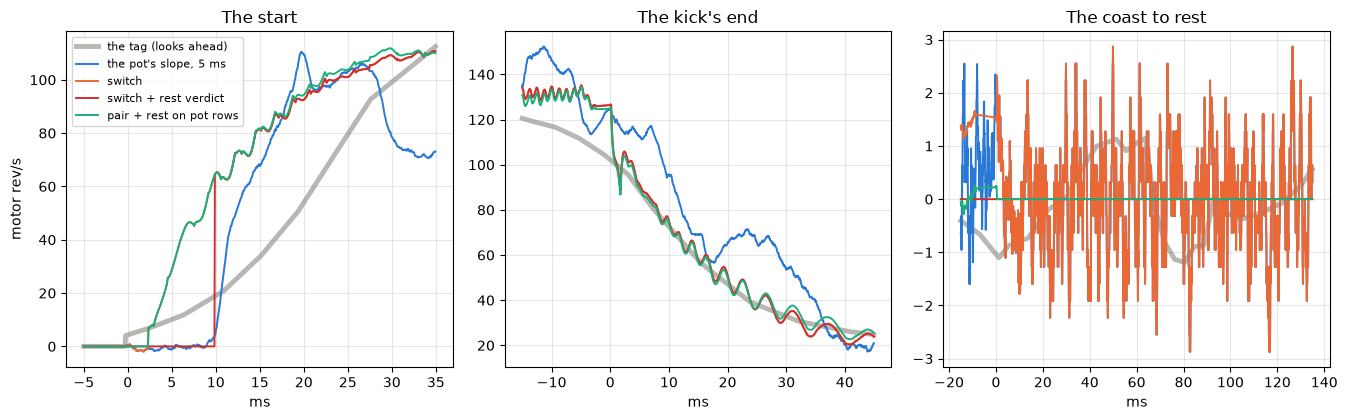

In [115]:
pick = next((clip, k, segs) for clip, k, segs in GROUPS if len(segs) == 3
            and potframes.kind_of(clip) == "crawl"
            and SEGS.set_index(["clip", "k", "seg"]).loc[
                (clip, k, segs[1]), "duty_ticks"] >= FLOOR)
R = bl_series(*pick)
g, pad = R["g"], R["pad"]
cam = np.r_[g["cam"][0] - np.arange(pad, 0, -1) / FS, g["cam"]]
tf, vf = TAG_SPEED[pick[0]]
tr = np.where(cam < cam[pad], 0.0,
              np.interp(cam, tf, vf, left=np.nan, right=np.nan)) / K
sgn = np.sign(np.nanmedian(tr[np.abs(tr) > 5]))
starts = [s + pad for s in g["starts"]]
land = starts[0] + int(np.flatnonzero(R["duty"][starts[0]:] != 0)[0])
fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.3))
for a, (r0, lo, hi, title) in zip(ax, (
        (land, -100, 700, "The start"), (starts[1], -300, 900,
                                         "The kick's end"),
        (starts[2], -300, 2700, "The coast to rest"))):
    rows = np.arange(r0 + lo, min(r0 + hi, R["n"]))
    t = (rows - r0) / FS * 1e3
    a.plot(t, sgn * tr[rows], color=MUTED, lw=3.5, alpha=0.6,
           label="the tag (looks ahead)")
    for cnd, lab, col in (("pot5", "the pot's slope, 5 ms", BLUE),
                          ("sw5", "switch", ORANGE),
                          ("swr5", "switch + rest verdict", RED),
                          ("cpr5", "pair + rest on pot rows", GREEN)):
        a.plot(t, sgn * R["y"][cnd][rows], color=col, lw=1.4, label=lab)
    figures.label(a, "ms", "motor rev/s" if a is ax[0] else None, title)
ax[0].legend(loc="upper left", fontsize=8)
print(f"{pick[0]}, chain {pick[1]}, segments {pick[2]}")
figures.finish(fig)

### What section 7 hands on

The blends' keys of the result file, both families side by side and none of record. The candidates' tables go to the `.blends.csv` file beside it, one block per grade.

In [116]:
def bl_q(band, cand, col, se=None):
    r = BL_STEADY[(BL_STEADY.band == band) & (BL_STEADY.cand == cand)]
    v = float(r[col].iloc[0])
    return (pm(v, float(r[se].iloc[0]), "rev/s, +/- se") if se
            else q(v, unit="rev/s"))


def seam(cand, what, kind):
    r = BL_SEAMS[(BL_SEAMS.cand == cand) & (BL_SEAMS.what == what)
                 & (BL_SEAMS.kind == kind)].iloc[0]
    return {"median": q(r.med, unit="rev/s"), "p90": q(r.p90, unit="rev/s"),
            "row": q(r.row, unit="rows after the transition"), "n": int(r.n)}


BL_FAMS = ("pot5", "sw5", "cp5", "pot25", "sw25", "cp25", "cpr5", "swr5")
R_S7 = {
    "blend_candidates": "the switch (sw), the switch with the rest verdict "
                        "(swr, swv), the complementary pair (cp) and the "
                        "pair with the rest verdict on pot rows (cpr), each "
                        "at the pot's slope of 5 and 25 ms; none of record",
    "blend_corner_rows": q(BL_TAU, unit="rows, the pair's one-pole"),
    "blend_bias_crawl_rev_s": {c: bl_q("crawl", c, "bias", "bias_se")
                               for c in BL_FAMS},
    "blend_bias_tach_crawl_rev_s": {c: bl_q("crawl", c, "e_tach",
                                            "e_tach_se") for c in BL_FAMS},
    "blend_own_sd_rev_s": {
        band: {c: bl_q(b, c, "own_sd") for c in BL_FAMS}
        for band, b in (("crawl", "crawl"), ("pass", "pass 100 deg/s"),
                        ("under_floor", "crawl under the floor"))},
}
rs = BL_REST.set_index(["cls", "cand"])
R_S7["blend_bias_stall_over_floor_rev_s"] = {
    c: q(rs.loc[("stall over the floor", c), "mean"], unit="rev/s")
    for c in ("sw5", "cp5", "swr5", "cpr5")}
print(len(R_S7), "keys so far")

6 keys so far


In [117]:
R_S7["blend_seam_rev_s"] = {
    "sw5_kick": seam("sw5", "kick", "pot > back-EMF"),
    "sw5_coast": seam("sw5", "coast", "back-EMF > pot"),
    "swr5_kick": seam("swr5", "kick", "rest > back-EMF"),
    "swv5_kick": seam("swv5", "kick", "rest > back-EMF"),
    "cpr5_kick": seam("cpr5", "kick", "rest > back-EMF"),
    "cp5_handover": seam("cp5", "kick", "back-EMF > pair"),
    "cp5_coast": seam("cp5", "coast", "pair > pot"),
    "cp25_coast": seam("cp25", "coast", "pair > pot")}
dl = BL_DELAY.set_index(["what", "cand"])
R_S7["blend_delay_rows"] = {
    w: {c: pm(dl.loc[(w, c), "added"], dl.loc[(w, c), "se"],
              "rows against the pot's centered slope, +/- se")
        for c in ("pot5", "pot25", "sw5", "cp5", "cp25", "swr5")}
    for w in ("kick", "kick end, hold over the floor", "reversal")}
shs = BL_SHARE.groupby(["cand", "src"]).rows.sum() / tot
R_S7["blend_share_of_rows"] = {
    c: {names[i]: q(shs.get((c, i), 0.0), unit="share of rows")
        for i in range(4)} for c in ("sw5", "swr5", "cp5", "cpr5")}
dsh = BL_DIRECT_SHARE
R_S7["emf_direct_path_share"] = {
    name: {c: pm(dsh.loc[k, (c, "mean")], dsh.loc[k, (c, "sem")],
                 "of the volts' step / Ke, +/- se") for c in cols}
    for name, k in (("row", "emf row"), ("boxcar_32", "emf boxcar 32"),
                    ("pair_5", "cp5"), ("pair_25", "cp25"))}
R_S7["emf_direct_path_steps"] = q(n_steps, unit="kept duty steps of "
                                  + STEPS_DATASET)
print(len(R_S7), "keys")

11 keys


In [118]:
BLENDS_CSV = pd.concat([
    BL_STEADY.assign(block="steady"), BL_REST.assign(block="rest and stall"),
    BL_SHARE.assign(block="share of rows"),
    BL_DELAY.assign(block="transient delay"),
    BL_SEAMS.assign(block="seams"),
    BL_DIRECT_SHARE.stack(0, future_stack=True).reset_index()
    .rename(columns={"level_1": "window", "mean": "share",
                     "sem": "share_se"})
    .assign(block="direct path")], ignore_index=True)
BLENDS_CSV.insert(0, "block", BLENDS_CSV.pop("block"))
print(f"blend candidates table: {len(BLENDS_CSV)} rows in "
      f"{BLENDS_CSV.block.nunique()} blocks")

blend candidates table: 547 rows in 6 blocks


## 8. What the camera sitting does not hold

The camera sitting runs a free horn on one rail. Three questions need other rows. They are whether the crawl's back-EMF bias is the same law in the current as the lifts' and the stopped rotor's, whether the crawl's direction split is there on the free shaft and what moves it, and what of the crawl's back-EMF ripple is locked to the rotor's angle. The first two read stage 3's windows through the back-EMF of record (section 6's estimates), each against its own truth. That is the pot through stage 3's table for the lifts and the load holds, the ripple tach for the ladder and the low holds, the tag for the camera's tiles of section 4.

A tach that sits on another line of the ripple is no truth, so a free-shaft window is kept only with its tach within 15 % of the pot's own speed over the window. That is a harmonic check, and the pot never enters the error.

In [119]:
H_TACH_POT = 0.15       # a ripple line is a factor 2 from its neighbors


def free_windows(A):
    """The free-shaft windows (ladder, low holds, sag) with a tach that
    sits on the pot's line, a direction-paired cycle id each."""
    free = A[A.table.isin(["ladder", "holds"]) & A.w_tab.notna()
             & A.truth.notna() & (A.valid_share > 0.99)].copy()
    off = (free.truth / free.pot_rev_s - 1).abs() > H_TACH_POT
    print(f"free-shaft windows with a tach and an estimate: {len(free)}; "
          f"tach off the pot's speed by over {H_TACH_POT:.0%}: "
          f"{int(off.sum())} dropped "
          f"({free[off].groupby(['set', 'duty_pct', 'dir']).size().to_dict()}"
          f"; tach / pot "
          f"{(free.truth / free.pot_rev_s)[off].round(2).tolist()})")
    free = free[~off]
    free["set2"] = np.where(free.table == "ladder", "ladder " + free["set"],
                            free["set"])
    free["cyc"] = (free["set"] + "/" + free.k.astype(str) + "/"
                   + free.get("repeat", 0).astype(str) + "/"
                   + free.rail_v.round(2).astype(str) + "/"
                   + free.duty_pct.astype(str))
    return free


H_FREE = free_windows(H_WIN)
H_LIFT = H_WIN[(H_WIN.table == "lift") & H_WIN.w_tab.notna()].copy()
q2 = Q2_TILES.assign(sweep=Q2_TILES["clip"] + "/" + Q2_TILES["k"].astype(str)
                     + "/" + Q2_TILES["seg"].astype(str))
H_CRAWL = q2[(q2.valid_share > 0.99) & (q2.duty < 240)].rename(
    columns={"w_tag": "truth"})
H_PASS = q2[(q2.valid_share > 0.99) & (q2.duty == 240)].rename(
    columns={"w_tag": "truth"})
H_SETS = {"load holds at rest": H_LOAD, "lifts": H_LIFT,
          "crawl (camera, tag)": H_CRAWL, "pass 20 % (camera, tag)": H_PASS}

free-shaft windows with a tach and an estimate: 237; tach off the pot's speed by over 15%: 3 dropped ({('capture-1', 20.0, -1): 3}; tach / pot [0.5, 0.54, 0.52])


In [120]:
def h_set_row(form, name, d, col, w=None, by="sweep"):
    """One set's mean error, its se over sweeps, the current's span."""
    m, se, n, ns = mean_se(d, col, by)
    return dict(form=form, set=name, n=n, sweeps=ns, i_ma=d.i_ma.mean(),
                i_lo=d.i_ma.min(), i_hi=d.i_ma.max(),
                w=d.truth.mean() if w is None else w, bias=m, se=se,
                sd=d[col].std())


def h_sets(form):
    """The error by set, the lifts by speed, the load holds by current."""
    col, rows = f"e_{form}", []
    for name, d in H_SETS.items():
        rows.append(h_set_row(form, name, d, col,
                              0.0 if name == "load holds at rest" else None))
    for lo, hi in ((0, 30), (30, 100), (100, 170)):
        d = H_LIFT[(H_LIFT.truth >= lo) & (H_LIFT.truth < hi)]
        rows.append(h_set_row(form, f"lifts {lo}-{hi} rev/s", d, col))
    for lo, hi in ((0, 130), (130, 200), (200, 280), (280, 500)):
        d = H_LOAD[(H_LOAD.i_ma >= lo) & (H_LOAD.i_ma < hi)]
        if len(d) > 2:
            rows.append(h_set_row(form, f"load holds {lo}-{hi} mA", d, col,
                                  0.0))
    for name, sel in (
            ("free shaft under 45 rev/s", H_FREE.truth < 45),
            ("free shaft 45-110 rev/s",
             (H_FREE.truth >= 45) & (H_FREE.truth < 110)),
            ("free shaft 110-260 rev/s",
             (H_FREE.truth >= 110) & (H_FREE.truth < 260))):
        rows.append(h_set_row(form, name, H_FREE[sel], col, by="cyc"))
    return rows

In [121]:
def h_curve(x, y, gid, seed=2):
    """The quadratic a + b i + c i^2 of y on x and its coefficients' se
    by resampling the sweeps 400 times (seeded)."""
    rng = np.random.default_rng(seed)
    cs = []
    for _ in range(400):
        pick = np.concatenate([np.flatnonzero(gid == g) for g in rng.integers(
            0, gid.max() + 1, gid.max() + 1)])
        cs.append(np.polyfit(x[pick], y[pick], 2))
    return np.polyfit(x, y, 2), cs


def h_load_curve(form, d=None):
    """The load holds' quadratic in the current; its value and se at the
    crawl's mean current."""
    d = H_LOAD if d is None else d
    col = f"e_{form}"
    x, y = d.i_ma.to_numpy() / 1e3, d[col].to_numpy()
    c2, cs = h_curve(x, y, pd.factorize(d["sweep"])[0])
    ic = float(H_CRAWL.i_ma.mean() / 1e3)
    at = np.array([np.polyval(c, ic) for c in cs])
    return dict(form=form, fit="load holds: a + b i + c i^2", a=c2[2],
                b=c2[1], b_se=float(np.std([c[1] for c in cs])),
                curv_per_a2=c2[0], curv_se=float(np.std([c[0] for c in cs])),
                resid_sd=float((y - np.polyval(c2, x)).std(ddof=3)),
                n=len(x), i_lo=x.min() * 1e3, i_hi=x.max() * 1e3,
                at_crawl=float(np.polyval(c2, ic)), at_crawl_se=float(at.std()))

In [122]:
def h_lines(form):
    """The lines and curves of the error in the current, one form."""
    col, out = f"e_{form}", []
    for name, d in (("load holds at rest", H_LOAD), ("lifts", H_LIFT)):
        beta, bse, rs = wls_line(d.i_ma / 1e3, d[col], d["sweep"])
        out.append(dict(form=form, fit=name, a=beta[0], a_se=bse[0],
                        b=beta[1], b_se=bse[1], resid_sd=rs, n=len(d),
                        i_lo=d.i_ma.min(), i_hi=d.i_ma.max()))
    cv = h_load_curve(form)
    out.append({k: v for k, v in cv.items() if not k.startswith("at_")})
    mc, sec, _, _ = mean_se(H_CRAWL, col)
    out.append(dict(form=form, fit="that curve at the crawl's current",
                    a=cv["at_crawl"], a_se=cv["at_crawl_se"],
                    n=len(H_CRAWL), crawl_measured=mc, crawl_se=sec,
                    gap=mc - cv["at_crawl"],
                    gap_sigma=(mc - cv["at_crawl"])
                    / np.hypot(sec, cv["at_crawl_se"])))
    c2 = (cv["curv_per_a2"], cv["b"], cv["a"])
    lf = H_LIFT[H_LIFT.truth < 30]
    rl = lf[col].to_numpy() - np.polyval(c2, lf.i_ma.to_numpy() / 1e3)
    ml = pd.Series(rl).groupby(lf["sweep"].to_numpy()).mean()
    out.append(dict(form=form, fit="lifts under 30 rev/s less that curve "
                    "at each window's current", a=float(rl.mean()),
                    a_se=float(ml.std(ddof=1) / np.sqrt(len(ml))),
                    n=len(lf), resid_sd=float(rl.std())))
    return out + h_joint_lines(form)

In [123]:
def h_joint_lines(form):
    """One line through the load holds and the lifts, that line at the
    crawl's current, and a plane in (i, w) through all four sets."""
    col = f"e_{form}"
    both = pd.concat([H_LOAD.assign(w=0.0), H_LIFT.assign(w=H_LIFT.truth)])
    beta, bse, rs = wls_line(both.i_ma / 1e3, both[col], both["sweep"])
    out = [dict(form=form, fit="load holds + lifts", a=beta[0], a_se=bse[0],
                b=beta[1], b_se=bse[1], resid_sd=rs, n=len(both),
                i_lo=both.i_ma.min(), i_hi=both.i_ma.max())]
    ic = H_CRAWL.i_ma.mean() / 1e3
    pred = beta[0] + beta[1] * ic
    pse = float(np.hypot(bse[0], bse[1] * ic))
    mc, sec, _, _ = mean_se(H_CRAWL, col)
    out.append(dict(form=form, fit="that line at the crawl's current",
                    a=pred, a_se=pse, n=len(H_CRAWL), crawl_measured=mc,
                    crawl_se=sec, gap=mc - pred,
                    gap_sigma=(mc - pred) / np.hypot(sec, pse)))
    allv = pd.concat([both, H_CRAWL.assign(w=H_CRAWL.truth),
                      H_PASS.assign(w=H_PASS.truth)])
    X = np.c_[np.ones(len(allv)), allv.i_ma / 1e3, allv.w]
    bb, *_ = np.linalg.lstsq(X, allv[col], rcond=None)
    out.append(dict(form=form, fit="plane a + b i + c w, all four sets",
                    a=bb[0], b=bb[1], c_per_rev_s=bb[2],
                    resid_sd=float((allv[col] - X @ bb).std()),
                    n=len(allv)))
    return out

In [124]:
H_SETS_T = pd.DataFrame([r for f in ("tab", "prod") for r in h_sets(f)])
H_LINES = pd.DataFrame([r for f in ("tab", "prod") for r in h_lines(f)])
show = H_SETS_T.pivot_table(index="set", columns="form",
                            values=["bias", "se", "n", "i_ma", "w"],
                            sort=False)
print("error by set, rev/s (n windows or tiles, mean current mA, mean "
      "speed rev/s):")
print(show[[("n", "tab"), ("i_ma", "tab"), ("w", "tab"), ("bias", "tab"),
            ("se", "tab"), ("bias", "prod"), ("se", "prod")]].round(2)
      .to_string())
ends = H_SETS_T.set_index(["form", "set"])
for f in ("tab", "prod"):
    lo, hi = (ends.loc[(f, f"lifts {b} rev/s")] for b in ("0-30", "100-170"))
    print(f"{f}: lifts 100-170 less 0-30 rev/s {hi.bias - lo.bias:+.2f} "
          f"({(hi.bias - lo.bias) / np.hypot(hi.se, lo.se):.1f} sigma)")
print("lines, error = a + b i (+ c i^2), i in A:")
print(H_LINES[["form", "fit", "a", "a_se", "b", "b_se", "curv_per_a2",
               "curv_se", "resid_sd", "n", "crawl_measured", "crawl_se",
               "gap", "gap_sigma"]].round(2).to_string(index=False))

error by set, rev/s (n windows or tiles, mean current mA, mean speed rev/s):
                               n    i_ma       w   bias    se   bias    se
form                         tab     tab     tab    tab   tab   prod  prod
set                                                                       
load holds at rest          67.0  218.43    0.00   4.78  0.72   5.96  0.67
lifts                      312.0  200.21   38.07   4.79  0.48   3.67  0.22
crawl (camera, tag)        117.0   39.97   24.43   0.54  0.10   1.38  0.18
pass 20 % (camera, tag)     18.0   63.87   86.27  -0.32  0.37  -0.13  0.48
lifts 0-30 rev/s           135.0  193.32   13.20   4.03  0.54   4.00  0.34
lifts 30-100 rev/s         142.0  204.78   58.57   5.53  0.63   3.44  0.40
lifts 100-170 rev/s         16.0  217.84  111.46   7.60  1.21   3.33  0.92
load holds 0-130 mA         13.0   93.65    0.00   1.69  0.14   3.07  0.29
load holds 130-200 mA       20.0  165.08    0.00   1.58  1.25   3.18  1.20
load holds 200-280 mA  

The stopped rotor's reading is not one line in the current. Each rung's residual is the band's mean error less the fit at the band's mean current, for the line and for the quadratic. Then the quadratic once more, fitted without the top rung, to see whether the curvature rests on the top rung.

In [125]:
H_RUNGS = H_SETS_T[H_SETS_T.set.str.startswith("load holds ")
                   & H_SETS_T.set.str.endswith("mA")]
for form in ("tab", "prod"):
    ln = H_LINES[(H_LINES.form == form)
                 & (H_LINES.fit == "load holds at rest")].iloc[0]
    qd = H_LINES[(H_LINES.form == form)
                 & (H_LINES.fit == "load holds: a + b i + c i^2")].iloc[0]
    r = H_RUNGS[H_RUNGS.form == form]
    i = r.i_ma.to_numpy() / 1e3
    res_l = r.bias.to_numpy() - (ln.a + ln.b * i)
    res_q = r.bias.to_numpy() - (qd.a + qd.b * i + qd.curv_per_a2 * i * i)
    print(f"{form}: rungs at " + " / ".join(f"{x:.0f}" for x in r.i_ma)
          + " mA read " + " / ".join(f"{x:+.2f}" for x in r.bias)
          + " rev/s; less the line " + " / ".join(f"{x:+.1f}" for x in res_l)
          + ", less the quadratic " + " / ".join(f"{x:+.1f}" for x in res_q))
H_UNDER = {}
for form in ("tab", "prod"):            # the curvature without the top rung
    cv = h_load_curve(form, H_LOAD[H_LOAD.i_ma < 300])
    H_UNDER[form] = cv
    full = H_LINES[(H_LINES.form == form)
                   & (H_LINES.fit == "load holds: a + b i + c i^2")].iloc[0]
    print(f"{form}, all holds: curvature {full.curv_per_a2 / full.curv_se:.1f}"
          " sigma")
    print(f"{form}, the {cv['n']} holds under 300 mA ({cv['i_lo']:.0f} to "
          f"{cv['i_hi']:.0f} mA): curvature {cv['curv_per_a2']:.0f} +/- "
          f"{cv['curv_se']:.0f} rev/s per A^2 "
          f"({cv['curv_per_a2'] / cv['curv_se']:.1f} sigma), at the crawl's "
          f"current {cv['at_crawl']:+.2f} +/- {cv['at_crawl_se']:.2f}")

tab: rungs at 94 / 165 / 246 / 356 mA read +1.69 / +1.58 / +4.67 / +11.40 rev/s; less the line +2.2 / -0.9 / -1.3 / +0.8, less the quadratic +0.0 / -0.2 / +0.6 / +0.6
prod: rungs at 94 / 165 / 246 / 356 mA read +3.07 / +3.18 / +5.81 / +11.96 rev/s; less the line +1.9 / -0.7 / -1.2 / +0.7, less the quadratic +0.0 / -0.1 / +0.4 / +0.5
tab, all holds: curvature 6.7 sigma
tab, the 56 holds under 300 mA (70 to 300 mA): curvature 180 +/- 107 rev/s per A^2 (1.7 sigma), at the crawl's current +2.81 +/- 1.46
prod, all holds: curvature 5.3 sigma
prod, the 56 holds under 300 mA (70 to 300 mA): curvature 163 +/- 105 rev/s per A^2 (1.5 sigma), at the crawl's current +4.01 +/- 1.44


What (a) says, table form first with the product form in brackets.

- **The lifts' error under current is the stopped rotor's reading.** The lifts read +4.79 +/- 0.48 rev/s [+3.67] at 200 mA over 312 windows, and the load holds at rest +4.67 +/- 0.26 at 246 mA. High.
- **The stopped rotor is convex in the current.** It reads +1.69 at 94 mA, +1.58 at 165, +4.67 at 246 and +11.40 at 356 mA (table form). The line through the 67 holds, -4.54 + 42.67 i, has no flat band, the low and high rungs sit above it (+2.2, +0.8) and the middle below (-0.9, -1.3). The quadratic, 4.15 - 42.49 i + 172.14 i^2, has a curvature of 172.14 +/- 25.60 rev/s per A^2 [146.15 +/- 27.32] and fits every rung within 0.6 rev/s from 70 to 484 mA. Nothing outside that range is measured.
- **Where the curvature rests.** Over the 56 holds under 300 mA alone the curvature is 180 +/- 107 rev/s per A^2 [163 +/- 105], the same size at 1.7 sigma. The rungs under 300 mA do not resolve it on their own, so the 6.7 sigma of the full fit rests on the top rung's leverage. The size agrees, and a quadratic and a line are not told apart under 300 mA.
- **Whether the crawl's +0.54 lies on the same law is not separated.** The line through the holds and the lifts gives -0.72 +/- 0.83 at the crawl's 40 mA against +0.54 +/- 0.10 measured (1.50 sigma) [+0.20 against +1.38, 1.19 sigma]. The holds' quadratic gives +2.73 there, but it is extrapolated below its lowest rung, 70 mA. Stopped holds at 20 to 70 mA, or a crawl against a brake at 100 to 200 mA, would separate them.
- **The table form's lift error grows with speed and the product form's does not.** The table reads +4.03, +5.53 and +7.60 on the lifts at 0-30, 30-100 and 100-170 rev/s, the product +4.00, +3.44 and +3.33. Candidate (2.7 sigma between the ends).

The stopped rotor's reading is a bias with its line. Here it is the veto's reference, with a margin of 3 sd, and the rest verdict or the pair's DC keeps it out of a velocity. It is not a correction to apply to the estimate. Self-heating in the hold and the brush drop's own law in the current are both moderate candidates for the convexity. The same holds read early and late in a hold would separate them.

### (b) The direction split on the free shaft

The split is the error driving + less the error driving -, per paired cycle of the ladder's rungs, the low holds and the sag's crawls (the same sweep, the two directions), against the ripple tach. It is then regressed on speed, current, rail and on-time under 110 rev/s.

In [126]:
H_FREE["band"] = pd.cut(H_FREE.truth, [0, 25, 45, 70, 110, 180, 260, 500]
                        ).astype(str)
recs = []
for (grp, rail, band), d in H_FREE.groupby(
        [H_FREE.set2.str.split("-").str[0], H_FREE.rail_v.round(0), "band"]):
    for form in ("tab", "prod"):
        col = f"e_{form}"
        p, m = d[d.dir == 1], d[d.dir == -1]
        if len(p) < 2 or len(m) < 2:
            continue
        sp = p[col].std(ddof=1) / np.sqrt(len(p))
        sm = m[col].std(ddof=1) / np.sqrt(len(m))
        recs.append(dict(group=grp, rail=rail, band=band, form=form,
                         n_pos=len(p), n_neg=len(m), w=d.truth.mean(),
                         i_ma=d.i_ma.mean(), duty_ticks=d.duty_ticks.mean(),
                         pos=p[col].mean(), pos_se=sp, neg=m[col].mean(),
                         neg_se=sm, split=p[col].mean() - m[col].mean(),
                         split_se=float(np.hypot(sp, sm))))
H_SPLIT = pd.DataFrame(recs)
low = H_SPLIT[H_SPLIT.group.isin(["low", "sag"]) & (H_SPLIT.w < 45)]
print("the low holds and the sag's crawls under 45 rev/s, split (table / "
      "product), rev/s:")
print(low.pivot_table(index=["group", "rail", "band"], columns="form",
                      values=["w", "split", "split_se"]).round(2)
      .to_string())

the low holds and the sag's crawls under 45 rev/s, split (table / product), rev/s:
                    split       split_se            w       
form                 prod   tab     prod   tab   prod    tab
group rail band                                             
low   4.0  (0, 25]  -1.97  0.72     0.10  0.11  21.36  21.36
           (25, 45] -2.19  0.48     0.14  0.09  36.61  36.61
      5.0  (0, 25]  -1.52  1.12     0.26  0.26  20.36  20.36
           (25, 45] -2.07  0.57     0.14  0.10  36.83  36.83
      7.0  (25, 45] -1.62  1.03     0.12  0.11  37.27  37.27
sag   6.0  (25, 45] -1.65  1.00     0.11  0.10  32.02  32.02
      7.0  (25, 45] -1.30  1.34     0.22  0.22  32.66  32.66


In [127]:
def h_slope(x, y):
    """The slope of y on x through their means and its se."""
    xs = x - x.mean()
    b = float((xs * y).sum() / (xs ** 2).sum())
    r = y - y.mean() - b * xs
    return b, float(np.sqrt(r.var(ddof=2) / (xs ** 2).sum()))


fits = []
for form in ("tab", "prod"):
    col = f"e_{form}"
    pv = H_FREE.pivot_table(index="cyc", columns="dir",
                            values=[col, "truth", "i_ma", "rail_v",
                                    "duty_ticks"], aggfunc="mean").dropna()
    y = (pv[(col, 1)] - pv[(col, -1)]).to_numpy()
    w, i, v, t = (pv[c].mean(axis=1).to_numpy()
                  for c in ("truth", "i_ma", "rail_v", "duty_ticks"))
    for name, sel in (("under 45 rev/s", w < 45),
                      ("45 to 110", (w >= 45) & (w < 110)),
                      ("110 up", w >= 110), ("all", w > 0)):
        fits.append(dict(form=form, cycles=name, n=int(sel.sum()),
                         split=float(y[sel].mean()),
                         se=float(y[sel].std(ddof=1) / np.sqrt(sel.sum()))))
    sel = w < 110
    for xn, x in (("speed (per 10 rev/s)", w / 10),
                  ("current (per 10 mA)", i / 10), ("rail (per V)", v),
                  ("on-time (per 10 ticks)", t / 10)):
        b, se = h_slope(x[sel], y[sel])
        fits.append(dict(form=form, cycles=f"slope on {xn}, under 110",
                         n=int(sel.sum()), split=b, se=se))
    if form == "tab":
        cc = np.corrcoef(np.c_[w[sel], i[sel], v[sel], t[sel]].T)
        print(f"under 110 rev/s: corr speed-current {cc[0, 1]:+.2f}, "
              f"current-ticks {cc[1, 3]:+.2f}, speed-rail {cc[0, 2]:+.2f}")
H_FIT = pd.DataFrame(fits)

under 110 rev/s: corr speed-current +0.88, current-ticks +0.93, speed-rail +0.02


In [128]:
u45 = H_FIT[(H_FIT.form == "tab") & (H_FIT.cycles == "under 45 rev/s")]
print(f"the table form's split under 45 rev/s as volts: "
      f"{float(u45.split.iloc[0]) * KE * 1e3:.1f} mV")
print(H_FIT.pivot_table(index="cycles", columns="form",
                        values=["split", "se", "n"], sort=False).round(3)
      .to_string())

the table form's split under 45 rev/s as volts: 5.9 mV
                                            split            se             n       
form                                          tab   prod    tab   prod    tab   prod
cycles                                                                              
under 45 rev/s                              0.814 -1.828  0.069  0.069   36.0   36.0
45 to 110                                   0.656 -1.508  0.277  0.258   12.0   12.0
110 up                                     -0.101 -0.375  0.198  0.193   67.0   67.0
all                                         0.265 -0.948  0.127  0.133  115.0  115.0
slope on speed (per 10 rev/s), under 110   -0.073  0.023  0.035  0.036   48.0   48.0
slope on current (per 10 mA), under 110    -0.154 -0.003  0.062  0.065   48.0   48.0
slope on rail (per V), under 110            0.079  0.075  0.058  0.057   48.0   48.0
slope on on-time (per 10 ticks), under 110 -0.021  0.004  0.012  0.012   48.0   48.0


What (b) says.

- **The split is on the free shaft, against the tach, on several rails.** The table form reads +0.814 +/- 0.069 rev/s under 45 rev/s over 36 paired cycles, the product form -1.828 +/- 0.069. The low holds and the sag's crawls carry it on every rail, +0.48 to +1.34 (table). It is not a property of the camera sitting or of the tag. High.
- **It fades with speed.** +0.656 +/- 0.277 at 45 to 110 rev/s (candidate) and -0.101 +/- 0.198 from 110 rev/s up (none), the product form -1.508 and -0.375.
- **It does not move with the rail,** +0.079 +/- 0.058 per V. Speed and current are not separated, -0.073 +/- 0.035 per 10 rev/s and -0.154 +/- 0.062 per 10 mA, each 2.1 to 2.5 sigma alone, and the two are collinear here (correlation +0.88, the current against the on-time +0.93). The same speed at two currents, a crawl against a brake in both directions, would separate them.

Three causes remain. The forms' direction constants were fitted at 50 rev/s and up and may not hold below, which fits the fade and the two forms splitting in opposite signs (moderate). An offset between the two taps that the direction swaps would be a constant in volts, 0.8 rev/s being 5.9 mV, and the data above 110 rev/s speaks against it (moderate). The train's drag by direction through the R i term would follow the current (low to moderate).

The figure puts the stopped rotor and the crawl on one axis of current (left), the table form's error with the holds' line and quadratic, and the direction split against the speed for both forms (right).

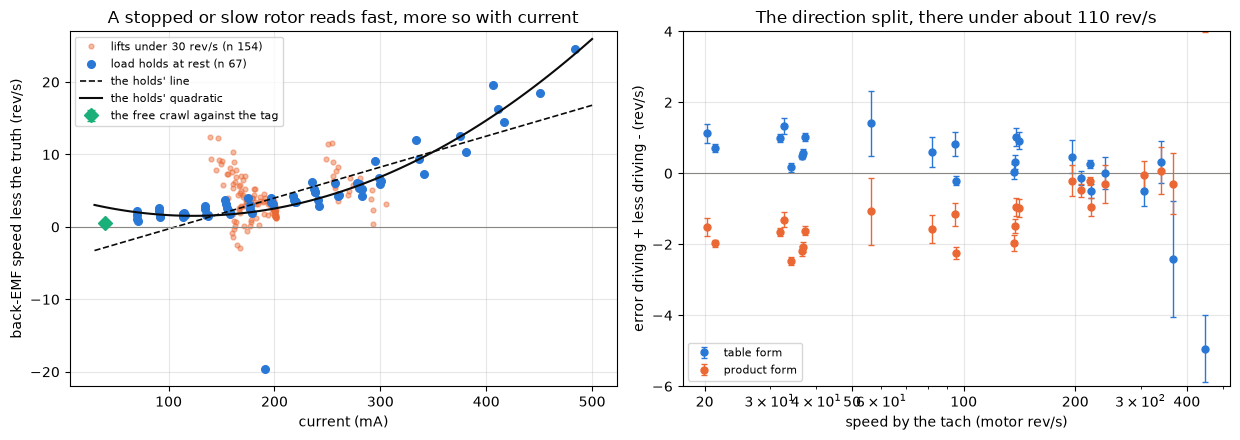

In [129]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.5))
a = ax[0]
lf = H_LIFT[H_LIFT.truth.abs() < 30]
a.plot(lf.i_ma, lf.e_tab, "o", color=ORANGE, ms=3.5, alpha=0.45,
       label=f"lifts under 30 rev/s (n {len(lf)})")
a.plot(H_LOAD.i_ma, H_LOAD.e_tab, "o", color=BLUE, ms=5.5,
       label=f"load holds at rest (n {len(H_LOAD)})")
i = np.linspace(0.03, 0.5, 100)
L = H_LINES[H_LINES.form == "tab"].set_index("fit")
ln, qd = L.loc["load holds at rest"], L.loc["load holds: a + b i + c i^2"]
a.plot(i * 1e3, ln.a + ln.b * i, color=INK, lw=1.2, ls="--",
       label="the holds' line")
a.plot(i * 1e3, qd.a + qd.b * i + qd.curv_per_a2 * i ** 2, color=INK,
       lw=1.5, label="the holds' quadratic")
cr = L.loc["that line at the crawl's current"]
a.errorbar([H_CRAWL.i_ma.mean()], [cr.crawl_measured],
           yerr=[2 * cr.crawl_se], fmt="D", color=GREEN, ms=7, capsize=3,
           label="the free crawl against the tag")
a.axhline(0, color=MUTED, lw=0.8)
a.set_ylim(-22, 27)
figures.label(a, "current (mA)", "back-EMF speed less the truth (rev/s)",
              "A stopped or slow rotor reads fast, more so with current")
a.legend(loc="upper left", fontsize=8)
for form, col, lab in (("tab", BLUE, "table form"),
                       ("prod", ORANGE, "product form")):
    d = H_SPLIT[H_SPLIT.form == form].sort_values("w")
    ax[1].errorbar(d.w, d.split, yerr=d.split_se, fmt="o", color=col, ms=5,
                   capsize=2, lw=1, label=lab)
ax[1].axhline(0, color=MUTED, lw=0.8)
ax[1].set_xscale("log")
ax[1].set_xticks([20, 50, 100, 200, 400], ["20", "50", "100", "200", "400"])
ax[1].set_ylim(-6, 4)
figures.label(ax[1], "speed by the tach (motor rev/s)",
              "error driving + less driving - (rev/s)",
              "The direction split, there under about 110 rev/s")
ax[1].legend(loc="lower left", fontsize=8)
figures.finish(fig)

### (c) The crawl's ripple and what is locked to the rotor's angle

The rows are the steady rows of the camera sitting's driven holds over the taps' floor that move over 10 deg/s. Two scales are read.

At the commutation period, 6 per motor rev, the phase of each row comes from the current's own ripple (`oscnb.ripple.crossings`, seeded by the tag's speed). A signal's residual about its 200 ms tile's line is folded on that phase in 16 bins. The profile of the tile's first half of periods against the profile of its second half gives the locked variance, their covariance, so noise does not count as locked. The signals are the back-EMF per row and through boxcars of 8, 32 and 100 rows, the pot's 5 ms slope, and the current. What the rotor can do at that frequency is bounded from the current's own locked profile, a torque ripple through the rotor's inertia, $\delta\omega = (R\,\delta i / K_e) / (2 \pi f \tau_m)$, with $\tau_m$ the mechanical time constant of stage 3's kept duty steps (section 7).

In [130]:
H_NB, H_NBLK = 16, 32       # phase bins per period; bins per spectrum block
H_BIN_DEG, H_HP_BINS, H_MIN_OVERLAP = 0.25, 16, 24   # angle grid, high-pass
TAU_M = float(BL_STEPS_T.tau_ms.median()) / 1e3      # s, mechanical
print(f"mechanical time constant {TAU_M * 1e3:.1f} ms (median of "
      f"{len(BL_STEPS_T)} kept duty steps, 10-90 % "
      f"{BL_STEPS_T.tau_ms.quantile(0.1):.0f} to "
      f"{BL_STEPS_T.tau_ms.quantile(0.9):.0f})")


def train_orders():
    """Cycles per horn deg of the train's shafts and meshes, from the
    tooth counts (gear, pinion, ..., output gear)."""
    t = SERVO.gear_teeth
    out = {"output mesh": t[-1] / 360}
    rev, shaft = 1.0, (len(t) - 1) // 2
    for j in range(len(t) - 2, 0, -2):  # pinion t[j] on gear t[j - 1]'s shaft
        rev *= t[j + 1] / t[j]
        out[f"shaft {shaft} once per rev"] = rev / 360
        out[f"shaft {shaft} gear mesh ({t[j - 1]} teeth)"] = (
            t[j - 1] * rev / 360)
        shaft -= 1
    out["motor once per rev"] = GEAR / 360
    out["commutation"] = GEAR * N_R / 360
    return out


H_ORDERS = train_orders()
print("periods in horn deg: " + ", ".join(f"{k} {1 / v:.3f}"
                                          for k, v in H_ORDERS.items()))

mechanical time constant 18.3 ms (median of 60 kept duty steps, 10-90 % 12 to 27)
periods in horn deg: output mesh 9.474, shaft 3 once per rev 94.737, shaft 3 gear mesh (38 teeth) 2.493, shaft 2 once per rev 24.931, shaft 2 gear mesh (48 teeth) 0.519, shaft 1 once per rev 6.233, shaft 1 gear mesh (48 teeth) 0.130, motor once per rev 1.169, commutation 0.195


In [131]:
def fold(r, cyc, ph, m=1):
    """(locked variance, total variance, profile) of r folded on m
    periods: the covariance of the first half's profile with the second
    half's, so noise does not count as locked."""
    nb_ = H_NB * m
    b = np.minimum((((cyc % m) + ph) / m * nb_).astype(int), nb_ - 1)
    par = (cyc >= (cyc.min() + cyc.max() + 1) // 2).astype(int)
    prof = []
    for qq in (0, 1):
        k = par == qq
        prof.append(np.bincount(b[k], r[k], nb_)
                    / np.maximum(np.bincount(b[k], minlength=nb_), 1))
    p0, p1 = prof[0] - prof[0].mean(), prof[1] - prof[1].mean()
    return float(np.mean(p0 * p1)), float(r.var()), 0.5 * (p0 + p1)


def h_steady_segs():
    """The driven holds over the floor with steady rows and a lead."""
    return [s for s in SEGS.itertuples() if s.steady1 > s.steady0
            and s.lead_ok and FLOOR <= s.duty_ticks < 240]

In [132]:
def h_phase_tile(raw, a, b, v, s, dropped):
    """The tile's crossings and each row's phase, or None where the count
    lost the line or sat off the tag's line by 15 %."""
    f0 = v / K * N_R
    try:
        tc = ripple.crossings(raw[a:b] - raw[a:b].mean(), f0)
    except Exception:
        return None
    if len(tc) < 8:
        return None
    per = np.diff(tc)
    if per.std() > 0.35 * per.mean():
        return None                     # the count lost the line
    rows = np.arange(int(np.ceil(tc[0])), int(np.floor(tc[-1])))
    j = np.searchsorted(tc, rows, side="right") - 1
    ph = (rows - tc[j]) / (tc[j + 1] - tc[j])
    f_c = FS / per.mean()
    if abs(f_c / f0 - 1) > 0.15:
        dropped.append((s.clip, s.k, s.seg, a))
        return None
    return rows, j, ph, f_c, len(tc) - 1

In [133]:
def h_fold_signals(sig, a, b, rows, j, ph, f_c, rec):
    """Every signal folded on 1, 2 and 6 periods, with the rotor's bound
    and the back-EMF's profile against -R di / Ke."""
    profs = {}
    for name, x in sig.items():
        r = detrend(x[a:b])[rows]
        if not np.isfinite(r).all():
            continue
        lk, tot, prof = fold(r, j, ph)
        rec[name + " locked"], rec[name + " total"] = lk, tot
        rec[name + " locked2"] = fold(r, j, ph, 2)[0]
        rec[name + " locked6"] = fold(r, j, ph, N_R)[0]
        profs[name] = prof
        if name == "current (mA)":      # what the rotor can do of it
            di = prof * 1e-3
            dw = (MO.r_ohm * di / KE) / (2 * np.pi * f_c * TAU_M)
            rec["rotor bound sd"] = float(np.sqrt(np.mean(dw ** 2)))
            rec["R di / Ke sd"] = float(np.sqrt(np.mean(
                (MO.r_ohm * di / KE) ** 2)))
            e = profs.get("emf row")
            if e is not None:
                x2 = -MO.r_ohm * di / KE
                rec["emf on -R di / Ke"] = float(np.sum(e * x2)
                                                 / np.sum(x2 * x2))
                rec["emf x current r"] = float(np.corrcoef(e, x2)[0, 1])

In [134]:
recs, H_DROPPED = [], []
for s in h_steady_segs():
    c = series(s.clip, s.k, s.seg)
    E = EMF[(s.clip, s.k)]
    w, iw = E["w_tab"][s.a:s.b], E["i_w"][s.a:s.b]
    raw = c["current_raw"].astype(float)
    vp = velocity.two_box(c["deg"], 16, 192, FS) / K * s.drive
    sig = {"emf row": w, "current (mA)": iw * 1e3, "pot slope 5 ms": vp}
    for m in (8, 32, 100):
        sig[f"emf boxcar {m}"] = velocity.boxcar(np.nan_to_num(w), m)
    sig = {k: sig[k] for k in ("emf row", "emf boxcar 8", "emf boxcar 32",
                               "emf boxcar 100", "pot slope 5 ms",
                               "current (mA)")}
    w0, w1 = s.steady0 - s.a, s.steady1 - s.a
    tag = c["tag"]
    for a in range(w0, w1 - BL_TILE + 1, BL_TILE):
        b = a + BL_TILE
        if not (np.isfinite(tag[a]) and np.isfinite(tag[b - 1])):
            continue
        v = abs(tag[b - 1] - tag[a]) / ((BL_TILE - 1) / FS)
        if v < 10:
            continue
        got = h_phase_tile(raw, a, b, v, s, H_DROPPED)
        if got is None:
            continue
        rows, j, ph, f_c, ncyc = got
        rec = dict(clip=s.clip, k=s.k, seg=s.seg, a=a, duty=s.duty_ticks,
                   w=v / K, f_comm=f_c, cycles=ncyc)
        h_fold_signals(sig, a, b, rows, j, ph, f_c, rec)
        recs.append(rec)
H_PHASE = pd.DataFrame(recs)
H_PHASE["segid"] = (H_PHASE["clip"] + "/" + H_PHASE.k.astype(str) + "/"
                    + H_PHASE.seg.astype(str))

In [135]:
rows = []
nseg = H_PHASE.segid.nunique()
for name in ("emf row", "emf boxcar 8", "emf boxcar 32", "emf boxcar 100",
             "pot slope 5 ms", "current (mA)"):
    tot = H_PHASE[name + " total"]
    g = H_PHASE.groupby("segid")
    rec = dict(signal=name, sd=np.sqrt(tot.mean()),
               tiles=int(tot.notna().sum()))
    for m, col in ((1, " locked"), (2, " locked2"), (N_R, " locked6")):
        lk = H_PHASE[name + col]
        sh = g[name + col].mean() / g[name + " total"].mean()
        rec[f"locked_sd_{m}"] = np.sign(lk.mean()) * np.sqrt(abs(lk.mean()))
        rec[f"share_{m}"] = lk.mean() / tot.mean()
        rec[f"share_{m}_se"] = sh.std(ddof=1) / np.sqrt(nseg)
    rec["unlocked_sd"] = np.sqrt(max(tot.mean() - H_PHASE[name + " locked6"]
                                     .mean(), 0))
    rows.append(rec)
H_PHASE_SUM = pd.DataFrame(rows)
print(f"{len(H_PHASE)} tiles of 200 ms, {nseg} segments, "
      f"{H_PHASE.w.mean():.1f} rev/s, the line at {H_PHASE.f_comm.min():.0f}"
      f" to {H_PHASE.f_comm.max():.0f} Hz, {int(H_PHASE.cycles.sum())} "
      f"periods; {len(H_DROPPED)} tiles off the tag's line")
print("locked over 1, 2 and 6 periods (the commutation, the half order, the "
      "motor's rev): sd rev/s, share of the variance +/- se over segments")
print(H_PHASE_SUM.round(3).to_string(index=False))

116 tiles of 200 ms, 34 segments, 24.5 rev/s, the line at 56 to 242 Hz, 3026 periods; 1 tiles off the tag's line
locked over 1, 2 and 6 periods (the commutation, the half order, the motor's rev): sd rev/s, share of the variance +/- se over segments
        signal    sd  tiles  locked_sd_1  share_1  share_1_se  locked_sd_2  share_2  share_2_se  locked_sd_6  share_6  share_6_se  unlocked_sd
       emf row 3.881    116        3.292    0.719       0.019        3.309    0.727       0.019        3.309    0.727       0.020        2.029
  emf boxcar 8 3.762    116        3.263    0.752       0.020        3.279    0.760       0.020        3.279    0.760       0.022        1.844
 emf boxcar 32 3.412    116        2.882    0.713       0.022        2.898    0.721       0.022        2.895    0.720       0.024        1.807
emf boxcar 100 2.080    116        1.057    0.258       0.038        1.086    0.273       0.040        1.072    0.266       0.041        1.782
pot slope 5 ms 7.150    116       -0

In [136]:
sg = H_PHASE.groupby("segid")[["emf on -R di / Ke", "emf x current r"]].mean()
print(f"the rotor's bound: R di / Ke of the current's locked profile "
      f"{H_PHASE['R di / Ke sd'].mean():.2f} rev/s sd; through the inertia "
      f"{H_PHASE['rotor bound sd'].mean():.3f} rev/s sd "
      f"[{H_PHASE['rotor bound sd'].min():.3f}, "
      f"{H_PHASE['rotor bound sd'].max():.3f}]")
print(f"the estimate's profile on -R di / Ke: slope "
      f"{sg.iloc[:, 0].mean():+.3f} +/- "
      f"{sg.iloc[:, 0].std(ddof=1) / np.sqrt(len(sg)):.3f}, correlation "
      f"{sg.iloc[:, 1].mean():+.3f} [{sg.iloc[:, 1].min():+.2f}, "
      f"{sg.iloc[:, 1].max():+.2f}] ({len(sg)} segments)")
H_PHASE_DUTY = H_PHASE.groupby("duty").apply(lambda d: pd.Series(dict(
    tiles=len(d), w=d.w.mean(), f_comm=d.f_comm.mean(),
    emf_locked_sd=np.sqrt(max(d["emf row locked"].mean(), 0)),
    emf_sd=np.sqrt(d["emf row total"].mean()),
    share=d["emf row locked"].mean() / d["emf row total"].mean(),
    box32_locked_sd=np.sqrt(max(d["emf boxcar 32 locked"].mean(), 0)))),
    include_groups=False)
print(H_PHASE_DUTY.round(2).to_string())
lk = H_PHASE_SUM.set_index("signal").loc["emf row", "locked_sd_1"]
print(f"the period {1e3 / H_PHASE_DUTY.f_comm.max():.1f} to "
      f"{1e3 / H_PHASE_DUTY.f_comm.min():.1f} ms by duty; the rotor's bound "
      f"is {H_PHASE['rotor bound sd'].mean() / lk:.1%} of the locked "
      f"{lk:.3f} rev/s")

the rotor's bound: R di / Ke of the current's locked profile 3.00 rev/s sd; through the inertia 0.183 rev/s sd [0.155, 0.281]
the estimate's profile on -R di / Ke: slope +1.074 +/- 0.000, correlation +1.000 [+1.00, +1.00] (34 segments)
      tiles      w  f_comm  emf_locked_sd  emf_sd  share  box32_locked_sd
duty                                                                     
84     21.0  15.64   94.40           2.28    2.77   0.68             2.18
96     23.0  20.88  124.18           2.89    3.50   0.68             2.66
108    52.0  25.12  150.03           3.34    3.97   0.71             2.98
120     4.0  33.09  196.95           4.03    4.54   0.79             3.36
132    16.0  37.47  223.64           4.41    5.02   0.77             3.49
the period 4.5 to 10.6 ms by duty; the rotor's bound is 5.6% of the locked 3.292 rev/s


At the gear train's scale, periods of 0.5 to 8 deg of horn, each source's mean speed is read over bins of 0.25 deg of travel on an absolute angle grid, the pot's own boxcar-16 angle the abscissa, and high-passed over +/- 16 bins (4 deg). Two segments that cross the same angles in the same direction give, per source, a covariance of their two profiles, which is what repeats with the angle. The covariance of one source in one pass with another source in the other pass is what both see and repeats. That is real motion locked to the angle, since the sources' own errors are independent across sources and passes. The se is a leave-one-segment-out jackknife. The same products over blocks of 32 bins (8 deg) give the variance by period.

In [137]:
def h_angle_edges(mono, drive):
    """The bin edges a segment crosses on the 0.25 deg grid and the rows it
    crosses them on, in time order."""
    lo, hi = sorted((mono[0], mono[-1]))
    edges = np.arange(np.ceil(lo / H_BIN_DEG) + 1,
                      np.floor(hi / H_BIN_DEG)) * H_BIN_DEG
    if len(edges) < H_MIN_OVERLAP + 2 * H_HP_BINS:
        return None
    if drive > 0:
        t_e = np.searchsorted(mono, edges)
    else:
        t_e = np.searchsorted(-mono, -edges[::-1])[::-1]
    order = np.argsort(t_e)
    return t_e[order], edges[order]

In [138]:
def h_angle_profile(s):
    """A segment's three sources' speeds (rev/s, along the drive) per
    0.25 deg bin, raw and high-passed; None where it is not usable."""
    c = series(s.clip, s.k, s.seg)
    E = EMF[(s.clip, s.k)]
    w0, w1 = s.steady0 - s.a, s.steady1 - s.a
    deg = velocity.boxcar(c["deg"], 16)[w0:w1]
    tag = c["tag"][w0:w1]
    w = E["w_tab"][s.a:s.b][w0:w1]
    if (not (np.isfinite(tag).all() and np.isfinite(w).all())
            or abs(deg[-1] - deg[0]) < 8):
        return None
    ang_e = np.cumsum(w) / FS * K       # deg of horn along the drive
    mono = np.maximum.accumulate(deg * s.drive) * s.drive  # monotone
    got = h_angle_edges(mono, s.drive)
    if got is None:
        return None
    t_e, edges = got
    dt = np.diff(t_e) / FS
    dt = np.where(dt > 0, dt, np.nan)
    raw = {"emf": np.diff(ang_e[t_e]) / dt / K,
           "pot": H_BIN_DEG / dt / K,
           "tag": np.diff(tag[t_e]) * s.drive / dt / K}
    prof = {n_: x - pd.Series(x).rolling(2 * H_HP_BINS + 1, center=True,
                                         min_periods=H_HP_BINS).mean()
            .to_numpy() for n_, x in raw.items()}
    idx = np.round(np.minimum(edges[:-1], edges[1:]) / H_BIN_DEG).astype(int)
    return dict(drive=s.drive, idx=idx, prof=prof, raw=raw,
                w=float(np.nanmean(raw["emf"])), start=float(deg[0]))

In [139]:
H_NAMES = ("emf", "pot", "tag")
H_PAIRS = (("emf", "emf"), ("pot", "pot"), ("tag", "tag"), ("emf", "tag"),
           ("emf", "pot"), ("pot", "tag"))
H_BANDS = (("8 deg", (1,)), ("4 deg", (2,)), ("2.7 to 2 deg", (3, 4)),
           ("1.6 to 1.14 deg", (5, 6, 7)),
           ("1 to 0.67 deg", (8, 9, 10, 11, 12)),
           ("0.62 to 0.53 deg", (13, 14, 15)))
H_WIN_HANN = np.hanning(H_NBLK)
H_NORM = 2.0 / (H_NBLK * np.sum(H_WIN_HANN ** 2))
H_JB = np.arange(H_NBLK) - (H_NBLK - 1) / 2


def h_block_ffts(A, Bq, ia, ib, st):
    """The detrended, Hann-windowed spectra of one block of both passes."""
    F = {}
    for n_ in H_NAMES:
        for tag_, P_, ix in (("A", A, ia), ("B", Bq, ib)):
            x = P_["raw"][n_][ix][st:st + H_NBLK]
            x = x - np.polyval(np.polyfit(H_JB, x, 1), H_JB)
            F[(n_, tag_)] = np.fft.rfft(x * H_WIN_HANN)[:H_NBLK // 2]
    return F

In [140]:
def h_pair(A, Bq, i, j):
    """One pair of passes over the same angles: the summed products of
    the high-passed profiles and the summed cross-spectra of the raw ones
    over blocks of H_NBLK bins (half overlap)."""
    common, ia, ib = np.intersect1d(A["idx"], Bq["idx"], return_indices=True)
    if len(common) < H_MIN_OVERLAP:
        return None
    good = np.ones(len(common), bool)
    fin = np.ones(len(common), bool)
    for n_ in H_NAMES:
        good &= np.isfinite(A["prof"][n_][ia]) & np.isfinite(Bq["prof"][n_][ib])
        fin &= np.isfinite(A["raw"][n_][ia]) & np.isfinite(Bq["raw"][n_][ib])
    if good.sum() < H_MIN_OVERLAP:
        return None
    rec = dict(i=i, j=j, n=int(good.sum()), cov={}, spec={}, nblk=0,
               far=abs(A["start"] - Bq["start"]) >= 5.0)
    for a, b in H_PAIRS:
        v = 0.0
        for x, y in ((a, b), (b, a)):   # symmetrized
            xa, xb = A["prof"][x][ia][good], Bq["prof"][y][ib][good]
            v += 0.5 * float(np.sum((xa - xa.mean()) * (xb - xb.mean())))
        rec["cov"][(a, b)] = v
        rec["spec"][(a, b)] = np.zeros(H_NBLK // 2)
    step = np.diff(common) == 1
    st = 0
    while st + H_NBLK <= len(common):
        if fin[st:st + H_NBLK].all() and step[st:st + H_NBLK - 1].all():
            F = h_block_ffts(A, Bq, ia, ib, st)
            for a, b in H_PAIRS:
                rec["spec"][(a, b)] += 0.5 * H_NORM * (
                    (F[(a, "A")] * np.conj(F[(b, "B")])).real
                    + (F[(b, "A")] * np.conj(F[(a, "B")])).real)
            rec["nblk"] += 1
            st += H_NBLK // 2
        else:
            st += 1
    return rec

In [141]:
def h_pooled(R, drop=None):
    """(cov, spec, bins, blocks, pairs) pooled over the pairs, without
    the segment `drop`."""
    R = [r for r in R if drop is None or (r["i"] != drop and r["j"] != drop)]
    n = sum(r["n"] for r in R)
    nb_ = sum(r["nblk"] for r in R)
    cov = {k: sum(r["cov"][k] for r in R) / max(n, 1) for k in H_PAIRS}
    spec = {k: sum(r["spec"][k] for r in R) / max(nb_, 1) for k in H_PAIRS}
    return cov, spec, n, nb_, len(R)


def h_jack(R, nseg, f):
    """(value, leave-one-segment-out jackknife se) of f(cov, spec)."""
    full = f(*h_pooled(R)[:2])
    th = np.array([f(*h_pooled(R, d)[:2]) for d in range(nseg)])
    return full, np.sqrt((nseg - 1) / nseg * np.sum((th - th.mean(0)) ** 2,
                                                    axis=0))


H_PROFS = [p for p in (h_angle_profile(s) for s in h_steady_segs())
           if p is not None]
H_PAIR_SUMS = [r for i in range(len(H_PROFS))
               for j in range(i + 1, len(H_PROFS))
               if H_PROFS[i]["drive"] == H_PROFS[j]["drive"]
               for r in [h_pair(H_PROFS[i], H_PROFS[j], i, j)] if r]
cov, spec, n_bins, n_blk, n_pairs = h_pooled(H_PAIR_SUMS)
print(f"{len(H_PROFS)} segments, {n_pairs} pairs that share angles in one "
      f"direction, {n_bins} shared bins, {n_blk} blocks of "
      f"{H_NBLK * H_BIN_DEG:.0f} deg")

25 segments, 84 pairs that share angles in one direction, 5914 shared bins, 240 blocks of 8 deg


In [142]:
nseg = len(H_PROFS)
var = {n_: float(np.nanmean(np.concatenate([p["prof"][n_] for p in H_PROFS])
                            ** 2)) for n_ in H_NAMES}
recs = []
for k in H_PAIRS:
    v, se = h_jack(H_PAIR_SUMS, nseg, lambda c, s_, k=k: c[k])
    rec = dict(a=k[0], b=k[1], cov=v, se=se, var_a=var[k[0]])
    for name, sel in (("far", True), ("near", False)):
        Rs = [r for r in H_PAIR_SUMS if r["far"] == sel]
        rec[f"cov_{name}"], rec[f"pairs_{name}"] = h_pooled(Rs)[0][k], len(Rs)
    recs.append(rec)
H_ANGLE = pd.DataFrame(recs)
srecs = []
for name, ks in H_BANDS:
    ks = np.array(ks)
    rec = dict(band=name, orders="; ".join(
        o for o, f in H_ORDERS.items()
        if (ks.min() - 0.5) <= f * H_NBLK * H_BIN_DEG < (ks.max() + 0.5)))
    for k in H_PAIRS:
        v, se = h_jack(H_PAIR_SUMS, nseg,
                       lambda c, s_, k=k: float(s_[k][ks].sum()))
        rec[f"{k[0]}_{k[1]}"], rec[f"{k[0]}_{k[1]}_se"] = v, float(se)
    srecs.append(rec)
H_SPECTRUM = pd.DataFrame(srecs)
rt = lambda v: np.sign(v) * np.sqrt(abs(v))                 # noqa: E731
for r in H_ANGLE.itertuples():
    print(f"{r.a} x {r.b} in the other pass: {r.cov:+.3f} +/- {r.se:.3f} "
          f"(rev/s)^2 ({rt(r.cov):+.2f} rev/s, {r.cov / r.var_a:+.1%} of "
          f"{r.a}'s {r.var_a:.2f}); passes 5 deg apart or more "
          f"{r.cov_far:+.3f} (n {r.pairs_far}), closer {r.cov_near:+.3f} "
          f"(n {r.pairs_near})")

emf x emf in the other pass: +5.971 +/- 1.234 (rev/s)^2 (+2.44 rev/s, +89.4% of emf's 6.68); passes 5 deg apart or more +6.161 (n 51), closer +5.735 (n 33)
pot x pot in the other pass: +185.641 +/- 69.257 (rev/s)^2 (+13.63 rev/s, +56.0% of pot's 331.45); passes 5 deg apart or more +167.838 (n 51), closer +207.780 (n 33)
tag x tag in the other pass: +5.341 +/- 2.120 (rev/s)^2 (+2.31 rev/s, +19.7% of tag's 27.11); passes 5 deg apart or more +5.906 (n 51), closer +4.637 (n 33)
emf x tag in the other pass: +5.001 +/- 1.518 (rev/s)^2 (+2.24 rev/s, +74.8% of emf's 6.68); passes 5 deg apart or more +5.337 (n 51), closer +4.583 (n 33)
emf x pot in the other pass: +5.211 +/- 1.789 (rev/s)^2 (+2.28 rev/s, +78.0% of emf's 6.68); passes 5 deg apart or more +6.037 (n 51), closer +4.183 (n 33)
pot x tag in the other pass: +4.952 +/- 2.438 (rev/s)^2 (+2.23 rev/s, +1.5% of pot's 331.45); passes 5 deg apart or more +5.057 (n 51), closer +4.821 (n 33)


In [143]:
cols = ["band", "emf_tag", "emf_tag_se", "emf_pot", "pot_tag", "emf_emf",
        "emf_emf_se", "tag_tag", "pot_pot", "orders"]
print("by period, variance (rev/s)^2 +/- jackknife se:")
print(H_SPECTRUM[cols].round(3).to_string(index=False))
m = H_SPECTRUM.set_index("band").loc["1.6 to 1.14 deg"]
print(f"the back-EMF's own repeat less the real motion at 1.6 to 1.14 deg: "
      f"{m.emf_emf:.3f} less {m.emf_tag:.3f} = {m.emf_emf - m.emf_tag:.3f}"
      f" +/- {np.hypot(m.emf_emf_se, m.emf_tag_se):.3f}")
ex = H_ANGLE[(H_ANGLE.a == "emf") & (H_ANGLE.b == "tag")].iloc[0]
w_seg = np.mean([p["w"] for p in H_PROFS])
print(f"real motion {np.sqrt(ex['cov']):.2f} rev/s sd: "
      f"{np.sqrt(ex['cov']) / H_PHASE.w.mean():.1%} of the phase tiles' "
      f"{H_PHASE.w.mean():.1f} rev/s, {np.sqrt(ex['cov']) / w_seg:.1%} of "
      f"these segments' own {w_seg:.1f} rev/s")

by period, variance (rev/s)^2 +/- jackknife se:
            band  emf_tag  emf_tag_se  emf_pot  pot_tag  emf_emf  emf_emf_se  tag_tag  pot_pot                            orders
           8 deg    2.188       0.736    1.815    2.206    2.299       0.607    2.640   13.834 output mesh; shaft 1 once per rev
           4 deg    1.146       0.429    1.913    2.478    1.382       0.361    1.236   20.077                                  
    2.7 to 2 deg    0.114       0.141    0.360    0.167    0.264       0.054   -0.079   30.383      shaft 3 gear mesh (38 teeth)
 1.6 to 1.14 deg    0.029       0.028    0.039    0.113    0.114       0.017   -0.079   33.872                motor once per rev
   1 to 0.67 deg    0.012       0.019    0.019    0.190    0.106       0.016   -0.034   36.669                                  
0.62 to 0.53 deg   -0.016       0.008    0.369   -0.030    0.084       0.020   -0.000   13.247      shaft 2 gear mesh (48 teeth)
the back-EMF's own repeat less the real motion at

What (c) says.

- **Per row, 72 % of the back-EMF's variance at a crawl is the commutation's pattern, and it is not motion.** Of the back-EMF's 3.881 rev/s sd per row, 3.292 is locked to the commutation phase (share 0.719 +/- 0.019), over 116 tiles in 34 segments and 3026 periods. Adding the half order and the motor's rev adds nothing (0.727). The estimate's locked profile is the current's locked profile times -R / Ke, slope +1.074 and correlation +1.000, row for row. At a steady duty the current is the estimate's only moving input. The current's locked ripple through the rotor's inertia ($\tau_m$ 18.3 ms) makes 0.183 rev/s, 5.6 % of the locked 3.292, so about 94 % of the locked amplitude is electrical. Moderate for the lock, and the 0.183 is a model bound.
- **A boxcar of 32 rows leaves 2.882 rev/s of it, 100 rows 1.057.** The period is 4.5 to 10.6 ms here (94 to 224 Hz by duty), so only a window of a whole period, which moves with the speed, nulls it. That is the floor under section 4's back-EMF noise at short windows. The locked sd grows with the duty, 2.28 rev/s at 84 ticks to 4.41 at 132.
- **The pot's 5 ms slope shows no commutation pattern** (-0.001 of its 7.150 rev/s), since one count is a quarter of the period.
- **Over 10 ms and longer most of what is left is real motion locked to the horn's angle.** Of the back-EMF's 6.68 (rev/s)^2 over 0.25 deg bins, 5.971 +/- 1.234 repeats with the angle, and 5.001 +/- 1.518 is seen by the tag in another pass at the same angles, 2.24 rev/s sd. That is 9.1 % of the phase tiles' 24.5 rev/s (8.3 % of the angle segments' own 27.1). It shows at periods of 4 deg and longer (2.188 and 1.146 (rev/s)^2 at 8 and 4 deg), and passes that start 5 deg apart or more read it the same as closer ones (5.337 against 4.583), so it is the angle, not the time since the start. Moderate.
- **The pot's own repeatable pattern is 13.63 rev/s sd per 0.25 deg bin,** at every period. It is the code widths and the carries, the pot's and not motion, since the back-EMF and the tag in the other pass do not see it.
- **The motor's once-per-rev shows in the back-EMF alone,** 0.114 less the real motion's 0.029 = 0.085 +/- 0.033 (rev/s)^2 at 1.6 to 1.14 deg. Candidate.

What the sitting does not separate, and the capture that would:

- At the commutation period, a back-EMF constant that varies with the rotor's angle from a resistance that varies with it (a brush bridging two bars). Both make the same current ripple under drive. A coast with the taps streamed separates them, since the ripple of the open-circuit voltage at zero current is the back-EMF's alone. That is a capture for identification, not a coast in an estimator.
- At the commutation period, the real motion itself. Neither the pot (one count is a quarter of the period) nor the tag (frames 4.2 ms apart) resolves 0.195 deg. An encoder on the motor shaft would.
- At 4 to 8 deg, which shaft. The output mesh (9.474 deg) and the first shaft's turn (6.233 deg) fall in one 8 deg bin. Passes of 40 deg and more at a steady crawl would resolve the lines.
- Friction that varies with the angle against a pot or gear load that varies with it. A crawl at two duties over the same angles separates them, since a load pattern scales its speed ripple with the drive's stiffness and a ratio error does not.

### What section 8 hands on

In [144]:
def h_line_keys(form):
    L = H_LINES[H_LINES.form == form].set_index("fit")
    ln, qd = L.loc["load holds at rest"], L.loc["load holds: a + b i + c i^2"]
    rg = H_RUNGS[H_RUNGS.form == form]
    u = H_UNDER[form]
    return {"line_a": pm(ln.a, ln.a_se, "rev/s, +/- se"),
            "line_b_per_a": pm(ln.b, ln.b_se, "rev/s per A, +/- se"),
            "line_resid_sd": q(ln.resid_sd, unit="rev/s"),
            "quadratic": [float(qd.a), float(qd.b), float(qd.curv_per_a2)],
            "curvature_per_a2": pm(qd.curv_per_a2, qd.curv_se,
                                   "rev/s per A^2, +/- se"),
            "curvature_under_300_ma_per_a2": pm(
                u["curv_per_a2"], u["curv_se"], "rev/s per A^2, +/- se, "
                f"{u['n']} holds under 300 mA"),
            "valid_ma": [float(ln.i_lo), float(ln.i_hi)],
            "by_band_ma": {f"{r.i_ma:.0f}": pm(r.bias, r.se, "rev/s, +/- se")
                           for r in rg.itertuples()},
            "n_holds": int(ln.n)}


def h_set(form, name):
    r = H_SETS_T[(H_SETS_T.form == form) & (H_SETS_T.set == name)].iloc[0]
    return pm(r.bias, r.se, "rev/s, +/- se over sweeps")


def h_fit(form, name):
    r = H_FIT[(H_FIT.form == form) & (H_FIT.cycles == name)].iloc[0]
    return pm(r.split, r.se, "rev/s, +/- se")


FORMS = {"table": "tab", "product": "prod"}
R_S8 = {
    "emf_stopped_rotor_rev_s": {f: h_line_keys(v) for f, v in FORMS.items()},
    "emf_bias_lift_rev_s": {f: h_set(v, "lifts") for f, v in FORMS.items()},
    "emf_bias_lift_by_speed_rev_s": {
        f: {b: h_set(v, f"lifts {b} rev/s") for b in ("0-30", "30-100",
                                                       "100-170")}
        for f, v in FORMS.items()},
}
print(len(R_S8), "keys so far")

3 keys so far


In [145]:
L = H_LINES.set_index(["form", "fit"])
R_S8["emf_crawl_against_holds_and_lifts_line_rev_s"] = {
    f: {"line_at_crawl": pm(L.loc[(v, "that line at the crawl's current"),
                                  "a"],
                            L.loc[(v, "that line at the crawl's current"),
                                  "a_se"], "rev/s, +/- se"),
        "crawl_measured": h_set(v, "crawl (camera, tag)"),
        "gap_sigma": float(L.loc[(v, "that line at the crawl's current"),
                                 "gap_sigma"])}
    for f, v in FORMS.items()}
R_S8["emf_direction_split_rev_s"] = {
    f: {k: h_fit(v, c) for k, c in (("under_45", "under 45 rev/s"),
                                    ("45_110", "45 to 110"),
                                    ("over_110", "110 up"))}
    for f, v in FORMS.items()}
R_S8["emf_direction_split_slope_under_110"] = {
    k: h_fit("tab", f"slope on {c}, under 110")
    for k, c in (("per_10_rev_s", "speed (per 10 rev/s)"),
                 ("per_10_ma", "current (per 10 mA)"),
                 ("per_v", "rail (per V)"),
                 ("per_10_ticks", "on-time (per 10 ticks)"))}
ps = H_PHASE_SUM.set_index("signal")
R_S8["emf_commutation_locked_share_crawl"] = pm(
    ps.loc["emf row", "share_1"], ps.loc["emf row", "share_1_se"],
    "of the per-row variance, +/- se over segments")
R_S8["emf_commutation_locked_sd_rev_s"] = {
    k: q(ps.loc[s, "locked_sd_1"], unit="rev/s")
    for k, s in (("row", "emf row"), ("boxcar_8", "emf boxcar 8"),
                 ("boxcar_32", "emf boxcar 32"),
                 ("boxcar_100", "emf boxcar 100"))}
rb = H_PHASE["rotor bound sd"]
R_S8["emf_commutation_motion_bound_rev_s"] = q(rb.mean(), rb.min(), rb.max(),
                                               "rev/s sd, [range by tile]")
R_S8["mechanical_tau_ms"] = q(TAU_M * 1e3, BL_STEPS_T.tau_ms.quantile(0.1),
                              BL_STEPS_T.tau_ms.quantile(0.9),
                              "ms, median [10-90 %] of the kept steps")
print(len(R_S8), "keys so far")

10 keys so far


In [146]:
R_S8["emf_commutation_locked_by_duty"] = {
    str(d): {"locked_sd_rev_s": float(r.emf_locked_sd),
             "line_hz": float(r.f_comm), "share": float(r.share),
             "tiles": int(r.tiles)} for d, r in H_PHASE_DUTY.iterrows()}
an = H_ANGLE.set_index(["a", "b"])
R_S8["crawl_angle_locked_motion_rev_s"] = {
    "sd": q(np.sqrt(an.loc[("emf", "tag"), "cov"]), unit="rev/s"),
    "variance": pm(an.loc[("emf", "tag"), "cov"],
                   an.loc[("emf", "tag"), "se"],
                   "(rev/s)^2, +/- jackknife se"),
    "periods": "4 deg and longer"}
R_S8["pot_angle_locked_pattern_rev_s_per_quarter_deg"] = q(
    np.sqrt(an.loc[("pot", "pot"), "cov"]), unit="rev/s sd per 0.25 deg bin")
R_S8["crawl_angle_spectrum"] = {
    r.band: {"real_motion": pm(r.emf_tag, r.emf_tag_se, "(rev/s)^2"),
             "emf_repeat": pm(r.emf_emf, r.emf_emf_se, "(rev/s)^2")}
    for r in H_SPECTRUM.itertuples()}
print(len(R_S8), "keys")

14 keys


For section 10's table, sections 6 to 8 hand on the rest verdict's times, the blends' steady bias, own noise and delay, and their seams.

In [147]:
def st5(cand):
    """A blend's crawl bias and own sd, its kick-end delay."""
    b = BL_STEADY[(BL_STEADY.band == "crawl") & (BL_STEADY.cand == cand)]
    d = dl.loc[("kick end, hold over the floor", cand)]
    return {"bias_crawl_rev_s": round(float(b.bias.iloc[0]), 2),
            "own_sd_crawl_rev_s": round(float(b.own_sd.iloc[0]), 2),
            "delay_kick_end_rows": round(float(d.added), 1)}


STAGE5_S678 = {
    "rest_verdict": {c: {"declare_ms": round(tm(c, "stop_coast_d_pot_med"), 1),
                         "drop_ms": round(tm(c, "start_d_duty_med"), 1)}
                     for c in ("band 2 T50", "slope 192 T50",
                               "band 2 T50 + emf")},
    "blends": {c: st5(c) for c in ("pot5", "pot25", "sw5", "cp5", "cp25",
                                   "cpr5")},
    "seams_rev_s": {k: round(float(v["median"]["value"]), 1)
                    for k, v in R_S7["blend_seam_rev_s"].items()},
    "stopped_rotor_line": [round(STALL["a_rev_s"], 2),
                           round(STALL["b_rev_s_per_a"], 1)]}
for k, v in STAGE5_S678.items():
    print(k, v)

rest_verdict {'band 2 T50': {'declare_ms': 56.4, 'drop_ms': 7.7}, 'slope 192 T50': {'declare_ms': 56.1, 'drop_ms': 6.5}, 'band 2 T50 + emf': {'declare_ms': 56.4, 'drop_ms': 5.8}}
blends {'pot5': {'bias_crawl_rev_s': 0.0, 'own_sd_crawl_rev_s': 6.99, 'delay_kick_end_rows': 105.2}, 'pot25': {'bias_crawl_rev_s': -0.03, 'own_sd_crawl_rev_s': 2.59, 'delay_kick_end_rows': 498.8}, 'sw5': {'bias_crawl_rev_s': 0.4, 'own_sd_crawl_rev_s': 3.43, 'delay_kick_end_rows': -83.5}, 'cp5': {'bias_crawl_rev_s': 0.04, 'own_sd_crawl_rev_s': 3.52, 'delay_kick_end_rows': -68.9}, 'cp25': {'bias_crawl_rev_s': 0.06, 'own_sd_crawl_rev_s': 3.42, 'delay_kick_end_rows': -96.1}, 'cpr5': {'bias_crawl_rev_s': 0.04, 'own_sd_crawl_rev_s': 3.52, 'delay_kick_end_rows': -68.9}}
seams_rev_s {'sw5_kick': 13.5, 'sw5_coast': 6.8, 'swr5_kick': 44.7, 'swv5_kick': 18.0, 'cpr5_kick': 14.4, 'cp5_handover': 0.2, 'cp5_coast': 5.4, 'cp25_coast': 2.5}
stopped_rotor_line [-4.54, 42.7]


## 9. The kick's end

On the row clock alone the pot and the back-EMF agree through a steady hold and disagree for about 30 ms after a hard deceleration. This section reads that disagreement event by event, with three readings of the horn's motion on the same rows. They are the pot through the lookup, the back-EMF speed integrated over the rows, and the tag at the camera's frames. It states what the reads agree on and what they leave open, and then reads the motor's own shaft from a count of the commutation ripple. No cause is picked, and nothing here corrects or trims either source.

The events are the duty changes found in the rows. A kick starts from rest, a kick ends into a lower hold, a coast starts when the duty goes to zero, and the sitting also holds reversals, pass starts and small duty steps. The controls are the same reading at an instant of a steady segment where nothing changes. Every displacement and speed is along the motion into the event, the drive's direction before the change, or for a start from rest the direction of the drive that starts. Time zero is the row where the duty changes.

The holes are treated one comparison at a time.

- The pot against the back-EMF is read inside one segment only, anchored at the first valid row after the change, at most 16 rows later. No hole is crossed, so no camera timing enters this pair.
- The tag pairs after the change are differences between bins of frames inside the segment, the first 10 ms or the rest before a start as the reference.
- The pot against the tag across a hole takes the last frames before the change as the reference, placed on the segment before in two ways, by that segment's own host stamp (H) and by the row clock with the hole measured from the pot's own continuity (R).
- The back-EMF integral is never carried across a hole.

In [148]:
KICK_PRE_S, KICK_POST_S = 0.25, 0.45    # s of frames kept around an event
KICK_GRID_MS = np.r_[0:10:1, 10:50:2, 50:150:5, 150:401:10]  # after
KICK_SLOPE_ROWS = 200       # rows, a pot speed: the line over 10 ms
KICK_FAST_DEG_S = 40.0      # deg/s, the pot-continuity hole needs this
KICK_HOLE_MAX_ROWS = 400    # rows, a hole a comparison may cross
KICK_CONTROL_AT = 0.6       # of a steady stretch: the control's instant
KICK_CONTROL_MIN_S = 0.6    # s, a steady stretch long enough for one
KICK_NEAR_COUNTS = 12       # counts, a row this close to a carry code
KICK_BINS_POST = [0, 10, 20, 35, 60, 100, 200, 400]    # ms after
KICK_BINS_START = [0, 10, 20, 40, 70, 100, 130, 150]   # ms, a kick start
KICK_PRE_BINS = [(-60, -30), (-30, -4)]                # ms before
KICK_REST_BIN = (-150, -5)                             # ms, at rest
print(f"grid {len(KICK_GRID_MS)} checkpoints to {KICK_GRID_MS[-1]} ms; "
      f"holes crossed up to {KICK_HOLE_MAX_ROWS / FS * 1e3:.0f} ms; the "
      f"pot's speed before a hole over {KICK_SLOPE_ROWS / FS * 1e3:.0f} ms; "
      f"the control at {KICK_CONTROL_AT:.0%} of a steady stretch")
print(f"frame bins after the change {KICK_BINS_POST} ms ({KICK_BINS_START} "
      f"on a kick start), before it {KICK_PRE_BINS}, rest {KICK_REST_BIN}")

grid 76 checkpoints to 400 ms; holes crossed up to 20 ms; the pot's speed before a hole over 10 ms; the control at 60% of a steady stretch
frame bins after the change [0, 10, 20, 35, 60, 100, 200, 400] ms ([0, 10, 20, 40, 70, 100, 130, 150] on a kick start), before it [(-60, -30), (-30, -4)], rest (-150, -5)


### The rows

Each chain's rows carry, per row, the pot's angle through the lookup and its 2 ms centered mean inside the segment, the back-EMF speed and its signed horn speed, the winding current and the valid flag. The back-EMF is the four-term estimate with the table form, per row as in section 1.

In [149]:
def kick_rows(clip, k, with_l=False):
    """One chain's rows with theta (deg), theta_s (its 2 ms centered mean
    in the segment), w (rev/s in the drive's direction), rate_bemf (horn
    deg/s, signed), i_w (A), valid and near (a carry code within 12)."""
    df, _, seg = PF.rows(clip, k)
    r = CHAINS[(CHAINS["clip"] == clip) & (CHAINS["k"] == k)].iloc[0]
    sl = slice(int(r.i0), int(r.i1))
    duty = df["duty_counts"].to_numpy()
    d = np.sign(duty).astype(float)     # the drive's direction per row
    sg = df["seg"].to_numpy()
    first = np.r_[True, sg[1:] != sg[:-1]]   # each segment's first row
    w, u, i_w = speed.estimate_rows(    # the table form, bisection
        ARR["raw"][sl], Z[sl], ARR["va"][sl], ARR["vb"][sl], duty, d,
        np.full(len(df), r.ntc_c), CH, MO, TAB, first=first, with_l=with_l)
    on = np.r_[False, (d[1:] != 0) & (d[:-1] == 0)]     # torque on
    flip = np.r_[False, (d[1:] * d[:-1]) < 0]           # a reversal
    valid = (speed.tap_floor_valid(duty, FLOOR)
             & speed.holdoff_rows(first | on, flip, N_START, N_START))
    df["theta"] = LOOKUP.angle(df["pos"].to_numpy())
    df["theta_s"] = df.groupby("seg")["theta"].transform(
        lambda x: potframes.centered_mean(x.to_numpy(), potframes.BOX_ROWS))
    df["w"], df["i_w"], df["valid"] = w, i_w, valid
    df["rate_bemf"] = d * w * 360.0 / GEAR
    p = df["pos"].to_numpy()[:, None]
    df["near"] = (np.abs(p - np.asarray(CARRY_CODES, float)[None, :])
                  <= KICK_NEAR_COUNTS).any(axis=1)
    return df, seg

### The events

Every duty change of a segment is an event, and so is the change into a segment from the one before across a hole. Across a long hole, a seek and a rest, the horn starts from rest. The hole before each event is read twice, from the host stamps and, where the pot moves fast, from the pot's own continuity, the line through the last 10 ms before the hole carried to the pot's first reading after it.

In [150]:
def kick_slope(theta, i, half):
    """deg/s, the line through theta over +/- half rows about row i."""
    a, b = max(0, i - half), min(len(theta), i + half + 1)
    if b - a < 20:
        return np.nan
    return np.polyfit(np.arange(a, b) / FS, theta[a:b], 1)[0]


def kick_kind(before, after):
    """The kind of a duty change, from the duty before and after it."""
    if before == 0 and after != 0:
        return "kick_start" if abs(after) >= 300 else "pass_start"
    if after == 0:
        return "coast_start"
    if before * after < 0:
        return "reversal"
    if abs(before) >= 300 and abs(after) < abs(before):
        return "kick_end"
    return "step"

In [151]:
def kick_todo(g, p):
    """(row, duty before, after, kind) of each event in segment g, the
    segment before it p, with the steady control where there is room."""
    duty = g["duty_counts"].to_numpy()
    ch = np.flatnonzero(duty[1:] != duty[:-1]) + 1
    long_hole = (g["host"].iat[0] - p["host"].iat[-1]) * FS \
        >= KICK_HOLE_MAX_ROWS           # a seek and a rest: from rest
    prev = 0 if long_hole else int(p["duty_counts"].iat[-1])
    if duty[0] != prev:
        ch = np.r_[0, ch]
    todo = [(int(j), int(duty[j - 1]) if j else prev, int(duty[j]))
            for j in ch]
    todo = [(j, b, a, kick_kind(b, a)) for j, b, a in todo]
    steady = len(g) - (ch[-1] if len(ch) else 0)
    if steady / FS >= KICK_CONTROL_MIN_S and abs(duty[-1]) >= 1:
        j = int((ch[-1] if len(ch) else 0) + KICK_CONTROL_AT * steady)
        todo.append((j, int(duty[-1]), int(duty[-1]),
                     "control_fast" if abs(duty[-1]) >= 200
                     else "control_slow"))
    return todo

In [152]:
def kick_hole(g, p, j0, kind):
    """(hole by the host stamps, by the pot's continuity, both in rows;
    the pot's speed before it, deg/s)."""
    npv = len(p)
    host_gap = (g["host"].iat[0] - p["host"].iat[-1]) * FS - 1
    thp = p["theta_s"].to_numpy()
    v_a = kick_slope(thp, npv - 1 - KICK_SLOPE_ROWS // 2,
                     KICK_SLOPE_ROWS // 2)
    hole_pot = np.nan
    if (not kind.startswith("control") and j0 >= 4
            and host_gap < KICK_HOLE_MAX_ROWS
            and abs(v_a) >= KICK_FAST_DEG_S):
        a_fit = np.polyfit(np.arange(npv - KICK_SLOPE_ROWS, npv) / FS,
                           p["theta"].to_numpy()[-KICK_SLOPE_ROWS:], 1)
        th_a = np.polyval(a_fit, (npv - 1) / FS)    # the line at the end
        th_b = g["theta"].to_numpy()[:j0].mean()    # the first readings
        hole_pot = (th_b - th_a) / a_fit[0] * FS - (j0 - 1) / 2 - 1
    return host_gap, hole_pot, v_a


def kick_anchor(g, j0, kind):
    """(the first valid row at or after the change with every later row of
    the steady stretch valid, or -1; the stretch's end)."""
    duty = g["duty_counts"].to_numpy()
    wv = g["valid"].to_numpy()
    later = np.flatnonzero(duty[j0:] != duty[j0])
    end = j0 + (later[0] if len(later) else len(g) - j0)
    ok = np.flatnonzero(wv[j0:end])
    anchor = (j0 + ok[0] if len(ok) and wv[j0 + ok[0]:end].all() else -1)
    if kind.startswith("control"):
        anchor = j0 if wv[j0:end].all() else -1
    return anchor, end

In [153]:
def kick_event(clip, k, s, g, p, j0, before, after, kind, span, lo):
    """One event's row: its hole, its anchor and the speeds before it."""
    sgn = float(np.sign(after if before == 0 else before))
    host_gap, hole_pot, v_a = kick_hole(g, p, j0, kind)
    joined = not kind.startswith("control") and \
        host_gap < KICK_HOLE_MAX_ROWS
    pv = p["valid"].to_numpy()[-KICK_SLOPE_ROWS:]
    w_pre = (np.mean(p["rate_bemf"].to_numpy()[-KICK_SLOPE_ROWS:][pv])
             if pv.sum() > 20 else np.nan)  # the back-EMF before the hole
    anchor, end = kick_anchor(g, j0, kind)
    th = g["theta_s"].to_numpy()
    return dict(
        eid=f"{clip}/{k}/{s}/{kind}", clip=clip, k=k, seg=s, kind=kind,
        s=sgn, before=before, after=after, j0=j0, anchor=anchor, end=end,
        joined=joined, host_gap_ms=host_gap / FS * 1e3,
        hole_pot_ms=hole_pot / FS * 1e3, hole_r=(
            hole_pot if np.isfinite(hole_pot) else host_gap),
        v_pre=sgn * v_a if joined else np.nan,
        w_pre=sgn * w_pre if joined else np.nan, theta0=float(th[j0]),
        share=float((th[j0] - lo) / span),
        near_anchor=bool(g["near"].iat[min(max(anchor, j0), len(g) - 1)]))


def kick_cum(g, e):
    """The back-EMF's integral from the anchor (horn deg, signed)."""
    cum_b = np.full(len(g), np.nan)
    a, end = e["anchor"], e["end"]
    if a >= 0:
        rb = g["rate_bemf"].to_numpy()
        cum_b[a:end] = np.cumsum(rb[a:end]) / FS
        cum_b[a:end] -= cum_b[a]
    return cum_b

In [154]:
def kick_grid(g, e, cum_b):
    """Per checkpoint after the change: the pot's and the back-EMF's
    displacement from the anchor, both speeds and the current."""
    out = []
    a0, end, j0, sgn = e["anchor"], e["end"], e["j0"], e["s"]
    if a0 < 0:
        return out
    th, rb = g["theta_s"].to_numpy(), g["rate_bemf"].to_numpy()
    iw, nr = g["i_w"].to_numpy(), g["near"].to_numpy()
    for ms in KICK_GRID_MS:
        r = j0 + int(round(ms * FS / 1e3))
        if r < a0 or r >= end:
            continue
        a, b = max(a0, r - 10), min(end, r + 10)    # +/- 0.5 ms
        out.append(dict(eid=e["eid"], ms=int(ms),
                        d_pot=sgn * (th[r] - th[a0]), d_bemf=sgn * cum_b[r],
                        rate_bemf=sgn * rb[a:b].mean(),
                        rate_pot=sgn * kick_slope(th, r, 50),
                        i_w=iw[a:b].mean(), near=bool(nr[r])))
    return out

In [155]:
def kick_frames(g, p, e, cum_b, tags):
    """Per frame near the event: the pot less the tag and the back-EMF's
    integral less the tag (post), the pot before the hole by its stamp
    (H) and by the row clock (R) (pre), or the rest before a start."""
    out, n, npv, sgn = [], len(g), len(p), e["s"]
    th, thp, iw = (g["theta_s"].to_numpy(), p["theta_s"].to_numpy(),
                   g["i_w"].to_numpy())
    hc0, hcp = g["host_cam"].iat[0], p["host_cam"].iat[0]
    t_ev = hc0 + e["j0"] / FS
    f = tags[tags["both"] & (tags["host"] >= t_ev - KICK_PRE_S)
             & (tags["host"] <= t_ev + KICK_POST_S)]
    dt_f = np.diff(f["host"].to_numpy(), prepend=np.nan)
    for t_f, ang, dtf in zip(f["host"], f["image_deg"], dt_f):
        x = (t_f - hc0) * FS            # the frame's row in segment g
        rec = dict(eid=e["eid"], ms=(t_f - t_ev) * 1e3, frame_dt_ms=dtf * 1e3)
        if 0 <= x <= n - 1:
            i = int(round(x))
            rec.update(part="post", r_pot=sgn * (np.interp(
                x, np.arange(n), th) - ang), v_pot=sgn * kick_slope(th, i, 100),
                i_w=iw[max(0, i - 40):i + 41].mean(),
                near=bool(g["near"].iat[i]))
            if e["anchor"] >= 0 and e["anchor"] <= x <= e["end"] - 1:
                rec["r_bemf"] = (sgn * (th[e["anchor"]] - ang) + np.interp(
                    x, np.arange(n), sgn * cum_b))
            out.append(rec)
        elif x < 0 and e["joined"]:
            for tag, xp in (("H", (t_f - hcp) * FS),
                            ("R", npv + e["hole_r"] + x)):
                if 0 <= xp <= npv - 1:
                    rec[f"r_pot_{tag}"] = sgn * (np.interp(
                        xp, np.arange(npv), thp) - ang)
                    rec[f"v_pot_{tag}"] = sgn * kick_slope(
                        thp, int(round(xp)), 100)
            if len(rec) > 3:
                out.append({**rec, "part": "pre"})
        elif x < 0 and e["kind"] in ("kick_start", "pass_start"):
            rest = g["theta"].to_numpy()[:max(e["j0"], 1) + 40].mean()
            out.append({**rec, "part": "rest", "r_pot": sgn * (rest - ang)})
    return out

In [156]:
def kick_chain(clip, k, df):
    """Every event of one chain: (events, grid rows, frame rows)."""
    ev, grid, frames = [], [], []
    parts = {s: g.reset_index(drop=True) for s, g in df.groupby("seg")}
    lo = LOOKUP.angle(PF.guards[0])
    span = LOOKUP.angle(PF.guards[1]) - lo      # guard to guard, deg
    for s in sorted(parts)[1:]:
        g, p = parts[s], parts[s - 1]
        for j0, before, after, kind in kick_todo(g, p):
            e = kick_event(clip, k, s, g, p, j0, before, after, kind, span,
                           lo)
            cum_b = kick_cum(g, e)
            ev.append(e)
            grid += kick_grid(g, e, cum_b)
            frames += kick_frames(g, p, e, cum_b, PF.tags[clip])
    return ev, grid, frames


KICK_ROWS = {(r.clip, r.k): kick_rows(r.clip, r.k)[0]
             for r in CHAINS.itertuples()}
ev, grid, frames = [], [], []
for (clip, k), df in KICK_ROWS.items():
    e, g_, f = kick_chain(clip, k, df)
    ev, grid, frames = ev + e, grid + g_, frames + f
KE_EV = pd.DataFrame(ev)
KE_GRID = pd.DataFrame(grid).merge(KE_EV[["eid", "kind", "s"]], on="eid")
KE_FR = pd.DataFrame(frames).merge(KE_EV[["eid", "kind", "s"]], on="eid")
print("events by kind:", KE_EV["kind"].value_counts().to_dict())
print("with a back-EMF anchor:",
      KE_EV[KE_EV["anchor"] >= 0]["kind"].value_counts().to_dict())
pct = lambda x: np.abs(x) / CH.half_period_ticks * 100     # noqa: E731
kk = KE_EV[KE_EV["kind"] == "kick_end"]
print(f"kicks at {pct(kk['before']).median():.0f} % duty into holds of "
      f"{pct(kk['after']).min():.0f} to {pct(kk['after']).max():.0f} %; "
      f"duty steps of {pct(KE_EV[KE_EV.kind == 'step'].eval('after - before'))
      .median():.0f} %")
na = kk[kk["anchor"] < 0]
print(f"kick ends with no valid stretch: {len(na)}, into holds of "
      f"{sorted(set(np.abs(na['after'])))} ticks (the floor {FLOOR})")

events by kind: {'kick_start': 38, 'kick_end': 38, 'control_slow': 38, 'coast_start': 34, 'control_fast': 8, 'pass_start': 4, 'reversal': 4, 'step': 4}
with a back-EMF anchor: {'kick_start': 38, 'kick_end': 32, 'control_slow': 32, 'control_fast': 8, 'pass_start': 4, 'reversal': 4, 'step': 4}
kicks at 30 % duty into holds of 6 to 20 %; duty steps of 1 %
kick ends with no valid stretch: 6, into holds of [72] ticks (the floor 84)


The sitting holds 38 kick starts and 38 kick ends, the kicks at 30 % duty into holds of 6 to 20 %, 34 coast starts, 4 each of reversals, pass starts and duty steps of 1 %, and 38 slow and 8 fast steady controls, each at 60 % of its steady stretch. Of the 38 kick ends 32 have a valid stretch for the back-EMF integral to be anchored on. The other 6 are kick ends into a hold under the taps' floor.

In [157]:
n_emf = 0                               # kick ends with an anchor
for e in KE_EV[KE_EV["kind"] == "kick_end"].itertuples():
    df = KICK_ROWS[(e.clip, e.k)]
    m = df["seg"].to_numpy() == e.seg
    g = df[m].reset_index(drop=True)
    g["valid"] = EMF[(e.clip, e.k)]["valid"][m]     # emf_run's flag
    n_emf += kick_anchor(g, e.j0, e.kind)[0] >= 0
print(f"kick ends with a valid stretch to anchor on: {n_emf} with "
      f"emf_run's flag, {int((kk['anchor'] >= 0).sum())} with this one, "
      f"of {len(kk)}")

kick ends with a valid stretch to anchor on: 5 with emf_run's flag, 32 with this one, of 38


This section's back-EMF differs from the one sections 4 to 8 grade in one way. It is the four-term estimate per row, the table form by bisection with section 1's floor and start-up, and no dropout rule. With `emf_run`'s dropout rule, which marks rows of the hold right after the kick's end where the current falls through zero, 5 of the 38 kick ends keep a valid stretch for the integral to be anchored on, against 32 without it.

### The pot against the back-EMF's integral

Both readings are on the same rows, so neither the camera's timing nor a hole enters this pair. Per event, the pot's displacement from the anchor less the back-EMF integral's at a set of checkpoints after the change, then the mean, its standard error and the sd over events, by kind and drive direction. Between checkpoints the same difference over the window's length is a speed difference, read beside the window's mean winding current.

In [158]:
KICK_CHECK = {"kick_start": [5, 10, 20, 30, 50, 75, 100, 125, 145],
              "pass_start": [5, 10, 20, 30, 50, 75, 100, 150, 200, 300,
                             400]}          # ms, the checkpoints by kind
KICK_CHECK_DEF = [2, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 400]


def kick_stat(x):
    """n, mean, se, sd and t of the finite values of x."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    n = len(x)
    if n == 0:
        return dict(n=0, mean=np.nan, se=np.nan, sd=np.nan, t=np.nan)
    sd = x.std(ddof=1) if n > 1 else np.nan
    se = sd / np.sqrt(n) if n > 1 else np.nan
    return dict(n=n, mean=x.mean(), se=se, sd=sd,
                t=x.mean() / se if n > 1 and se > 0 else np.nan)


def kick_by(d, keys, col, extra=()):
    """kick_stat of col by keys, per drive direction and both together."""
    out = []
    for name, sign in (("-1", -1.0), ("+1", 1.0), ("both", None)):
        dd = d if sign is None else d[d["s"] == sign]
        for kv, g in dd.groupby(keys):
            kv = kv if isinstance(kv, tuple) else (kv,)
            r = dict(zip(keys, kv), dir=name, **kick_stat(g[col]))
            for c in extra:
                r[c] = g[c].mean()
            out.append(r)
    return pd.DataFrame(out)

In [159]:
KE_GRID["diff"] = KE_GRID["d_pot"] - KE_GRID["d_bemf"]     # deg of horn
KE_PB = pd.concat([g[g["ms"].isin(KICK_CHECK.get(kind, KICK_CHECK_DEF))]
                   for kind, g in KE_GRID.groupby("kind")])
KE_CUM = kick_by(KE_PB, ["kind", "ms"], "diff",
                 extra=("d_pot", "d_bemf", "i_w", "rate_pot", "rate_bemf"))
win = []
for eid, g in KE_PB.groupby("eid"):
    g = g.sort_values("ms")
    ms = np.r_[0.0, g["ms"].to_numpy()]     # from the change itself
    df_, dp = np.r_[0.0, g["diff"].to_numpy()], np.r_[0.0, g["d_pot"]]
    gg = KE_GRID[KE_GRID["eid"] == eid]
    for a, b, x0, x1, p0, p1 in zip(ms[:-1], ms[1:], df_[:-1], df_[1:],
                                    dp[:-1], dp[1:]):
        m = gg[(gg["ms"] >= a) & (gg["ms"] <= b)]
        win.append(dict(eid=eid, kind=g["kind"].iat[0], s=g["s"].iat[0],
                        win=f"{int(a):03d}-{int(b):03d}", ddiff=x1 - x0,
                        dspeed=(x1 - x0) / (b - a) * 1e3,
                        pot_speed=(p1 - p0) / (b - a) * 1e3,
                        i_w=m["i_w"].mean()))
KE_WIN = pd.DataFrame(win)
KE_WIN["dspeed_rev_s"] = KE_WIN["dspeed"] * GEAR / 360.0
print(f"{KE_PB['eid'].nunique()} events at their checkpoints, "
      f"{len(KE_WIN)} windows")

122 events at their checkpoints, 1310 windows


In [160]:
def kick_pb(kind, ms, s=None):
    """pot less back-EMF at one checkpoint, per event."""
    d = KE_PB[(KE_PB["kind"] == kind) & (KE_PB["ms"] == ms)]
    return d if s is None else d[d["s"] == s]


def kick_line(name, st, unit, bracket=None):
    """One printed result: mean, +/- 2 se (or a range), n."""
    lo, hi = ((st["mean"] - 2 * st["se"], st["mean"] + 2 * st["se"])
              if bracket is None else bracket)
    print(f"{name}: {st['mean']:+.3f} {unit} [{lo:+.3f}, {hi:+.3f}], "
          f"n {int(st['n'])}")


for ms in (5, 20, 50, 100, 145):
    kick_line(f"kick start, pot - back-EMF to {ms} ms",
              kick_stat(kick_pb("kick_start", ms)["diff"]), "deg")
for s in (1.0, -1.0):
    kick_line(f"  drive {int(s):+d} to 145 ms",
              kick_stat(kick_pb("kick_start", 145, s)["diff"]), "deg")
for ms in (10, 20, 50, 100, 200, 400):
    kick_line(f"kick end, pot - back-EMF to {ms} ms",
              kick_stat(kick_pb("kick_end", ms)["diff"]), "deg")
for ms in (50, 100, 200):
    kick_line(f"steady hold (control), pot - back-EMF to {ms} ms",
              kick_stat(kick_pb("control_slow", ms)["diff"]), "deg")
for ms in (50, 100, 200):
    k_, c_ = (kick_stat(kick_pb(x, ms)["diff"])
              for x in ("kick_end", "control_slow"))
    kick_line(f"kick end less the steady hold, {ms} ms",
              dict(mean=k_["mean"] - c_["mean"],
                   se=np.hypot(k_["se"], c_["se"]), n=k_["n"]), "deg")

kick start, pot - back-EMF to 5 ms: -0.080 deg [-0.095, -0.065], n 38
kick start, pot - back-EMF to 20 ms: -0.126 deg [-0.206, -0.046], n 38
kick start, pot - back-EMF to 50 ms: -0.310 deg [-0.457, -0.162], n 38
kick start, pot - back-EMF to 100 ms: -0.513 deg [-0.648, -0.377], n 38
kick start, pot - back-EMF to 145 ms: -0.669 deg [-0.786, -0.552], n 38
  drive +1 to 145 ms: -0.758 deg [-0.914, -0.602], n 19
  drive -1 to 145 ms: -0.579 deg [-0.747, -0.411], n 19
kick end, pot - back-EMF to 10 ms: +0.210 deg [+0.169, +0.251], n 32
kick end, pot - back-EMF to 20 ms: +0.354 deg [+0.305, +0.403], n 32
kick end, pot - back-EMF to 50 ms: +0.419 deg [+0.356, +0.483], n 32
kick end, pot - back-EMF to 100 ms: +0.433 deg [+0.360, +0.506], n 32
kick end, pot - back-EMF to 200 ms: +0.358 deg [+0.257, +0.458], n 32
kick end, pot - back-EMF to 400 ms: +0.236 deg [+0.091, +0.382], n 32
steady hold (control), pot - back-EMF to 50 ms: -0.083 deg [-0.142, -0.025], n 32
steady hold (control), pot - back

In [161]:
for s in (1.0, -1.0):
    kick_line(f"kick end to 50 ms, drive {int(s):+d}",
              kick_stat(kick_pb("kick_end", 50, s)["diff"]), "deg")
a_, b_ = (kick_stat(kick_pb("kick_end", 50, s)["diff"]) for s in (1.0, -1.0))
kick_line("kick end to 50 ms, drive - less drive +",
          dict(mean=b_["mean"] - a_["mean"], se=np.hypot(a_["se"], b_["se"]),
               n=a_["n"] + b_["n"]), "deg")
for kind, mss in (("reversal", (100, 200)), ("pass_start", (100, 400)),
                  ("step", (100,)), ("control_fast", (100, 200))):
    for ms in mss:
        kick_line(f"{kind}, pot - back-EMF to {ms} ms",
                  kick_stat(kick_pb(kind, ms)["diff"]), "deg")


def kick_ws(kind, w):
    """The speed difference and the current over one window."""
    d = KE_WIN[(KE_WIN["kind"] == kind) & (KE_WIN["win"] == w)]
    st, sr, si = (kick_stat(d[c]) for c in ("dspeed", "dspeed_rev_s", "i_w"))
    print(f"{kind} {w} ms: pot - back-EMF {st['mean']:+.1f} deg/s "
          f"({sr['mean']:+.1f} rev/s) [{sr['mean'] - 2 * sr['se']:+.1f}, "
          f"{sr['mean'] + 2 * sr['se']:+.1f}], current "
          f"{si['mean'] * 1e3:+.0f} mA, n {st['n']}")
    return sr, si


KE_WS = {}
for kind, ws in (("kick_start", ("000-005", "030-050", "100-125")),
                 ("kick_end", ("002-005", "005-010", "010-020", "020-030",
                               "030-050", "050-075")),
                 ("control_slow", ("100-150",))):
    for w in ws:
        KE_WS[(kind, w)] = kick_ws(kind, w)

kick end to 50 ms, drive +1: +0.330 deg [+0.256, +0.404], n 16
kick end to 50 ms, drive -1: +0.509 deg [+0.425, +0.593], n 16
kick end to 50 ms, drive - less drive +: +0.179 deg [+0.067, +0.290], n 32
reversal, pot - back-EMF to 100 ms: +0.570 deg [+0.340, +0.799], n 4
reversal, pot - back-EMF to 200 ms: +0.826 deg [+0.521, +1.130], n 4
pass_start, pot - back-EMF to 100 ms: -0.368 deg [-0.628, -0.108], n 4
pass_start, pot - back-EMF to 400 ms: -0.757 deg [-1.165, -0.349], n 4
step, pot - back-EMF to 100 ms: -0.106 deg [-0.320, +0.107], n 4
control_fast, pot - back-EMF to 100 ms: +0.019 deg [-0.184, +0.222], n 8
control_fast, pot - back-EMF to 200 ms: +0.160 deg [-0.137, +0.457], n 8
kick_start 000-005 ms: pot - back-EMF -15.9 deg/s (-13.6 rev/s) [-16.2, -11.1], current +273 mA, n 38
kick_start 030-050 ms: pot - back-EMF -7.4 deg/s (-6.3 rev/s) [-10.0, -2.6], current +111 mA, n 38
kick_start 100-125 ms: pot - back-EMF -5.8 deg/s (-5.0 rev/s) [-7.6, -2.3], current +85 mA, n 38
kick_end 0

### The tag pairs and the holes

At the camera's frames each reading is compared with the tag, the pot less the tag and the back-EMF integral less the tag, both along the motion. The frames are binned after the change, and a displacement difference is a bin less a reference bin of the same event, so a constant offset between two readings drops out. The reference is the first 10 ms after the change inside the segment, the rest before a kick or a pass start, or, across the hole, the frames 30 to 4 ms before the change (the bin -030) placed by the host stamp (H) or by the row clock (R).

In [162]:
def kick_post_bins(eid, post, edges):
    """One event's frames after the change, binned."""
    out = []
    for a, b in zip(edges[:-1], edges[1:]):
        m = post[(post["ms"] >= a) & (post["ms"] < b)]
        if len(m):
            out.append(dict(
                eid=eid, bin=f"{a:+04d}", n_fr=len(m), ms=m["ms"].mean(),
                r_pot=m["r_pot"].mean(),
                r_bemf=(m["r_bemf"].mean() if m["r_bemf"].notna().all()
                        else np.nan),
                v_pot=m["v_pot"].mean(), i_w=m["i_w"].mean(),
                near=bool(m["near"].any()),
                dt_max=m["frame_dt_ms"].max()))
    return out

In [163]:
te = []
for eid, g in KE_FR.groupby("eid"):
    kind = g["kind"].iat[0]
    te += kick_post_bins(eid, g[g["part"] == "post"],
                         KICK_BINS_START if kind == "kick_start"
                         else KICK_BINS_POST)
    if kind in ("kick_start", "pass_start"):    # the rest before it
        m = g[(g["part"] == "rest") & (g["ms"] >= KICK_REST_BIN[0])
              & (g["ms"] < KICK_REST_BIN[1])]
        if len(m):
            te.append(dict(eid=eid, bin="rest", n_fr=len(m),
                           ms=m["ms"].mean(), r_pot=m["r_pot"].mean(),
                           r_sd=m["r_pot"].std(), v_pot=0.0))
        continue
    pre = g[g["part"] == "pre"]
    for a, b in KICK_PRE_BINS:          # before the hole, H and R
        m = pre[(pre["ms"] >= a) & (pre["ms"] < b)]
        if len(m):
            te.append(dict(eid=eid, bin=f"{a:+04d}", n_fr=len(m),
                           ms=m["ms"].mean(), r_pot_H=m["r_pot_H"].mean(),
                           r_pot_R=m["r_pot_R"].mean(),
                           v_pot=m["v_pot_R"].mean()))
KE_TE = pd.DataFrame(te).merge(
    KE_EV[["eid", "kind", "s", "before", "after"]], on="eid")
print(f"{len(KE_TE)} bins of frames over {KE_TE['eid'].nunique()} events")

1376 bins of frames over 168 events


In [164]:
def kick_disp(eid, g):
    """Every bin less a reference bin of one event, for each pair."""
    kind, s = g["kind"].iat[0], g["s"].iat[0]
    g = g.set_index("bin")
    post = [b for b in g.index if b[0] == "+"]
    out = []

    def add(pair, ref, x0, v0, col):
        for b in post:
            if b == ref and not pair.startswith("pot-tag across"):
                continue
            x1 = (g.at[b, "r_pot"] - g.at[b, "r_bemf"] if pair == "pot-bemf"
                  else g.at[b, col])
            out.append(dict(eid=eid, kind=kind, s=s, pair=pair, ref=ref,
                            bin=b, d=x1 - x0, dv=g.at[b, "v_pot"] - v0,
                            near=bool(g.at[b, "near"])))
    if post and post[0] == "+000":      # inside the segment
        f = g.loc["+000"]
        add("pot-tag", "+000", f["r_pot"], f["v_pot"], "r_pot")
        if np.isfinite(f["r_bemf"]):
            add("bemf-tag", "+000", f["r_bemf"], f["v_pot"], "r_bemf")
            add("pot-bemf", "+000", f["r_pot"] - f["r_bemf"], f["v_pot"],
                None)
    if post and "-030" in g.index:      # across the hole
        for tag in ("H", "R"):
            x0 = g.at["-030", f"r_pot_{tag}"]
            if np.isfinite(x0):
                add(f"pot-tag across ({tag})", "-030", x0,
                    g.at["-030", "v_pot"], "r_pot")
    if post and "rest" in g.index:      # from the rest before a start
        x0 = g.at["rest", "r_pot"]
        add("pot-tag from rest", "rest", x0, 0.0, "r_pot")
        out += [dict(r, pair="bemf-tag from rest", d=g.at[r["bin"], "r_bemf"]
                     - x0) for r in out[-len(post):]
                if np.isfinite(g.at[r["bin"], "r_bemf"])]
    return out

In [165]:
KE_DISP = pd.DataFrame([r for eid, g in KE_TE.groupby("eid")
                        for r in kick_disp(eid, g)])
KE_TD = kick_by(KE_DISP, ["kind", "pair", "ref", "bin"], "d", extra=("dv",))


def kick_tg(kind, pair, ref, b, shift_ms=0.0):
    """A tag pair's displacement difference over events, the rows read
    shift_ms later against the frames (d + shift x the speed change)."""
    d = KE_DISP[(KE_DISP["kind"] == kind) & (KE_DISP["pair"] == pair)
                & (KE_DISP["ref"] == ref) & (KE_DISP["bin"] == b)]
    return kick_stat(d["d"] + shift_ms * 1e-3 * d["dv"])


ke = KE_EV[KE_EV["kind"] == "kick_end"]
kick_line("hole before the hold, host stamps", kick_stat(ke["host_gap_ms"]),
          "ms", (ke["host_gap_ms"].min(), ke["host_gap_ms"].max()))
kick_line("hole before the hold, pot continuity",
          kick_stat(ke["hole_pot_ms"]), "ms",
          (ke["hole_pot_ms"].min(), ke["hole_pot_ms"].max()))
dh = kick_stat(ke["hole_pot_ms"] - ke["host_gap_ms"])
kick_line("hole, pot continuity less host stamps", dh, "ms")
print(f"  its sd over events {dh['sd']:.2f} ms")
for kind in ("coast_start", "step"):
    st = kick_tg(kind, "pot-tag across (R)", "-030", "+000")
    kick_line(f"join across the hole (R), {kind}, pot - tag", st, "deg")
    print(f"  its sd over events {st['sd']:.2f} deg")
x = ke["v_pre"] - ke["w_pre"]           # the kick's last 10 ms
kick_line("kick's last 10 ms, pot speed less back-EMF speed",
          kick_stat(x), "deg/s")
kick_line("  the same in motor rev/s", kick_stat(x * GEAR / 360), "rev/s")

hole before the hold, host stamps: +3.684 ms [+2.000, +12.000], n 38
hole before the hold, pot continuity: +3.529 ms [+2.420, +5.692], n 22
hole, pot continuity less host stamps: -0.062 ms [-0.410, +0.286], n 22
  its sd over events 0.82 ms
join across the hole (R), coast_start, pot - tag: +0.038 deg [-0.001, +0.078], n 34
  its sd over events 0.11 deg
join across the hole (R), step, pot - tag: -0.092 deg [-0.155, -0.029], n 4
  its sd over events 0.06 deg
kick's last 10 ms, pot speed less back-EMF speed: -2.656 deg/s [-6.306, +0.994], n 38
  the same in motor rev/s: -2.273 rev/s [-5.396, +0.851], n 38


### What the tag sides with

The tag pairs depend on where each row is placed on camera time. The rows' camera time carries the stamp lead of record, which stage 3 fitted per group of segments by lining the pot's own motion up with the tag through these same transients. A pair read with the rows 2 or 4 ms later against the frames is the same pair plus the shift times the speed change between the two bins. Stage 3's own bounds on that alignment are the stamp lead's rms and the bracket of the pot's lag behind the horn, printed first.

In [166]:
KICK_FLOOR_MS = POT3["stamp_lead_rms_ms"]["value"]     # stage 3, ms
lag3 = POT3["pot_lag_ms"]
print(f"stage 3: stamp lead rms {KICK_FLOOR_MS:.1f} ms, the pot's lag "
      f"behind the horn {lag3['value']:.1f} ms [{lag3['lo']:+.1f}, "
      f"{lag3['hi']:+.1f}]")
for shift in (0.0, 2.0, 4.0):
    print(f"rows read {shift:.0f} ms later against the frames:")
    for kind, pair, ref, b in (
            ("kick_start", "pot-tag from rest", "rest", "+010"),
            ("kick_start", "bemf-tag from rest", "rest", "+010"),
            ("kick_start", "pot-tag from rest", "rest", "+130"),
            ("kick_start", "bemf-tag from rest", "rest", "+130"),
            ("kick_end", "pot-tag", "+000", "+035"),
            ("kick_end", "bemf-tag", "+000", "+035")):
        if shift and b == "+010":
            continue
        kick_line(f"  {kind} {pair}, {ref} to {b}",
                  kick_tg(kind, pair, ref, b, shift), "deg")
kick_line("kick_end pot-tag across (R), -030 to +035",
          kick_tg("kick_end", "pot-tag across (R)", "-030", "+035"), "deg")
kick_line("kick_end pot-tag across (H), -030 to +035",
          kick_tg("kick_end", "pot-tag across (H)", "-030", "+035"), "deg")
kick_line("coast_start pot-tag, +000 to +100",
          kick_tg("coast_start", "pot-tag", "+000", "+100"), "deg")
d = KE_DISP[(KE_DISP["kind"] == "kick_start")
            & (KE_DISP["pair"] == "pot-tag from rest")
            & (KE_DISP["bin"] == "+130")]
KICK_BOUND_MS = -d["d"].mean() / d["dv"].mean() * 1e3
print(f"the shift that puts the pot level with the tag at the kick's end "
      f"from rest: {KICK_BOUND_MS:.2f} ms")

stage 3: stamp lead rms 3.4 ms, the pot's lag behind the horn 0.0 ms [-3.4, +3.4]
rows read 0 ms later against the frames:
  kick_start pot-tag from rest, rest to +010: +0.252 deg [+0.168, +0.337], n 38
  kick_start bemf-tag from rest, rest to +010: +0.299 deg [+0.204, +0.395], n 38
  kick_start pot-tag from rest, rest to +130: -0.348 deg [-0.529, -0.168], n 37
  kick_start bemf-tag from rest, rest to +130: +0.314 deg [+0.092, +0.535], n 37
  kick_end pot-tag, +000 to +035: +0.354 deg [+0.277, +0.431], n 38
  kick_end bemf-tag, +000 to +035: +0.066 deg [-0.024, +0.156], n 26
rows read 2 ms later against the frames:
  kick_start pot-tag from rest, rest to +130: -0.023 deg [-0.203, +0.156], n 37
  kick_start bemf-tag from rest, rest to +130: +0.638 deg [+0.419, +0.858], n 37
  kick_end pot-tag, +000 to +035: +0.170 deg [+0.094, +0.247], n 38
  kick_end bemf-tag, +000 to +035: -0.109 deg [-0.201, -0.017], n 26
rows read 4 ms later against the frames:
  kick_start pot-tag from rest, rest t

The figure below shows the two tag pairs at the camera's frames, the pot less the tag and the back-EMF integral less the tag, mean and standard error over events per bin of frames. The left column is the kick's start from the rest before it, the right column the kick's end from its first 10 ms. The top row places the rows on the lead of record, the bottom row reads them later by the shift that levels the pot with the tag at the kick's end from rest.

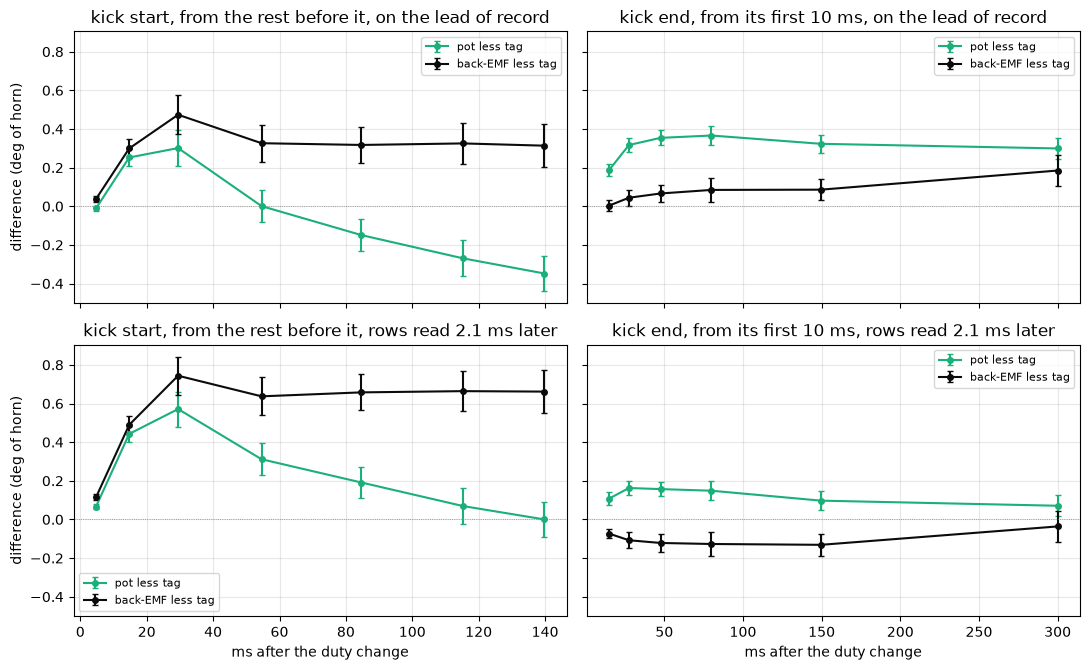

In [167]:
centers = KE_TE.groupby(["kind", "bin"])["ms"].mean()   # bin centers, ms
fig, axs = plt.subplots(2, 2, figsize=(11, 6.8), sharex="col", sharey=True)
cols = (("kick_start", "rest", ("pot-tag from rest", "bemf-tag from rest"),
         "kick start, from the rest before it"),
        ("kick_end", "+000", ("pot-tag", "bemf-tag"),
         "kick end, from its first 10 ms"))
for r_, shift in enumerate((0.0, KICK_BOUND_MS)):
    for c, (kind, ref, pairs, title) in enumerate(cols):
        ax = axs[r_, c]
        for pair, col, name in zip(pairs, (GREEN, INK),
                                   ("pot less tag", "back-EMF less tag")):
            d = KE_DISP[(KE_DISP["kind"] == kind) & (KE_DISP["pair"] == pair)
                        & (KE_DISP["ref"] == ref)]
            y = d["d"] + shift * 1e-3 * d["dv"]
            a = y.groupby(d["bin"]).agg(["mean", "std", "count"])
            x = np.array([centers[(kind, b)] for b in a.index])
            o = np.argsort(x)
            ax.errorbar(x[o], a["mean"].to_numpy()[o], yerr=(
                a["std"] / np.sqrt(a["count"])).to_numpy()[o], color=col,
                marker="o", ms=4, capsize=2, label=name)
        ax.axhline(0, **figures.EDGE_STYLE)
        lead = ("on the lead of record" if r_ == 0 else
                f"rows read {shift:.1f} ms later")
        figures.label(ax, x="ms after the duty change" if r_ else None,
                      y="difference (deg of horn)" if c == 0 else None,
                      title=f"{title}, {lead}")
        ax.legend(fontsize=8)
figures.finish(fig)

### The whole pulse

From the rest before a kick to the hold 100 to 200 ms after its end both ends are slow, so 1 ms of frame alignment is worth about 0.03 deg there and the three readings can be held against each other. The pot less the back-EMF over the pulse is the kick's part to 145 ms plus the kick end's part to 100 ms, and the hole between them goes to neither. Stage 3's lash and the crawl's direction term in the position residual are the known terms the pulse is set against.

In [168]:
net = []
for _, e in KE_EV[KE_EV["kind"] == "kick_start"].iterrows():
    e2 = f"{e['clip']}/{e['k']}/{e['seg'] + 1}/kick_end"
    a = KE_PB[(KE_PB["eid"] == e["eid"]) & (KE_PB["ms"] == 145)]["diff"]
    b = KE_PB[(KE_PB["eid"] == e2) & (KE_PB["ms"] == 100)]["diff"]
    r0 = KE_TE[(KE_TE["eid"] == e["eid"]) & (KE_TE["bin"] == "rest")]
    r1 = KE_TE[(KE_TE["eid"] == e2) & (KE_TE["bin"] == "+100")]["r_pot"]
    pt = (r1.iat[0] - r0["r_pot"].iat[0] if len(r0) and len(r1)
          else np.nan)                  # pot less tag over the pulse
    pbn = a.iat[0] + b.iat[0] if len(a) and len(b) else np.nan
    net.append(dict(eid=e["eid"], s=e["s"], pot_tag=pt, pot_bemf=pbn,
                    bemf_tag=pt - pbn, rest_sd=r0["r_sd"].mean()))
KE_NET = pd.DataFrame(net)
for c, name in (("pot_tag", "pot - tag"), ("bemf_tag", "back-EMF - tag"),
                ("pot_bemf", "pot - back-EMF")):
    kick_line(f"whole pulse, {name}", kick_stat(KE_NET[c]), "deg")
kick_line("tag at rest before a kick, sd over its frames",
          kick_stat(KE_NET["rest_sd"]), "deg",
          (KE_NET["rest_sd"].min(), KE_NET["rest_sd"].max()))
lash = POT3["lash_deg"]
dirn = COMP3["position_resid_by_dir_crawl_deg"]
print(f"stage 3: lash {lash['value']:.2f} deg [{lash['lo']:.2f}, "
      f"{lash['hi']:.2f}]; the crawl's position residual by direction "
      f"{dirn['+1']['value']:+.2f} / {dirn['-1']['value']:+.2f} deg")

whole pulse, pot - tag: +0.185 deg [+0.053, +0.317], n 38
whole pulse, back-EMF - tag: +0.421 deg [+0.214, +0.627], n 32
whole pulse, pot - back-EMF: -0.233 deg [-0.403, -0.063], n 32
tag at rest before a kick, sd over its frames: +0.015 deg [+0.006, +0.030], n 38
stage 3: lash 0.39 deg [0.15, 0.56]; the crawl's position residual by direction +0.17 / -0.18 deg


### What describes the disagreement

Three descriptions of the same numbers, none of which corrects anything. The first is a line over every transient of the settled difference (the kick start at 145 ms, the kick end at 100 ms, the rest at 100 or 200 ms) on the pot's speed change. Its slope in ms is either a delay of the pot against the back-EMF integral or an error of the back-EMF speed in proportion to the acceleration, and at constant duty the two give the same displacement. The second is the kick ends alone by hold duty, direction and place in the travel. The third is the steady holds, where the lag of the pot's speed behind the back-EMF's is read from their cross-correlation, and the change the estimate's L term makes.

In [169]:
def kick_fit(x, y):
    """Line of y on x: slope, intercept, their se, r."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    A = np.c_[x, np.ones(len(x))]
    c = np.linalg.lstsq(A, y, rcond=None)[0]
    r = y - A @ c
    cov = r @ r / (len(x) - 2) * np.linalg.inv(A.T @ A)
    return dict(n=len(x), slope=c[0], slope_se=np.sqrt(cov[0, 0]),
                intercept=c[1], intercept_se=np.sqrt(cov[1, 1]),
                r=np.corrcoef(x, y)[0, 1])


KICK_AT = {"kick_start": 145, "kick_end": 100, "pass_start": 200,
           "reversal": 200, "step": 100, "control_slow": 100,
           "control_fast": 100}         # ms, the settled checkpoint
pool = []
for eid, g in KE_PB.groupby("eid"):
    kind, e = g["kind"].iat[0], KE_EV[KE_EV["eid"] == eid].iloc[0]
    g = g.set_index("ms")
    if KICK_AT[kind] not in g.index:
        continue
    v0 = 0.0 if kind.endswith("start") else (
        e["v_pre"] if np.isfinite(e["v_pre"]) else g["rate_pot"].iloc[0])
    pool.append(dict(eid=eid, kind=kind, s=e["s"],
                     dv=g.at[KICK_AT[kind], "rate_pot"] - v0,
                     d=g.at[KICK_AT[kind], "diff"]))
KE_POOL = pd.DataFrame(pool)
tr = KE_POOL[~KE_POOL["kind"].str.startswith("control")]
KICK_LINE = {"transients": kick_fit(tr["dv"], tr["d"]),
             "with the controls": kick_fit(KE_POOL["dv"], KE_POOL["d"])}
for name, f in KICK_LINE.items():
    print(f"line, {name}: slope {f['slope'] * 1e3:+.2f} ms "
          f"[{(f['slope'] - 2 * f['slope_se']) * 1e3:+.2f}, "
          f"{(f['slope'] + 2 * f['slope_se']) * 1e3:+.2f}], intercept "
          f"{f['intercept']:+.3f} deg +/- {2 * f['intercept_se']:.3f}, "
          f"r {f['r']:+.2f}, n {f['n']}")

line, transients: slope -3.75 ms [-4.29, -3.21], intercept -0.038 deg +/- 0.077, r -0.84, n 82
line, with the controls: slope -3.72 ms [-4.19, -3.25], intercept -0.053 deg +/- 0.055, r -0.82, n 122


In [170]:
rows = []
for eid, g in KE_GRID[KE_GRID["kind"] == "kick_end"].groupby("eid"):
    g = g.sort_values("ms").set_index("ms")
    e = KE_EV[KE_EV["eid"] == eid].iloc[0]
    rows.append(dict(eid=eid, s=e["s"], after=abs(e["after"]),
                     share=e["share"], v_pre=e["v_pre"],
                     dv=g.loc[100:200, "rate_pot"].mean() - e["v_pre"],
                     d50=g.at[50, "d_pot"] - g.at[50, "d_bemf"]))
KE_KE = pd.DataFrame(rows)              # one row per kick end
f = kick_fit(KE_KE["dv"], KE_KE["d50"])
print(f"inside the kick ends alone: slope {f['slope'] * 1e3:+.1f} +/- "
      f"{f['slope_se'] * 1e3:.1f} ms, intercept {f['intercept']:+.2f} +/- "
      f"{f['intercept_se']:.2f} deg")
KE_KE["place"] = pd.cut(KE_KE["share"], [-1, 1 / 3, 2 / 3, 2],
                        labels=["low", "mid", "high"])
KE_GROUPS = {}
for col in ("after", "place"):
    for v, g in KE_KE.groupby(col, observed=True):
        KE_GROUPS[f"{col} {v}"] = kick_stat(g["d50"])
        kick_line(f"kick end to 50 ms, {col} {v}", KE_GROUPS[f"{col} {v}"],
                  "deg")
k_ = kick_stat(kick_pb("kick_start", 10)["diff"])
p_ = KE_PB[(KE_PB["kind"] == "kick_start") & (KE_PB["ms"].isin([5, 10]))]
print(f"the early kick: pot - back-EMF {k_['mean']:+.3f} deg at 10 ms; at "
      f"5 ms the motor has turned {p_[p_.ms == 5].d_bemf.mean():.2f} deg of "
      f"horn and the pot {p_[p_.ms == 5].d_pot.mean():.2f}; at 10 ms the pot "
      f"{p_[p_.ms == 10].rate_pot.mean():.0f} deg/s against "
      f"{p_[p_.ms == 10].rate_bemf.mean():.0f}")

inside the kick ends alone: slope -0.9 +/- 1.3 ms, intercept +0.31 +/- 0.17 deg
kick end to 50 ms, after 84: +0.432 deg [+0.344, +0.521], n 6
kick end to 50 ms, after 96: +0.353 deg [+0.263, +0.442], n 6
kick end to 50 ms, after 108: +0.493 deg [+0.361, +0.624], n 12
kick end to 50 ms, after 132: +0.385 deg [+0.257, +0.512], n 6
kick end to 50 ms, after 240: +0.246 deg [-0.010, +0.502], n 2
kick end to 50 ms, place low: +0.299 deg [+0.220, +0.377], n 12
kick end to 50 ms, place mid: +0.490 deg [+0.339, +0.642], n 8
kick end to 50 ms, place high: +0.493 deg [+0.415, +0.571], n 12
the early kick: pot - back-EMF -0.049 deg at 10 ms; at 5 ms the motor has turned 0.11 deg of horn and the pot 0.03; at 10 ms the pot 97 deg/s against 80


In [171]:
def kick_ripple_lag(df):
    """Per steady hold of one chain: the lag (ms, + = the pot's speed
    behind the back-EMF's) at the peak of their cross-correlation over
    10 ms speeds sampled each ms, and the correlation there."""
    out, h, L = [], 100, 40             # rows (10 ms speed), ms of lags
    for s, g in df.groupby("seg"):
        duty = g["duty_counts"].to_numpy()
        ch = np.flatnonzero(duty[1:] != duty[:-1]) + 1
        a = (ch[-1] if len(ch) else 0) + int(0.25 * FS)   # past 250 ms
        b = len(g) - int(0.03 * FS)                       # to 30 ms
        if b - a < 0.5 * FS or not g["valid"].to_numpy()[a:b].all():
            continue
        sgn = np.sign(duty[-1])
        th = g["theta_s"].to_numpy()[a:b] * sgn
        rb = potframes.centered_mean(g["rate_bemf"].to_numpy()[a:b] * sgn,
                                     potframes.BOX_ROWS)
        vp = (th[2 * h:] - th[:-2 * h]) / (2 * h / FS)
        cs = np.cumsum(np.r_[0.0, rb])
        vb = (cs[2 * h + 1:] - cs[1:-2 * h]) / (2 * h)
        n = min(len(vp), len(vb))
        vp, vb = vp[:n:20], vb[:n:20]   # 1 ms
        t = np.arange(len(vp))
        vp = vp - np.polyval(np.polyfit(t, vp, 1), t)
        vb = vb - np.polyval(np.polyfit(t, vb, 1), t)
        m = len(vp) - 2 * L
        cc = np.array([np.corrcoef(vb[L:L + m], vp[L + j:L + j + m])[0, 1]
                       for j in range(-L, L + 1)])
        i = int(np.argmax(cc))
        lag = float(i - L)
        if 0 < i < len(cc) - 1:         # a parabola through the peak
            y0, y1, y2 = cc[i - 1:i + 2]
            lag += 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)
        out.append(dict(seg=s, lag_ms=lag, corr=cc[i]))
    return out

In [172]:
KE_RIPPLE = pd.DataFrame([r for df in KICK_ROWS.values()
                          for r in kick_ripple_lag(df)])
kick_line("steady holds, the pot's speed behind the back-EMF's",
          kick_stat(KE_RIPPLE["lag_ms"]), "ms")
print(f"  {int((KE_RIPPLE['lag_ms'] > 0).sum())} of {len(KE_RIPPLE)} "
      "positive; correlations "
      f"{KE_RIPPLE['corr'].min():.1f} to {KE_RIPPLE['corr'].max():.1f}")
kick_line("  the same, correlation 0.5 or more",
          kick_stat(KE_RIPPLE[KE_RIPPLE["corr"] >= 0.5]["lag_ms"]), "ms")
lv = []
want = KE_EV[KE_EV["kind"].isin(["kick_start", "kick_end"])
             & (KE_EV["anchor"] >= 0)]
for (clip, k), es in want.groupby(["clip", "k"]):
    d0 = KICK_ROWS[(clip, k)]
    d1, _ = kick_rows(clip, k, with_l=True)     # with the L term
    for _, e in es.iterrows():
        g0 = d0[d0["seg"] == e["seg"]]["rate_bemf"].to_numpy()
        g1 = d1[d1["seg"] == e["seg"]]["rate_bemf"].to_numpy()
        ms = 145 if e["kind"] == "kick_start" else 50
        r, a = int(e["j0"] + ms * FS / 1e3), int(e["anchor"])
        lv.append(dict(kind=e["kind"], ms=ms, d=e["s"] * (
            g1[a:r + 1] - g0[a:r + 1]).sum() / FS))
for kind, g in pd.DataFrame(lv).groupby("kind"):
    kick_line(f"the back-EMF integral's change with the L term, {kind} "
              f"{g['ms'].iat[0]} ms", kick_stat(g["d"]), "deg")

steady holds, the pot's speed behind the back-EMF's: +6.788 ms [+3.924, +9.653], n 24
  22 of 24 positive; correlations 0.0 to 0.9
  the same, correlation 0.5 or more: +4.644 ms [+2.017, +7.271], n 8


the back-EMF integral's change with the L term, kick_end 50 ms: -0.016 deg [-0.017, -0.014], n 32
the back-EMF integral's change with the L term, kick_start 145 ms: +0.021 deg [+0.019, +0.023], n 38


The figure below shows the pot less the back-EMF integral through the kick's two ends, its mean and standard error over events by drive direction, with the steady hold as the control at the kick's end. Under it are the two speeds and the winding current on the same checkpoints. The left column is the kick's start from rest, the right column the kick's end into the hold.

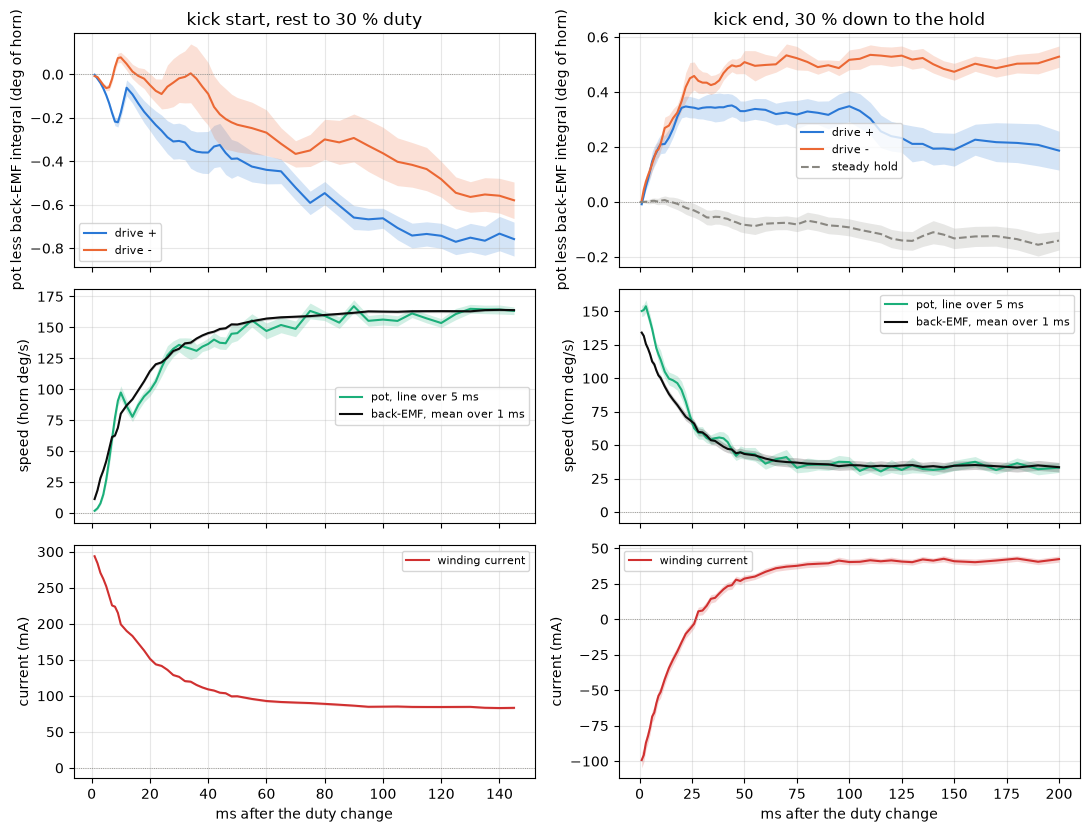

In [173]:
def kick_band(ax, d, col, color, label, scale=1.0, ls="-"):
    """Mean and se over events of col by checkpoint, as a line and band."""
    g = d.groupby("ms")[col]
    m, se = g.mean() * scale, g.std(ddof=1) / np.sqrt(g.count()) * scale
    ax.plot(m.index, m, color=color, ls=ls, label=label)
    ax.fill_between(m.index, m - se, m + se, color=color, alpha=0.2, lw=0)


fig, axs = plt.subplots(3, 2, figsize=(11, 8.4), sharex="col")
for c, (kind, xmax, title) in enumerate((
        ("kick_start", 145, "kick start, rest to 30 % duty"),
        ("kick_end", 200, "kick end, 30 % down to the hold"))):
    d = KE_GRID[(KE_GRID["kind"] == kind) & (KE_GRID["ms"] <= xmax)]
    full = d.groupby("ms")["eid"].count()
    d = d[d["ms"].isin(full[full >= 0.9 * full.max()].index)]
    for s, col, name in ((1.0, BLUE, "drive +"), (-1.0, ORANGE, "drive -")):
        kick_band(axs[0, c], d[d["s"] == s], "diff", col, name)
    if kind == "kick_end":
        k_ = KE_GRID[(KE_GRID["kind"] == "control_slow")
                     & (KE_GRID["ms"] <= xmax)]
        kick_band(axs[0, c], k_, "diff", MUTED, "steady hold", ls="--")
    kick_band(axs[1, c], d, "rate_pot", GREEN, "pot, line over 5 ms")
    kick_band(axs[1, c], d, "rate_bemf", INK, "back-EMF, mean over 1 ms")
    kick_band(axs[2, c], d, "i_w", RED, "winding current", scale=1e3)
    for ax in axs[:, c]:
        ax.axhline(0, **figures.EDGE_STYLE)
        ax.legend(fontsize=8)
    figures.label(axs[0, c], y="pot less back-EMF integral (deg of horn)",
                  title=title)
    figures.label(axs[1, c], y="speed (horn deg/s)")
    figures.label(axs[2, c], x="ms after the duty change", y="current (mA)")
figures.finish(fig)

Through the kick the pot falls 0.669 deg behind the back-EMF integral by 145 ms. At the kick's end it gains 0.419 deg back by 50 ms, 0.354 of it by 20 ms, and then stays there against the steady hold's own drift (-0.083 deg by 50 ms), for a difference to the control of +0.503 deg at 50 ms and +0.498 at 200 ms. The speeds by window put the disagreement where the current is negative. After the kick's end the pot reads +22.9 motor rev/s over the back-EMF at 2 to 5 ms (-85 mA), +16.3 at 5 to 10 ms (-63 mA) and +12.3 at 10 to 20 ms (-33 mA). From 20 ms on, where the current crosses zero, the difference is +2.9 rev/s at -4 mA and +1.3 at +20 mA, neither over 2 standard errors. In the kick's last 10 ms the two speeds agree, -2.273 rev/s with a bracket that spans zero. Through the kick the sign is the other way, -13.6 rev/s at 0 to 5 ms (+273 mA) and -5.0 at 100 to 125 ms (+85 mA). Confidence moderate for each, one sitting.

The tag pairs hold the same events against the frames. On the lead of record the pot gains +0.354 deg on the tag from the first 10 ms of the hold to 35 to 60 ms and the back-EMF integral +0.066, so the tag sides with the back-EMF and the pot is the odd one. On the same lead the pot ends the kick 0.348 deg behind the tag from rest, while the horn is driven through the pot's shaft. With the rows read 2 ms later the pot's deficit at the kick's end from rest is -0.023 deg and the kick end's two pairs read +0.170 and -0.109, half each way. At 4 ms the pot reads -0.013 and the back-EMF -0.284, and the tag sides with the pot. The shift that puts the pot level with the tag at the kick's end from rest is 2.14 ms. That is under stage 3's own alignment bound, the stamp lead's rms of 3.4 ms and the pot's lag behind the horn of 0.0 ms with a bracket of +/-3.4. The lead of record is itself fitted on the pot's motion through these transients. So which of the two the tag sides with turns on 2 ms of frame alignment, and the tag does not settle it. Confidence low for every tag pair.

Over the whole pulse, rest to the slow hold, the three agree inside stage 3's known terms. The pot less the tag is +0.185 deg, the size of the crawl's position residual by direction (+0.17 and -0.18 deg). The back-EMF less the tag is +0.421 deg, inside stage 3's lash of 0.39 deg [0.15, 0.56]. The pot less the back-EMF is -0.233 deg. Both ends are slow, and the tag stands at rest to 0.015 deg sd before a kick. Confidence moderate.

The holes are real time and not a fixed length. Before the hold they last 3.684 ms by the host stamps (2 to 12) and 3.529 ms by the pot's own continuity (2.42 to 5.692), and the two agree to -0.062 ms in the mean with an sd of 0.82 ms. The pot and the tag join across a quiet hole at a coast's start to +0.038 deg with an sd of 0.11 deg per event.

One line carries every transient. The settled pot less back-EMF on the pot's speed change has a slope of -3.75 ms [-4.29, -3.21] through an intercept of -0.038 deg, r -0.84 over 82 transients. Either the pot's angle runs 3.75 ms late against the back-EMF integral, or the back-EMF speed is off in proportion to the acceleration, and at constant duty those two give the same displacement. The kick ends alone span too little speed change to tell a constant from a proportional term (slope -0.9 +/- 1.3 ms, intercept +0.31 +/- 0.17 deg), so the kick starts, the pass starts, the reversals and the controls pin the line. The early kick does not follow it, shown next.

In [174]:
sl = KICK_LINE["transients"]["slope"]   # deg per deg/s
for ms in (10, 20):
    p = KE_PB[(KE_PB["kind"] == "kick_start") & (KE_PB["ms"] == ms)]
    print(f"kick start at {ms} ms: the line predicts "
          f"{sl * p['rate_pot'].mean():+.2f} deg, measured "
          f"{p['diff'].mean():+.3f}")

kick start at 10 ms: the line predicts -0.37 deg, measured -0.049
kick start at 20 ms: the line predicts -0.37 deg, measured -0.126


A delay of 3.75 ms would put the pot 0.37 deg behind at 10 and at 20 ms into the kick, where it is 0.049 and 0.126 deg behind. In the first 5 ms the motor has turned 0.11 deg of horn and the pot 0.03, and by 10 ms the pot is faster than the back-EMF, 97 against 80 deg/s. The kick end reads +0.490 and +0.493 deg in the middle and high thirds of the travel and +0.299 in the low third, and +0.509 for drive - against +0.330 for drive +, but this sitting places the two directions in different thirds, so it does not split direction from place. In the steady holds the pot's speed lags the back-EMF's by 6.788 ms over 24 holds (22 of them positive, 4.644 ms on the 8 with a correlation of 0.5 or more), from a crude cross-correlation of noisy speeds, so a pointer only. The estimate's L term moves the back-EMF integral by -0.016 deg at the kick's end and +0.021 at the kick's start, so it is not the gap.

In [175]:
q, KICK_U = results.quantity, "rev/s, back-EMF less pot, +/- 2 se; cause open"


def kick_q(st, unit, scale=1.0, bracket=None):
    """A mean with its +/- 2 se (or a given range) as the bounds."""
    lo, hi = ((st["mean"] - 2 * st["se"], st["mean"] + 2 * st["se"])
              if bracket is None else bracket)
    return q(st["mean"] * scale, lo * scale, hi * scale, unit)


R_S9 = {"kick_end_emf_minus_pot_rev_s": {
    w: {"emf_minus_pot": q(-sr["mean"], -sr["mean"] - 2 * sr["se"],
                           -sr["mean"] + 2 * sr["se"], KICK_U),
        "current_ma": q(si["mean"] * 1e3, unit="mA, the window's mean"),
        "n": int(sr["n"])}
    for (kind, w), (sr, si) in KE_WS.items() if kind == "kick_end"}}
R_S9["kick_start_emf_minus_pot_rev_s"] = {
    w: {"emf_minus_pot": q(-sr["mean"], -sr["mean"] - 2 * sr["se"],
                           -sr["mean"] + 2 * sr["se"], "rev/s, +/- 2 se"),
        "current_ma": q(si["mean"] * 1e3, unit="mA, the window's mean")}
    for (kind, w), (sr, si) in KE_WS.items() if kind == "kick_start"}
for kind, mss in (("kick_end", (10, 20, 50, 100, 200, 400)),
                  ("kick_start", (5, 20, 50, 100, 145)),
                  ("control_slow", (50, 100, 200))):
    R_S9[f"{kind}_pot_minus_emf_deg"] = {
        f"{ms}_ms": kick_q(kick_stat(kick_pb(kind, ms)["diff"]),
                           "deg of horn, +/- 2 se") for ms in mss}
print(len(R_S9), "keys so far")

5 keys so far


In [176]:
R_S9["kick_end_less_steady_hold_deg"] = {}
for ms in (50, 100, 200):
    k_, c_ = (kick_stat(kick_pb(x, ms)["diff"])
              for x in ("kick_end", "control_slow"))
    R_S9["kick_end_less_steady_hold_deg"][f"{ms}_ms"] = kick_q(
        dict(mean=k_["mean"] - c_["mean"], se=np.hypot(k_["se"], c_["se"])),
        "deg of horn, +/- 2 se")
R_S9["whole_pulse_deg"] = {
    c: kick_q(kick_stat(KE_NET[c]), "deg of horn, +/- 2 se")
    for c in ("pot_tag", "bemf_tag", "pot_bemf")}
R_S9["kick_holes_ms"] = {
    "host_stamps": kick_q(kick_stat(ke["host_gap_ms"]), "ms, range",
                          bracket=(ke["host_gap_ms"].min(),
                                   ke["host_gap_ms"].max())),
    "pot_continuity": kick_q(kick_stat(ke["hole_pot_ms"]), "ms, range",
                             bracket=(ke["hole_pot_ms"].min(),
                                      ke["hole_pot_ms"].max())),
    "pot_less_stamps": kick_q(dh, "ms, +/- 2 se")}
f = KICK_LINE["transients"]
R_S9["kick_line_over_transients"] = {
    "slope_ms": q(f["slope"] * 1e3, (f["slope"] - 2 * f["slope_se"]) * 1e3,
                  (f["slope"] + 2 * f["slope_se"]) * 1e3,
                  "ms (deg per deg/s), +/- 2 se"),
    "intercept_deg": q(f["intercept"], f["intercept"] - 2 * f["intercept_se"],
                       f["intercept"] + 2 * f["intercept_se"], "deg"),
    "r": float(f["r"]), "n": int(f["n"])}
R_S9["kick_tag_alignment_bound_ms"] = q(
    KICK_BOUND_MS, unit="ms, the rows' shift that levels the pot with the "
    "tag at the kick's end from rest; stage 3's stamp lead rms "
    f"{KICK_FLOOR_MS:.2f} ms")
early = [-KE_WS[("kick_end", w)][0]["mean"]
         for w in ("002-005", "005-010", "010-020")]
STAGE5_S9 = {"window_ms": "0 to 30 after a hard deceleration",
             "emf_minus_pot_rev_s": [min(early), max(early)],
             "which_is_right": "open"}
print(f"stage 5: back-EMF less pot {min(early):+.1f} to {max(early):+.1f} "
      "rev/s over the first 20 ms after a kick's end, cause open")
print(len(R_S9), "keys in section 9")

stage 5: back-EMF less pot -22.9 to -12.3 rev/s over the first 20 ms after a kick's end, cause open
10 keys in section 9


### The commutation count through the kick

The motor's own shaft can be read without the pot and without the back-EMF's resistance term, by counting the commutation ripple of the winding current. Each commutation period is one sixth of a motor revolution, so a count of periods is a motor-side displacement. The count here is a phase. Around each center row, every 4 rows, the current is fitted with a constant, a slope and one sinusoid at one cycle per commutation period of a seed angle, tapered over one cycle either side. The sinusoid's phase against the seed, unwrapped along the centers and added to the seed, is the ripple's own phase in cycles. Two more passes read the current on the phase the last pass counted, smoothed over 5 ms, so the seed only has to keep the first pass from slipping a cycle (`ripple.PhaseCount`). A displacement is the phase's change between two rows times the commutation period in degrees of horn. No crossing is repaired.

The signal is the current's crest sample less the tracked zero, inside one segment and one stretch of constant duty, from the current's L / R rise after the duty change on. The seed is the back-EMF integral where it is valid over the whole stretch and the pot otherwise, through a 20 ms quadratic (`ripple.angle_seed`). The second seed, where both exist, is a second way of counting the same rows, and so are the library's order count on the counted angle (`ripple.order_crossing_rows`) and, on drive + kicks, the sharp fall of the current at each commutation.

In [177]:
CNT_CYCLE = 360.0 / (N_R * GEAR)    # deg of horn per commutation period
CNT_GATE_STEP = 0.25    # cycles, the phase against the seed between two
#                         centers at most (the unwrap fails at 0.5)
CNT_GATE_TWO_WAYS = 0.25    # cycles, two counts of one window at most
CNT_GATE_CONV = 0.05    # cycles, the last pass less the one before
CNT_GATE_SNR = 0.5      # the sinusoid's amplitude over the fit's residual,
#                         the least over a window; set after the other four
CNT_KICK_MS = (10, 20, 30, 50, 100, 145)    # ms, a kick start's windows
CNT_END_MS = (10, 20, 30, 50, 100)          # ms, a kick end's and a hold's
CNT_LAST_MS = 50        # ms, the kick's last, a control
CNT_PAD = 2400          # rows of the hold kept either side of a control
CNT_DROP = 12           # counts, a sharp fall of the current in one row
CNT_DROP_MERGE = 3      # rows, falls this close are one
CNT_LIB_SKIP = 2        # the order count's first crossings, on its edge
print(f"{N_R} periods per motor rev, gear {GEAR:.4f}: {CNT_CYCLE:.5f} deg "
      f"of horn per period; the other ratio would make it "
      f"{GEAR / GEAR_COMM - 1:.2%} longer; rise {ripple.RISE_ROWS} rows")
for (clip, k), df in KICK_ROWS.items():         # the zero each row used
    r = CHAINS[(CHAINS["clip"] == clip) & (CHAINS["k"] == k)].iloc[0]
    df["zero"] = Z[int(r.i0):int(r.i1)]

6 periods per motor rev, gear 308.0533: 0.19477 deg of horn per period; the other ratio would make it 0.50% longer; rise 20 rows


In [178]:
def cnt_end(duty, j0):
    """The row the duty first changes after j0 (the stretch's end)."""
    later = np.flatnonzero(duty[j0:] != duty[j0])
    return j0 + (later[0] if len(later) else len(duty) - j0)


def cnt_stretch(kind, j0, duty, rise):
    """(lo, hi): the rows counted, from `rise` after the duty change."""
    end = cnt_end(duty, j0)
    if kind.startswith("control"):
        before = np.flatnonzero(duty[:j0] != duty[j0])
        first = (before[-1] + 1 if len(before) else 0) + rise
        return max(first, j0 - CNT_PAD), min(end, j0 + 2000 + CNT_PAD)
    hi = end if kind == "kick_start" else min(end, j0 + 2000 + CNT_PAD)
    return j0 + rise, hi


def cnt_bemf(g, s, anchor, end):
    """Deg of horn along s from the anchor, NaN before it, and NaN
    everywhere if a row from it to `end` is not valid."""
    cum = np.full(len(g), np.nan)
    if anchor >= 0 and g["valid"].to_numpy()[anchor:end].all():
        rb = s * g["rate_bemf"].to_numpy()
        cum[anchor:end] = np.cumsum(rb[anchor:end]) / FS
        cum[anchor:end] -= cum[anchor]
    return cum

In [179]:
def cnt_drops(x, lo, hi):
    """(rows, margin): the rows where the current falls CNT_DROP or more
    in one row, the steepest of each run, and the gap in counts between
    the smallest fall taken and the largest left."""
    d = np.diff(x[lo:hi])
    k = np.flatnonzero(d < -CNT_DROP)
    if len(k) == 0:
        return k.astype(float), np.nan
    first = np.r_[True, np.diff(k) > CNT_DROP_MERGE]
    groups = np.split(k, np.flatnonzero(first[1:]) + 1)
    rows = np.array([gr[np.argmin(d[gr])] for gr in groups])
    left = np.ones(len(d), bool)
    for gr in groups:
        left[gr[0] - 1:gr[-1] + 2] = False
    return rows + lo + 0.5, float(-d[rows].max() - (-d[left].min()))


def cnt_pattern(g, x, lo, hi):
    """The board's 16-row pattern in the stretch, peak to peak (counts)."""
    r = x[lo:hi] - potframes.centered_mean(x[lo:hi], 33)
    ph16 = g["tick"].to_numpy()[lo:hi] % 16
    fold = np.array([r[ph16 == q].mean() for q in range(16)])
    return float(fold.max() - fold.min())

In [180]:
def cnt_counts(g, x, th, cum_b, lo, hi):
    """(first, second, library rows, seed): the count seeded by the back-EMF
    integral where it is valid (else the pot), the other seed's count,
    the order count's crossings on the first count's angle."""
    c_pot = ripple.PhaseCount(x, ripple.angle_seed(th, CNT_CYCLE), lo, hi)
    c_emf = None
    if np.isfinite(cum_b[lo:hi]).all():
        c_emf = ripple.PhaseCount(x, cum_b / CNT_CYCLE, lo, hi)
        c_emf = c_emf if c_emf.ok else None
    first, second = (c_emf, c_pot) if c_emf is not None else (c_pot, None)
    seed = "bemf" if c_emf is not None else "pot"
    if not first.ok:
        return first, None, np.array([]), seed
    second = second if second is not None and second.ok else None
    a, b = int(first.c[0]), int(first.c[-1])
    lib = np.array([])
    if first.phi_c[-1] - first.phi_c[0] > 2 * CNT_LIB_SKIP + 3:
        lib = ripple.order_crossing_rows(
            x, first.phi(np.arange(a, b + 1)), 0, b + 1 - a, N_R, offset=a)
    lib = (lib[CNT_LIB_SKIP:-CNT_LIB_SKIP] if len(lib) > 2 * CNT_LIB_SKIP + 2
           else np.array([]))
    return first, second, lib, seed

In [181]:
def cnt_drop_rec(first, drops, margin, j0):
    """The drops against the count: one per whole number of the phase."""
    dd = drops[(drops >= first.c[0]) & (drops <= first.c[-1])]
    ph = first.phi(dd)
    k = np.round(ph - np.median(ph - np.round(ph)))
    frac = ph - k
    return dict(drops=len(dd), drop_margin=margin,
                drops_missing=int(k[-1] - k[0] + 1 - len(np.unique(k))),
                drops_double=int(len(k) - len(np.unique(k))),
                drop_frac_early=float(np.median(frac[:10])),
                drop_frac_late=float(np.median(frac[-10:])),
                drop_frac_sd=float(np.std(frac)),
                first_drop_ms=((drops[0] - j0) / FS * 1e3 if len(drops)
                               else np.nan))


def cnt_other_ways(w, first, second, lib, drops, a, b, pb):
    """The same window counted by the second seed, the order count and
    the drops, each less the first count (cycles)."""
    if second is not None:
        a2 = max(a, int(second.c[0]))
        qa, qb = second.phi([a2, b])
        if np.isfinite(qa) and np.isfinite(qb) and a2 < b:
            w["two_seed"] = (qb - qa) - (pb - first.phi([a2])[0])
    if len(lib) > 3:
        la = max(a, lib[0])
        if lib[-1] >= b and la < b:
            lj = np.arange(len(lib), dtype=float)
            w["lib"] = ((np.interp(b, lib, lj) - np.interp(la, lib, lj))
                        - (pb - first.phi([la])[0]))
    if len(drops) > 3 and w["ms"] > 0 and w["kind"] == "kick_start":
        dj = np.arange(len(drops), dtype=float)
        da = drops[drops >= a][0]
        if drops[-1] >= b:
            w["drops"] = (np.interp(b, drops, dj) - np.interp(da, drops, dj)
                          - (pb - first.phi([da])[0]))
    return w

In [182]:
def cnt_windows(e, g, first, second, lib, drops, th, cum_b, x, r0, j0):
    """Per window: the count, the pot and the back-EMF integral (deg)."""
    kind, s = e["kind"], e["s"]
    ms_list = (CNT_END_MS if kind != "kick_start" else CNT_KICK_MS)
    spans = [(int(ms), r0, j0 + int(round(ms * FS / 1e3))) for ms in ms_list]
    if kind == "kick_start":
        r1 = int(first.c[-1])
        spans.append((-CNT_LAST_MS, r1 - int(CNT_LAST_MS * FS / 1e3), r1))
    wins, bad = [], []
    near = g["near"].to_numpy()
    duty = int(g["duty_counts"].to_numpy()[j0])
    for ms, a, b in spans:
        pa, pb = first.phi([a, b])
        if not (np.isfinite(pa) and np.isfinite(pb)):
            bad.append(f"{ms} ms: an end outside the counted rows")
            continue
        w = dict(eid=e["eid"], kind=kind if ms > 0 else "kick_last",
                 near_rows=int(near[a:b + 1].sum()), s=s, duty=duty,
                 ms=abs(ms), r0=a, r1=b, d_count=(pb - pa) * CNT_CYCLE,
                 d_pot=th[b] - th[a], d_bemf=cum_b[b] - cum_b[a],
                 i_end=float(x[max(a, b - 10):b + 10].mean()),
                 step=first.max_step(a, b), snr=first.min_snr(a, b))
        wins.append(cnt_other_ways(w, first, second, lib, drops, a, b, pb))
    return wins, "; ".join(bad)

In [183]:
def cnt_event(e, g, rise=ripple.RISE_ROWS):
    """(record, windows, the first count) of one event."""
    kind, s, j0 = e["kind"], e["s"], int(e["j0"])
    duty = g["duty_counts"].to_numpy()
    lo, hi = cnt_stretch(kind, j0, duty, rise)
    x = g["current_raw"].to_numpy(float) - g["zero"].to_numpy(float)
    th = s * g["theta_s"].to_numpy()
    cum_b = cnt_bemf(g, s, lo if kind.startswith("control")
                     else int(e["anchor"]), cnt_end(duty, j0))
    rec = dict(eid=e["eid"], kind=kind, s=s, duty=int(duty[j0]), j0=j0,
               lo=lo, hi=hi, keep=False, why="",
               pat16_pp=cnt_pattern(g, x, lo, hi))
    first, second, lib, seed = cnt_counts(g, x, th, cum_b, lo, hi)
    if not first.ok:
        rec["why"] = ("no count: the seed moves under two commutation "
                      "periods in the stretch (a stall or a creep)")
        return rec, [], None
    drops, margin = (cnt_drops(x, lo, hi) if kind == "kick_start" and s > 0
                     else (np.array([]), np.nan))
    r0 = j0 if kind.startswith("control") else int(first.c[0])
    rec.update(r0=r0, start_ms=(r0 - j0) / FS * 1e3, conv=first.conv,
               amp_med=float(np.median(first.amp)),
               seed=seed, seeds=1 + (second is not None))
    if kind != "control_slow" and int(e["anchor"]) >= 0:
        an = int(e["anchor"])           # what the count does not see
        rec.update(pre_pot=th[r0] - th[an], pre_bemf=cum_b[r0] - cum_b[an])
    if len(drops):
        rec.update(cnt_drop_rec(first, drops, margin, j0))
    wins, rec["bad_windows"] = cnt_windows(e, g, first, second, lib, drops,
                                           th, cum_b, x, r0, j0)
    return rec, wins, first

An event is kept or dropped on the count's own numbers, never on the pot or the back-EMF. It is dropped when the phase against the seed steps over 0.25 cycle between two centers, when two counts of one window differ by over 0.25 cycle (the second seed, the order count or the drops), when the last pass moves over 0.05 cycle from the one before, when a window's end falls outside the counted rows, or when the ripple's amplitude falls under 0.5 of the fit's residual. The first four were set before any comparison with the pot or the back-EMF was computed. The amplitude gate was added afterwards, when a stalled hold was seen to pass the other four, and it removed that one hold.

In [184]:
def cnt_gate(rec, wins):
    """Keep or drop an event on the count's own numbers."""
    if rec["why"]:
        return
    if not wins:
        rec["why"] = ("no window inside the counted rows: "
                      + rec["bad_windows"])
        return
    w = pd.DataFrame(wins)

    def worst(col):
        return float(w[col].abs().max()) if col in w else np.nan
    rec.update(step_max=worst("step"), snr_min=float(w["snr"].min()),
               two_seed_max=worst("two_seed"), lib_max=worst("lib"),
               drops_max=worst("drops"))
    why = []
    if rec["step_max"] > CNT_GATE_STEP:
        why.append(f"phase step {rec['step_max']:.2f} cycles between centers")
    if rec["snr_min"] < CNT_GATE_SNR:
        why.append(f"no ripple: amplitude {rec['snr_min']:.2f} of the fit's "
                   "residual")
    if rec["conv"] > CNT_GATE_CONV:
        why.append(f"passes differ {rec['conv']:.2f} cycles")
    for col, name in (("two_seed_max", "two seeds"),
                      ("lib_max", "library count"),
                      ("drops_max", "drop count")):
        if rec[col] > CNT_GATE_TWO_WAYS:
            why.append(f"{name} differ{'s' if col != 'two_seed_max' else ''} "
                       f"{rec[col]:.2f} cycles")
    if rec.get("drops_missing", 0) or rec.get("drops_double", 0):
        why.append(f"drops: {rec['drops_missing']} missing, "
                   f"{rec['drops_double']} double")
    if rec["bad_windows"]:
        why.append(rec["bad_windows"])
    rec["why"], rec["keep"] = "; ".join(why), not why
    rec["keep_loose"] = rec["keep"] or (       # only the second seed failed
        len(why) == 1 and why[0].startswith("two seeds differ"))
    rec["near_rows"] = int(w["near_rows"].max())

In [185]:
def cnt_run(rise=ripple.RISE_ROWS):
    """(events, windows) of every kick start, kick end and steady hold."""
    ev = KE_EV[KE_EV["kind"].isin(["kick_start", "kick_end",
                                   "control_slow"])]
    recs, wins = [], []
    for (clip, k), es in ev.groupby(["clip", "k"], sort=False):
        df = KICK_ROWS[(clip, int(k))]
        parts = {s: g.reset_index(drop=True) for s, g in df.groupby("seg")}
        for _, e in es.iterrows():
            rec, w, _ = cnt_event(e, parts[int(e["seg"])], rise)
            cnt_gate(rec, w)
            for row in w:
                row.update(keep=rec["keep"],
                           keep_loose=rec.get("keep_loose", False),
                           seed=rec.get("seed", ""))
            recs.append(rec)
            wins += w
    return pd.DataFrame(recs), pd.DataFrame(wins)


CNT_EV, CNT_WIN = cnt_run()
print(CNT_EV.groupby("kind")["keep"].agg(["size", "sum"]).to_string())
print(f"dropped {int((~CNT_EV['keep']).sum())} of {len(CNT_EV)}")
for r in CNT_EV[~CNT_EV["keep"]].itertuples():
    print(" dropped", r.eid, "|", r.why[:110])

              size  sum
kind                   
control_slow    38   27
kick_end        38   31
kick_start      38   38
dropped 18 of 114
 dropped crawl-0-0/0/2/control_slow | no count: the seed moves under two commutation periods in the stretch (a stall or a creep)
 dropped crawl-0-0/0/5/control_slow | no count: the seed moves under two commutation periods in the stretch (a stall or a creep)
 dropped crawl-0-0/1/2/control_slow | no ripple: amplitude 0.25 of the fit's residual
 dropped crawl-0-0/2/2/control_slow | no count: the seed moves under two commutation periods in the stretch (a stall or a creep)
 dropped crawl-1-0/5/2/control_slow | no count: the seed moves under two commutation periods in the stretch (a stall or a creep)
 dropped crawl-1-0/5/5/control_slow | no window inside the counted rows: 10 ms: an end outside the counted rows; 20 ms: an end outside the counted r
 dropped crawl-2-0/10/5/kick_end | phase step 0.43 cycles between centers; no ripple: amplitude 0.05 of the fit

The count, the pot and the back-EMF integral are read over exactly the same rows, from the first counted row (a hold's from the control's row) to the rows 10 to 145 ms after the duty change. Each window's difference is averaged over events with a bracket of +/- 2 se, by kind and drive direction. The kick's last 50 ms ends at the last counted row of the kick.

In [186]:
def cnt_stat(x):
    """n, mean, se, sd, the +/- 2 se bracket and t of the finite x."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    n = len(x)
    if n < 2:
        return dict(n=n, mean=np.nan, se=np.nan, sd=np.nan, lo=np.nan,
                    hi=np.nan, t=np.nan)
    m, sd = x.mean(), x.std(ddof=1)
    se = sd / np.sqrt(n)
    return dict(n=n, mean=m, se=se, sd=sd, lo=m - 2 * se, hi=m + 2 * se,
                t=m / se)


def cnt_ratio(gd, den):
    """The ratio of the sums with the se of the per-event ratios."""
    ok = np.isfinite(gd[den])
    st = cnt_stat(gd["d_count"][ok] / gd[den][ok])
    st["mean"] = gd["d_count"][ok].sum() / gd[den][ok].sum()
    st["lo"], st["hi"] = st["mean"] - 2 * st["se"], st["mean"] + 2 * st["se"]
    return st

In [187]:
CNT_Q = ("count_pot", "count_bemf", "pot_bemf")


def cnt_groups(w, set_name):
    """Every window's three differences and two ratios, by direction."""
    out = []
    w = w.assign(count_pot=w["d_count"] - w["d_pot"],
                 count_bemf=w["d_count"] - w["d_bemf"],
                 pot_bemf=w["d_pot"] - w["d_bemf"])
    for (kind, ms), g in w.groupby(["kind", "ms"]):
        for d, gd in (("both", g), ("+", g[g["s"] > 0]),
                      ("-", g[g["s"] < 0])):
            for q in CNT_Q + ("d_count", "d_pot", "d_bemf", "i_end"):
                out.append(dict(set=set_name, kind=kind, ms=ms, dir=d,
                                quantity=q, **cnt_stat(gd[q])))
            for q, den in (("ratio_count_pot", "d_pot"),
                           ("ratio_count_bemf", "d_bemf")):
                out.append(dict(set=set_name, kind=kind, ms=ms, dir=d,
                                quantity=q, **cnt_ratio(gd, den)))
    return out

In [188]:
def cnt_less_hold(w):
    """The kick's end less the steady hold of the same segment."""
    k = w[w["keep"] & (w["kind"] == "kick_end")].copy()
    c = w[w["keep"] & (w["kind"] == "control_slow")].copy()
    for t in (k, c):
        t["seg_id"] = t["eid"].str.rsplit("/", n=1).str[0]
    m = k.merge(c, on=["seg_id", "ms"], suffixes=("", "_c"))
    out = []
    for q, a, b in (("count_pot", "d_count", "d_pot"),
                    ("count_bemf", "d_count", "d_bemf"),
                    ("pot_bemf", "d_pot", "d_bemf")):
        m[q] = (m[a] - m[b]) - (m[a + "_c"] - m[b + "_c"])
    for ms, g in m.groupby("ms"):
        for q in CNT_Q:
            out.append(dict(set="kept", kind="kick_end less hold", ms=ms,
                            dir="both", quantity=q, **cnt_stat(g[q])))
    k = w[w["keep"] & (w["kind"] == "kick_end")]
    for lo_ms, hi_ms in ((10, 30), (30, 100), (50, 100)):
        a = k[k["ms"] == lo_ms].set_index("eid")
        b = k[k["ms"] == hi_ms].set_index("eid")
        d = (b[["d_count", "d_pot", "d_bemf"]]
             - a[["d_count", "d_pot", "d_bemf"]])
        for q, x, y in (("count_pot", "d_count", "d_pot"),
                        ("count_bemf", "d_count", "d_bemf"),
                        ("pot_bemf", "d_pot", "d_bemf")):
            out.append(dict(set="kept", kind=f"kick_end from {lo_ms} ms",
                            ms=hi_ms, dir="both", quantity=q,
                            **cnt_stat(d[x] - d[y])))
    return out

In [189]:
def cnt_summary(w):
    """Every group of the kept events and the two variants."""
    rows = cnt_groups(w[w["keep"]], "kept")
    rows += cnt_groups(w[w["keep_loose"]], "kept + second-seed drops")
    rows += cnt_groups(w[w["keep"] & (w["near_rows"] == 0)],
                       "kept, no carry code")
    return pd.DataFrame(rows + cnt_less_hold(w))


def cnt_show(sm, set_name, kind, qs, dirs=("both",), ms=None):
    m = sm[(sm["set"] == set_name) & (sm["kind"] == kind)
           & sm["quantity"].isin(qs) & sm["dir"].isin(dirs)]
    if ms is not None:
        m = m[m["ms"].isin(ms)]
    for _, r in m.iterrows():
        print(f"  {kind:12s} {int(r['ms']):4d} ms {r['dir']:4s} "
              f"{r['quantity']:16s} {r['mean']:+.3f} [{r['lo']:+.3f}, "
              f"{r['hi']:+.3f}] sd {r['sd']:.3f} n {int(r['n'])}")


CNT_SM = cnt_summary(CNT_WIN)
kept = CNT_EV[CNT_EV["keep"]]
print("kept:", kept.groupby("kind").size().to_dict(), "of",
      CNT_EV.groupby("kind").size().to_dict(), "; seeds:",
      kept.groupby(["kind", "seed"]).size().to_dict())

kept: {'control_slow': 27, 'kick_end': 31, 'kick_start': 38} of {'control_slow': 38, 'kick_end': 38, 'kick_start': 38} ; seeds: {('control_slow', 'bemf'): 25, ('control_slow', 'pot'): 2, ('kick_end', 'bemf'): 26, ('kick_end', 'pot'): 5, ('kick_start', 'bemf'): 38}


First the controls, where the answer is known. On a steady hold the count, the pot and the back-EMF integral should agree, and on the kick's last 50 ms the motor turns steadily at speed.

In [190]:
print("steady hold (deg of horn over the window):")
cnt_show(CNT_SM, "kept", "control_slow",
         ("count_pot", "count_bemf", "d_count", "ratio_count_pot"))
print("the kick's last 50 ms:")
cnt_show(CNT_SM, "kept", "kick_last",
         CNT_Q + ("d_count", "ratio_count_pot", "ratio_count_bemf"),
         ("both", "+", "-"))

steady hold (deg of horn over the window):
  control_slow   10 ms both count_pot        -0.025 [-0.052, +0.002] sd 0.071 n 27
  control_slow   10 ms both count_bemf       -0.009 [-0.012, -0.007] sd 0.006 n 25
  control_slow   10 ms both d_count          +0.283 [+0.246, +0.320] sd 0.096 n 27
  control_slow   10 ms both ratio_count_pot  +0.919 [+0.832, +1.005] sd 0.224 n 27
  control_slow   20 ms both count_pot        -0.032 [-0.076, +0.011] sd 0.113 n 27
  control_slow   20 ms both count_bemf       -0.018 [-0.022, -0.013] sd 0.011 n 25
  control_slow   20 ms both d_count          +0.564 [+0.490, +0.637] sd 0.191 n 27
  control_slow   20 ms both ratio_count_pot  +0.946 [+0.867, +1.024] sd 0.203 n 27
  control_slow   30 ms both count_pot        -0.013 [-0.061, +0.034] sd 0.124 n 27
  control_slow   30 ms both count_bemf       -0.026 [-0.032, -0.019] sd 0.017 n 25
  control_slow   30 ms both d_count          +0.848 [+0.736, +0.959] sd 0.290 n 27
  control_slow   30 ms both ratio_count_pot 

In [191]:
for kind in ("kick_end", "kick_start"):
    print(f"{kind} (deg of horn from the first counted row):")
    cnt_show(CNT_SM, "kept", kind, CNT_Q + ("d_count", "i_end"))
print("by direction at the headline windows:")
cnt_show(CNT_SM, "kept", "kick_end", CNT_Q, ("+", "-"), ms=[50])
cnt_show(CNT_SM, "kept", "kick_start", CNT_Q, ("+", "-"), ms=[145])
print("the kick's end less the steady hold of the same segment, and "
      "between two windows:")
for kd in CNT_SM["kind"].unique():
    if kd.startswith("kick_end less") or kd.startswith("kick_end from"):
        cnt_show(CNT_SM, "kept", kd, CNT_Q)

kick_end (deg of horn from the first counted row):
  kick_end       10 ms both count_pot        -0.030 [-0.072, +0.012] sd 0.117 n 31
  kick_end       10 ms both count_bemf       +0.130 [+0.118, +0.141] sd 0.029 n 26
  kick_end       10 ms both pot_bemf         +0.149 [+0.104, +0.193] sd 0.113 n 26
  kick_end       10 ms both d_count          +0.964 [+0.935, +0.992] sd 0.079 n 31
  kick_end       10 ms both i_end            -35.274 [-44.657, -25.890] sd 26.123 n 31
  kick_end       20 ms both count_pot        -0.069 [-0.115, -0.022] sd 0.129 n 31
  kick_end       20 ms both count_bemf       +0.222 [+0.199, +0.244] sd 0.057 n 26
  kick_end       20 ms both pot_bemf         +0.289 [+0.239, +0.339] sd 0.128 n 26
  kick_end       20 ms both d_count          +1.901 [+1.827, +1.975] sd 0.205 n 31
  kick_end       20 ms both i_end            +3.858 [-3.457, +11.173] sd 20.364 n 31
  kick_end       30 ms both count_pot        -0.056 [-0.101, -0.011] sd 0.125 n 31
  kick_end       30 ms both co

In [192]:
CNT_PER = []                            # per-event numbers of the kept
for kind, g in kept.groupby("kind"):
    for q_ in ("start_ms", "pre_pot", "pre_bemf", "conv", "step_max",
               "two_seed_max", "lib_max", "drops_max", "snr_min", "amp_med",
               "pat16_pp", "drop_frac_sd", "drop_margin", "first_drop_ms"):
        if q_ in g and g[q_].notna().sum() > 1:
            CNT_PER.append(dict(kind=kind, quantity=q_, **cnt_stat(g[q_]),
                                min=g[q_].min(), max=g[q_].max()))
    if kind != "control_slow":
        CNT_PER.append(dict(kind=kind, quantity="pre_pot_less_bemf",
                            **cnt_stat(g["pre_pot"] - g["pre_bemf"])))
    if g.get("drop_frac_late") is not None and g[
            "drop_frac_late"].notna().sum() > 1:
        CNT_PER.append(dict(kind=kind, quantity="drop_frac_late_less_early",
                            **cnt_stat(g["drop_frac_late"]
                                       - g["drop_frac_early"])))
CNT_PER = pd.DataFrame(CNT_PER)
print(CNT_PER[["kind", "quantity", "n", "mean", "lo", "hi", "min", "max"]]
      .round(3).to_string(index=False))

        kind                  quantity  n   mean     lo     hi    min    max
control_slow                  start_ms 27  0.000  0.000  0.000  0.000  0.000
control_slow                      conv 27  0.007  0.005  0.010  0.002  0.029
control_slow                  step_max 27  0.001  0.001  0.001  0.001  0.002
control_slow              two_seed_max 25  0.045  0.039  0.051  0.020  0.081
control_slow                   lib_max 27  0.045  0.038  0.051  0.016  0.086
control_slow                   snr_min 27  3.108  2.853  3.364  2.060  4.472
control_slow                   amp_med 27  8.413  7.647  9.179  4.888 11.728
control_slow                  pat16_pp 27  1.251  1.205  1.296  0.994  1.496
    kick_end                  start_ms 31  2.548  2.496  2.601  2.200  2.800
    kick_end                   pre_pot 26  0.322  0.302  0.343  0.233  0.441
    kick_end                  pre_bemf 26  0.265  0.258  0.273  0.233  0.300
    kick_end                      conv 31  0.009  0.006  0.011  0.001  0.032

In [193]:
two = CNT_EV["why"].fillna("").str.contains("two seeds differ")
print(f"a carry code inside a window: {int((CNT_EV[two]['near_rows'] > 0)
      .sum())} of {int(two.sum())} second-seed drops, "
      f"{int((kept[kept['seeds'] == 2]['near_rows'] > 0).sum())} of "
      f"{int((kept['seeds'] == 2).sum())} kept with two seeds")
cnt_dr = kept[kept["kind"] == "kick_start"].dropna(subset=["drops"])
print(f"sharp falls, drive + kicks: {len(cnt_dr)} events, missing "
      f"{int(cnt_dr.drops_missing.sum())}, double "
      f"{int(cnt_dr.drops_double.sum())}; worst count by the falls "
      f"{cnt_dr.drops_max.max():.2f} cycle")
print("variants at the headline windows:")
for st in ("kept + second-seed drops", "kept, no carry code"):
    print(" ", st)
    for kind, ms in (("kick_end", 50), ("kick_start", 145)):
        cnt_show(CNT_SM, st, kind, ("count_pot", "count_bemf"), ms=[ms])

a carry code inside a window: 7 of 11 second-seed drops, 21 of 89 kept with two seeds
sharp falls, drive + kicks: 19 events, missing 0, double 0; worst count by the falls 0.10 cycle
variants at the headline windows:
  kept + second-seed drops
  kick_end       50 ms both count_pot        -0.091 [-0.138, -0.044] sd 0.143 n 37
  kick_end       50 ms both count_bemf       +0.282 [+0.252, +0.312] sd 0.086 n 32
  kick_start    145 ms both count_pot        +0.483 [+0.372, +0.594] sd 0.342 n 38
  kick_start    145 ms both count_bemf       -0.090 [-0.131, -0.049] sd 0.127 n 38
  kept, no carry code
  kick_end       50 ms both count_pot        -0.130 [-0.176, -0.084] sd 0.113 n 24
  kick_end       50 ms both count_bemf       +0.257 [+0.212, +0.301] sd 0.097 n 19
  kick_start    145 ms both count_pot        +0.464 [+0.324, +0.605] sd 0.373 n 28
  kick_start    145 ms both count_bemf       -0.091 [-0.146, -0.036] sd 0.145 n 28


The count starts 20 rows after the duty change, the current's L / R rise, and one cycle more for the fit's window. Starting it at 40 rows instead is a check that the rise does not leak into the count.

In [194]:
ev40, win40 = cnt_run(rise=40)
CNT_SM40 = cnt_summary(win40)
print(f"40 rows after the change: kept {int(ev40['keep'].sum())} of "
      f"{len(ev40)}")
cnt_show(CNT_SM40, "kept", "kick_end", ("count_pot", "count_bemf"), ms=[50])
cnt_show(CNT_SM40, "kept", "kick_start", ("count_pot", "count_bemf"),
         ms=[145])

40 rows after the change: kept 96 of 114
  kick_end       50 ms both count_pot        -0.087 [-0.131, -0.043] sd 0.123 n 31
  kick_end       50 ms both count_bemf       +0.252 [+0.218, +0.287] sd 0.087 n 26
  kick_start    145 ms both count_pot        +0.485 [+0.375, +0.596] sd 0.339 n 38
  kick_start    145 ms both count_bemf       -0.088 [-0.129, -0.047] sd 0.127 n 38


What you are looking at: one kick end, the kept drive + event nearest the median count less back-EMF. Top, the winding current (counts, the crest sample less its zero) from the kick's tail through the hole and the duty change into the hold, a dot on each counted commutation period, the kick and the hold each counted on their own and the hole left empty. Bottom, that event's count less the pot and less the back-EMF integral, degrees of horn from the first counted row, with one commutation period marked.

In [195]:
k50 = CNT_WIN[CNT_WIN["keep"] & (CNT_WIN["kind"] == "kick_end")
              & (CNT_WIN["ms"] == 50) & CNT_WIN["d_bemf"].notna()
              & (CNT_WIN["s"] > 0)]
dcb = k50["d_count"] - k50["d_bemf"]
CNT_EID = k50.loc[(dcb - dcb.median()).abs().idxmin(), "eid"]
e1 = KE_EV[KE_EV["eid"] == CNT_EID].iloc[0]
parts = {s: g.reset_index(drop=True)
         for s, g in KICK_ROWS[(e1["clip"], int(e1["k"]))].groupby("seg")}
g1, p1 = parts[int(e1["seg"])], parts[int(e1["seg"]) - 1]
ks = KE_EV[(KE_EV["clip"] == e1["clip"]) & (KE_EV["k"] == e1["k"])
           & (KE_EV["seg"] == e1["seg"] - 1)
           & (KE_EV["kind"] == "kick_start")].iloc[0]
c_hold, c_kick = cnt_event(e1, g1)[2], cnt_event(ks, p1)[2]
j1 = int(e1["j0"])
t_g = (g1["host"].to_numpy() - g1["host"].iat[j1]) * 1e3   # ms
t_p = (p1["host"].to_numpy() - g1["host"].iat[j1]) * 1e3
x_g = g1["current_raw"].to_numpy(float) - g1["zero"].to_numpy(float)
x_p = p1["current_raw"].to_numpy(float) - p1["zero"].to_numpy(float)
r0 = int(c_hold.c[0])
rows = np.arange(r0, j1 + int(60 * FS / 1e3))
th1 = e1["s"] * g1["theta_s"].to_numpy()
cum1 = np.cumsum(e1["s"] * g1["rate_bemf"].to_numpy()) / FS
d_cnt = (c_hold.phi(rows) - c_hold.phi([r0])[0]) * CNT_CYCLE
print(f"{CNT_EID}: first counted row {(r0 - j1) / FS * 1e3:.1f} ms after "
      f"the change; count less back-EMF at 60 ms "
      f"{d_cnt[-1] - (cum1[rows[-1]] - cum1[r0]):+.2f} deg")

crawl-1-1/9/2/kick_end: first counted row 2.6 ms after the change; count less back-EMF at 60 ms +0.26 deg


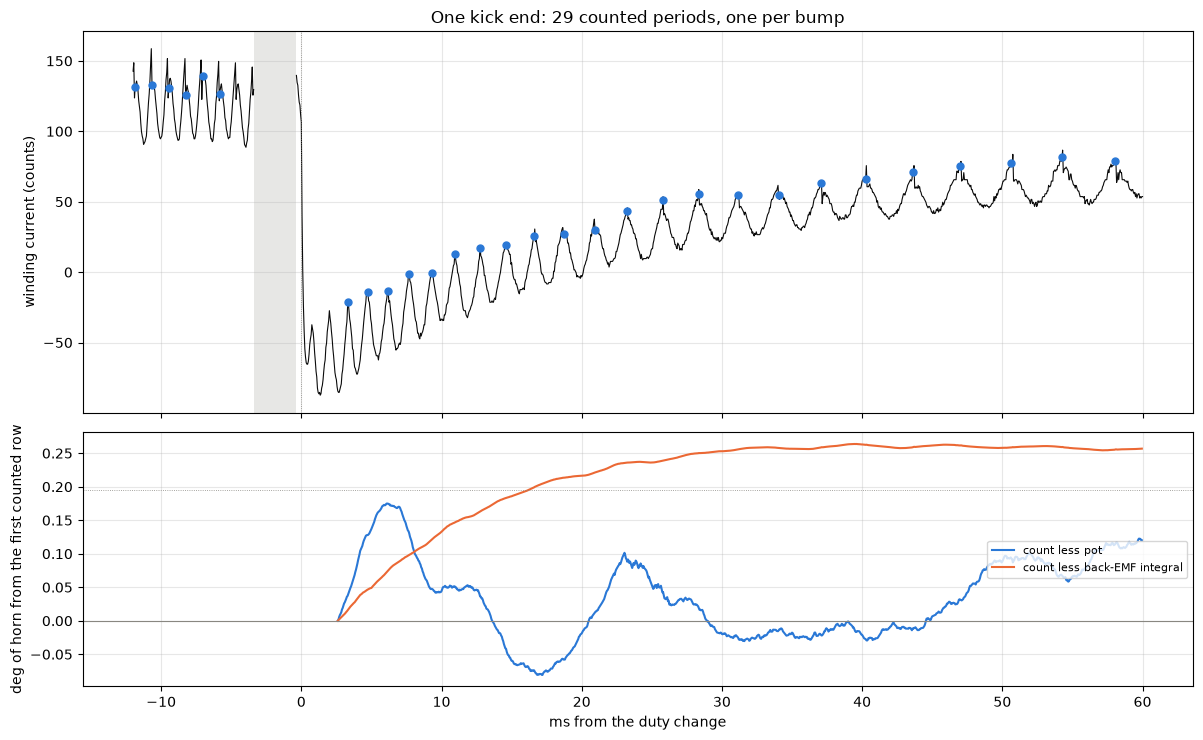

In [196]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True,
                       height_ratios=[1.5, 1])
a = ax[0]
mp, mg = t_p >= -12, t_g <= 60          # the kick's tail, the hold's start
a.plot(t_p[mp], x_p[mp], color=INK, lw=0.8)
a.plot(t_g[mg], x_g[mg], color=INK, lw=0.8)
n_marks = 0
for c, t, x in ((c_kick, t_p, x_p), (c_hold, t_g, x_g)):
    cr = c.crossings()                  # one row per counted period
    tc = np.interp(cr, np.arange(len(t)), t)
    keep_ = (tc >= -12) & (tc <= 60)
    a.plot(tc[keep_], np.interp(cr[keep_], np.arange(len(x)), x), "o",
           color=BLUE, ms=5)
    n_marks += int(keep_.sum())
a.axvspan(t_p[-1], t_g[0], color=MUTED, alpha=0.2, lw=0)   # the hole
a.axvline(0, **figures.EDGE_STYLE)      # the duty change
figures.label(a, y="winding current (counts)",
              title=f"One kick end: {n_marks} counted periods, one per bump")
b = ax[1]
b.plot(t_g[rows], d_cnt - (th1[rows] - th1[r0]), color=BLUE,
       label="count less pot")
b.plot(t_g[rows], d_cnt - (cum1[rows] - cum1[r0]), color=ORANGE,
       label="count less back-EMF integral")
b.axhline(0, color=MUTED, lw=0.8)
b.axhline(CNT_CYCLE, **figures.EDGE_STYLE)  # one commutation period
figures.label(b, x="ms from the duty change",
              y="deg of horn from the first counted row")
b.legend(fontsize=8, loc="center right")
figures.finish(fig)

What you are looking at: the three differences as means over events against the window's end, for the kick's start, the kick's end and the steady hold, with bars of +/- 2 se. Every point is over the same rows for all three readings.

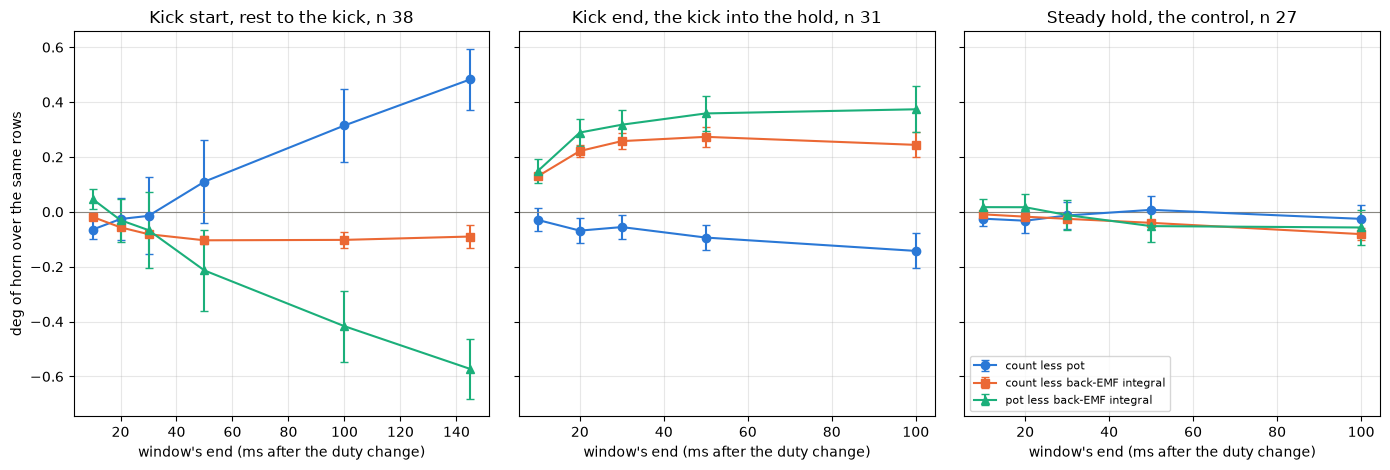

In [197]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)
for a, (kind, title) in zip(ax, (
        ("kick_start", "Kick start, rest to the kick"),
        ("kick_end", "Kick end, the kick into the hold"),
        ("control_slow", "Steady hold, the control"))):
    m = CNT_SM[(CNT_SM["set"] == "kept") & (CNT_SM["kind"] == kind)
               & (CNT_SM["dir"] == "both")]
    for q_, name, col, mk in (
            ("count_pot", "count less pot", BLUE, "o"),
            ("count_bemf", "count less back-EMF integral", ORANGE, "s"),
            ("pot_bemf", "pot less back-EMF integral", GREEN, "^")):
        r = m[m["quantity"] == q_].sort_values("ms")
        a.errorbar(r["ms"], r["mean"], yerr=2 * r["se"], color=col,
                   marker=mk, ms=6, capsize=3, label=name)
    a.axhline(0, color=MUTED, lw=0.8)
    n = int(m[m["quantity"] == "count_pot"]["n"].max())
    figures.label(a, x="window's end (ms after the duty change)",
                  title=f"{title}, n {n}")
ax[0].set_ylabel("deg of horn over the same rows")
ax[2].legend(fontsize=8, loc="lower left")
figures.finish(fig)

**The count is good to the pot on the steady holds.** Over 100 ms of hold, 2.87 deg of horn counted, the count less the pot is -0.026 deg [-0.078, +0.026] over 27 holds, a ratio of 0.991 [0.971, 1.011]. The back-EMF integral runs ahead of the count there by 0.081 deg per 100 ms [0.059, 0.104] over 25 holds. Of the 114 events 18 are dropped on the count's own numbers, none of the kick starts, 7 kick ends and 11 holds, each listed above with its reason. Six holds are stalled or creeping, and 11 events have a second seed that differs by one to three whole cycles, 7 of them with the pot inside a carry's band, against 21 of the 89 kept events that have two seeds.

**On the kick's last 50 ms the count agrees with the back-EMF integral and not with the pot.** Over 8.18 deg counted, the count reads 1.002 of the back-EMF integral (+0.014 deg, [-0.001, +0.028]) and 1.020 of the pot (+0.159 deg, [+0.075, +0.243]), 38 kicks. The pot reads 2.0 % short of the count. By direction it is +0.261 deg driving - and +0.057 driving +, the second inside its own bracket.

**At the kick's end the count follows the pot.** From 2.5 ms after the change, the first row the count reads, to 50 ms, the count reads +0.273 deg [+0.238, +0.309] more than the back-EMF integral over 26 kick ends, and +0.130 of it by 10 ms, where the current is still negative (-35.274 counts at 10 ms, crossing zero by 20 ms). From 30 to 100 ms nothing more arrives, -0.014 deg [-0.037, +0.010]. Against the pot the count reads -0.094 deg [-0.138, -0.050] over 31 kick ends, and -0.093 [-0.177, -0.009] less the same segment's hold. A shift of the fitted phase with the waveform's shape across the current's sign change is bounded at a quarter cycle, about 0.05 deg, which sits inside that bracket, so a pot lead of about 0.1 deg is not ruled out.

**Through the kick's start the count follows the back-EMF integral.** From 6.8 ms, the first counted row, to 145 ms, 20.52 deg counted, the count reads +0.483 deg [+0.372, +0.594] more than the pot and -0.090 deg [-0.131, -0.049] less than the back-EMF integral, 38 kicks. Of the -0.573 deg between the pot and the back-EMF integral on those rows, most lies between the count and the pot. The count less the back-EMF opens in the first 50 ms (-0.104) and then stays flat, -0.160 driving + and -0.021 driving -.

The rows the count does not see, from the back-EMF integral's anchor to the first counted row, hold -0.096 deg [-0.125, -0.066] of pot less back-EMF at the kick's start and +0.057 [+0.040, +0.075] at its end. Added to the counted windows they tie these numbers to the pot less back-EMF integral read at the head of this section.

**The count did not slip.** Two seeds that differ from each other by whole cycles over a window give the same count to 0.117 cycle at worst, the library's order count on the counted angle agrees to 0.214 cycle, and on the 19 drive + kicks every whole number of the phase has exactly one sharp fall of the current, none missing and none double, the count by the falls differing by 0.10 cycle at most. The falls' place in the cycle drifts -0.026 cycle [-0.029, -0.023] from a kick's first ten to its last ten. Starting the count at 40 rows instead of 20 gives -0.087 and +0.252 deg at the kick's end and +0.485 and -0.088 at the kick's start. Keeping the second-seed drops gives -0.091 and +0.282 at the kick's end, and leaving out every window with a carry code in it -0.130 and +0.257. The other gear ratio, by the commutation count, would make every count 0.50 % longer. Confidence moderate for the kick's two ends, one sitting.

**So the one line over every transient describes two different things.** At the kick's end the motor's shaft by the count follows the pot, and the back-EMF speed reads low while the winding current is negative. Through the kick's start the shaft follows the back-EMF integral, and the pot's angle falls short of the count by about 2 % of the travel.

### The candidate causes

No cause is picked. The count rules some readings in and some out, and two questions stay open, why the back-EMF reads low under negative current, and what sits between the motor's shaft and the pot's reading over a kick.

| cause | confidence | for | against | what separates |
|---|---|---|---|---|
| The back-EMF speed carries a current-dependent error at the kick's end, the resistance the estimate uses being lower than what the spinning motor shows on a current change | moderate, the kick's end | the count follows the pot there, +0.130 deg of it arrives inside negative current, and nothing arrives once the current is positive | at the kick's start the count follows the back-EMF integral to 0.09 deg, so it is not the main part there | a kick straight into a coast, the current going to zero and never negative |
| The brush drop takes the current's sign, the table having been fitted with the current along the drive | low to moderate, the kick's end | the error lives while the current is negative and stops when it crosses zero | the 20 % hold, whose current barely reverses, still reads +0.25 deg on 2 events | kick ends into holds high enough that the current never reverses, ten events or more |
| Something between the motor's shaft and the pot's reading over a kick, the train, the pot's table at those places, or the pot's timing | moderate, the kick's start | the count follows the back-EMF integral and the pot falls short of it by 2.0 % over the kick's last 50 ms | the steady holds agree to 0.991 of the pot, so it shows only at the kick's speed | a time mark the camera and the rows both see, and kicks of both directions over the same angles |
| The pot running ahead of the shaft at the kick's end, through the lash or its timing | low | the count reads 0.094 deg under the pot there | a quarter-cycle shift of the fitted phase at the sign change sits inside that, and the count rules it out as the main part of the 0.42 deg | the same time mark |
| An elastic wind-up of the train in proportion to the torque | low | the sign at the kick's end | the count puts the kick end's gap on the back-EMF, and at the kick's start the deficit grows while the current falls | a locked or loaded horn with the same kick |
| The frame alignment off by 2 to 4 ms through the kick | moderate, for the tag pairs only | the pot behind the tag from rest on the lead of record, which the mechanism forbids | it does not touch the count, the pot or the back-EMF integral | the same time mark |

**What stage 5 reads from this section.** For about 30 ms after a hard deceleration the back-EMF speed reads 12 to 23 rev/s low and the pot's slope is the one that follows the shaft. Over a kick the pot's angle runs about 2 % short of the shaft's. Both are measured on one sitting, and their causes are open.

In [198]:
def cnt_q(set_name, kind, ms, quantity, dir_="both"):
    """A summary row as a quantity, +/- 2 se as the bounds."""
    r = CNT_SM[(CNT_SM["set"] == set_name) & (CNT_SM["kind"] == kind)
               & (CNT_SM["ms"] == ms) & (CNT_SM["quantity"] == quantity)
               & (CNT_SM["dir"] == dir_)].iloc[0]
    unit = "ratio" if quantity.startswith("ratio") else "deg of horn"
    return q(r["mean"], r["lo"], r["hi"], f"{unit}, +/- 2 se, n "
             f"{int(r['n'])}")


R_S9["count_deg_per_period"] = q(CNT_CYCLE, unit="deg of horn, the tooth "
                                 "ratio")
for name, kind, ms in (("count_steady_hold_100ms", "control_slow", 100),
                       ("count_kick_last_50ms", "kick_last", 50),
                       ("count_kick_end_50ms", "kick_end", 50),
                       ("count_kick_start_145ms", "kick_start", 145)):
    R_S9[name] = {qq: cnt_q("kept", kind, ms, qq)
                  for qq in CNT_Q + ("ratio_count_pot", "ratio_count_bemf")}
R_S9["count_events"] = {
    kind: {"kept": int(g["keep"].sum()), "of": len(g),
           "dropped": {r.eid: r.why for r in g[~g["keep"]].itertuples()}}
    for kind, g in CNT_EV.groupby("kind")}
STAGE5_S9["shaft_by_the_count"] = (
    "the pot's slope follows the shaft after a kick's end; over a kick the "
    "pot runs about 2 % short of it; causes open")
print(len(R_S9), "keys in section 9")

16 keys in section 9


## 10. What stage 5 reads from here

### The numbers sections 2 to 5 hand on

The pot's slope, the carries, the back-EMF on the same rows and the crossover, as result-file values. The tables behind them, the pot's slope candidates by band and delay and the two sources' own noise by band and window, go to csv files beside the json.

In [199]:
q, pm = results.quantity, results.pm
rest_b = SLOPE_REST[SLOPE_REST["where"] == "baseline"].set_index(["kind", "d"])
pen = {}                    # a two-point off a multiple of 16 rows
for d_off, d_on in ((10, 8), (50, 32), (100, 128), (500, 512)):
    v_off = rest_b.loc[("two_point", d_off), "rms_deg_s"]
    v_on = rest_b.loc[("two_point", d_on), "rms_deg_s"]
    pen[2 * d_off] = v_off / (v_on * d_on / d_off)  # over the 1 / n line
print("two-point off a multiple of 16 rows over the 1 / n line through the "
      "nearest multiple:", {n: round(v, 2) for n, v in pen.items()})
kick_end = SLOPE_DELAY[(SLOPE_DELAY.what == "kick end") & SLOPE_DELAY.kind
                       .isin(["two_point", "box16", "box_n", "ls_line"])]
up128 = kick_end[kick_end.nominal <= 128]
at256 = kick_end[(kick_end.nominal > 128) & (kick_end.nominal <= 256)]
R_S2 = {
    "pot_slope_rest_noise_deg_s": "the .slopes.csv table, block rest",
    "pot_slope_rest_noise_5ms_deg_s": {
        k: q(rest_b.loc[(k, 100), "rms_deg_s"],
             rest_b.loc[(k, 100), "lo_deg_s"],
             rest_b.loc[(k, 100), "hi_deg_s"],
             "deg/s rms at 100 rows of delay, bounds the windows' sd")
        for k in velocity.KINDS if (k, 100) in rest_b.index},
    "pot_slope_two_point_multiple_of_rows": q(
        velocity.PATTERN_ROWS, unit="rows, the board's pattern"),
    "pot_slope_off_multiple_penalty": q(
        np.mean(list(pen.values())), min(pen.values()), max(pen.values()),
        "x the 1 / n line, bounds over the four lengths"),
    "pot_slope_motion_sd_deg_s": "the .slopes.csv table, block motion",
    "pot_slope_delay_resid_rows": {
        "up_to_128": q(up128.resid.abs().max(), up128.resid.min(),
                       up128.resid.max(), "rows, kick ends"),
        "128_to_256": q(at256.resid.abs().max(), at256.resid.min(),
                        at256.resid.max(), "rows, kick ends"),
        "kick_ends": q(int(kick_end.runs.max()), unit="transients")},
    "pot_slope_pole_short_from_rows": q(128, unit="rows of time constant")}
print(len(R_S2), "section 2 keys")

two-point off a multiple of 16 rows over the 1 / n line through the nearest multiple: {20: np.float64(2.39), 100: np.float64(2.39), 200: np.float64(1.22), 1000: np.float64(1.21)}
7 section 2 keys


In [200]:
slow = CARRY_EVENTS[CARRY_EVENTS.cls == "slow 10-50"].groupby("code")
two = CARRY[(CARRY.cls == "slow 10-50") & (CARRY.kind == "two_point")]
g = CARRY_SHARE.groupby("cls").sum(numeric_only=True).loc["slow 10-50"]
R_S3 = {
    "carry_dwell_max_ms_crawl": q(
        CARRY_EVENTS[CARRY_EVENTS.cls == "slow 10-50"].dwell_rows.max()
        / FS * 1e3, unit="ms, the longest crossing at a crawl"),
    "carry_dwell_ms_crawl": {
        str(c): q(np.median(d.dwell_rows) / FS * 1e3, d.dwell_rows.min()
                  / FS * 1e3, d.dwell_rows.max() / FS * 1e3,
                  "ms, median, bounds the crossings")
        for c, d in slow},
    "carry_near_rms_deg_s": {
        v: {("near" if near else "far"): {
            f"{n / FS * 1e3:g} ms": q(r.rms, unit="deg/s rms")
            for n, r in dd.set_index("n").iterrows()}
            for near, dd in dv.groupby("near")}
        for v, dv in two.groupby("variant")},
    "carry_mask": "skip",
    "carry_mask_half_counts": q(WIDE_HALF, unit="counts, the longest "
                                "missing run"),
    "carry_mask_until_window_ms": q(50, unit="ms, about twice the longest "
                                    "dwell at a crawl"),
    "carry_rows_touched_share_crawl": {
        f"{n / FS * 1e3:g} ms": q(g[f"near_{n}"] / g.moving, unit="of "
                                  "moving rows") for n in (128, 512, 1024,
                                                           2000, 4000)},
    "carry_band_rows_share_crawl": q(g.in_band12 / g.moving,
                                     unit="of moving rows, +/-12 counts")}
print(len(R_S3), "section 3 keys")

8 section 3 keys


In [201]:
def seg_q(d, col, unit="rev/s, +/- se over segments"):
    m, se, n, ns = seg_mean(d, col)
    return pm(m, se, unit)


def dir_q(col):
    return {("+" if dr > 0 else "-"): pm(v[0], v[1],
                                         "rev/s, mean of segment means, "
                                         "+/- se")
            for dr, v in EMF_DIR[col].items()}


under = Q2_TILES[(Q2_TILES.label == "crawl") & (Q2_TILES.duty < FLOOR)]
r1 = EMF_NOISE[(EMF_NOISE["filter"] == "boxcar") & (EMF_NOISE.n == 1)
               & (EMF_NOISE.form == "w_tab")].set_index(["band", "side"])
R_S4 = {
    "emf_valid_share_camera": q(COVER.valid / COVER.driven, unit="of driven "
                                "rows"),
    "emf_crawl_rows_under_floor_share": q(UNDER_FLOOR_SHARE, unit="of "
                                          "crawl hold rows"),
    "emf_bias_crawl_rev_s": {"table": seg_q(SLOW, "e_tab"),
                             "product": seg_q(SLOW, "e_prod")},
    "emf_bias_crawl_tach_rev_s": {"table": seg_q(SLOW, "e_tab_tach"),
                                  "product": seg_q(SLOW, "e_prod_tach")},
    "emf_bias_by_direction_rev_s": {"table": dir_q("e_tab"),
                                    "product": dir_q("e_prod"),
                                    "table_tach": dir_q("e_tab_tach")},
    "emf_bias_under_floor_rev_s": {"table": seg_q(under, "e_tab"),
                                   "product": seg_q(under, "e_prod")},
    "emf_bias_pass_rev_s": {"table": seg_q(PASS, "e_tab"),
                            "product": seg_q(PASS, "e_prod"),
                            "confidence": "not a finding"},
    "emf_bias_crawl_design_zero_shift_rev_s": q(
        DZ.dw.mean(), DZ.dw.min(), DZ.dw.max(), "rev/s, bounds the tiles")}

In [202]:
R_S4.update({
    "emf_noise_row_rev_s": {
        f"{b} {sd}": q(r1.loc[(b, sd), "sd"], unit="rev/s per row, table")
        for b, sd in r1.index},
    "emf_noise_boxcar_rev_s": {
        f"{r.band} {r.side} {r.form} {r.filter} {r.n}": q(
            r.sd, r.lo, r.hi, "rev/s about the tile's line, bounds tiles")
        for r in EMF_NOISE.itertuples()},
    "tach_minus_tag_rev_s": {"slow": seg_q(SLOW, "e_tach"),
                             "pass": seg_q(PASS, "e_tach")}})
print(len(R_S4), "section 4 keys")

11 section 4 keys


In [203]:
def xq(band, pot, emf, stat):
    r = XOVER[(XOVER["align"] == "group") & (XOVER.band == band)
              & (XOVER.pot == pot) & (XOVER.emf == emf)
              & (XOVER.stat == stat)].iloc[0]
    return q(r.window_ms, r.lo_ms, r.hi_ms, f"ms of window, 5-95 % of 200 "
             f"resamplings, never {r.never_share:.0%}")



ang = {b: (XO[(XO["align"] == "group") & (XO.band == b)].set_index("n"))
       for b in XO_BANDS}
pot_ang = {b: [a.hat_pot.loc[n] * K * n / FS for n in (512, 1024, 2000,
                                                       4000, 8000)
               if n in a.index and np.isfinite(a.hat_pot.loc[n])]
           for b, a in ang.items()}
tag_ang = {b: [a.hat_tag.loc[n] * K * n / FS for n in (512, 1024, 2000,
                                                       4000)
               if n in a.index and np.isfinite(a.hat_tag.loc[n])]
           for b, a in ang.items()}
R_S5 = {
    "crossover_window_ms": {
        "crawl_rms": xq("crawl 15-35", "pot_two", "emf_tab", "rms"),
        "crawl_sd": xq("crawl 15-35", "pot_two", "emf_tab", "sd"),
        "crawl_own_noise": xq("crawl 15-35", "hat_pot", "hat_emf", ""),
        "crawl_own_noise_with_bias": xq("crawl 15-35", "hat_pot_rms",
                                        "hat_emf_rms", ""),
        "crawl_rms_line": xq("crawl 15-35", "pot_ls", "emf_tab", "rms"),
        "crawl_rms_product": xq("crawl 15-35", "pot_two", "emf_prod", "rms"),
        "steps_rms": xq("steps", "pot_two", "emf_tab", "rms"),
        "pass_rms": xq("pass 100", "pot_two", "emf_tab", "rms")},
    "own_noise_rev_s": "the .crossover.csv table (hat_pot, hat_emf, hat_tag)",
    "pot_slope_angle_error_per_window_deg": {
        b: q(np.median(v), min(v), max(v), "deg, median, bounds the "
             "windows 25.6 to 400 ms") for b, v in pot_ang.items()},
    "tag_two_point_error_deg": {
        b: q(np.median(v), min(v), max(v), "deg, median, bounds the "
             "windows 25.6 to 200 ms") for b, v in tag_ang.items()}}
print(len(R_S5), "section 5 keys;", {b: [round(x, 3) for x in v]
                                     for b, v in pot_ang.items()})

4 section 5 keys; {'crawl 15-35': [np.float64(0.12), np.float64(0.129), np.float64(0.114), np.float64(0.103), np.float64(0.127)], 'steps': [np.float64(0.13), np.float64(0.151), np.float64(0.132), np.float64(0.175)], 'pass 100': [np.float64(0.143), np.float64(0.16), np.float64(0.173), np.float64(0.229), np.float64(0.284)]}


In [204]:
SLOPES_CSV = pd.concat([
    SLOPE_REST.assign(block="rest").rename(columns={"where": "band"}),
    SLOPE_MOTION.assign(block="motion")], ignore_index=True)
CROSSOVER_CSV = XO[["align", "band", "n", "delay_ms", "tiles", "segs",
                    "w_tag", "pot_two_rms", "pot_ls_rms", "pot_skip_rms",
                    "pot_bn_rms", "emf_tab_rms", "emf_tab_bias", "emf_tab_se",
                    "emf_prod_rms", "emf_prod_bias", "emf_pole_rms",
                    "tach_sd", "hat_pot", "hat_emf", "hat_tag", "lead_sd"]]
print(f".slopes.csv {SLOPES_CSV.shape}, .crossover.csv {CROSSOVER_CSV.shape}")

.slopes.csv (672, 26), .crossover.csv (224, 22)


### One table

What a velocity loop reads from this servo on this board, by regime. The noise is each source's own noise at the stated delay (section 5's hat at a crawl, section 7's own sd for the blends), the bias its steady bias against the tag, and the times and seams those of sections 6 and 7. Every estimator runs once per control tick at 20000 rows/s in float.

In [205]:
xo = XO[(XO["align"] == "group")].set_index(["band", "n"])
ROWS5 = [
    ("crawl over the floor", "back-EMF, table form, boxcar 200 rows",
     "5 ms", xo.loc[("crawl 15-35", 200), "hat_emf"],
     R_S4["emf_bias_crawl_rev_s"]["table"]["value"]),
    ("crawl over the floor", "back-EMF, product form, boxcar 200 rows",
     "5 ms", np.nan, R_S4["emf_bias_crawl_rev_s"]["product"]["value"]),
    ("crawl over the floor", "pot's two-point, 200 rows", "5 ms",
     xo.loc[("crawl 15-35", 200), "hat_pot"], 0.0),
    ("crawl under the floor", "pot's two-point, 2000 rows", "50 ms",
     xo.loc[("crawl under the floor", 2000), "pot_two_rms"], 0.0),
    ("crawl under the floor", "back-EMF (not valid)", "-", np.nan,
     R_S4["emf_bias_under_floor_rev_s"]["table"]["value"]),
    ("pass, 86 rev/s", "back-EMF, table form, per row", "0",
     R_S4["emf_noise_row_rev_s"]["pass 100 valid"]["value"],
     R_S4["emf_bias_pass_rev_s"]["table"]["value"])]
for c, v in STAGE5_S678["blends"].items():  # section 7's blends
    ROWS5.append(("crawl, one velocity", c, f"{v['delay_kick_end_rows']:+.0f}"
                  " rows at a kick end", v["own_sd_crawl_rev_s"],
                  v["bias_crawl_rev_s"]))
STAGE5 = pd.DataFrame(ROWS5, columns=["regime", "source", "delay",
                                      "noise_rev_s", "bias_rev_s"])
print(STAGE5.round(2).to_string(index=False))
print("rest verdict (ms):", STAGE5_S678["rest_verdict"])
print("seams (rev/s, median):", STAGE5_S678["seams_rev_s"])
print("stopped rotor's line (rev/s, rev/s per A):",
      STAGE5_S678["stopped_rotor_line"])
print("after a hard deceleration, back-EMF less pot (rev/s):",
      [round(v, 1) for v in STAGE5_S9["emf_minus_pot_rev_s"]], "-",
      STAGE5_S9["shaft_by_the_count"])

               regime                                  source                   delay  noise_rev_s  bias_rev_s
 crawl over the floor   back-EMF, table form, boxcar 200 rows                    5 ms         1.72        0.54
 crawl over the floor back-EMF, product form, boxcar 200 rows                    5 ms          NaN        1.38
 crawl over the floor               pot's two-point, 200 rows                    5 ms         7.43        0.00
crawl under the floor              pot's two-point, 2000 rows                   50 ms         1.47        0.00
crawl under the floor                    back-EMF (not valid)                       -          NaN       -2.25
       pass, 86 rev/s           back-EMF, table form, per row                       0         7.53       -0.32
  crawl, one velocity                                    pot5 +105 rows at a kick end         6.99        0.00
  crawl, one velocity                                   pot25 +499 rows at a kick end         2.59       -0.03
 

What a velocity loop reads from this servo on this board, all of it one sitting.

- **Over the taps' floor at a crawl the back-EMF is the source with the least noise.** At 5 ms of delay its own noise is 1.72 rev/s against 7.43 for the pot's two-point. It reads +0.54 rev/s high in the table form and +1.38 in the product form, with a direction split the forms do not carry (section 4). The pot's slope catches up only at 50 to 70 ms of delay (section 5).
- **Under the floor the pot's slope is the only source.** A crawl's 2000-row two-point reads 1.47 rev/s rms against the tag, where the back-EMF is not valid and reads -2.25 rev/s low. Its shape is two boxcars of 16 rows or a two-point over a multiple of 16 rows, with the carry band skipped under about 50 ms of window (sections 2 and 3).
- **One velocity.** The switch reads +0.40 rev/s of the back-EMF's bias at a crawl with 3.43 rev/s of own noise, the pair +0.04 with 3.52. Both lead the pot's centered slope on a kick's end, by 84 and 69 rows, the back-EMF reading low there (section 9), where the pot's 5 ms slope trails by 105. The seams are 13.5 rev/s for the switch and 14.4 for the pair with rest on pot rows at a start, 6.8 and 5.4 at a coast's start. The choice between them stays open (section 7).
- **The rest verdict.** Held to 50 ms, the band of 2 counts declares rest 56.4 ms after a coast-down's stop and drops it 7.7 ms after a start, the slope form 56.1 and 6.5, and with the back-EMF's veto it drops in 5.8 ms. The stopped rotor reads -4.54 + 42.7 rev/s per A through the back-EMF, the veto's reference (sections 6 and 8).
- **After a hard deceleration** the back-EMF reads 12.3 to 22.9 rev/s under the pot for about 20 ms, the pot's slope being the one that follows the shaft by the commutation count, and over a kick the pot runs about 2 % short of the shaft (section 9).

Every estimator here runs once per control tick at 20000 rows/s in float. The pot's slopes keep their last n + 16 rows, or two running sums and the rows between. The back-EMF keeps the tracked zero's state, the previous row's speed for the table's newton steps and the valid rule's counters. The switch keeps nothing of its own, the pair one one-pole and the back-EMF through the pot's kernel, and the rest verdict a count of rows. The constants are the lookup, the carries' codes and missing runs, the servo's own rest noise and the result files of stages 1 to 3.

### The gaps, each with the capture that would close it

- **The stopped rotor's law below 70 mA.** The crawl's +0.54 rev/s at 29 to 59 mA and the stopped rotor's reading at 94 mA and up are not separated as one law (section 8). Stopped holds at 20 to 70 mA, the load ladder's lowest rungs extended down, or a crawl against a brake at 100 to 200 mA would place the crawl on the curve or off it.
- **The direction split's cause.** The table form's split of about +0.8 rev/s under 45 rev/s fades with speed and does not move with the rail, and speed and current are collinear on this sitting. The same speed at two currents, a crawl against a brake in both directions, separates the forms' direction constants from a drag through the R i term.
- **The crossover's move against stage 3.** Three offline re-scorings of these rows, with stage 3's truth, then its zero, then its band, would say which change moved it.
- **The tag as the truth under 100 ms.** Its own noise is the floor of every short-window grade. A lookup fitted on other chains than it is scored on would test the hat's independence, and a second tag bonded to the output shaft or an encoder on it would grade both sources without the tag's noise.
- **The rest verdict between 2 and 10 deg/s.** The sitting holds only coast-down tails there. A driven sweep at 2 to 10 deg/s would settle the slowest speed the verdict tells from rest.
- **The commutation pattern's cause.** A back-EMF constant that varies with the rotor's angle and a resistance that varies with it make the same current ripple under drive. A coast with the taps streamed separates them, as an identification capture, not a coast in an estimator.
- **The angle-locked motion's shaft.** Passes of 40 deg and more at a steady crawl would resolve the gear train's lines at 4 to 8 deg, and a crawl at two duties over the same angles would tell a load pattern from a ratio error.
- **The kick's end.** For about 30 ms after a hard deceleration the back-EMF speed reads 12 to 23 rev/s low and the pot's slope is the one that follows the shaft by the commutation count, and over a kick the pot's angle runs about 2 % short of the shaft's (section 9). Why the back-EMF reads low under negative current would be separated by a kick straight into a coast and by kick ends into holds that keep the current from reversing. What sits between the shaft and the pot's reading would be separated by a time mark the camera and the rows both see and by kicks of both directions over the same angles.
- **A second sitting.** Every camera number here is one sitting of one servo at 5 V. A second sitting, and a second servo, would turn the candidates into numbers.
- **The blend.** The switch and the complementary pair are carried side by side and the choice is open. A loop design weighs the switch's bias against the pair's one-pole and its seams, and section 7 gives both.

### The result file

Every number in the result file is one servo on one board in one sitting, mg90-d on dev-v006-2A-D, read from stage 3's camera sitting and stage 3's windows of that pair. Nothing in it repeats across servos, and the camera numbers do not repeat across sittings. The keys of sections 2 to 9 join the file, and four tables go to csv files beside it, the pot's slope candidates by band and delay, the two sources' own noise by band and window, the rest verdict's candidates and the blend candidates. No key names a blend of record.

In [206]:
QUANTITIES = {}
for part in (R_S2, R_S3, R_S4, R_S5, R_S6, R_S7, R_S8, R_S9):
    QUANTITIES.update(part)
QUANTITIES["stage5_by_regime"] = STAGE5.to_dict("records")
NOTES = (
    "One servo on one board in one sitting: mg90-d on dev-v006-2A-D, stage "
    "3's camera sitting servo-camera-9 (21 chains, 5 V) through "
    "oscnb.potframes, and stage 3's windows and duty steps of the pair. "
    "Estimators causal, float, one row per control tick (oscnb.velocity, "
    "oscnb.speed); truths offline (the tag through the same kernel, the "
    "ripple tach, each window's own). Zero: stage 1's tracker in float, "
    "the state after the row before. Back-EMF: k_d = 0, both brush forms "
    "side by side, never trimmed against the pot or the tag. Lookup: the "
    "position result's. The blend is not chosen. Brackets: +/- se unless "
    "the unit says otherwise. Tables in .slopes.csv, .crossover.csv, "
    ".rest.csv and .blends.csv.")
path = results.write(STAGE, EXPERIMENT, PAIR_DIR.resolve(), pair=PAIR,
                     notes=NOTES, **QUANTITIES)
base = results.path(STAGE, EXPERIMENT, pair=PAIR)
for suffix, table in ((".slopes.csv", SLOPES_CSV),
                      (".crossover.csv", CROSSOVER_CSV),
                      (".rest.csv", REST_CSV), (".blends.csv", BLENDS_CSV)):
    table.to_csv(base.with_suffix(suffix), index=False, float_format="%.6g")
written = results.read(STAGE, EXPERIMENT, pair=PAIR)
print("wrote", path, "with", len(QUANTITIES), "keys, capture",
      written["capture"])

wrote stages/4-estimators/velocity/results/mg90-d__dev-v006-2A-D.json with 87 keys, capture telemetry/mg90-d__dev-v006-2A-D
